# 200_03 — Convergencia de las cadenas MCMC · Escenario TAR · **barrido en $M$**

Paso **3a** del ciclo. Este notebook **sólo diagnostica las cadenas**: no
predice, no evalúa y no toca el bloque de prueba. Si algo aquí falla, los
números de `200_04` no significan nada, y por eso son notebooks separados.

Los cálculos viven en `fit/convergencia_barrido.py` y las figuras en
`graphics/viz_convergencia.py`; este notebook los orquesta.

| Estadístico | Referencia | Lectura |
|---|---|---|
| ESS | Geyer (1992) | $\gtrsim 400$ ideal, $>100$ aceptable |
| Geweke $z$ | test $z$ entre segmentos | $\lvert z\rvert < 2$ ⇒ no se rechaza |
| $\hat R$ | Gelman-Rubin | $< 1.1$ ⇒ convergencia |

## 1. Imports, `[CONFIG]` y artefactos

In [3]:
import sys

import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, diagnosticar_punto, imprimir_convergencia,
    ocupacion_mezcla, diagnostico_gating, pip_punto, contraste_generador,
    verificar_muestreador_predictor, diagnostico_paso_gamma,
    tabla_barrido, ocupacion_barrido, pip_barrido, veredicto_barrido,
    comparar_variantes,
)
from model_psbp_fd.graphics import (
    plot_global_components, plot_active_clusters,
    plot_convergence_bj, plot_convergence_pj,
    plot_ocupacion_mezcla, plot_gating, plot_diagnostico_vs_M,
    plot_ocupacion_vs_M, plot_pip_vs_M, plot_variantes,
)
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [4]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Mismos valores que 200_01 §1.1.
VARIANTE     = "chungEscG"
BASENAME     = f"escenario_200_{VARIANTE}"
ESCENARIO_ID = 1      # escenario TAR (único)
REPLICA_ID   = 1      # réplica Monte Carlo
M_FPCA_LIST  = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10)

# Propias de la convergencia.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
BURN_EVAL           = None    # iteraciones descartadas; None = el burn del .mat
UMBRAL_PIP          = 0.5     # corte de selección en el contraste con el generador
SD_PIP_MAX          = 0.15    # dispersión entre cadenas que se avisa
CORR_MIN_CONTRATO   = 0.999   # corr(inEout, predict) mínima, §7
COS_MIN             = 0.95    # |cos(psi_k, phi_k)| bajo el cual el contraste es aproximado

# §9: etiqueta -> BASENAME a comparar (cada uno con su _03 ya corrido).
VARIANTES_COMPARAR = {
    "200 Chung esc. gating libre": "escenario_200_chungEscG",
}

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASENAME, ESCENARIO_ID, REPLICA_ID)
# Salidas que CRUZAN los M: directorio hermano de los de cada punto.
PATH_BARRIDO    = ruta_barrido_M(BASENAME, ESCENARIO_ID, REPLICA_ID, project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}   (archivos 80-83)")

EXPERIMENT_BASE : escenario_200_chungEscG_1_r01
barrido en M    : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_200_chungEscG_1_r01_barrido_M   (archivos 80-83)


In [5]:
# EST[M] es el estado completo de cada punto; todo lo que sigue lo consume por índice.
EST, saltados = cargar_artefactos(BASENAME, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST, PROJECT_ROOT)

  M  comp  cadenas  covariables  seed_base
  1     1        3            4  41232
  2     2        3            8  41232
  3     3        3           12  41232
  4     4        3           16  41232
  5     5        3           20  41232
  6     6        3           24  41232
  7     7        3           28  41232
  8     8        3           32  41232
  9     9        3           36  41232
 10    10        3           40  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 3)


## 2. Lectura de las trazas

In [6]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS, BURN_EVAL)   # los M efectivamente disponibles

OK M=1: 1 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=2: 2 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=3: 3 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=4: 4 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=5: 5 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=6: 6 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=7: 7 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=8: 8 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=9: 9 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=10: 10 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente


## 3. Tabla de diagnósticos

ESS, Geweke y $\hat R$ **sin generar figuras**. Una tabla por $M$, guardada en el
directorio de su punto (`40_diagnosticos_mcmc.csv`); la comparación entre $M$ va
en §8.

In [7]:
for M in M_OK:
    diag_df = diagnosticar_punto(EST[M])
    display(diag_df.style
        .format({"ess_min": "{:.1f}", "ess_mean": "{:.1f}",
                 "geweke_max": "{:+.2f}", "rhat": "{:.4f}"})
        .background_gradient(subset=["rhat"], cmap="RdYlGn_r", vmin=1.0, vmax=1.2)
        .background_gradient(subset=["ess_min"], cmap="RdYlGn", vmin=0, vmax=500)
        .set_caption(f"M={M} - diagnósticos MCMC por componente FPCA y variable"))

imprimir_convergencia(EST, M_OK)

[tabla_diagnosticos] inicio (8 pasos)
  1/8 (12.5%) t=0.1s eta=1.0s  fpc_1 beta_j[fpc_1_lag1] rhat=1.000 ess_min=1933
  2/8 (25.0%) t=0.2s eta=0.5s  fpc_1 beta_j[fpc_1_lag2] rhat=1.000 ess_min=1619
  3/8 (37.5%) t=0.2s eta=0.3s  fpc_1 beta_j[fpc_1_lag3] rhat=1.000 ess_min=1859
  4/8 (50.0%) t=0.2s eta=0.2s  fpc_1 beta_j[fpc_1_lag4] rhat=1.000 ess_min=1870
  5/8 (62.5%) t=0.2s eta=0.1s  fpc_1 p_j[fpc_1_lag1] rhat=1.004 ess_min=19
  6/8 (75.0%) t=0.2s eta=0.1s  fpc_1 p_j[fpc_1_lag2] rhat=1.000 ess_min=19
  7/8 (87.5%) t=0.2s eta=0.0s  fpc_1 p_j[fpc_1_lag3] rhat=1.007 ess_min=148
  8/8 (100.0%) t=0.2s eta=0.0s  fpc_1 p_j[fpc_1_lag4] rhat=1.016 ess_min=125
[tabla_diagnosticos] listo: 8 pasos en 0.3s  4 variables sin converger de 8


,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,3,2000,1932.7,1977.6,+1.16,0.9998,True
1,1,beta_j,fpc_1_lag2,3,2000,1619.5,1800.4,+2.05,0.9999,False
2,1,beta_j,fpc_1_lag3,3,2000,1859.5,1953.2,+1.27,0.9999,True
3,1,beta_j,fpc_1_lag4,3,2000,1870.3,1956.8,+0.65,0.9998,True
4,1,p_j,fpc_1_lag1,3,2000,19.5,49.4,+3.19,1.0041,False
5,1,p_j,fpc_1_lag2,3,2000,18.9,146.8,+6.04,1.0003,False
6,1,p_j,fpc_1_lag3,3,2000,147.7,201.1,+3.75,1.0071,False
7,1,p_j,fpc_1_lag4,3,2000,125.5,206.9,+0.74,1.0163,True


[tabla_diagnosticos] inicio (16 pasos)
  1/16 ( 6.2%) t=0.0s eta=0.5s  fpc_1 beta_j[fpc_1_lag1] rhat=1.000 ess_min=1933
  2/16 (12.5%) t=0.0s eta=0.3s  fpc_1 beta_j[fpc_1_lag2] rhat=1.000 ess_min=1619
  3/16 (18.8%) t=0.1s eta=0.3s  fpc_1 beta_j[fpc_1_lag3] rhat=1.000 ess_min=1859
  4/16 (25.0%) t=0.1s eta=0.2s  fpc_1 beta_j[fpc_1_lag4] rhat=1.000 ess_min=1870
  5/16 (31.2%) t=0.1s eta=0.2s  fpc_1 p_j[fpc_1_lag1] rhat=1.004 ess_min=19
  6/16 (37.5%) t=0.1s eta=0.1s  fpc_1 p_j[fpc_1_lag2] rhat=1.000 ess_min=19
  7/16 (43.8%) t=0.1s eta=0.1s  fpc_1 p_j[fpc_1_lag3] rhat=1.007 ess_min=148
  8/16 (50.0%) t=0.1s eta=0.1s  fpc_1 p_j[fpc_1_lag4] rhat=1.016 ess_min=125
  9/16 (56.2%) t=0.1s eta=0.1s  fpc_2 beta_j[fpc_2_lag1] rhat=1.000 ess_min=680
  10/16 (62.5%) t=0.2s eta=0.1s  fpc_2 beta_j[fpc_2_lag2] rhat=1.000 ess_min=1706
  11/16 (68.8%) t=0.2s eta=0.1s  fpc_2 beta_j[fpc_2_lag3] rhat=1.000 ess_min=1701
  12/16 (75.0%) t=0.2s eta=0.1s  fpc_2 beta_j[fpc_2_lag4] rhat=1.000 ess_min=980
  13/1

,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,3,2000,1932.7,1977.6,+1.16,0.9998,True
1,1,beta_j,fpc_1_lag2,3,2000,1619.5,1800.4,+2.05,0.9999,False
2,1,beta_j,fpc_1_lag3,3,2000,1859.5,1953.2,+1.27,0.9999,True
3,1,beta_j,fpc_1_lag4,3,2000,1870.3,1956.8,+0.65,0.9998,True
4,1,p_j,fpc_1_lag1,3,2000,19.5,49.4,+3.19,1.0041,False
5,1,p_j,fpc_1_lag2,3,2000,18.9,146.8,+6.04,1.0003,False
6,1,p_j,fpc_1_lag3,3,2000,147.7,201.1,+3.75,1.0071,False
7,1,p_j,fpc_1_lag4,3,2000,125.5,206.9,+0.74,1.0163,True
8,2,beta_j,fpc_2_lag1,3,2000,680.2,1411.9,+2.27,1.0001,False
9,2,beta_j,fpc_2_lag2,3,2000,1705.8,1901.9,+1.29,1.0000,True


[tabla_diagnosticos] inicio (24 pasos)
  1/24 ( 4.2%) t=0.1s eta=1.6s  fpc_1 beta_j[fpc_1_lag1] rhat=1.000 ess_min=1933
  2/24 ( 8.3%) t=0.1s eta=1.0s  fpc_1 beta_j[fpc_1_lag2] rhat=1.000 ess_min=1619
  3/24 (12.5%) t=0.1s eta=0.8s  fpc_1 beta_j[fpc_1_lag3] rhat=1.000 ess_min=1859
  4/24 (16.7%) t=0.1s eta=0.7s  fpc_1 beta_j[fpc_1_lag4] rhat=1.000 ess_min=1870
  5/24 (20.8%) t=0.1s eta=0.6s  fpc_1 p_j[fpc_1_lag1] rhat=1.004 ess_min=19
  6/24 (25.0%) t=0.2s eta=0.5s  fpc_1 p_j[fpc_1_lag2] rhat=1.000 ess_min=19
  7/24 (29.2%) t=0.2s eta=0.4s  fpc_1 p_j[fpc_1_lag3] rhat=1.007 ess_min=148
  8/24 (33.3%) t=0.2s eta=0.3s  fpc_1 p_j[fpc_1_lag4] rhat=1.016 ess_min=125
  9/24 (37.5%) t=0.2s eta=0.3s  fpc_2 beta_j[fpc_2_lag1] rhat=1.000 ess_min=680
  10/24 (41.7%) t=0.2s eta=0.3s  fpc_2 beta_j[fpc_2_lag2] rhat=1.000 ess_min=1706
  11/24 (45.8%) t=0.2s eta=0.3s  fpc_2 beta_j[fpc_2_lag3] rhat=1.000 ess_min=1701
  12/24 (50.0%) t=0.2s eta=0.2s  fpc_2 beta_j[fpc_2_lag4] rhat=1.000 ess_min=980
  13/2

,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,3,2000,1932.7,1977.6,+1.16,0.9998,True
1,1,beta_j,fpc_1_lag2,3,2000,1619.5,1800.4,+2.05,0.9999,False
2,1,beta_j,fpc_1_lag3,3,2000,1859.5,1953.2,+1.27,0.9999,True
3,1,beta_j,fpc_1_lag4,3,2000,1870.3,1956.8,+0.65,0.9998,True
4,1,p_j,fpc_1_lag1,3,2000,19.5,49.4,+3.19,1.0041,False
5,1,p_j,fpc_1_lag2,3,2000,18.9,146.8,+6.04,1.0003,False
6,1,p_j,fpc_1_lag3,3,2000,147.7,201.1,+3.75,1.0071,False
7,1,p_j,fpc_1_lag4,3,2000,125.5,206.9,+0.74,1.0163,True
8,2,beta_j,fpc_2_lag1,3,2000,680.2,1411.9,+2.27,1.0001,False
9,2,beta_j,fpc_2_lag2,3,2000,1705.8,1901.9,+1.29,1.0000,True


[tabla_diagnosticos] inicio (32 pasos)
  1/32 ( 3.1%) t=0.0s eta=0.9s  fpc_1 beta_j[fpc_1_lag1] rhat=1.000 ess_min=1933
  2/32 ( 6.2%) t=0.1s eta=0.8s  fpc_1 beta_j[fpc_1_lag2] rhat=1.000 ess_min=1619
  3/32 ( 9.4%) t=0.1s eta=0.7s  fpc_1 beta_j[fpc_1_lag3] rhat=1.000 ess_min=1859
  4/32 (12.5%) t=0.1s eta=0.7s  fpc_1 beta_j[fpc_1_lag4] rhat=1.000 ess_min=1870
  5/32 (15.6%) t=0.1s eta=0.6s  fpc_1 p_j[fpc_1_lag1] rhat=1.004 ess_min=19
  6/32 (18.8%) t=0.1s eta=0.6s  fpc_1 p_j[fpc_1_lag2] rhat=1.000 ess_min=19
  7/32 (21.9%) t=0.1s eta=0.5s  fpc_1 p_j[fpc_1_lag3] rhat=1.007 ess_min=148
  8/32 (25.0%) t=0.2s eta=0.5s  fpc_1 p_j[fpc_1_lag4] rhat=1.016 ess_min=125
  9/32 (28.1%) t=0.2s eta=0.5s  fpc_2 beta_j[fpc_2_lag1] rhat=1.000 ess_min=680
  10/32 (31.2%) t=0.2s eta=0.5s  fpc_2 beta_j[fpc_2_lag2] rhat=1.000 ess_min=1706
  11/32 (34.4%) t=0.2s eta=0.4s  fpc_2 beta_j[fpc_2_lag3] rhat=1.000 ess_min=1701
  12/32 (37.5%) t=0.2s eta=0.4s  fpc_2 beta_j[fpc_2_lag4] rhat=1.000 ess_min=980
  13/3

,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,3,2000,1932.7,1977.6,+1.16,0.9998,True
1,1,beta_j,fpc_1_lag2,3,2000,1619.5,1800.4,+2.05,0.9999,False
2,1,beta_j,fpc_1_lag3,3,2000,1859.5,1953.2,+1.27,0.9999,True
3,1,beta_j,fpc_1_lag4,3,2000,1870.3,1956.8,+0.65,0.9998,True
4,1,p_j,fpc_1_lag1,3,2000,19.5,49.4,+3.19,1.0041,False
5,1,p_j,fpc_1_lag2,3,2000,18.9,146.8,+6.04,1.0003,False
6,1,p_j,fpc_1_lag3,3,2000,147.7,201.1,+3.75,1.0071,False
7,1,p_j,fpc_1_lag4,3,2000,125.5,206.9,+0.74,1.0163,True
8,2,beta_j,fpc_2_lag1,3,2000,680.2,1411.9,+2.27,1.0001,False
9,2,beta_j,fpc_2_lag2,3,2000,1705.8,1901.9,+1.29,1.0000,True


[tabla_diagnosticos] inicio (40 pasos)
  1/40 ( 2.5%) t=0.0s eta=0.9s  fpc_1 beta_j[fpc_1_lag1] rhat=1.000 ess_min=1933
  2/40 ( 5.0%) t=0.0s eta=0.7s  fpc_1 beta_j[fpc_1_lag2] rhat=1.000 ess_min=1619
  4/40 (10.0%) t=0.1s eta=0.6s  fpc_1 beta_j[fpc_1_lag4] rhat=1.000 ess_min=1870
  6/40 (15.0%) t=0.1s eta=0.4s  fpc_1 p_j[fpc_1_lag2] rhat=1.000 ess_min=19
  8/40 (20.0%) t=0.1s eta=0.4s  fpc_1 p_j[fpc_1_lag4] rhat=1.016 ess_min=125
  10/40 (25.0%) t=0.1s eta=0.3s  fpc_2 beta_j[fpc_2_lag2] rhat=1.000 ess_min=1706
  12/40 (30.0%) t=0.1s eta=0.3s  fpc_2 beta_j[fpc_2_lag4] rhat=1.000 ess_min=980
  14/40 (35.0%) t=0.1s eta=0.3s  fpc_2 p_j[fpc_2_lag2] rhat=1.002 ess_min=221
  16/40 (40.0%) t=0.2s eta=0.2s  fpc_2 p_j[fpc_2_lag4] rhat=1.006 ess_min=177
  18/40 (45.0%) t=0.2s eta=0.2s  fpc_3 beta_j[fpc_3_lag2] rhat=1.000 ess_min=1888
  20/40 (50.0%) t=0.2s eta=0.2s  fpc_3 beta_j[fpc_3_lag4] rhat=1.000 ess_min=1315
  22/40 (55.0%) t=0.2s eta=0.2s  fpc_3 p_j[fpc_3_lag2] rhat=1.010 ess_min=151
  24

,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,3,2000,1932.7,1977.6,+1.16,0.9998,True
1,1,beta_j,fpc_1_lag2,3,2000,1619.5,1800.4,+2.05,0.9999,False
2,1,beta_j,fpc_1_lag3,3,2000,1859.5,1953.2,+1.27,0.9999,True
3,1,beta_j,fpc_1_lag4,3,2000,1870.3,1956.8,+0.65,0.9998,True
4,1,p_j,fpc_1_lag1,3,2000,19.5,49.4,+3.19,1.0041,False
5,1,p_j,fpc_1_lag2,3,2000,18.9,146.8,+6.04,1.0003,False
6,1,p_j,fpc_1_lag3,3,2000,147.7,201.1,+3.75,1.0071,False
7,1,p_j,fpc_1_lag4,3,2000,125.5,206.9,+0.74,1.0163,True
8,2,beta_j,fpc_2_lag1,3,2000,680.2,1411.9,+2.27,1.0001,False
9,2,beta_j,fpc_2_lag2,3,2000,1705.8,1901.9,+1.29,1.0000,True


[tabla_diagnosticos] inicio (48 pasos)
  1/48 ( 2.1%) t=0.0s eta=0.7s  fpc_1 beta_j[fpc_1_lag1] rhat=1.000 ess_min=1933
  2/48 ( 4.2%) t=0.0s eta=0.8s  fpc_1 beta_j[fpc_1_lag2] rhat=1.000 ess_min=1619
  4/48 ( 8.3%) t=0.1s eta=0.9s  fpc_1 beta_j[fpc_1_lag4] rhat=1.000 ess_min=1870
  6/48 (12.5%) t=0.1s eta=0.8s  fpc_1 p_j[fpc_1_lag2] rhat=1.000 ess_min=19
  8/48 (16.7%) t=0.1s eta=0.6s  fpc_1 p_j[fpc_1_lag4] rhat=1.016 ess_min=125
  10/48 (20.8%) t=0.2s eta=0.7s  fpc_2 beta_j[fpc_2_lag2] rhat=1.000 ess_min=1706
  12/48 (25.0%) t=0.2s eta=0.6s  fpc_2 beta_j[fpc_2_lag4] rhat=1.000 ess_min=980
  14/48 (29.2%) t=0.2s eta=0.6s  fpc_2 p_j[fpc_2_lag2] rhat=1.002 ess_min=221
  16/48 (33.3%) t=0.2s eta=0.5s  fpc_2 p_j[fpc_2_lag4] rhat=1.006 ess_min=177
  18/48 (37.5%) t=0.3s eta=0.4s  fpc_3 beta_j[fpc_3_lag2] rhat=1.000 ess_min=1888
  20/48 (41.7%) t=0.3s eta=0.4s  fpc_3 beta_j[fpc_3_lag4] rhat=1.000 ess_min=1315
  22/48 (45.8%) t=0.3s eta=0.4s  fpc_3 p_j[fpc_3_lag2] rhat=1.010 ess_min=151
  24

,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,3,2000,1932.7,1977.6,+1.16,0.9998,True
1,1,beta_j,fpc_1_lag2,3,2000,1619.5,1800.4,+2.05,0.9999,False
2,1,beta_j,fpc_1_lag3,3,2000,1859.5,1953.2,+1.27,0.9999,True
3,1,beta_j,fpc_1_lag4,3,2000,1870.3,1956.8,+0.65,0.9998,True
4,1,p_j,fpc_1_lag1,3,2000,19.5,49.4,+3.19,1.0041,False
5,1,p_j,fpc_1_lag2,3,2000,18.9,146.8,+6.04,1.0003,False
6,1,p_j,fpc_1_lag3,3,2000,147.7,201.1,+3.75,1.0071,False
7,1,p_j,fpc_1_lag4,3,2000,125.5,206.9,+0.74,1.0163,True
8,2,beta_j,fpc_2_lag1,3,2000,680.2,1411.9,+2.27,1.0001,False
9,2,beta_j,fpc_2_lag2,3,2000,1705.8,1901.9,+1.29,1.0000,True


[tabla_diagnosticos] inicio (56 pasos)
  1/56 ( 1.8%) t=0.0s eta=0.6s  fpc_1 beta_j[fpc_1_lag1] rhat=1.000 ess_min=1933
  2/56 ( 3.6%) t=0.0s eta=0.7s  fpc_1 beta_j[fpc_1_lag2] rhat=1.000 ess_min=1619
  4/56 ( 7.1%) t=0.0s eta=0.6s  fpc_1 beta_j[fpc_1_lag4] rhat=1.000 ess_min=1870
  6/56 (10.7%) t=0.1s eta=0.5s  fpc_1 p_j[fpc_1_lag2] rhat=1.000 ess_min=19
  8/56 (14.3%) t=0.1s eta=0.5s  fpc_1 p_j[fpc_1_lag4] rhat=1.016 ess_min=125
  10/56 (17.9%) t=0.1s eta=0.5s  fpc_2 beta_j[fpc_2_lag2] rhat=1.000 ess_min=1706
  12/56 (21.4%) t=0.1s eta=0.5s  fpc_2 beta_j[fpc_2_lag4] rhat=1.000 ess_min=980
  14/56 (25.0%) t=0.1s eta=0.4s  fpc_2 p_j[fpc_2_lag2] rhat=1.002 ess_min=221
  16/56 (28.6%) t=0.2s eta=0.4s  fpc_2 p_j[fpc_2_lag4] rhat=1.006 ess_min=177
  18/56 (32.1%) t=0.2s eta=0.4s  fpc_3 beta_j[fpc_3_lag2] rhat=1.000 ess_min=1888
  20/56 (35.7%) t=0.2s eta=0.4s  fpc_3 beta_j[fpc_3_lag4] rhat=1.000 ess_min=1315
  22/56 (39.3%) t=0.3s eta=0.4s  fpc_3 p_j[fpc_3_lag2] rhat=1.010 ess_min=151
  24

,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,3,2000,1932.7,1977.6,+1.16,0.9998,True
1,1,beta_j,fpc_1_lag2,3,2000,1619.5,1800.4,+2.05,0.9999,False
2,1,beta_j,fpc_1_lag3,3,2000,1859.5,1953.2,+1.27,0.9999,True
3,1,beta_j,fpc_1_lag4,3,2000,1870.3,1956.8,+0.65,0.9998,True
4,1,p_j,fpc_1_lag1,3,2000,19.5,49.4,+3.19,1.0041,False
5,1,p_j,fpc_1_lag2,3,2000,18.9,146.8,+6.04,1.0003,False
6,1,p_j,fpc_1_lag3,3,2000,147.7,201.1,+3.75,1.0071,False
7,1,p_j,fpc_1_lag4,3,2000,125.5,206.9,+0.74,1.0163,True
8,2,beta_j,fpc_2_lag1,3,2000,680.2,1411.9,+2.27,1.0001,False
9,2,beta_j,fpc_2_lag2,3,2000,1705.8,1901.9,+1.29,1.0000,True


[tabla_diagnosticos] inicio (64 pasos)
  1/64 ( 1.6%) t=0.0s eta=0.4s  fpc_1 beta_j[fpc_1_lag1] rhat=1.000 ess_min=1933
  3/64 ( 4.7%) t=0.0s eta=0.4s  fpc_1 beta_j[fpc_1_lag3] rhat=1.000 ess_min=1859
  6/64 ( 9.4%) t=0.0s eta=0.3s  fpc_1 p_j[fpc_1_lag2] rhat=1.000 ess_min=19
  9/64 (14.1%) t=0.1s eta=0.3s  fpc_2 beta_j[fpc_2_lag1] rhat=1.000 ess_min=680
  12/64 (18.8%) t=0.1s eta=0.3s  fpc_2 beta_j[fpc_2_lag4] rhat=1.000 ess_min=980
  15/64 (23.4%) t=0.1s eta=0.3s  fpc_2 p_j[fpc_2_lag3] rhat=1.005 ess_min=248
  18/64 (28.1%) t=0.1s eta=0.3s  fpc_3 beta_j[fpc_3_lag2] rhat=1.000 ess_min=1888
  21/64 (32.8%) t=0.1s eta=0.2s  fpc_3 p_j[fpc_3_lag1] rhat=1.025 ess_min=32
  24/64 (37.5%) t=0.1s eta=0.2s  fpc_3 p_j[fpc_3_lag4] rhat=1.065 ess_min=25
  27/64 (42.2%) t=0.1s eta=0.2s  fpc_4 beta_j[fpc_4_lag3] rhat=1.000 ess_min=1233
  30/64 (46.9%) t=0.2s eta=0.2s  fpc_4 p_j[fpc_4_lag2] rhat=1.001 ess_min=207
  33/64 (51.6%) t=0.2s eta=0.2s  fpc_5 beta_j[fpc_5_lag1] rhat=1.000 ess_min=1001
  36/6

,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,3,2000,1932.7,1977.6,+1.16,0.9998,True
1,1,beta_j,fpc_1_lag2,3,2000,1619.5,1800.4,+2.05,0.9999,False
2,1,beta_j,fpc_1_lag3,3,2000,1859.5,1953.2,+1.27,0.9999,True
3,1,beta_j,fpc_1_lag4,3,2000,1870.3,1956.8,+0.65,0.9998,True
4,1,p_j,fpc_1_lag1,3,2000,19.5,49.4,+3.19,1.0041,False
5,1,p_j,fpc_1_lag2,3,2000,18.9,146.8,+6.04,1.0003,False
6,1,p_j,fpc_1_lag3,3,2000,147.7,201.1,+3.75,1.0071,False
7,1,p_j,fpc_1_lag4,3,2000,125.5,206.9,+0.74,1.0163,True
8,2,beta_j,fpc_2_lag1,3,2000,680.2,1411.9,+2.27,1.0001,False
9,2,beta_j,fpc_2_lag2,3,2000,1705.8,1901.9,+1.29,1.0000,True


[tabla_diagnosticos] inicio (72 pasos)
  1/72 ( 1.4%) t=0.0s eta=0.4s  fpc_1 beta_j[fpc_1_lag1] rhat=1.000 ess_min=1933
  3/72 ( 4.2%) t=0.0s eta=0.4s  fpc_1 beta_j[fpc_1_lag3] rhat=1.000 ess_min=1859
  6/72 ( 8.3%) t=0.0s eta=0.4s  fpc_1 p_j[fpc_1_lag2] rhat=1.000 ess_min=19
  9/72 (12.5%) t=0.0s eta=0.3s  fpc_2 beta_j[fpc_2_lag1] rhat=1.000 ess_min=680
  12/72 (16.7%) t=0.1s eta=0.3s  fpc_2 beta_j[fpc_2_lag4] rhat=1.000 ess_min=980
  15/72 (20.8%) t=0.1s eta=0.3s  fpc_2 p_j[fpc_2_lag3] rhat=1.005 ess_min=248
  18/72 (25.0%) t=0.1s eta=0.3s  fpc_3 beta_j[fpc_3_lag2] rhat=1.000 ess_min=1888
  21/72 (29.2%) t=0.1s eta=0.3s  fpc_3 p_j[fpc_3_lag1] rhat=1.025 ess_min=32
  24/72 (33.3%) t=0.1s eta=0.2s  fpc_3 p_j[fpc_3_lag4] rhat=1.065 ess_min=25
  27/72 (37.5%) t=0.1s eta=0.2s  fpc_4 beta_j[fpc_4_lag3] rhat=1.000 ess_min=1233
  30/72 (41.7%) t=0.1s eta=0.2s  fpc_4 p_j[fpc_4_lag2] rhat=1.001 ess_min=207
  33/72 (45.8%) t=0.2s eta=0.2s  fpc_5 beta_j[fpc_5_lag1] rhat=1.000 ess_min=1001
  36/7

,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,3,2000,1932.7,1977.6,+1.16,0.9998,True
1,1,beta_j,fpc_1_lag2,3,2000,1619.5,1800.4,+2.05,0.9999,False
2,1,beta_j,fpc_1_lag3,3,2000,1859.5,1953.2,+1.27,0.9999,True
3,1,beta_j,fpc_1_lag4,3,2000,1870.3,1956.8,+0.65,0.9998,True
4,1,p_j,fpc_1_lag1,3,2000,19.5,49.4,+3.19,1.0041,False
5,1,p_j,fpc_1_lag2,3,2000,18.9,146.8,+6.04,1.0003,False
6,1,p_j,fpc_1_lag3,3,2000,147.7,201.1,+3.75,1.0071,False
7,1,p_j,fpc_1_lag4,3,2000,125.5,206.9,+0.74,1.0163,True
8,2,beta_j,fpc_2_lag1,3,2000,680.2,1411.9,+2.27,1.0001,False
9,2,beta_j,fpc_2_lag2,3,2000,1705.8,1901.9,+1.29,1.0000,True


[tabla_diagnosticos] inicio (80 pasos)
  1/80 ( 1.2%) t=0.0s eta=3.8s  fpc_1 beta_j[fpc_1_lag1] rhat=1.000 ess_min=1933
  4/80 ( 5.0%) t=0.1s eta=1.1s  fpc_1 beta_j[fpc_1_lag4] rhat=1.000 ess_min=1870
  8/80 (10.0%) t=0.1s eta=0.6s  fpc_1 p_j[fpc_1_lag4] rhat=1.016 ess_min=125
  12/80 (15.0%) t=0.1s eta=0.5s  fpc_2 beta_j[fpc_2_lag4] rhat=1.000 ess_min=980
  16/80 (20.0%) t=0.1s eta=0.4s  fpc_2 p_j[fpc_2_lag4] rhat=1.006 ess_min=177
  20/80 (25.0%) t=0.1s eta=0.4s  fpc_3 beta_j[fpc_3_lag4] rhat=1.000 ess_min=1315
  24/80 (30.0%) t=0.1s eta=0.3s  fpc_3 p_j[fpc_3_lag4] rhat=1.065 ess_min=25
  28/80 (35.0%) t=0.2s eta=0.3s  fpc_4 beta_j[fpc_4_lag4] rhat=1.000 ess_min=1722
  32/80 (40.0%) t=0.2s eta=0.3s  fpc_4 p_j[fpc_4_lag4] rhat=1.003 ess_min=208
  36/80 (45.0%) t=0.2s eta=0.2s  fpc_5 beta_j[fpc_5_lag4] rhat=1.000 ess_min=2000
  40/80 (50.0%) t=0.2s eta=0.2s  fpc_5 p_j[fpc_5_lag4] rhat=1.001 ess_min=106
  44/80 (55.0%) t=0.2s eta=0.2s  fpc_6 beta_j[fpc_6_lag4] rhat=1.000 ess_min=1359
  

,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,3,2000,1932.7,1977.6,+1.16,0.9998,True
1,1,beta_j,fpc_1_lag2,3,2000,1619.5,1800.4,+2.05,0.9999,False
2,1,beta_j,fpc_1_lag3,3,2000,1859.5,1953.2,+1.27,0.9999,True
3,1,beta_j,fpc_1_lag4,3,2000,1870.3,1956.8,+0.65,0.9998,True
4,1,p_j,fpc_1_lag1,3,2000,19.5,49.4,+3.19,1.0041,False
5,1,p_j,fpc_1_lag2,3,2000,18.9,146.8,+6.04,1.0003,False
6,1,p_j,fpc_1_lag3,3,2000,147.7,201.1,+3.75,1.0071,False
7,1,p_j,fpc_1_lag4,3,2000,125.5,206.9,+0.74,1.0163,True
8,2,beta_j,fpc_2_lag1,3,2000,680.2,1411.9,+2.27,1.0001,False
9,2,beta_j,fpc_2_lag2,3,2000,1705.8,1901.9,+1.29,1.0000,True


  M = 1   (escenario_200_chungEscG_1_r01_m01)
  Rhat max 1.0163 (umbral 1.1)  ·  ESS min 18.9 (umbral 100.0)  ·  |Geweke| max 6.04 (umbral 2.0)
  variables sin converger: 4 de 8   VEREDICTO: X REVISAR
    · FPC 1 beta_j fpc_1_lag2: Rhat=1.000 ESS=1619 G=+2.05
    · FPC 1 p_j fpc_1_lag1: Rhat=1.004 ESS=19 G=+3.19
    · FPC 1 p_j fpc_1_lag2: Rhat=1.000 ESS=19 G=+6.04
    · FPC 1 p_j fpc_1_lag3: Rhat=1.007 ESS=148 G=+3.75
  M = 2   (escenario_200_chungEscG_1_r01_m02)
  Rhat max 1.0773 (umbral 1.1)  ·  ESS min 18.9 (umbral 100.0)  ·  |Geweke| max 8.49 (umbral 2.0)
  variables sin converger: 6 de 16   VEREDICTO: X REVISAR
    · FPC 1 beta_j fpc_1_lag2: Rhat=1.000 ESS=1619 G=+2.05
    · FPC 1 p_j fpc_1_lag1: Rhat=1.004 ESS=19 G=+3.19
    · FPC 1 p_j fpc_1_lag2: Rhat=1.000 ESS=19 G=+6.04
    · FPC 1 p_j fpc_1_lag3: Rhat=1.007 ESS=148 G=+3.75
    · FPC 2 beta_j fpc_2_lag1: Rhat=1.000 ESS=680 G=+2.27
    · FPC 2 p_j fpc_2_lag1: Rhat=1.077 ESS=30 G=+8.49
  M = 3   (escenario_200_chungEscG_1_r01_

## 4. Ocupación de la mezcla

`N1out` es $\max_i S_i$: cuántos átomos están efectivamente ocupados en cada
iteración. Decide si el truncamiento en $N$ átomos es suficiente y suele ser
**lo último en mezclar**, de modo que conviene mirarlo antes de fijar el `burn`.
Si la traza se pega contra $N$, el truncamiento está mordiendo y hay que subirlo.

! [M=1] alguna cadena alcanza N: subir mcmc_config['N'].


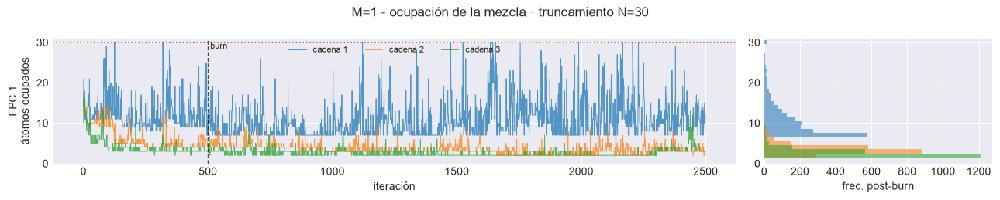

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,1,1,1,10.53,30,27.0,30,True,0.60%
1,1,1,2,3.49,9,8.0,30,False,0.00%
2,1,1,3,2.57,13,6.0,30,False,0.00%


! [M=2] alguna cadena alcanza N: subir mcmc_config['N'].


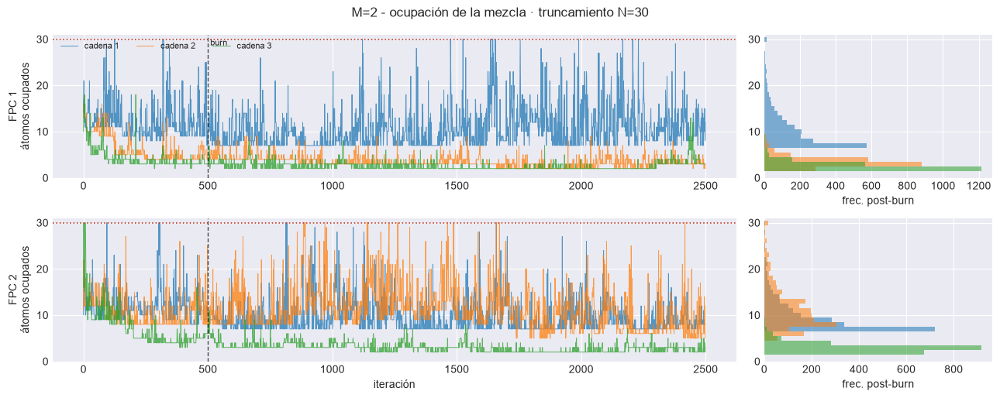

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,2,1,1,10.53,30,27.0,30,True,0.60%
1,2,1,2,3.49,9,8.0,30,False,0.00%
2,2,1,3,2.57,13,6.0,30,False,0.00%
3,2,2,1,9.47,30,22.0,30,True,0.15%
4,2,2,2,11.29,30,28.0,30,True,0.80%
5,2,2,3,2.97,11,6.0,30,False,0.00%


! [M=3] alguna cadena alcanza N: subir mcmc_config['N'].


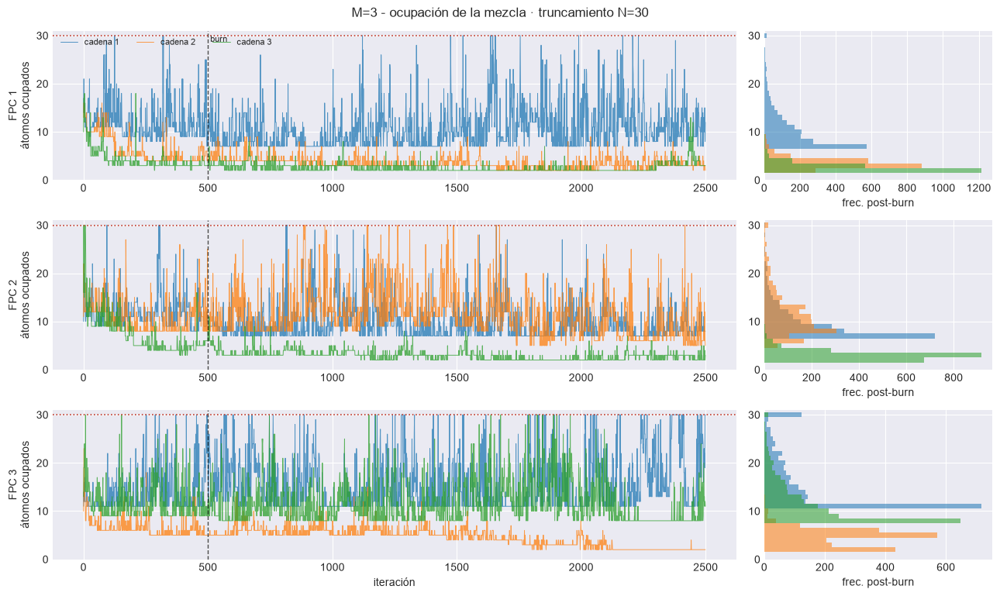

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,3,1,1,10.53,30,27.0,30,True,0.60%
1,3,1,2,3.49,9,8.0,30,False,0.00%
2,3,1,3,2.57,13,6.0,30,False,0.00%
3,3,2,1,9.47,30,22.0,30,True,0.15%
4,3,2,2,11.29,30,28.0,30,True,0.80%
5,3,2,3,2.97,11,6.0,30,False,0.00%
6,3,3,1,15.72,30,30.0,30,True,6.10%
7,3,3,2,4.48,15,10.0,30,False,0.00%
8,3,3,3,11.43,30,26.0,30,True,0.60%


! [M=4] alguna cadena alcanza N: subir mcmc_config['N'].


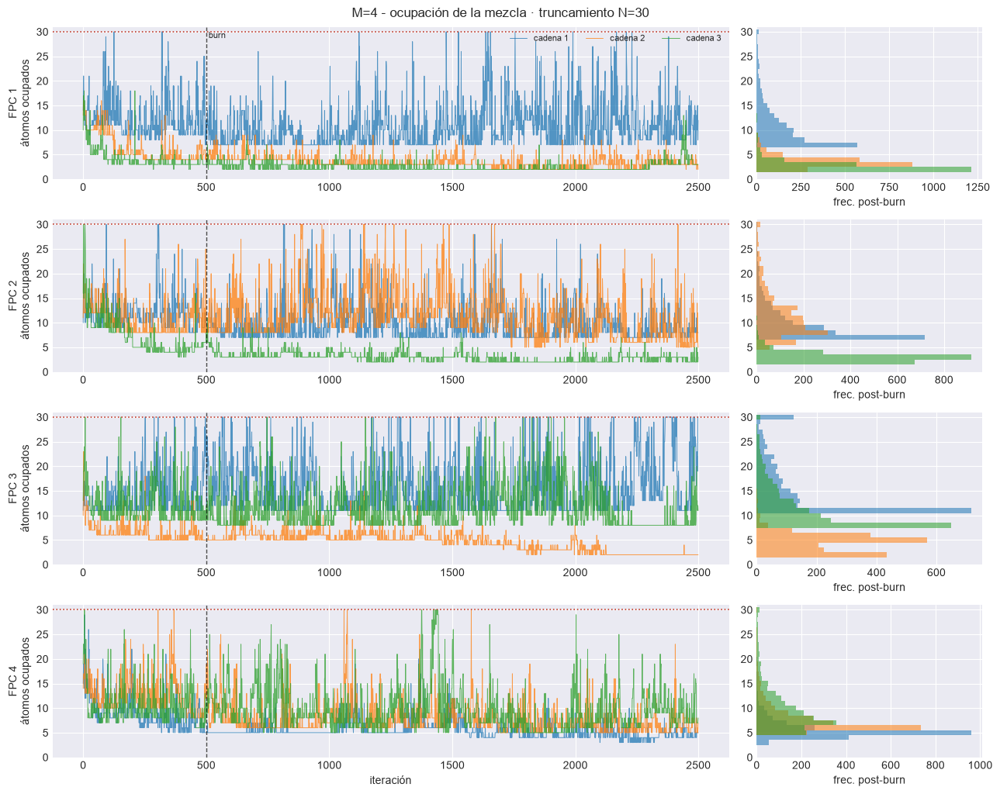

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,4,1,1,10.53,30,27.0,30,True,0.60%
1,4,1,2,3.49,9,8.0,30,False,0.00%
2,4,1,3,2.57,13,6.0,30,False,0.00%
3,4,2,1,9.47,30,22.0,30,True,0.15%
4,4,2,2,11.29,30,28.0,30,True,0.80%
5,4,2,3,2.97,11,6.0,30,False,0.00%
6,4,3,1,15.72,30,30.0,30,True,6.10%
7,4,3,2,4.48,15,10.0,30,False,0.00%
8,4,3,3,11.43,30,26.0,30,True,0.60%
9,4,4,1,5.41,20,11.0,30,False,0.00%


! [M=5] alguna cadena alcanza N: subir mcmc_config['N'].


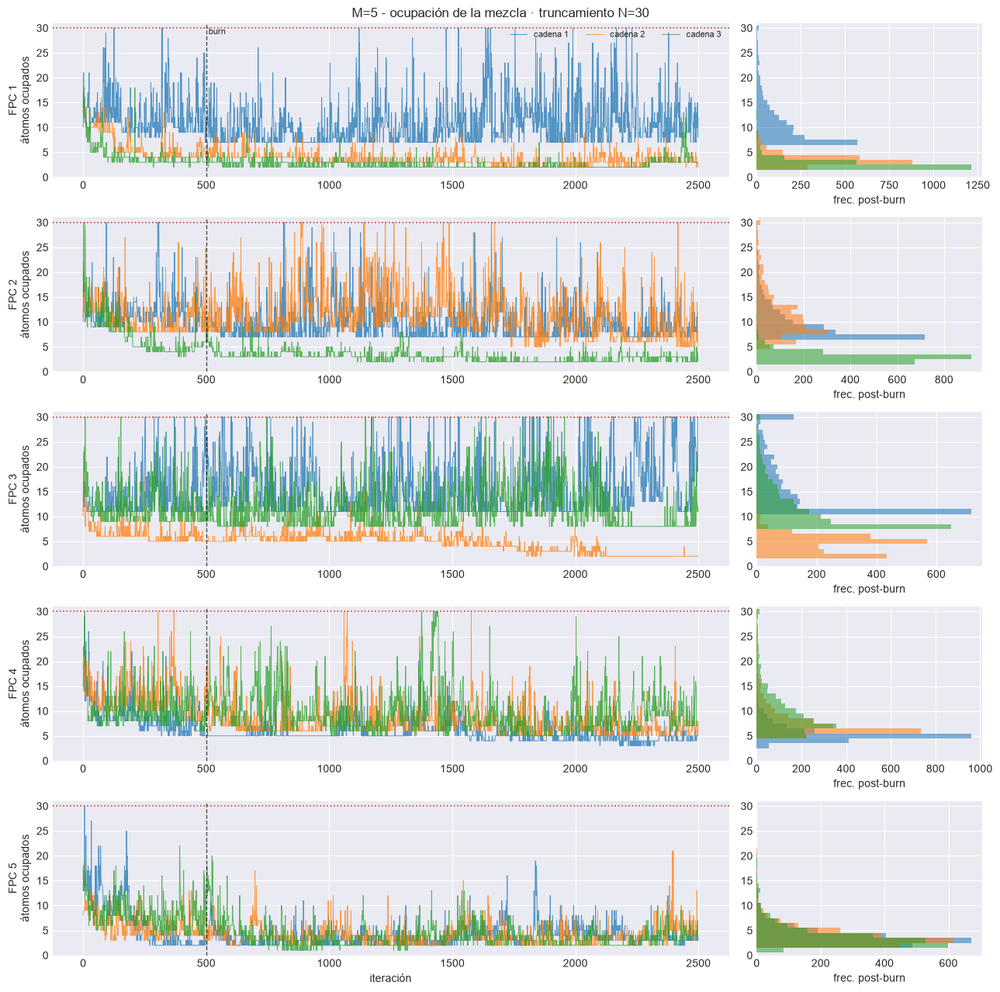

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,5,1,1,10.53,30,27.0,30,True,0.60%
1,5,1,2,3.49,9,8.0,30,False,0.00%
2,5,1,3,2.57,13,6.0,30,False,0.00%
3,5,2,1,9.47,30,22.0,30,True,0.15%
4,5,2,2,11.29,30,28.0,30,True,0.80%
5,5,2,3,2.97,11,6.0,30,False,0.00%
6,5,3,1,15.72,30,30.0,30,True,6.10%
7,5,3,2,4.48,15,10.0,30,False,0.00%
8,5,3,3,11.43,30,26.0,30,True,0.60%
9,5,4,1,5.41,20,11.0,30,False,0.00%


! [M=6] alguna cadena alcanza N: subir mcmc_config['N'].


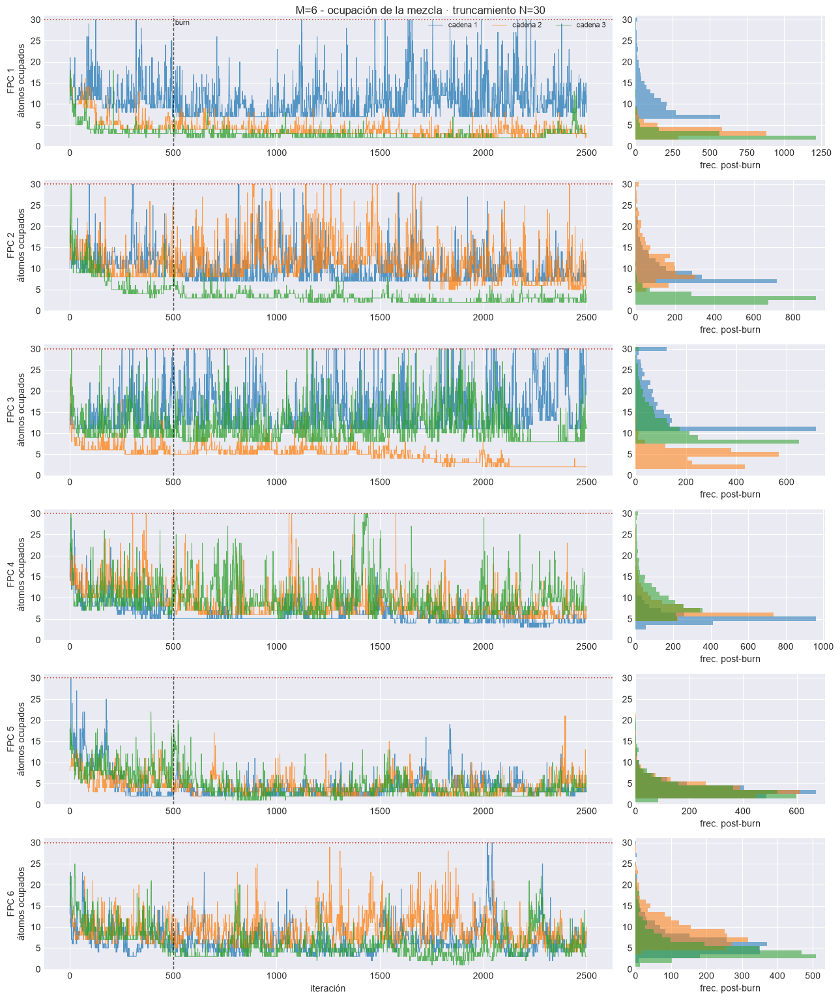

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,6,1,1,10.53,30,27.0,30,True,0.60%
1,6,1,2,3.49,9,8.0,30,False,0.00%
2,6,1,3,2.57,13,6.0,30,False,0.00%
3,6,2,1,9.47,30,22.0,30,True,0.15%
4,6,2,2,11.29,30,28.0,30,True,0.80%
5,6,2,3,2.97,11,6.0,30,False,0.00%
6,6,3,1,15.72,30,30.0,30,True,6.10%
7,6,3,2,4.48,15,10.0,30,False,0.00%
8,6,3,3,11.43,30,26.0,30,True,0.60%
9,6,4,1,5.41,20,11.0,30,False,0.00%


! [M=7] alguna cadena alcanza N: subir mcmc_config['N'].


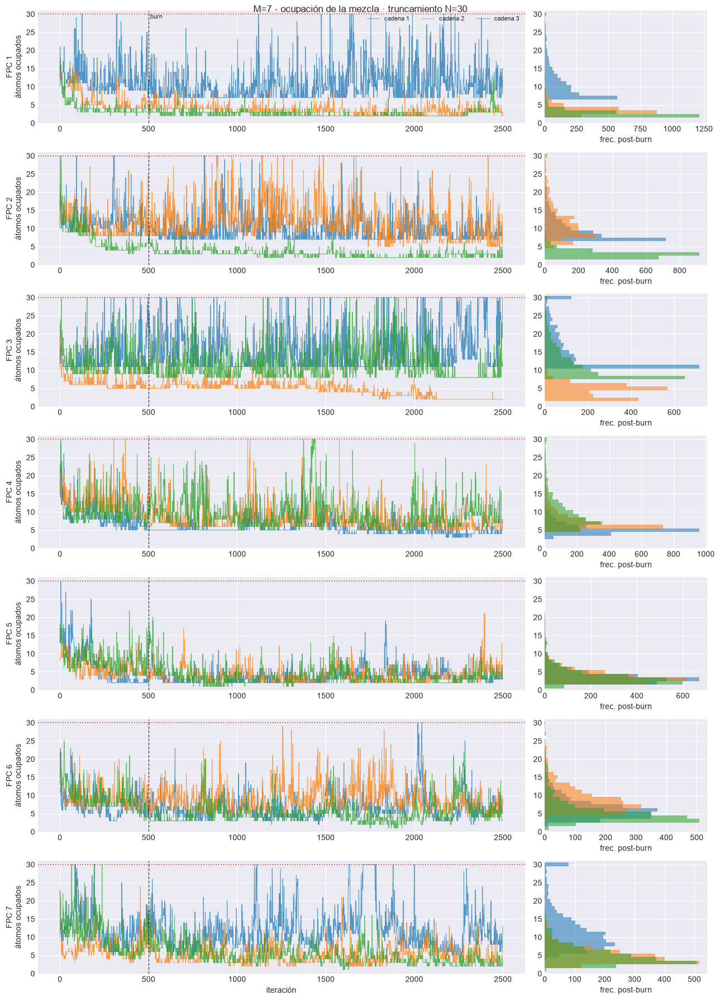

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,7,1,1,10.53,30,27.0,30,True,0.60%
1,7,1,2,3.49,9,8.0,30,False,0.00%
2,7,1,3,2.57,13,6.0,30,False,0.00%
3,7,2,1,9.47,30,22.0,30,True,0.15%
4,7,2,2,11.29,30,28.0,30,True,0.80%
5,7,2,3,2.97,11,6.0,30,False,0.00%
6,7,3,1,15.72,30,30.0,30,True,6.10%
7,7,3,2,4.48,15,10.0,30,False,0.00%
8,7,3,3,11.43,30,26.0,30,True,0.60%
9,7,4,1,5.41,20,11.0,30,False,0.00%


! [M=8] alguna cadena alcanza N: subir mcmc_config['N'].


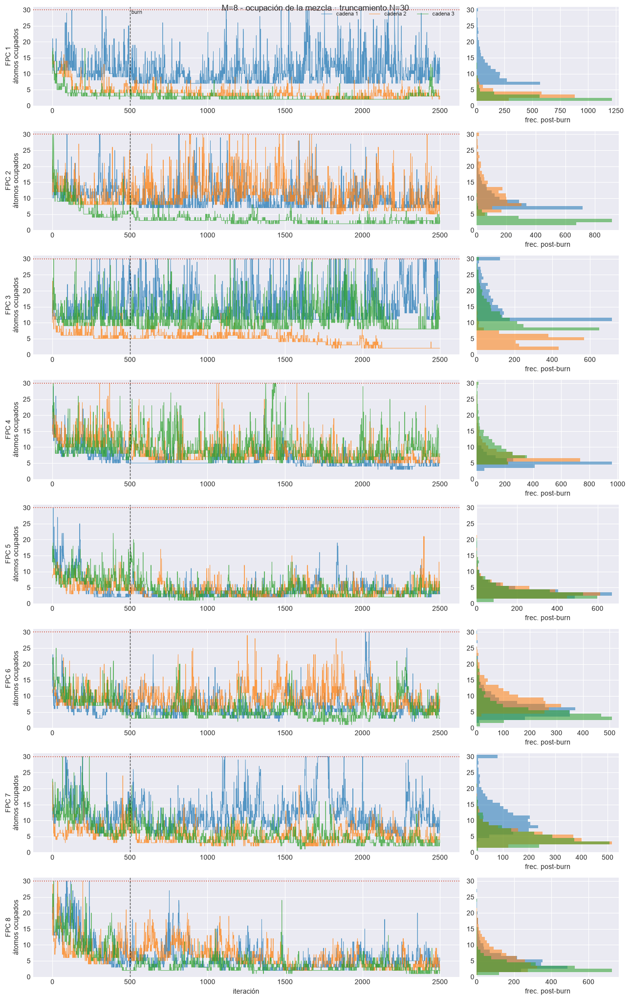

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,8,1,1,10.53,30,27.0,30,True,0.60%
1,8,1,2,3.49,9,8.0,30,False,0.00%
2,8,1,3,2.57,13,6.0,30,False,0.00%
3,8,2,1,9.47,30,22.0,30,True,0.15%
4,8,2,2,11.29,30,28.0,30,True,0.80%
5,8,2,3,2.97,11,6.0,30,False,0.00%
6,8,3,1,15.72,30,30.0,30,True,6.10%
7,8,3,2,4.48,15,10.0,30,False,0.00%
8,8,3,3,11.43,30,26.0,30,True,0.60%
9,8,4,1,5.41,20,11.0,30,False,0.00%


! [M=9] alguna cadena alcanza N: subir mcmc_config['N'].


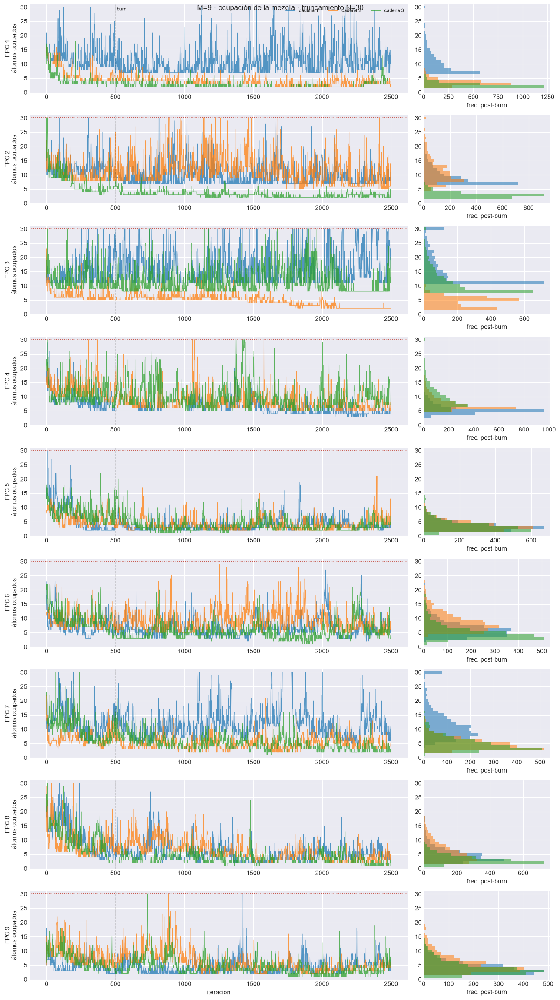

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,9,1,1,10.53,30,27.0,30,True,0.60%
1,9,1,2,3.49,9,8.0,30,False,0.00%
2,9,1,3,2.57,13,6.0,30,False,0.00%
3,9,2,1,9.47,30,22.0,30,True,0.15%
4,9,2,2,11.29,30,28.0,30,True,0.80%
5,9,2,3,2.97,11,6.0,30,False,0.00%
6,9,3,1,15.72,30,30.0,30,True,6.10%
7,9,3,2,4.48,15,10.0,30,False,0.00%
8,9,3,3,11.43,30,26.0,30,True,0.60%
9,9,4,1,5.41,20,11.0,30,False,0.00%


! [M=10] alguna cadena alcanza N: subir mcmc_config['N'].


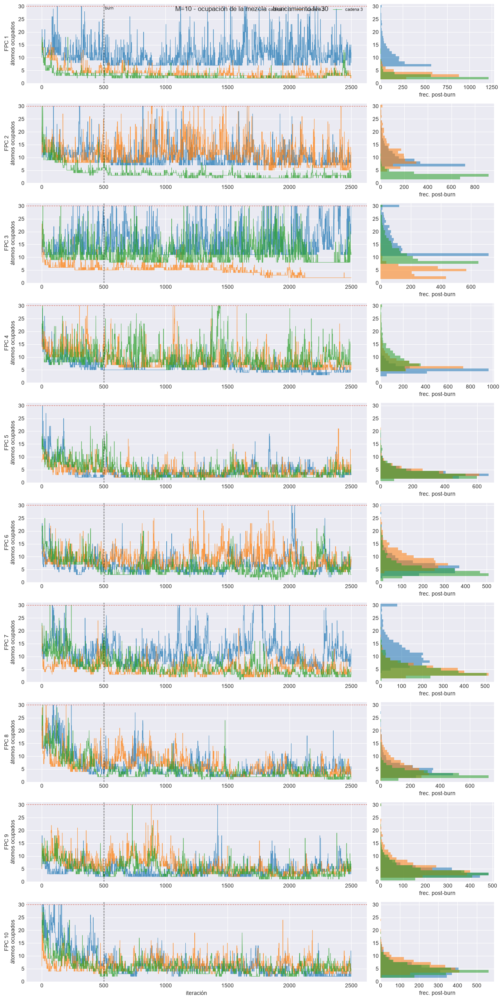

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,10,1,1,10.53,30,27.0,30,True,0.60%
1,10,1,2,3.49,9,8.0,30,False,0.00%
2,10,1,3,2.57,13,6.0,30,False,0.00%
3,10,2,1,9.47,30,22.0,30,True,0.15%
4,10,2,2,11.29,30,28.0,30,True,0.80%
5,10,2,3,2.97,11,6.0,30,False,0.00%
6,10,3,1,15.72,30,30.0,30,True,6.10%
7,10,3,2,4.48,15,10.0,30,False,0.00%
8,10,3,3,11.43,30,26.0,30,True,0.60%
9,10,4,1,5.41,20,11.0,30,False,0.00%


In [8]:
for M in M_OK:
    e = EST[M]
    ocup_df = ocupacion_mezcla(e, M)
    plot_ocupacion_mezcla(e, M, e["paths"]["out_report"] / "41_ocupacion_mezcla.png")
    plt.show()
    display(ocup_df.style.format({"media": "{:.2f}", "p99": "{:.1f}", "frac_en_N": "{:.2%}"})
            .set_caption(f"M={M} - átomos ocupados post-calentamiento"))

### 4.1 Gating: $\psi$, $\alpha$, $\Gamma$

Promedios ponderados por el peso medio de cada átomo, $\bar w_h=\frac1n\sum_i\pi_h(x_i)$,
para que no dependan del etiquetado. **Señal de gating** = átomos efectivos
globales menos por punto (≈ 0 si los pesos son los mismos en todo $x$);
**sd del argumento** = dispersión en $i$ de $\alpha_h-\sum_j\psi_{hj}|x_{ij}-\Gamma_{hj}|$.

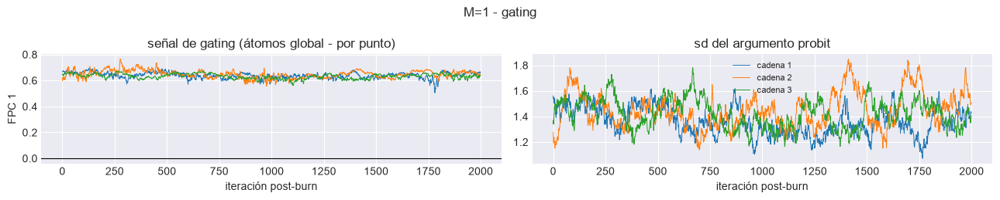

,M,FPC,variable,media_c1,media_c2,media_c3,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,1,atomos_global,2.015,2.019,1.923,3,2000,10,19,4.253,1.220,False
1,1,1,atomos_punto,1.376,1.371,1.291,3,2000,11,19,3.853,1.174,False
2,1,1,senal_gating,0.639,0.649,0.632,3,2000,11,21,4.927,1.059,False
3,1,1,sd_argumento,1.362,1.450,1.423,3,2000,10,20,6.647,1.068,False
4,1,1,alpha,2.723,2.741,3.176,3,2000,6,13,6.183,1.310,False
5,1,1,psi_0,2.069,2.211,2.157,3,2000,11,20,5.749,1.074,False
6,1,1,psi_1,0.001,0.000,0.001,3,2000,35,394,7.154,1.002,False
7,1,1,psi_2,0.000,0.000,0.000,3,2000,1113,1478,2.779,1.000,False
8,1,1,psi_3,0.000,0.000,0.000,3,2000,336,988,1.115,1.000,True
9,1,1,Gamma_0,-0.156,-0.277,-0.142,3,2000,68,153,2.765,1.013,False


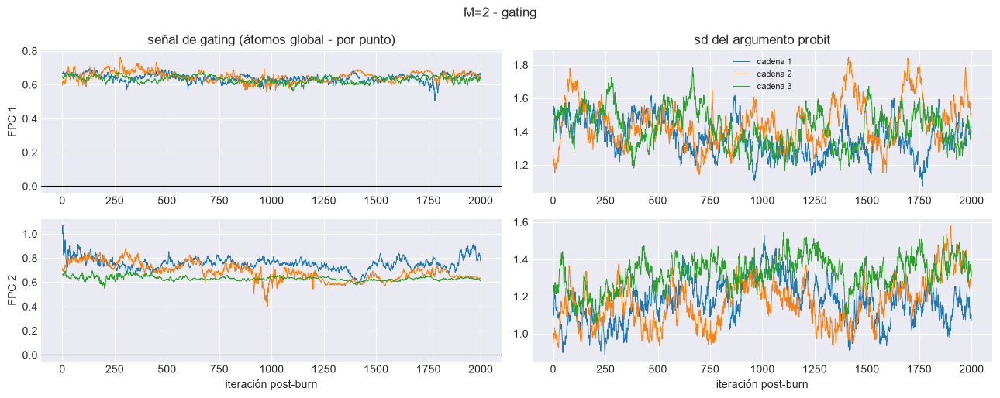

,M,FPC,variable,media_c1,media_c2,media_c3,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,2,1,atomos_global,2.015,2.019,1.923,3,2000,10,19,4.253,1.220,False
1,2,1,atomos_punto,1.376,1.371,1.291,3,2000,11,19,3.853,1.174,False
2,2,1,senal_gating,0.639,0.649,0.632,3,2000,11,21,4.927,1.059,False
3,2,1,sd_argumento,1.362,1.450,1.423,3,2000,10,20,6.647,1.068,False
4,2,1,alpha,2.723,2.741,3.176,3,2000,6,13,6.183,1.310,False
5,2,1,psi_0,2.069,2.211,2.157,3,2000,11,20,5.749,1.074,False
6,2,1,psi_1,0.001,0.000,0.001,3,2000,35,394,7.154,1.002,False
7,2,1,psi_2,0.000,0.000,0.000,3,2000,1113,1478,2.779,1.000,False
8,2,1,psi_3,0.000,0.000,0.000,3,2000,336,988,1.115,1.000,True
9,2,1,Gamma_0,-0.156,-0.277,-0.142,3,2000,68,153,2.765,1.013,False


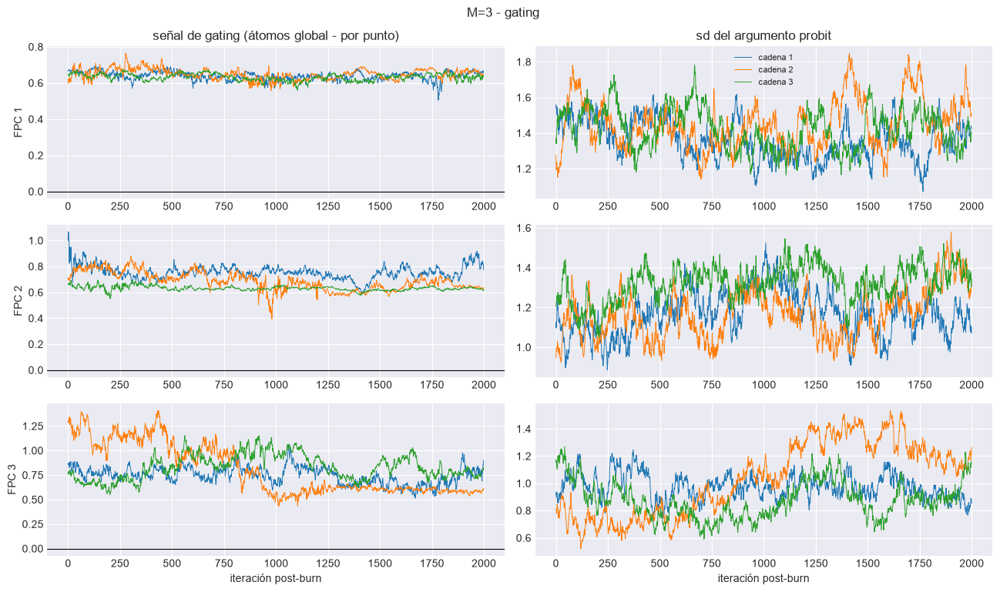

,M,FPC,variable,media_c1,media_c2,media_c3,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,3,1,atomos_global,2.015,2.019,1.923,3,2000,10,19,4.253,1.220,False
1,3,1,atomos_punto,1.376,1.371,1.291,3,2000,11,19,3.853,1.174,False
2,3,1,senal_gating,0.639,0.649,0.632,3,2000,11,21,4.927,1.059,False
3,3,1,sd_argumento,1.362,1.450,1.423,3,2000,10,20,6.647,1.068,False
4,3,1,alpha,2.723,2.741,3.176,3,2000,6,13,6.183,1.310,False
5,3,1,psi_0,2.069,2.211,2.157,3,2000,11,20,5.749,1.074,False
6,3,1,psi_1,0.001,0.000,0.001,3,2000,35,394,7.154,1.002,False
7,3,1,psi_2,0.000,0.000,0.000,3,2000,1113,1478,2.779,1.000,False
8,3,1,psi_3,0.000,0.000,0.000,3,2000,336,988,1.115,1.000,True
9,3,1,Gamma_0,-0.156,-0.277,-0.142,3,2000,68,153,2.765,1.013,False


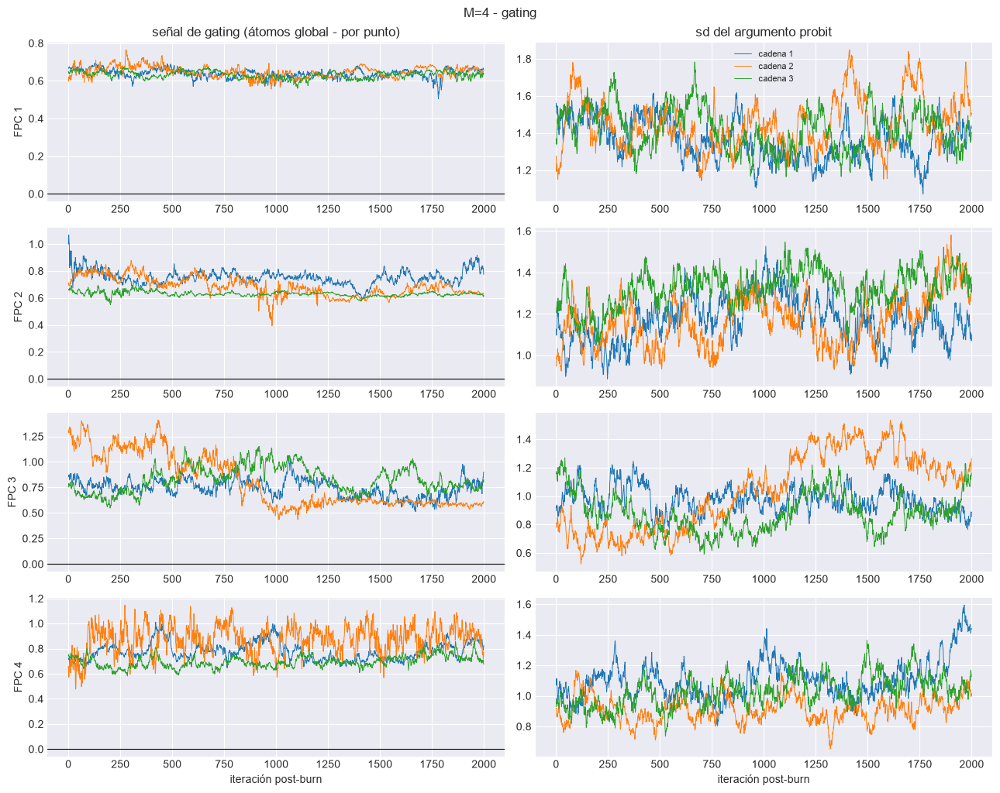

,M,FPC,variable,media_c1,media_c2,media_c3,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,4,1,atomos_global,2.015,2.019,1.923,3,2000,10,19,4.253,1.220,False
1,4,1,atomos_punto,1.376,1.371,1.291,3,2000,11,19,3.853,1.174,False
2,4,1,senal_gating,0.639,0.649,0.632,3,2000,11,21,4.927,1.059,False
3,4,1,sd_argumento,1.362,1.450,1.423,3,2000,10,20,6.647,1.068,False
4,4,1,alpha,2.723,2.741,3.176,3,2000,6,13,6.183,1.310,False
5,4,1,psi_0,2.069,2.211,2.157,3,2000,11,20,5.749,1.074,False
6,4,1,psi_1,0.001,0.000,0.001,3,2000,35,394,7.154,1.002,False
7,4,1,psi_2,0.000,0.000,0.000,3,2000,1113,1478,2.779,1.000,False
8,4,1,psi_3,0.000,0.000,0.000,3,2000,336,988,1.115,1.000,True
9,4,1,Gamma_0,-0.156,-0.277,-0.142,3,2000,68,153,2.765,1.013,False


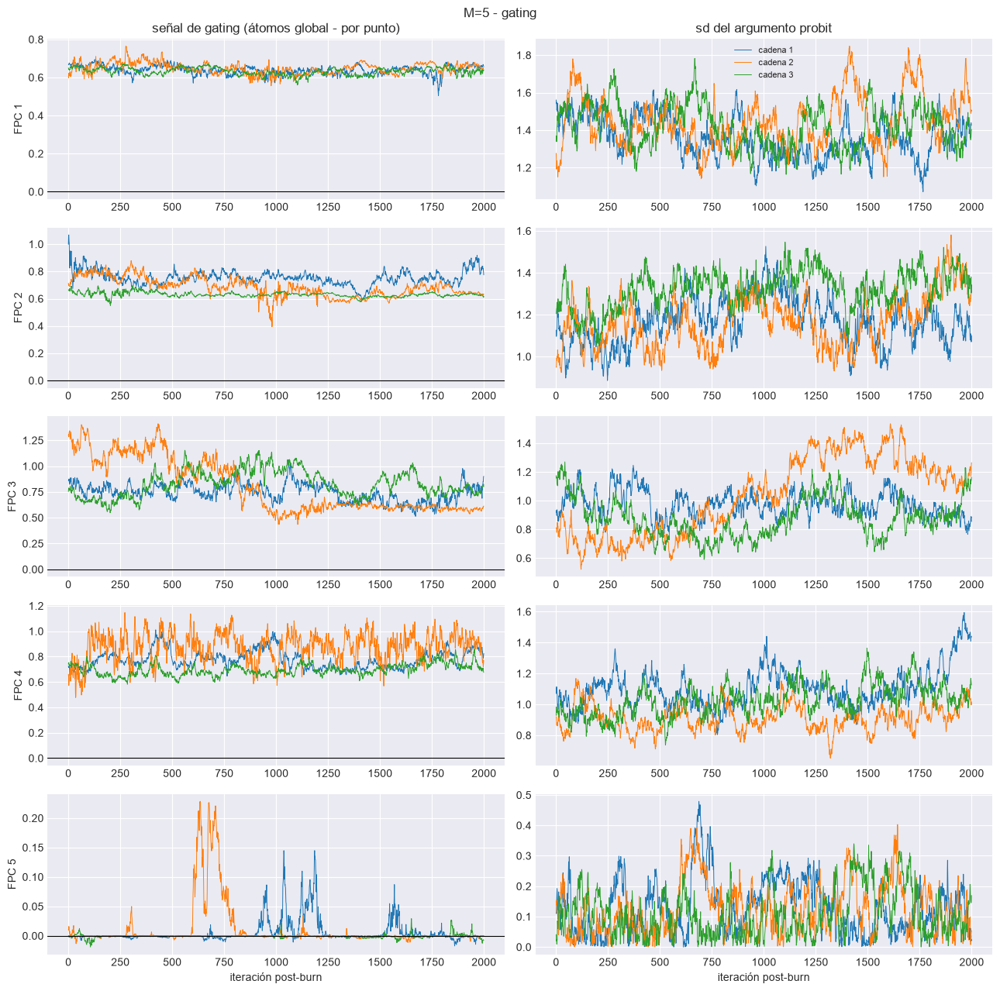

,M,FPC,variable,media_c1,media_c2,media_c3,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,5,1,atomos_global,2.015,2.019,1.923,3,2000,10,19,4.253,1.220,False
1,5,1,atomos_punto,1.376,1.371,1.291,3,2000,11,19,3.853,1.174,False
2,5,1,senal_gating,0.639,0.649,0.632,3,2000,11,21,4.927,1.059,False
3,5,1,sd_argumento,1.362,1.450,1.423,3,2000,10,20,6.647,1.068,False
4,5,1,alpha,2.723,2.741,3.176,3,2000,6,13,6.183,1.310,False
5,5,1,psi_0,2.069,2.211,2.157,3,2000,11,20,5.749,1.074,False
6,5,1,psi_1,0.001,0.000,0.001,3,2000,35,394,7.154,1.002,False
7,5,1,psi_2,0.000,0.000,0.000,3,2000,1113,1478,2.779,1.000,False
8,5,1,psi_3,0.000,0.000,0.000,3,2000,336,988,1.115,1.000,True
9,5,1,Gamma_0,-0.156,-0.277,-0.142,3,2000,68,153,2.765,1.013,False


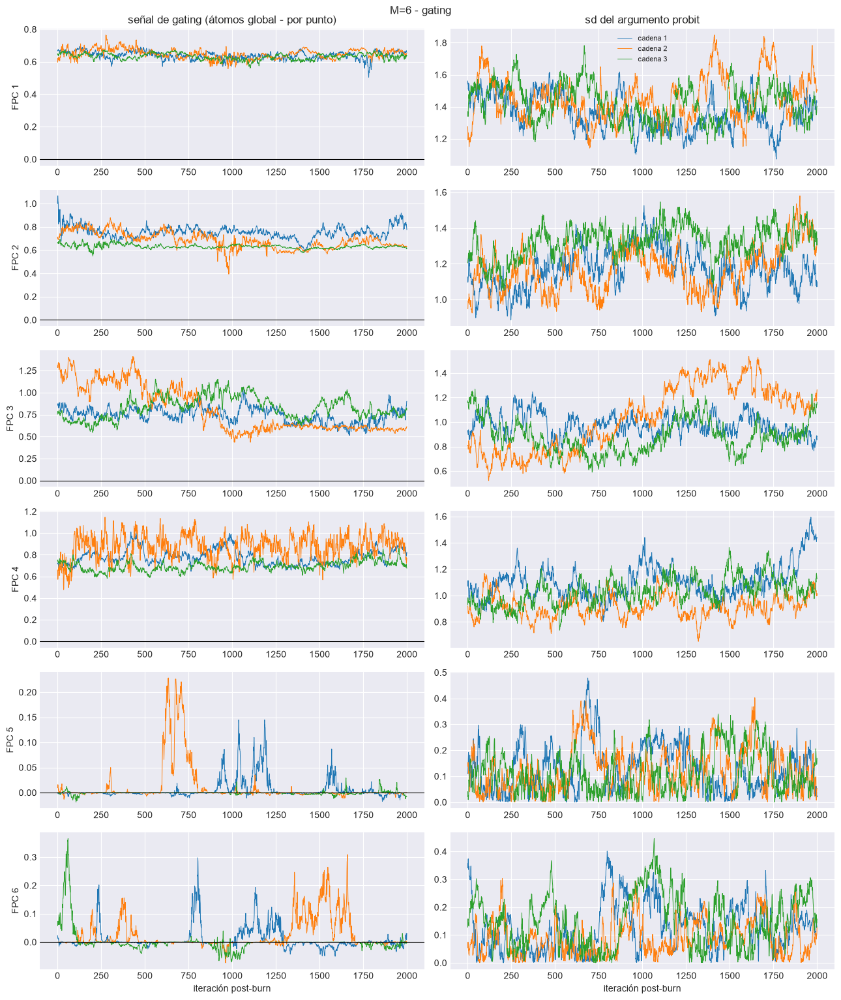

,M,FPC,variable,media_c1,media_c2,media_c3,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,6,1,atomos_global,2.015,2.019,1.923,3,2000,10,19,4.253,1.220,False
1,6,1,atomos_punto,1.376,1.371,1.291,3,2000,11,19,3.853,1.174,False
2,6,1,senal_gating,0.639,0.649,0.632,3,2000,11,21,4.927,1.059,False
3,6,1,sd_argumento,1.362,1.450,1.423,3,2000,10,20,6.647,1.068,False
4,6,1,alpha,2.723,2.741,3.176,3,2000,6,13,6.183,1.310,False
5,6,1,psi_0,2.069,2.211,2.157,3,2000,11,20,5.749,1.074,False
6,6,1,psi_1,0.001,0.000,0.001,3,2000,35,394,7.154,1.002,False
7,6,1,psi_2,0.000,0.000,0.000,3,2000,1113,1478,2.779,1.000,False
8,6,1,psi_3,0.000,0.000,0.000,3,2000,336,988,1.115,1.000,True
9,6,1,Gamma_0,-0.156,-0.277,-0.142,3,2000,68,153,2.765,1.013,False


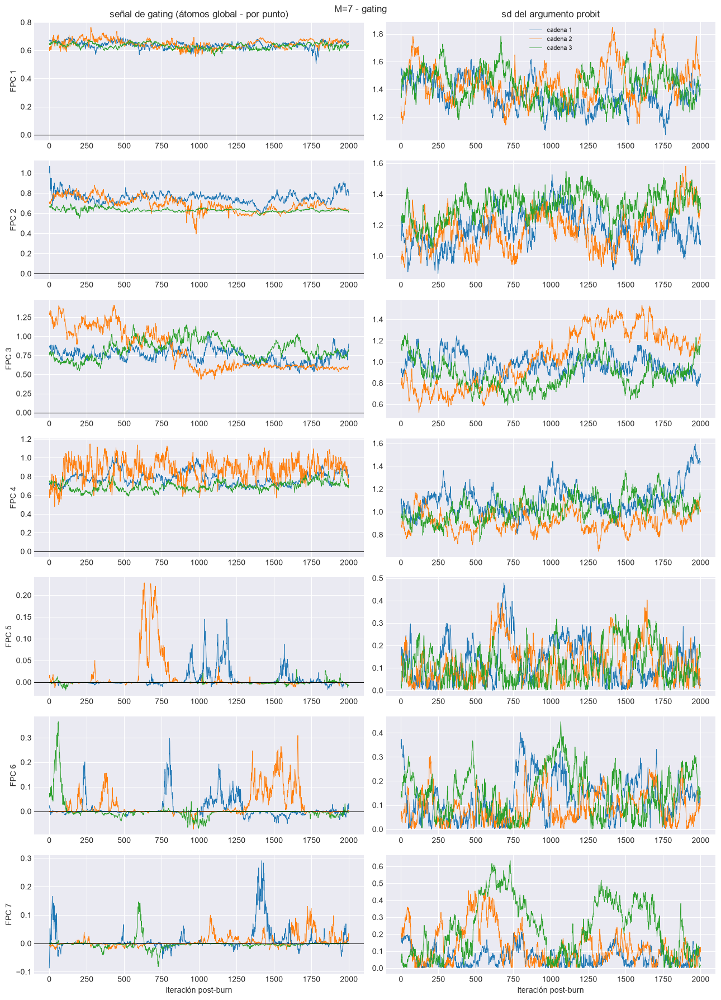

,M,FPC,variable,media_c1,media_c2,media_c3,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,7,1,atomos_global,2.015,2.019,1.923,3,2000,10,19,4.253,1.220,False
1,7,1,atomos_punto,1.376,1.371,1.291,3,2000,11,19,3.853,1.174,False
2,7,1,senal_gating,0.639,0.649,0.632,3,2000,11,21,4.927,1.059,False
3,7,1,sd_argumento,1.362,1.450,1.423,3,2000,10,20,6.647,1.068,False
4,7,1,alpha,2.723,2.741,3.176,3,2000,6,13,6.183,1.310,False
5,7,1,psi_0,2.069,2.211,2.157,3,2000,11,20,5.749,1.074,False
6,7,1,psi_1,0.001,0.000,0.001,3,2000,35,394,7.154,1.002,False
7,7,1,psi_2,0.000,0.000,0.000,3,2000,1113,1478,2.779,1.000,False
8,7,1,psi_3,0.000,0.000,0.000,3,2000,336,988,1.115,1.000,True
9,7,1,Gamma_0,-0.156,-0.277,-0.142,3,2000,68,153,2.765,1.013,False


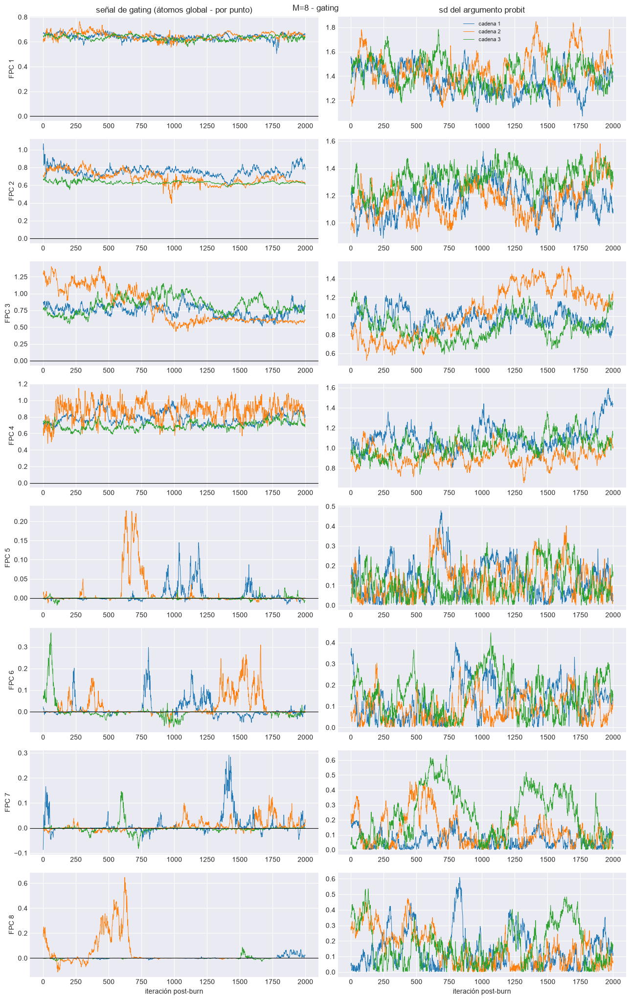

,M,FPC,variable,media_c1,media_c2,media_c3,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,8,1,atomos_global,2.015,2.019,1.923,3,2000,10,19,4.253,1.220,False
1,8,1,atomos_punto,1.376,1.371,1.291,3,2000,11,19,3.853,1.174,False
2,8,1,senal_gating,0.639,0.649,0.632,3,2000,11,21,4.927,1.059,False
3,8,1,sd_argumento,1.362,1.450,1.423,3,2000,10,20,6.647,1.068,False
4,8,1,alpha,2.723,2.741,3.176,3,2000,6,13,6.183,1.310,False
5,8,1,psi_0,2.069,2.211,2.157,3,2000,11,20,5.749,1.074,False
6,8,1,psi_1,0.001,0.000,0.001,3,2000,35,394,7.154,1.002,False
7,8,1,psi_2,0.000,0.000,0.000,3,2000,1113,1478,2.779,1.000,False
8,8,1,psi_3,0.000,0.000,0.000,3,2000,336,988,1.115,1.000,True
9,8,1,Gamma_0,-0.156,-0.277,-0.142,3,2000,68,153,2.765,1.013,False


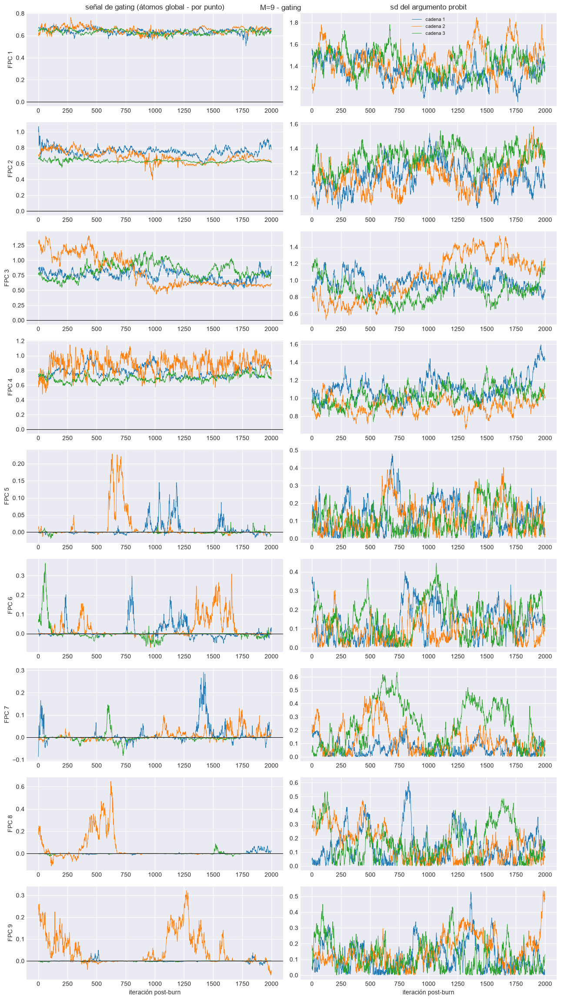

,M,FPC,variable,media_c1,media_c2,media_c3,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,9,1,atomos_global,2.015,2.019,1.923,3,2000,10,19,4.253,1.220,False
1,9,1,atomos_punto,1.376,1.371,1.291,3,2000,11,19,3.853,1.174,False
2,9,1,senal_gating,0.639,0.649,0.632,3,2000,11,21,4.927,1.059,False
3,9,1,sd_argumento,1.362,1.450,1.423,3,2000,10,20,6.647,1.068,False
4,9,1,alpha,2.723,2.741,3.176,3,2000,6,13,6.183,1.310,False
5,9,1,psi_0,2.069,2.211,2.157,3,2000,11,20,5.749,1.074,False
6,9,1,psi_1,0.001,0.000,0.001,3,2000,35,394,7.154,1.002,False
7,9,1,psi_2,0.000,0.000,0.000,3,2000,1113,1478,2.779,1.000,False
8,9,1,psi_3,0.000,0.000,0.000,3,2000,336,988,1.115,1.000,True
9,9,1,Gamma_0,-0.156,-0.277,-0.142,3,2000,68,153,2.765,1.013,False


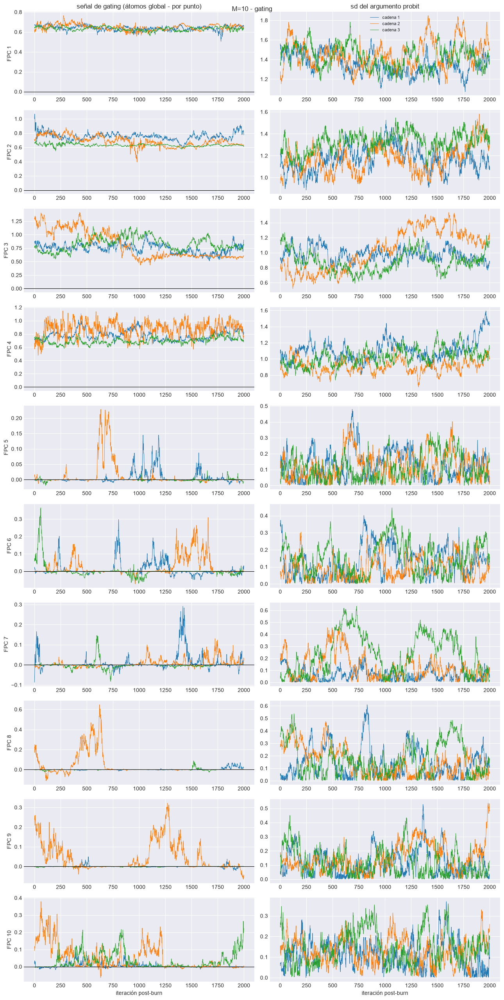

,M,FPC,variable,media_c1,media_c2,media_c3,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,10,1,atomos_global,2.015,2.019,1.923,3,2000,10,19,4.253,1.220,False
1,10,1,atomos_punto,1.376,1.371,1.291,3,2000,11,19,3.853,1.174,False
2,10,1,senal_gating,0.639,0.649,0.632,3,2000,11,21,4.927,1.059,False
3,10,1,sd_argumento,1.362,1.450,1.423,3,2000,10,20,6.647,1.068,False
4,10,1,alpha,2.723,2.741,3.176,3,2000,6,13,6.183,1.310,False
5,10,1,psi_0,2.069,2.211,2.157,3,2000,11,20,5.749,1.074,False
6,10,1,psi_1,0.001,0.000,0.001,3,2000,35,394,7.154,1.002,False
7,10,1,psi_2,0.000,0.000,0.000,3,2000,1113,1478,2.779,1.000,False
8,10,1,psi_3,0.000,0.000,0.000,3,2000,336,988,1.115,1.000,True
9,10,1,Gamma_0,-0.156,-0.277,-0.142,3,2000,68,153,2.765,1.013,False


In [9]:
_CACHE_GATING = {}      # clave (M, componente, cadena): las series cuestan

for M in M_OK:
    e = EST[M]
    gat, series = diagnostico_gating(e, M, _CACHE_GATING)
    plot_gating(series, e, M, e["paths"]["out_report"] / "49_gating.png")
    plt.show()
    display(gat.style.format({c: "{:.3f}" for c in gat.columns
                              if c.startswith("media_") or c in ("rhat", "geweke_max")}
                             | {"ess_min": "{:.0f}", "ess_mean": "{:.0f}"})
            .set_caption(f"M={M} - gating post-calentamiento"))

## 5. Figuras de convergencia por parámetro

== M=1 ==============================================


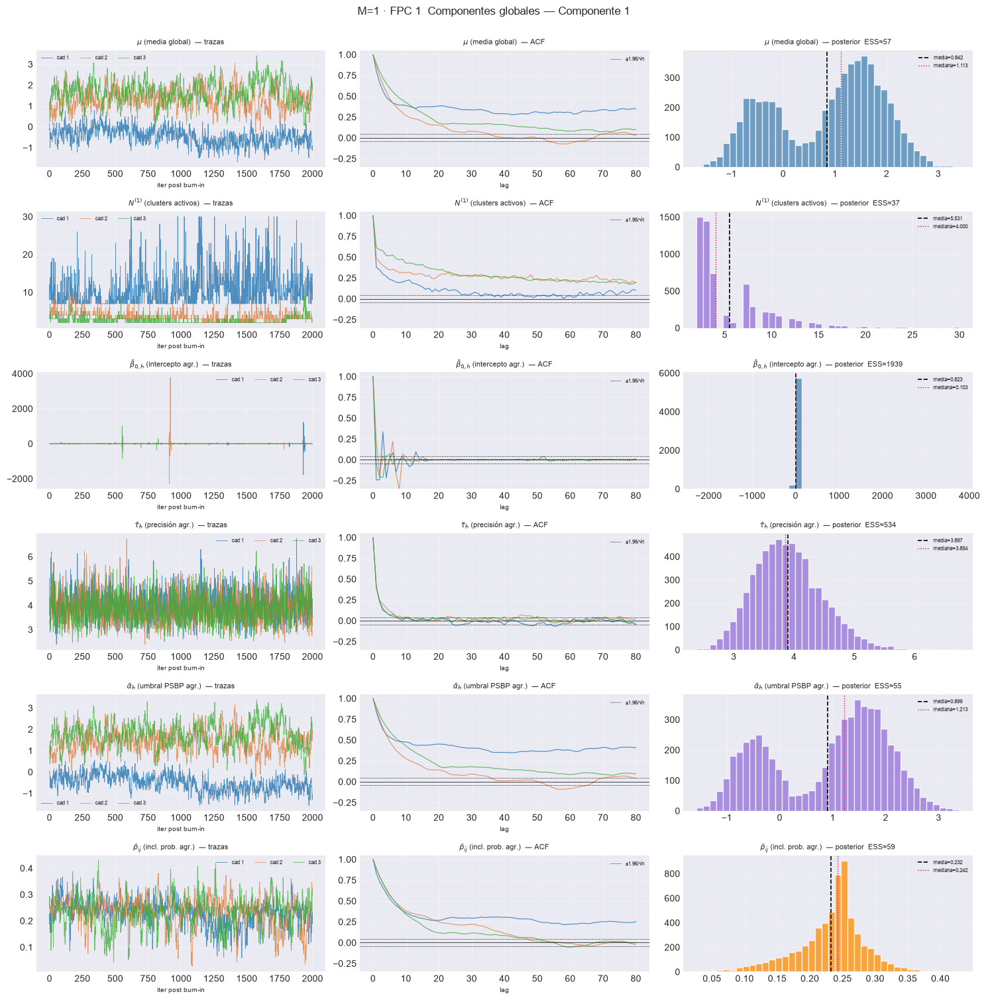

C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_global_components.py:276: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_global_components.py:278: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
c:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\.v_2\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


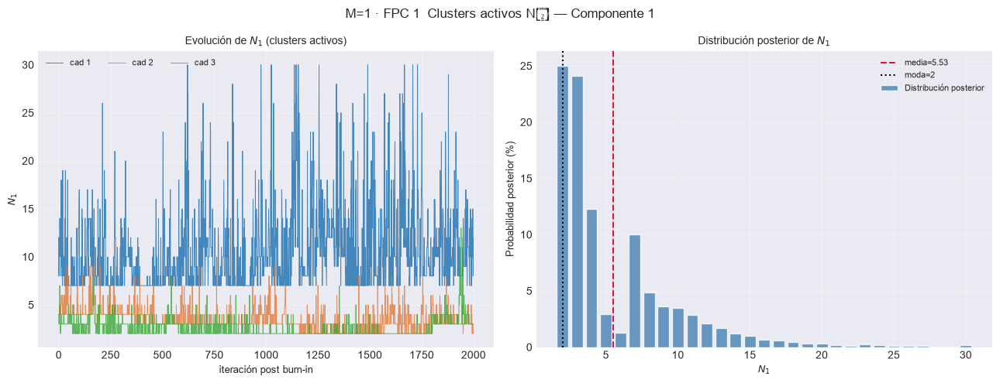

== M=2 ==============================================


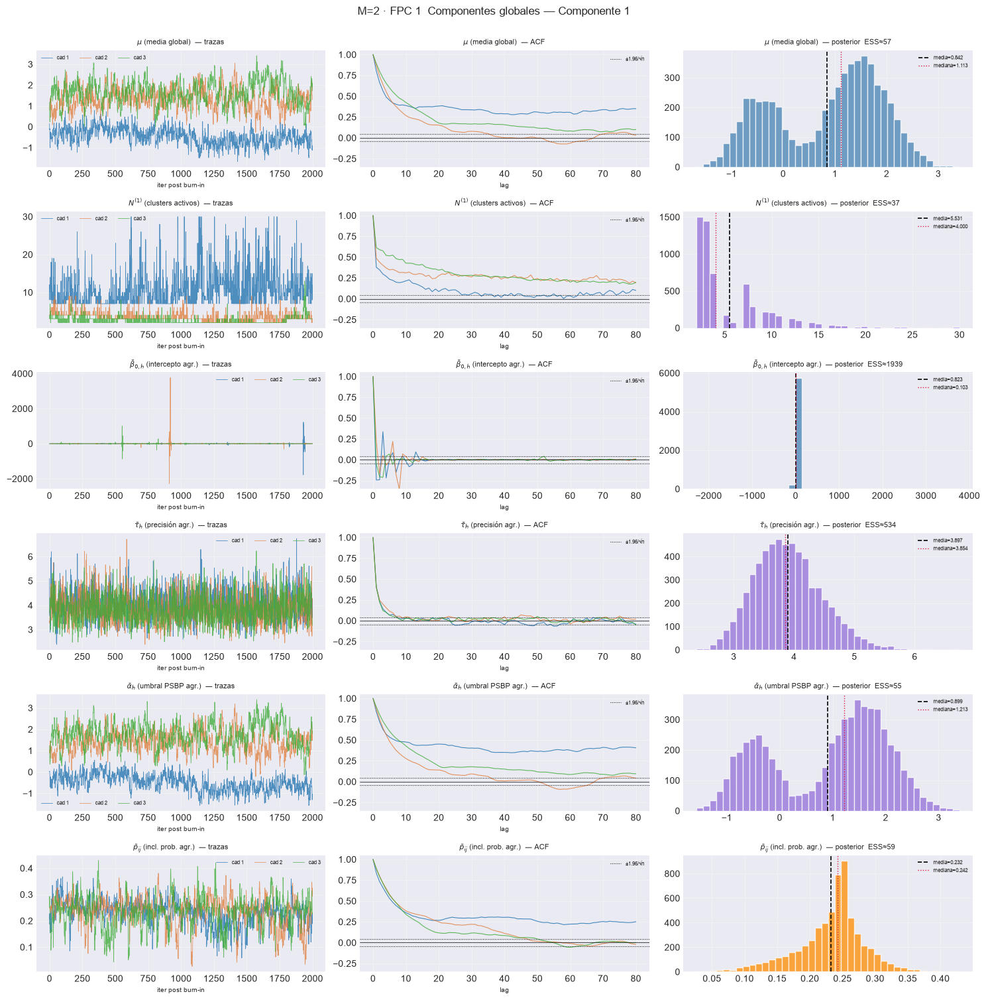

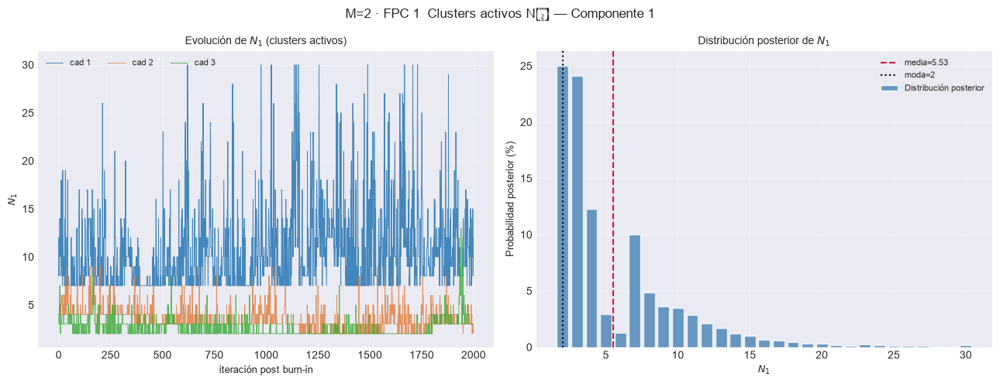

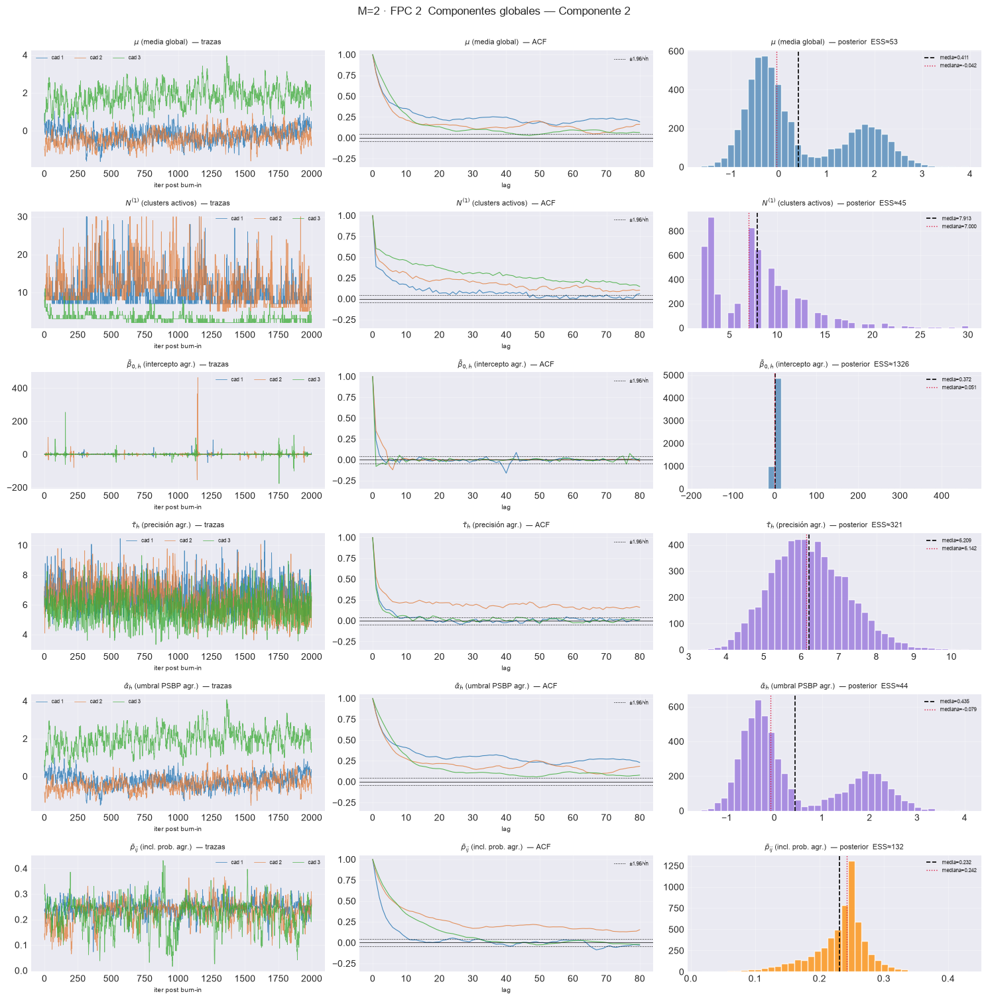

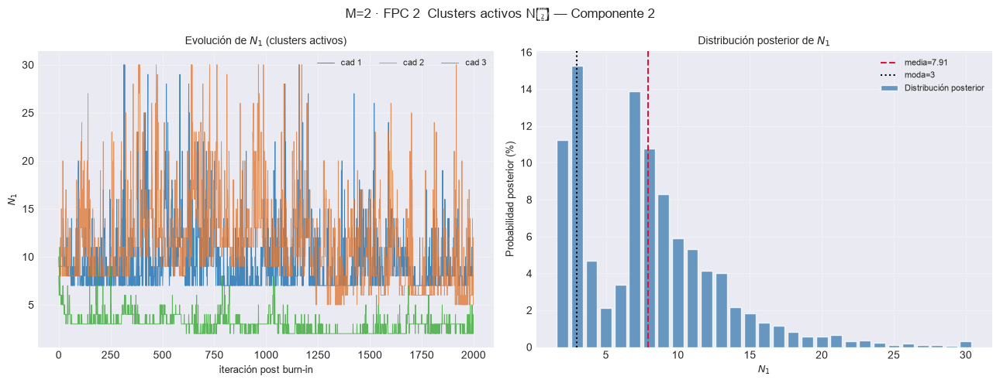

== M=3 ==============================================


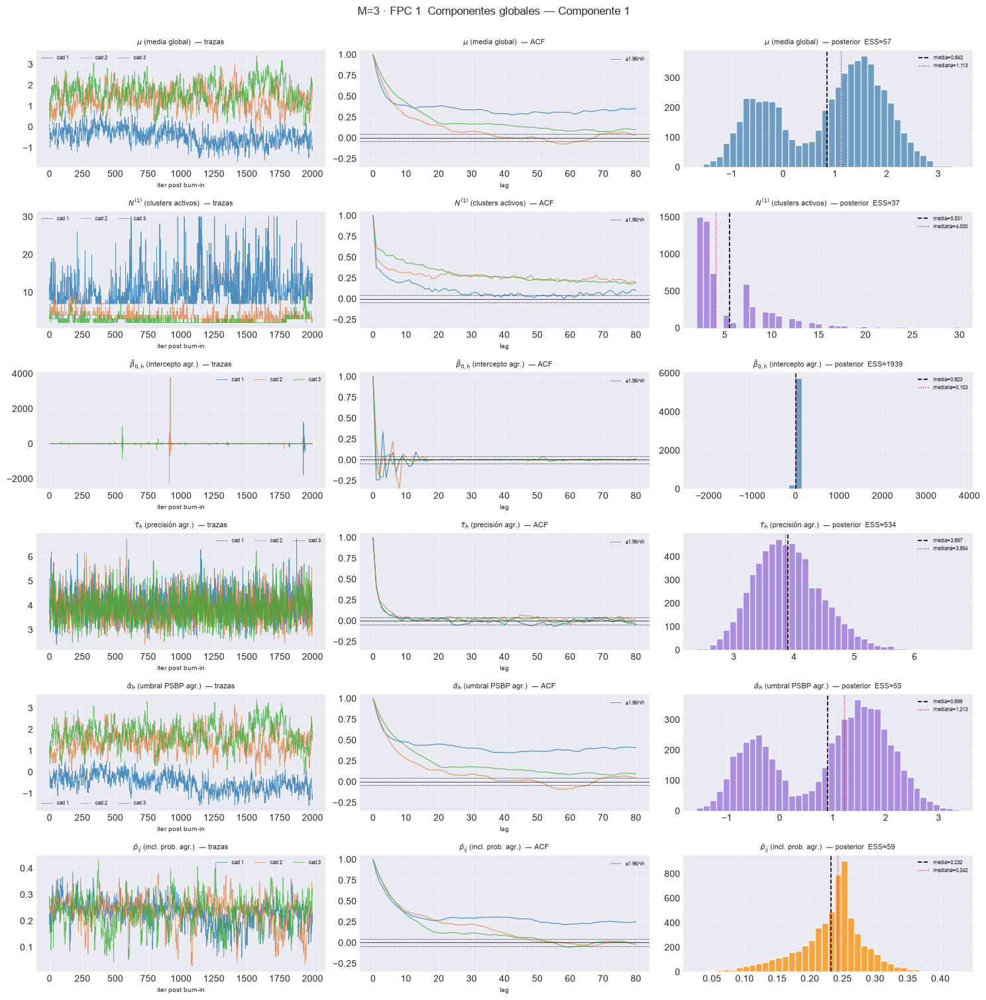

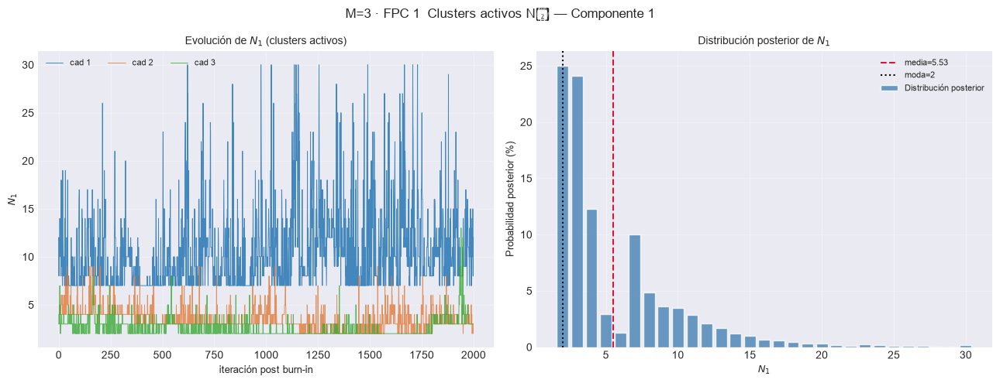

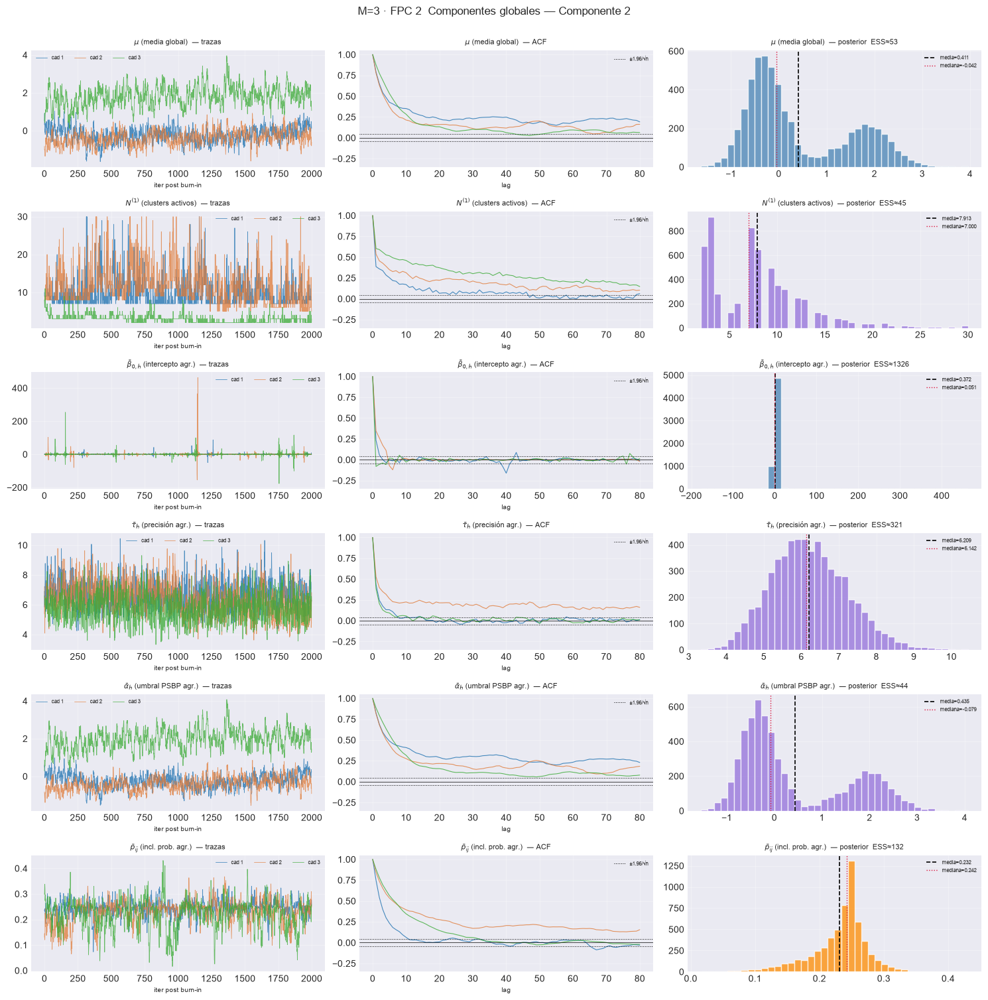

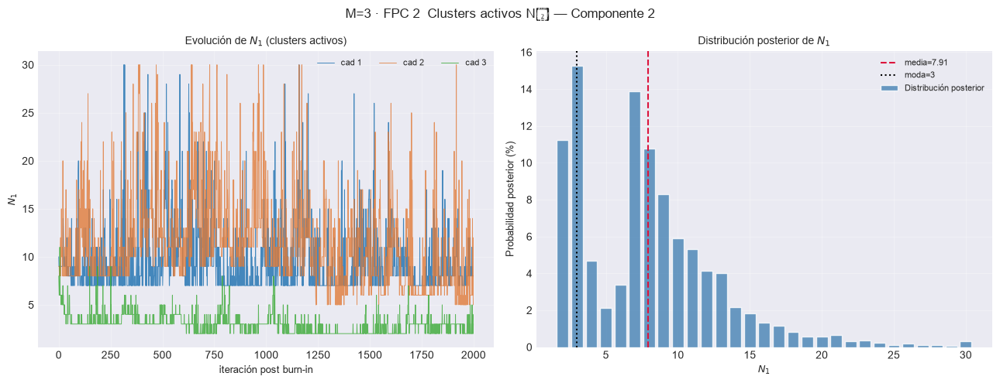

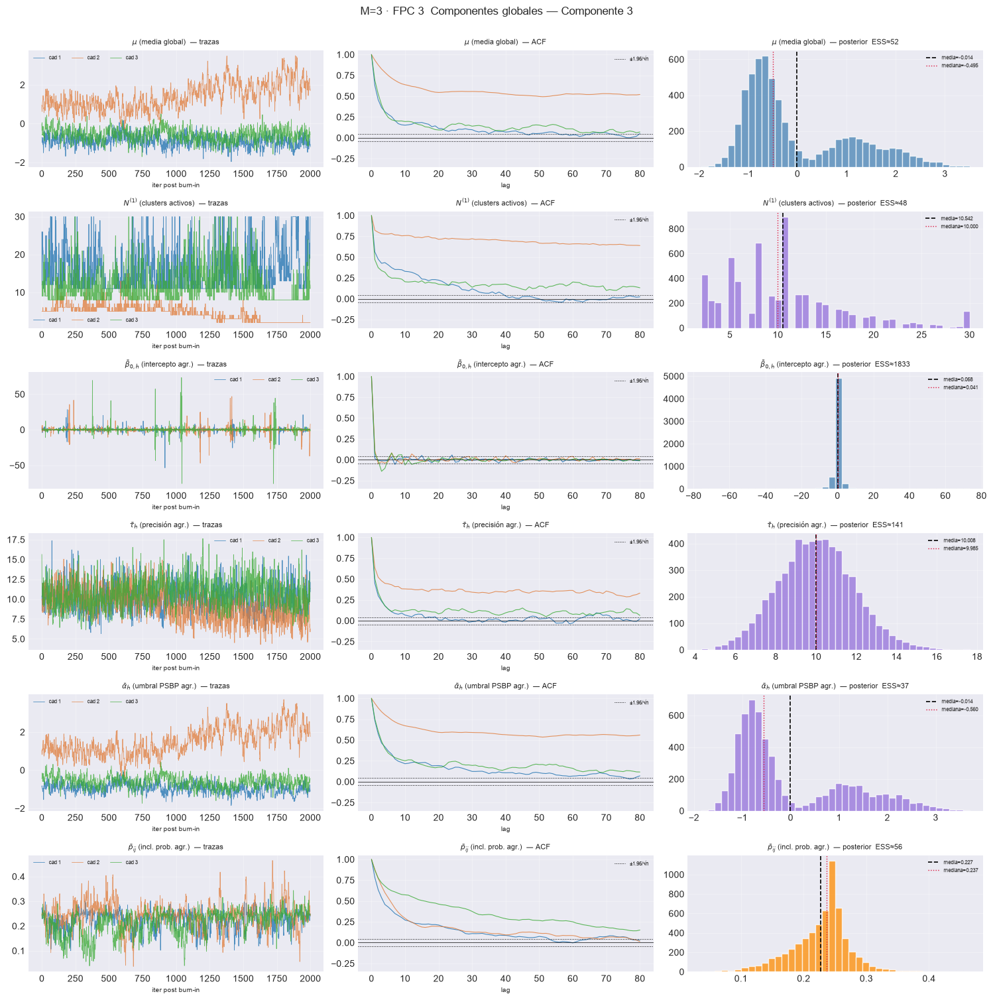

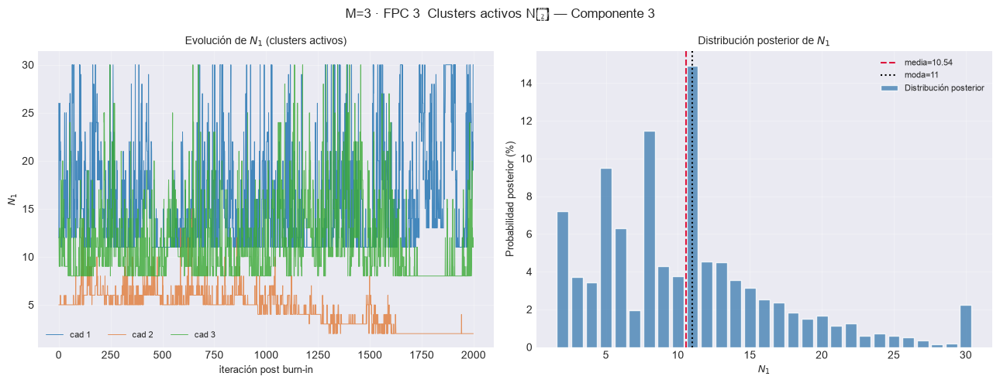

== M=4 ==============================================


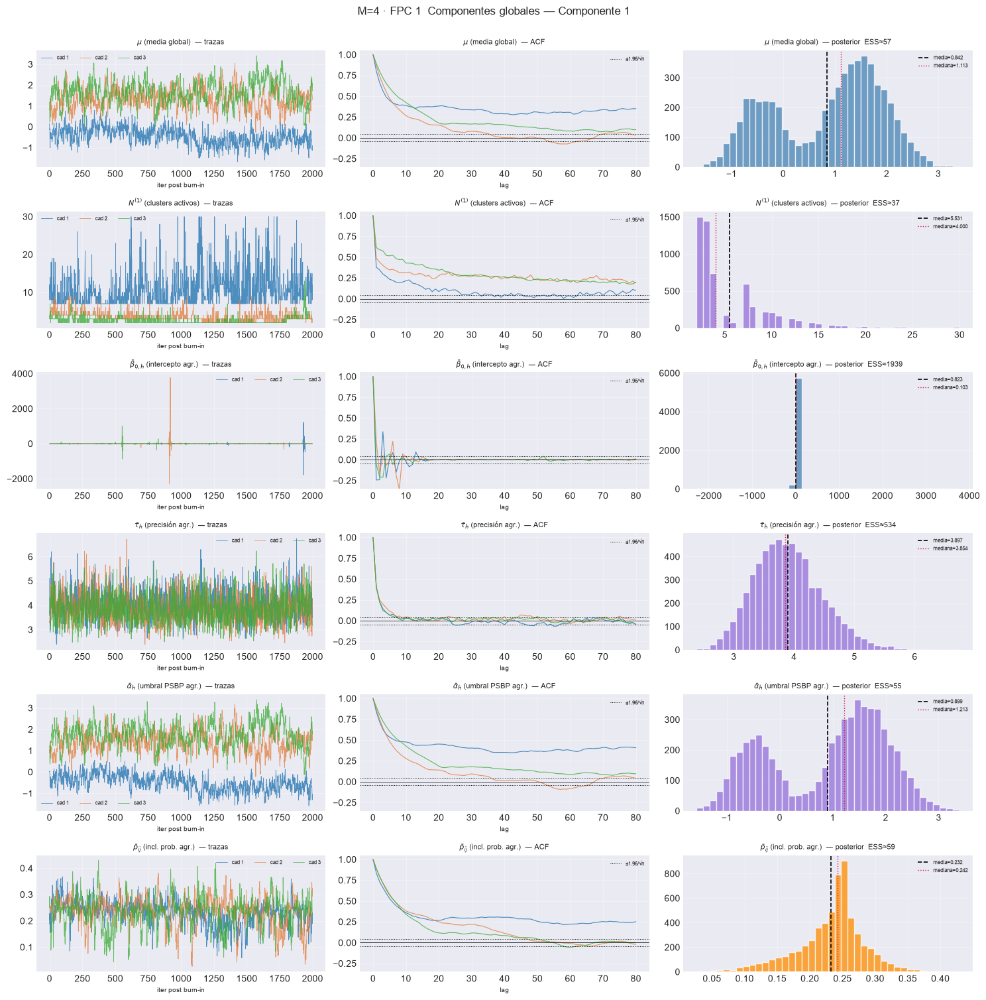

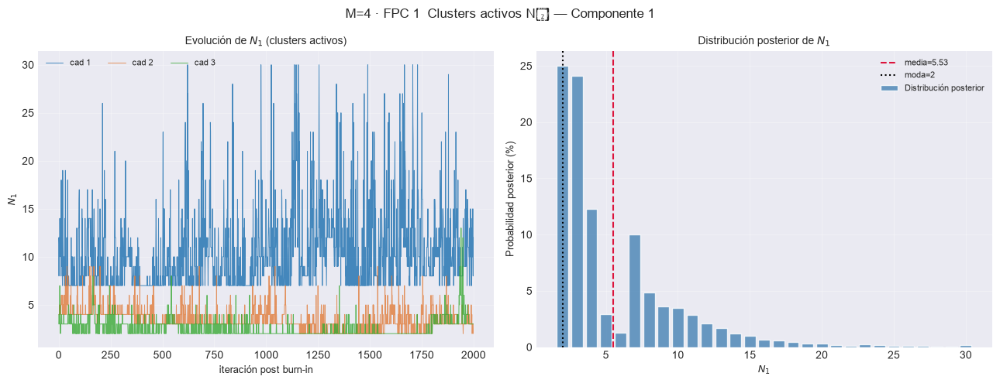

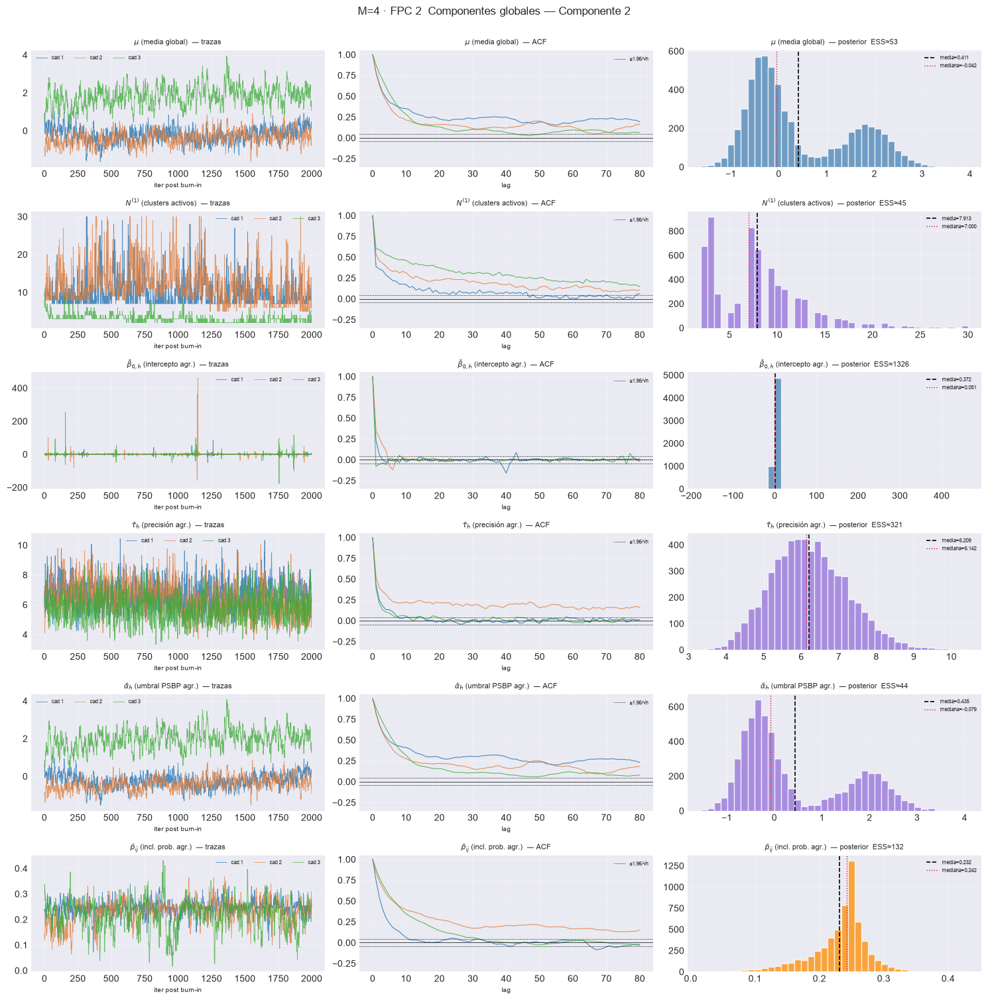

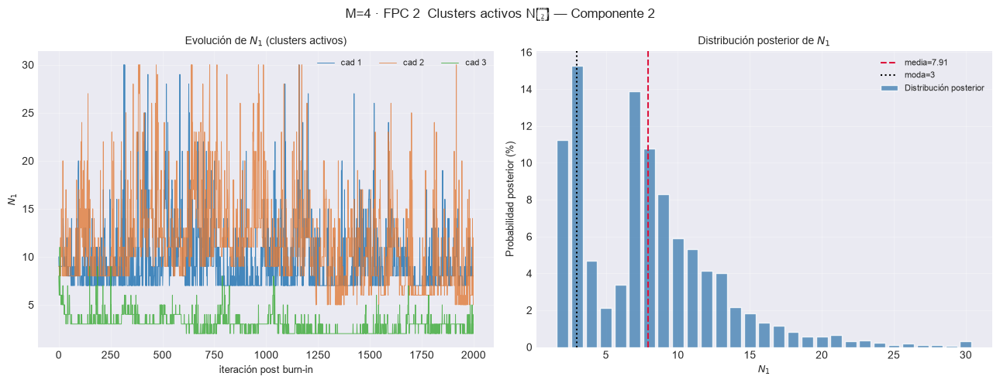

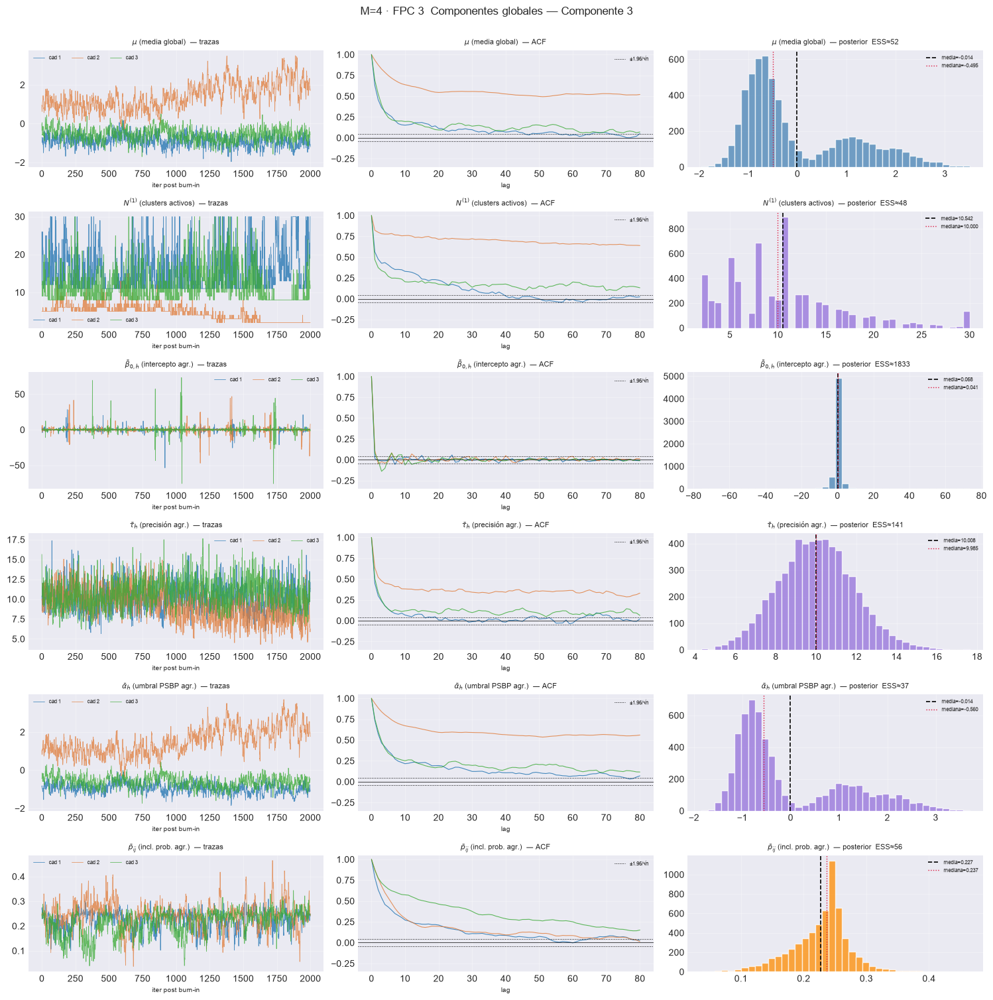

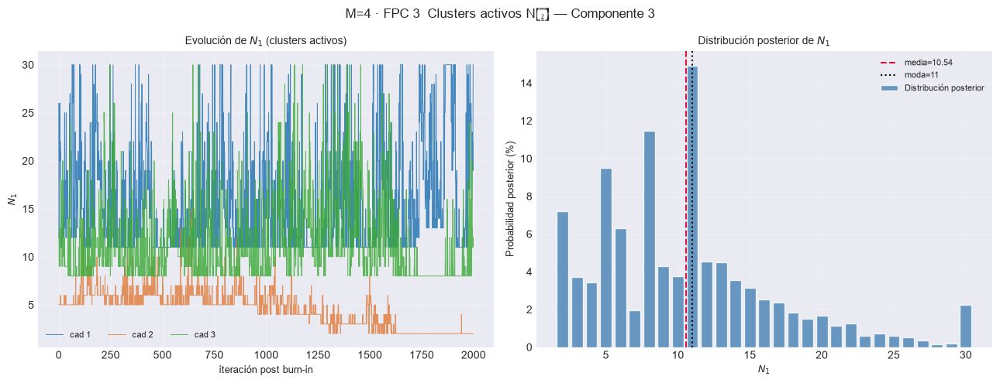

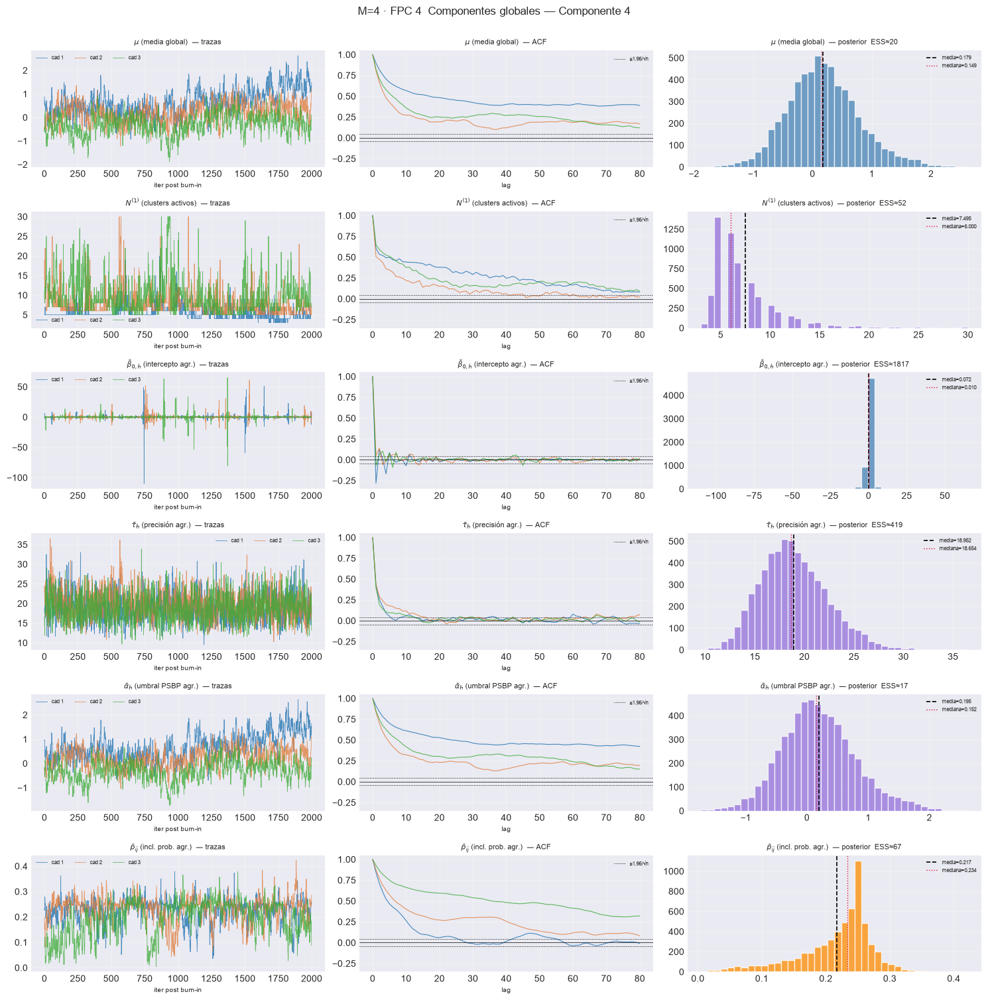

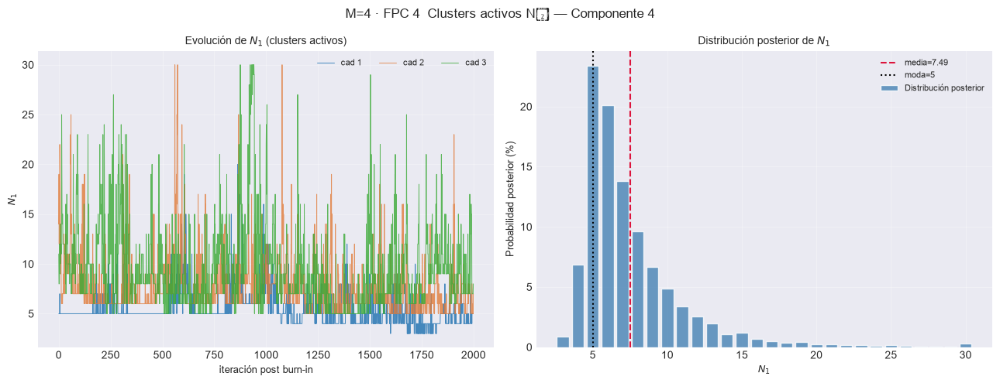

== M=5 ==============================================


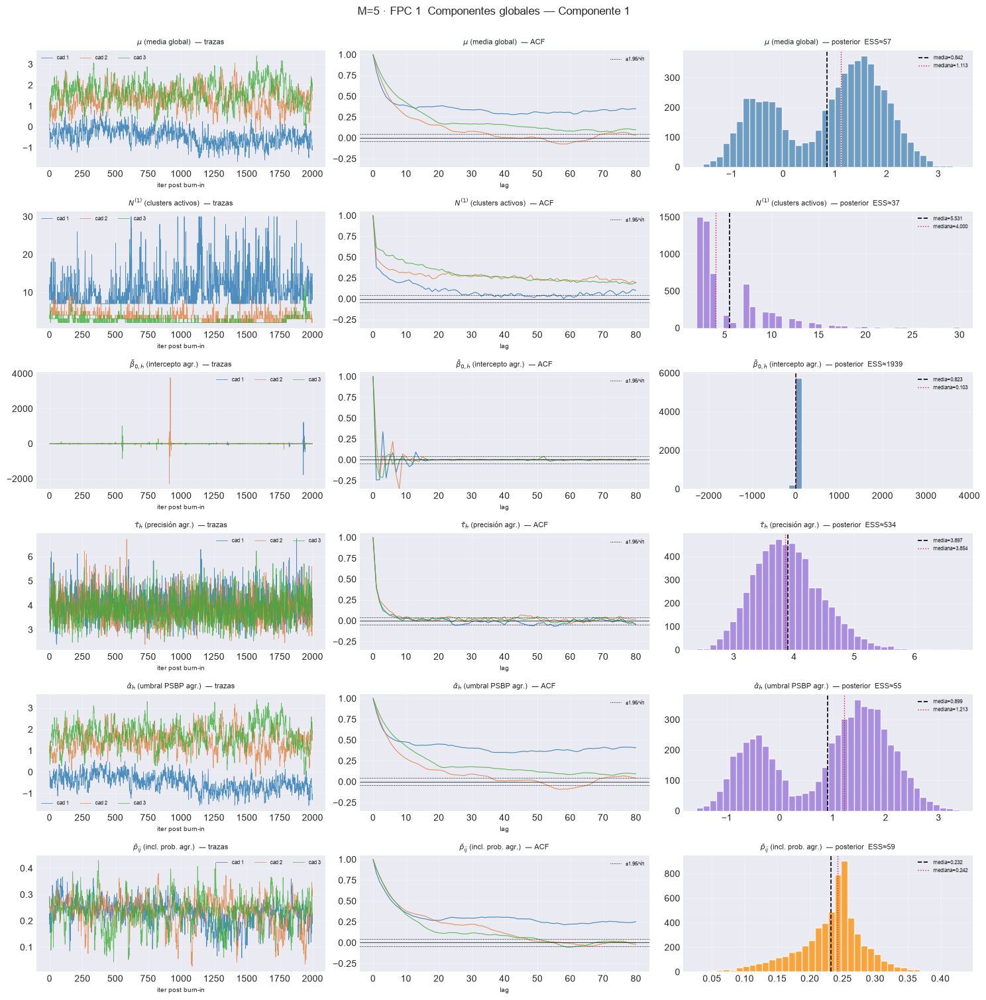

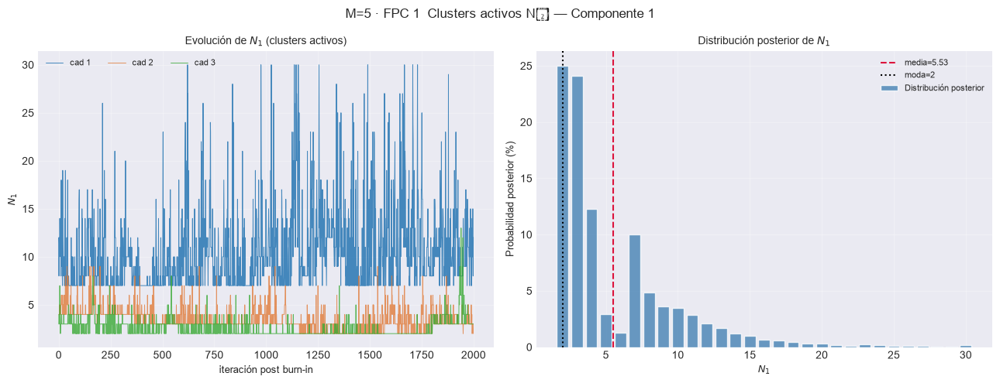

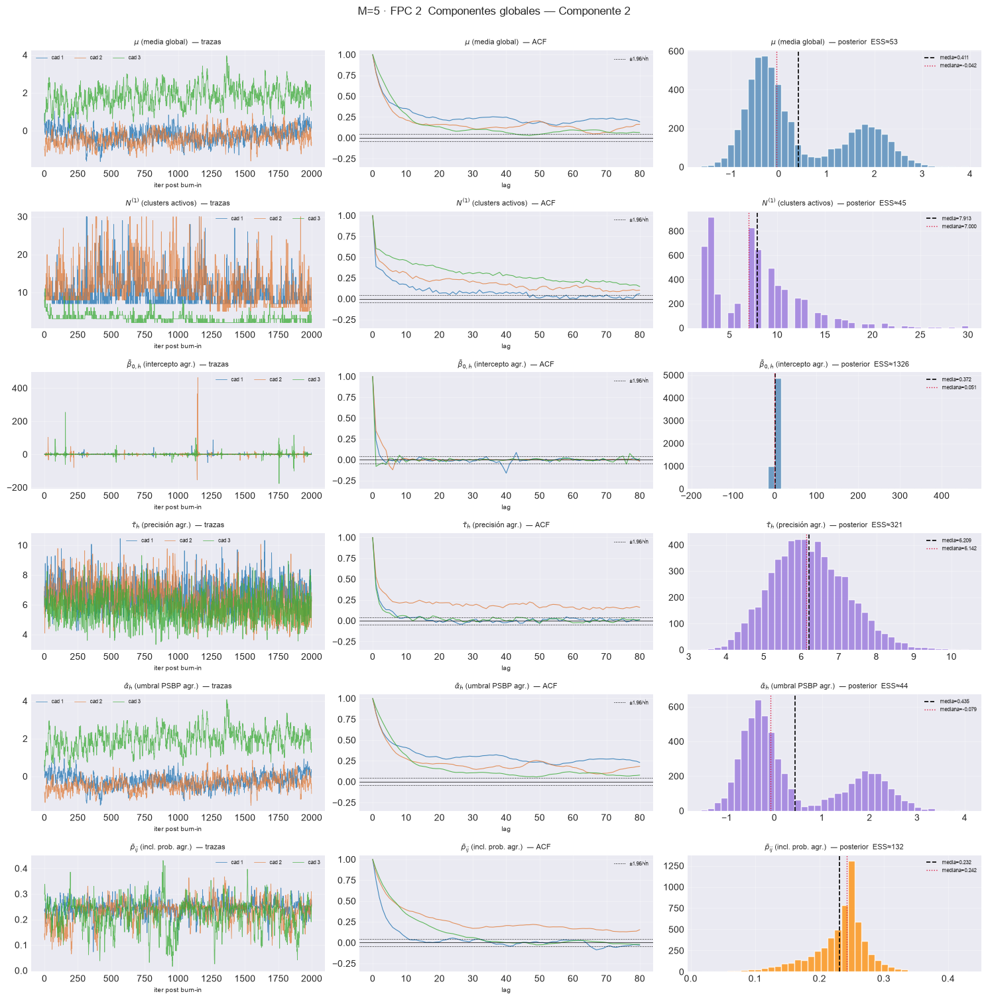

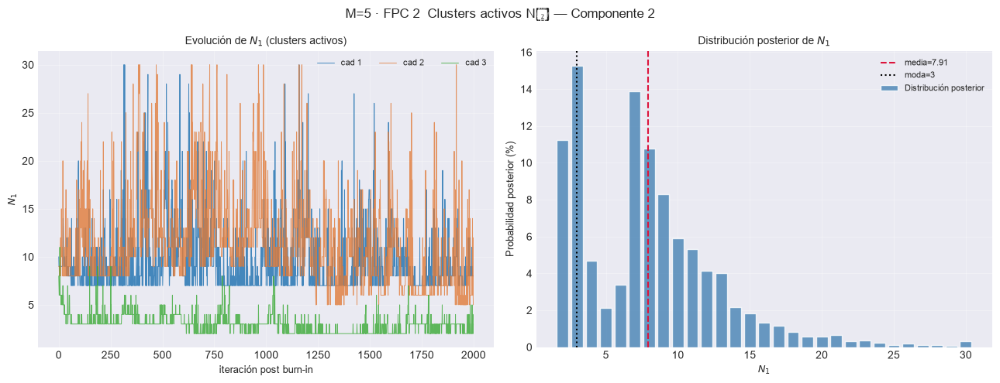

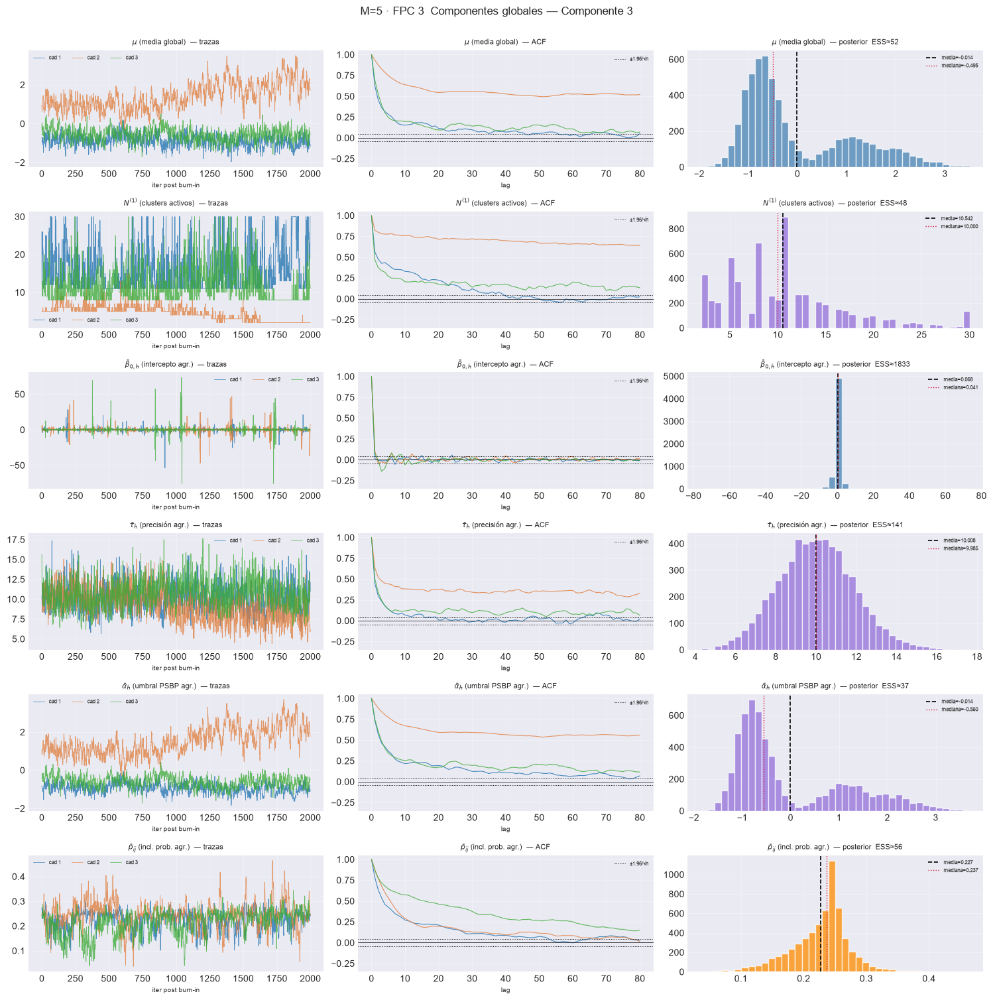

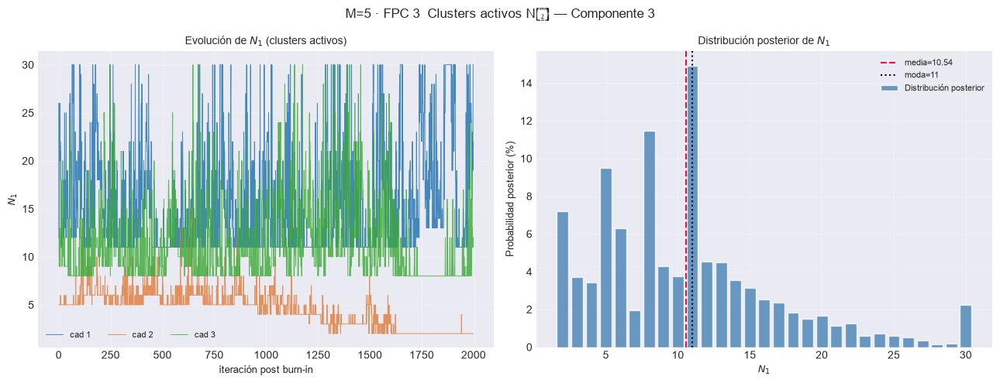

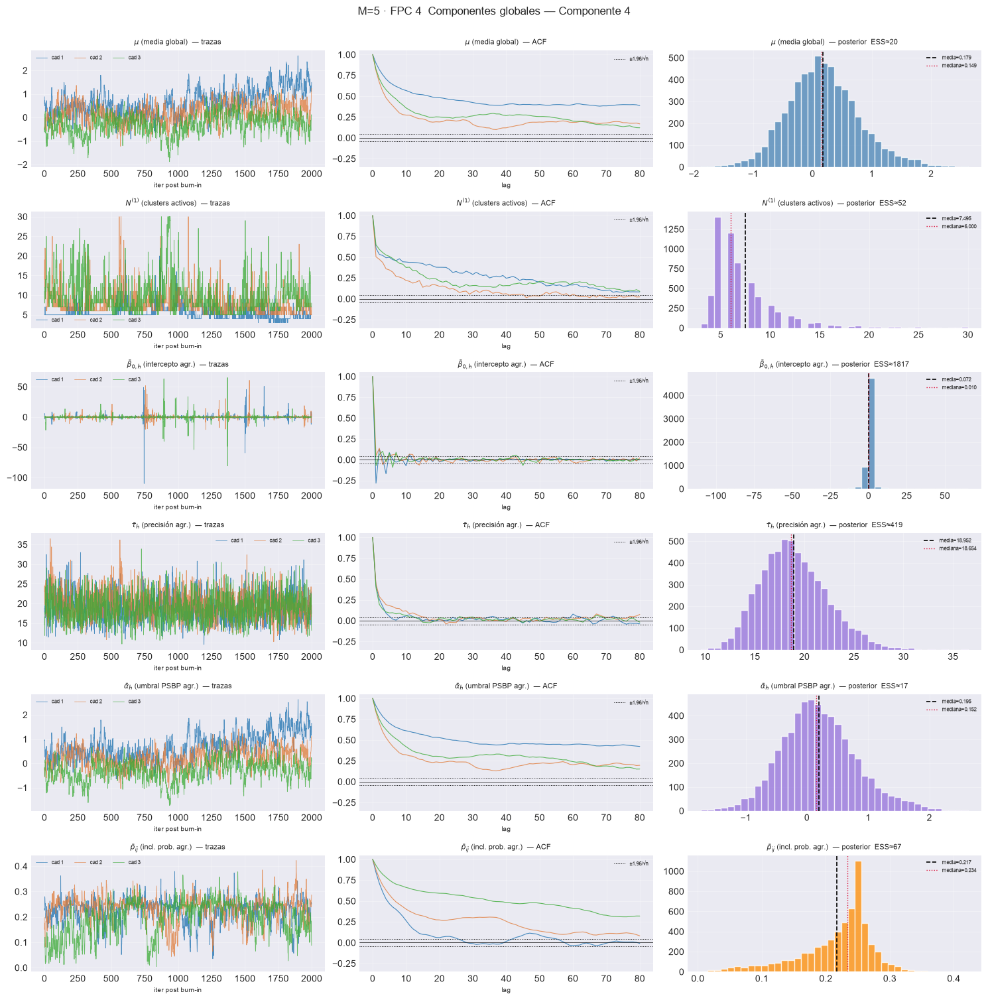

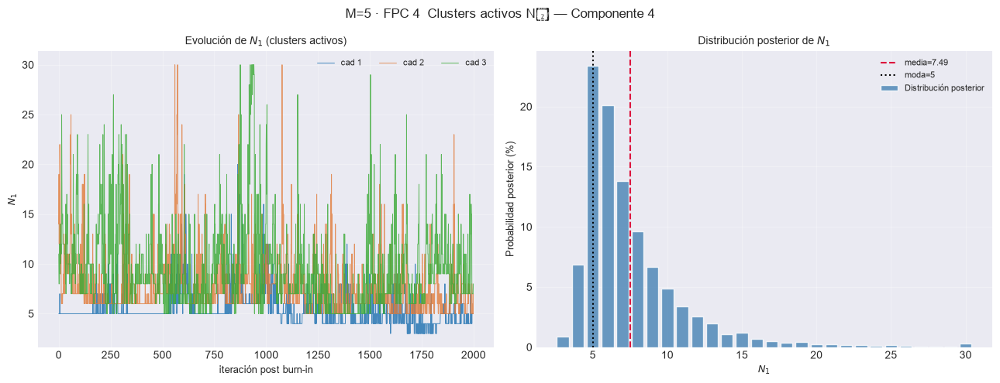

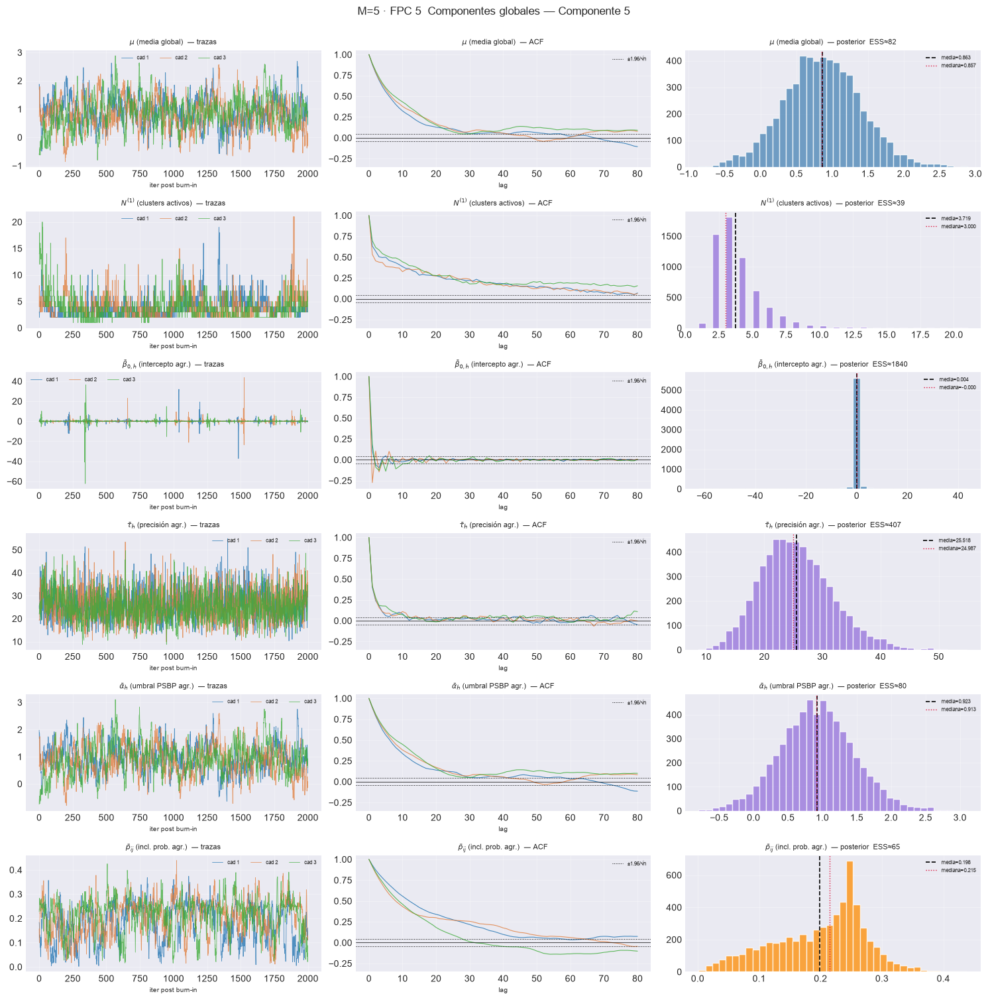

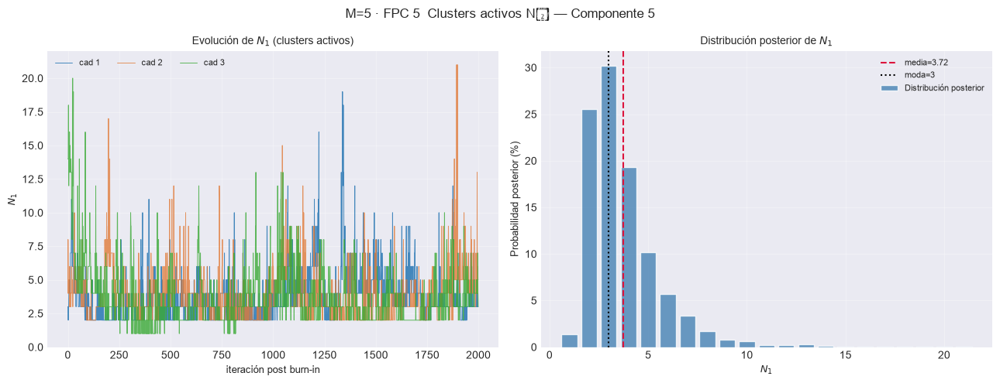

== M=6 ==============================================


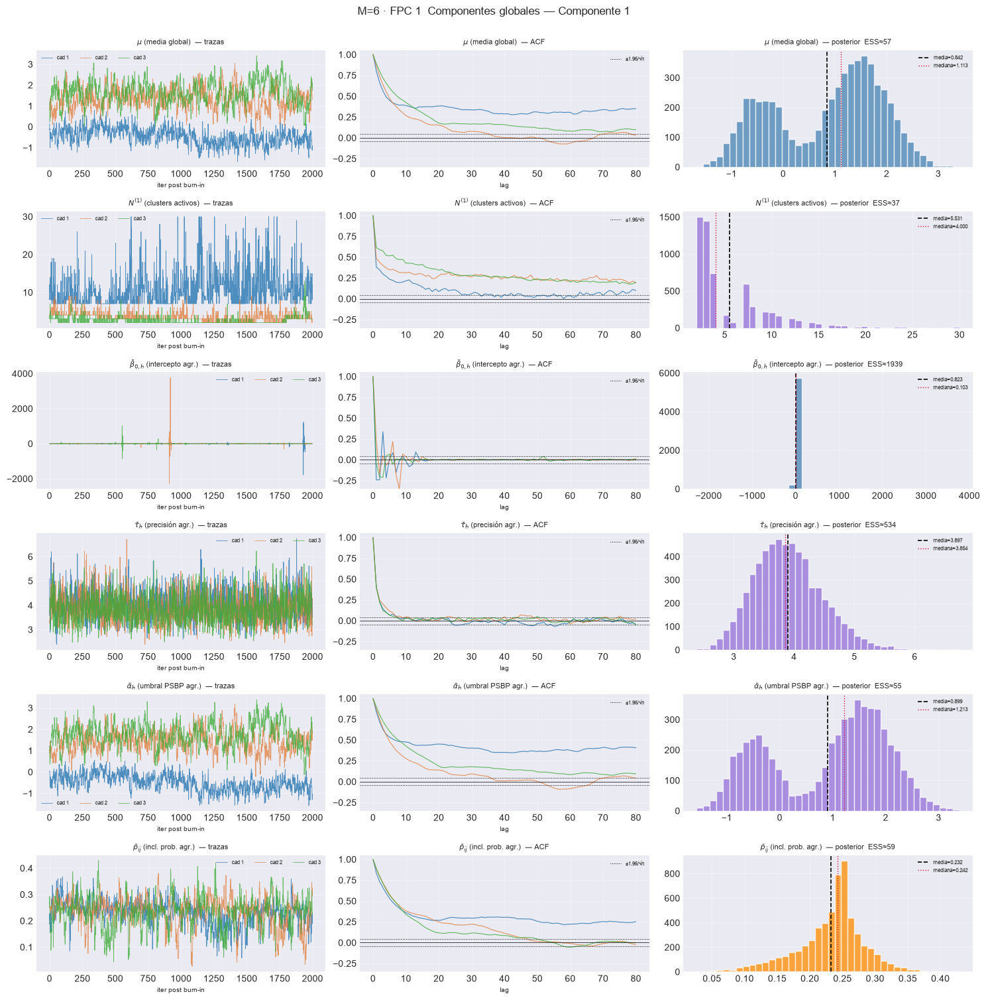

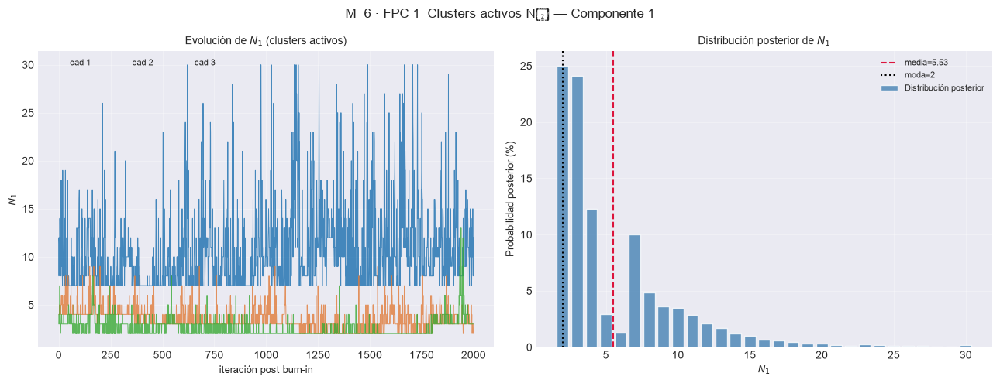

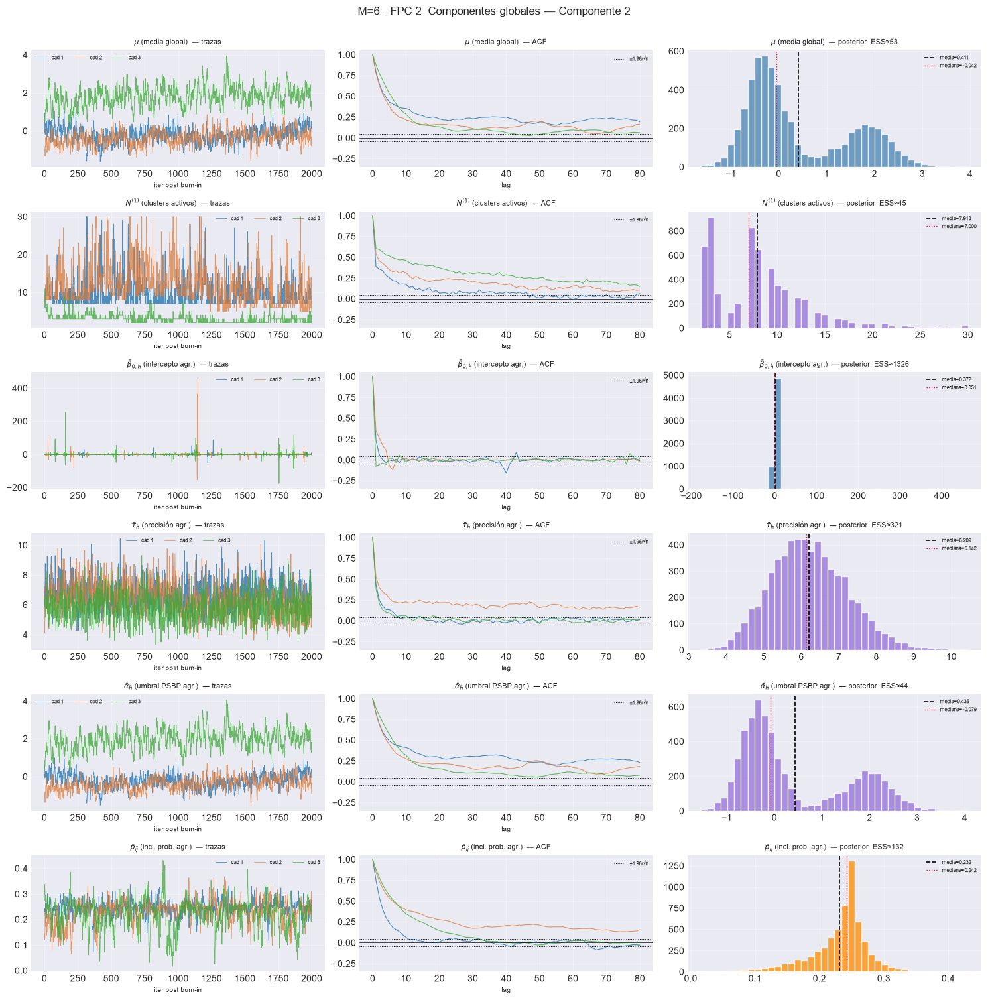

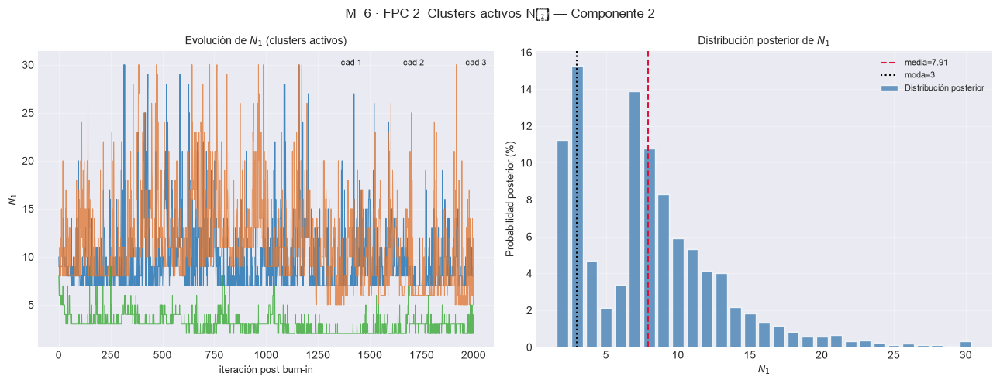

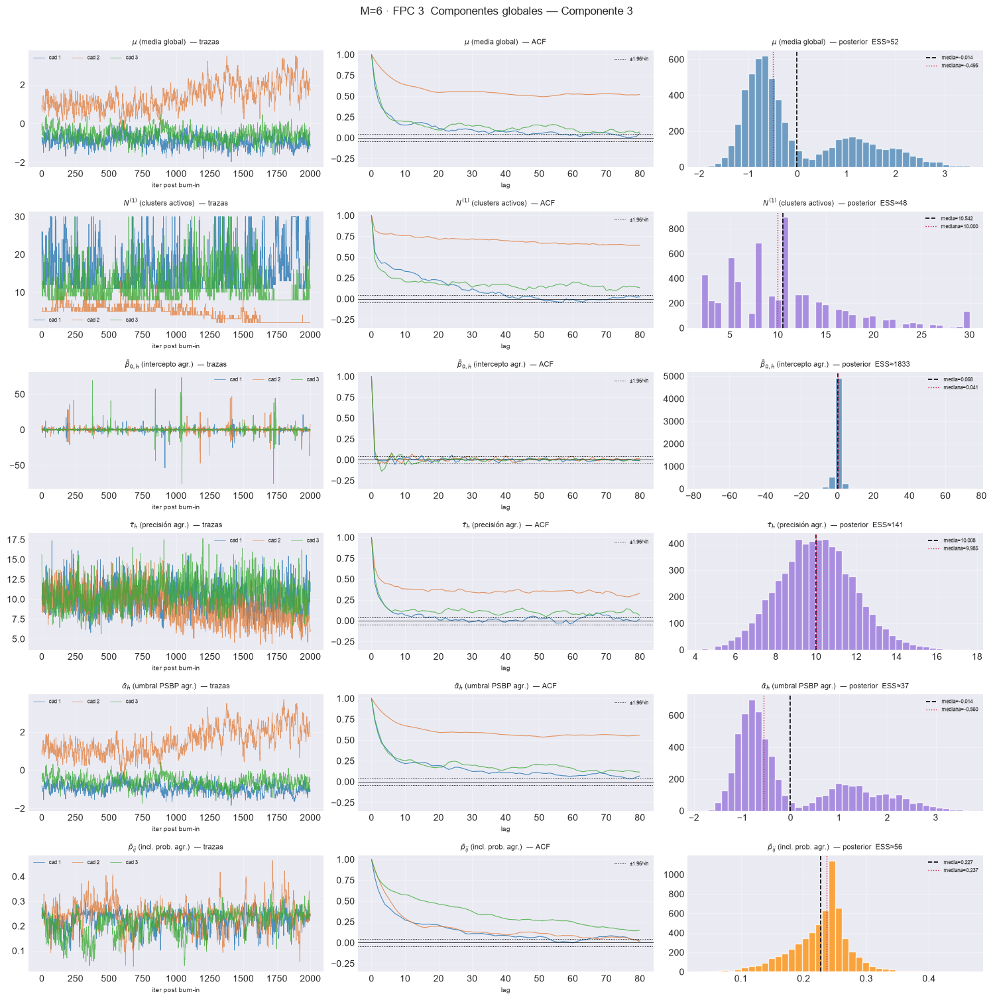

...

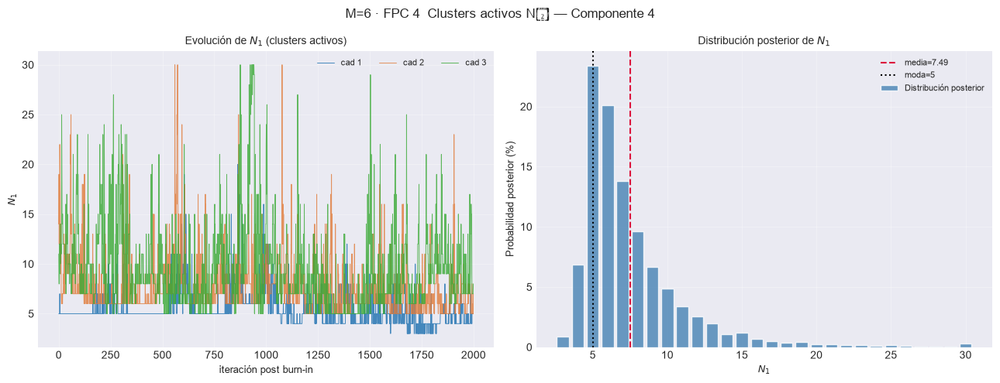

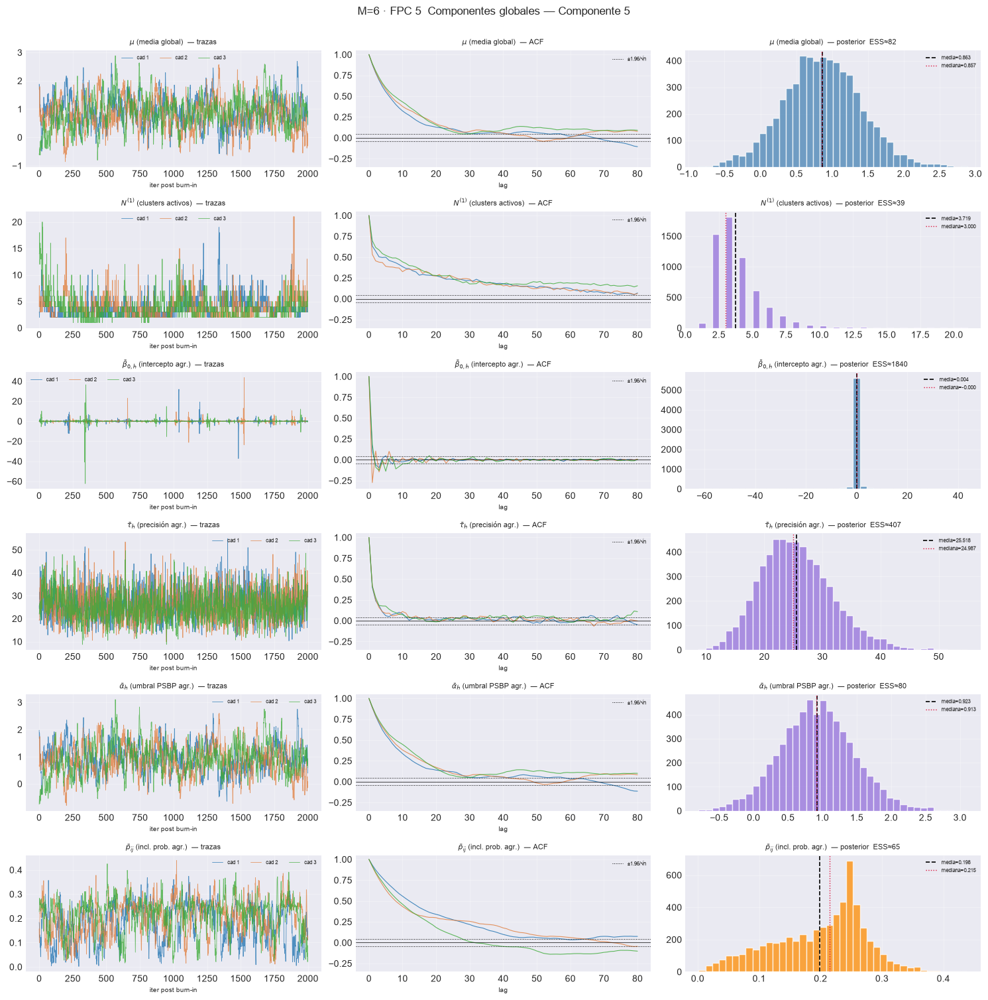

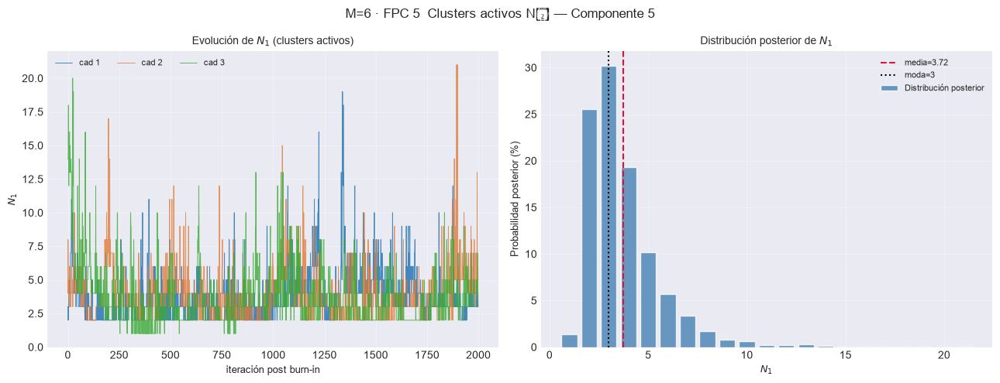

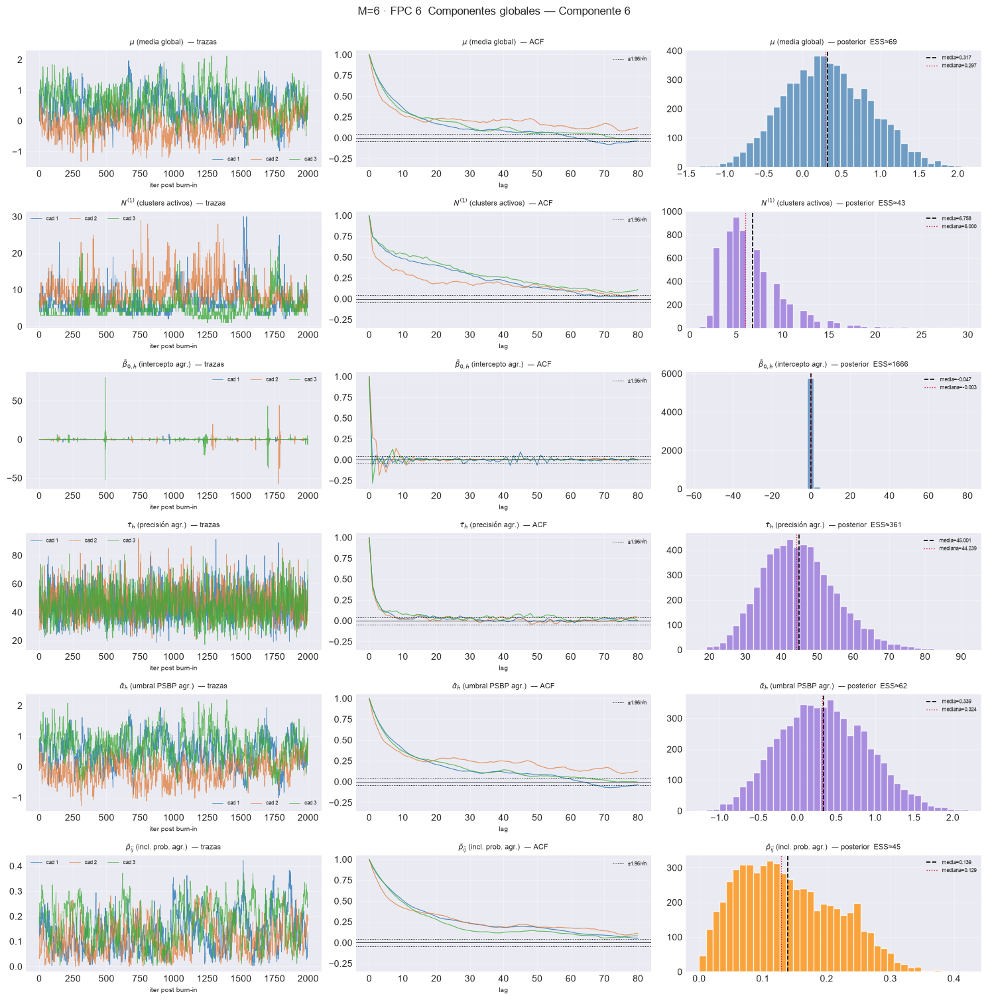

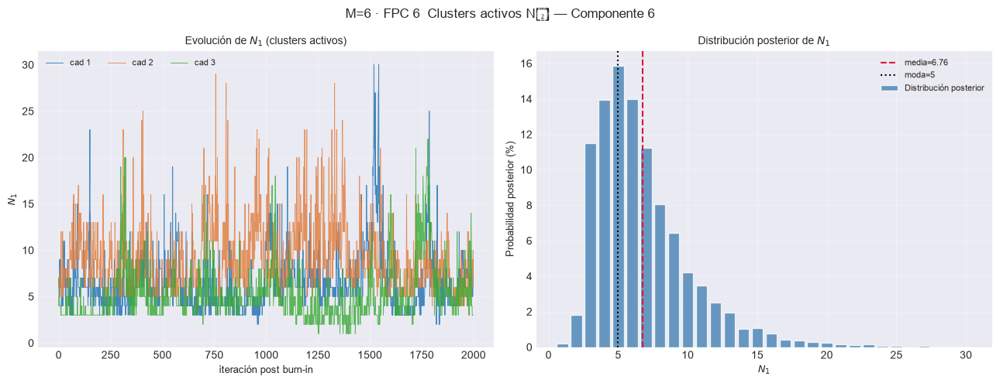

== M=7 ==============================================


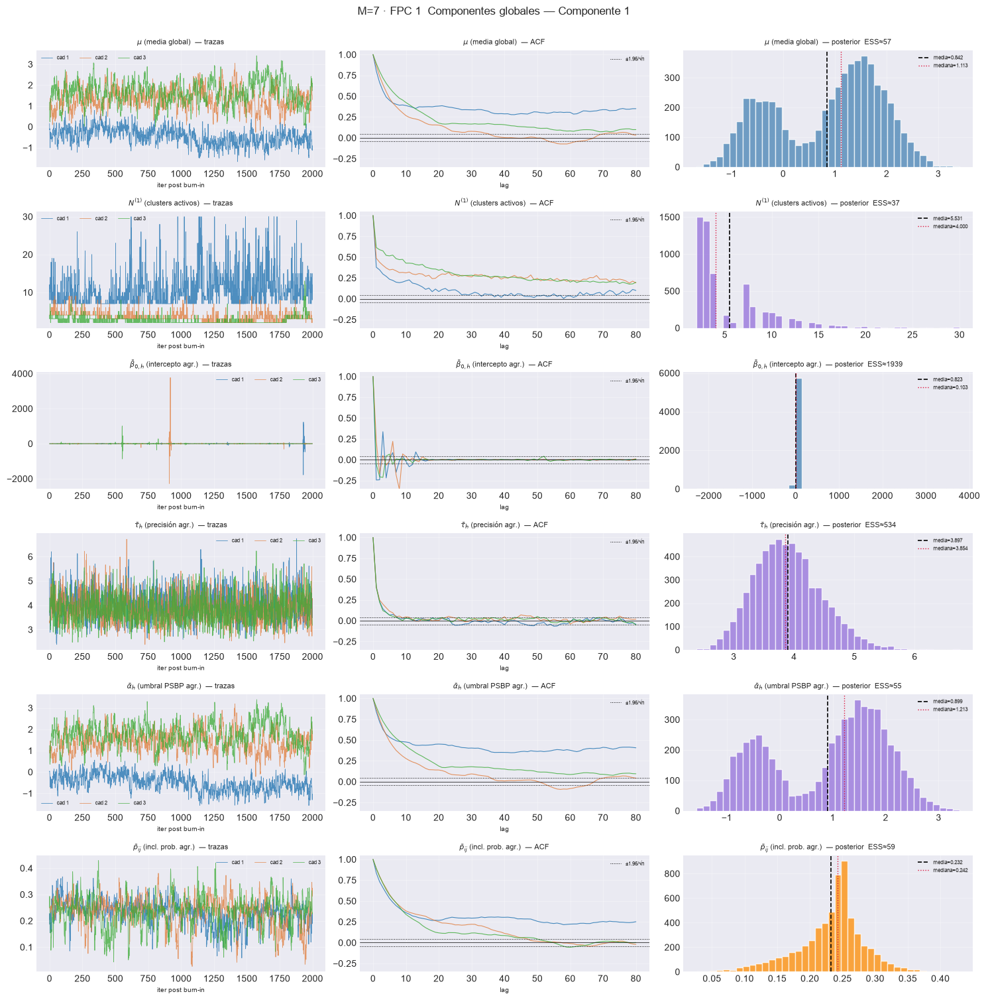

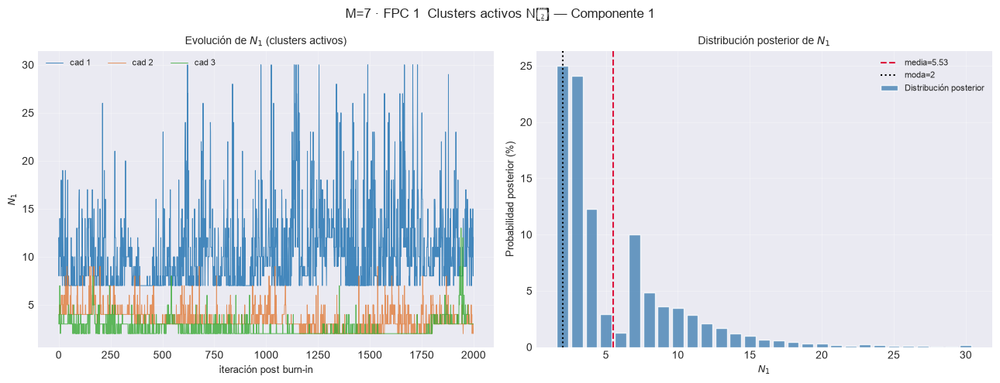

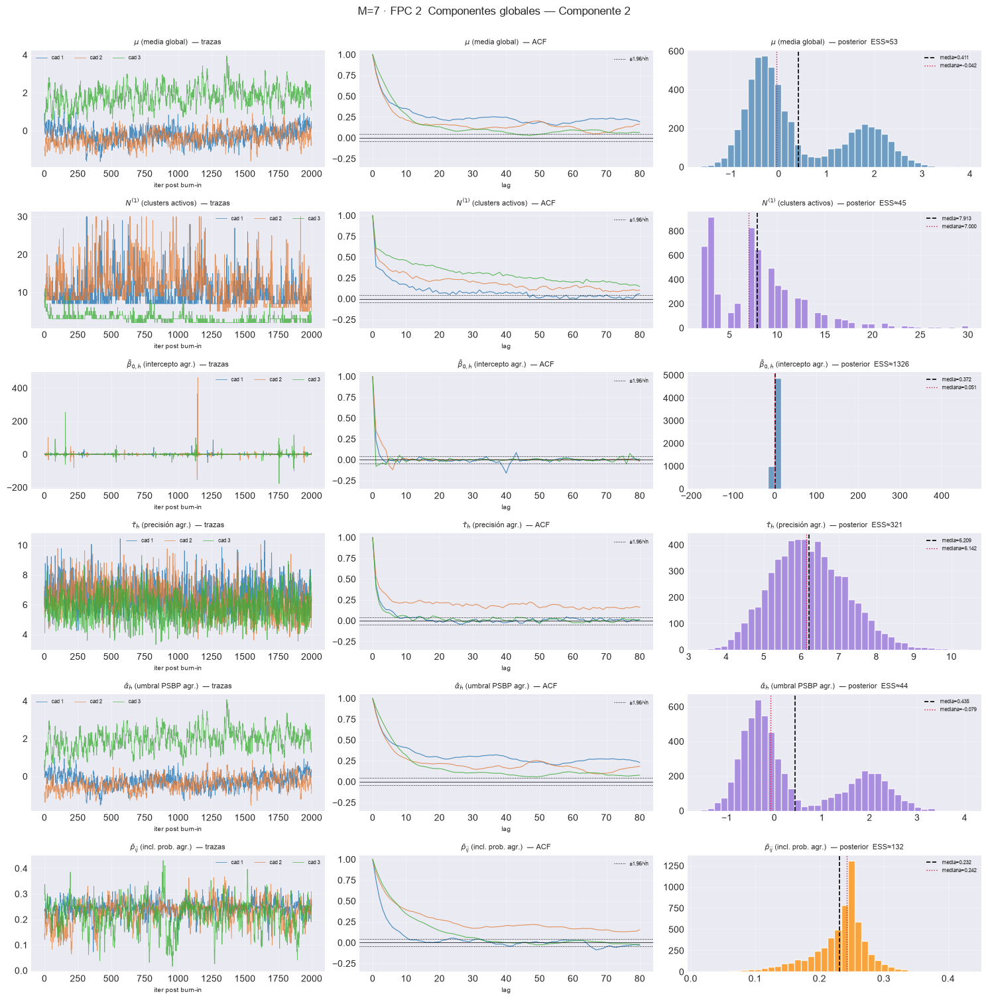

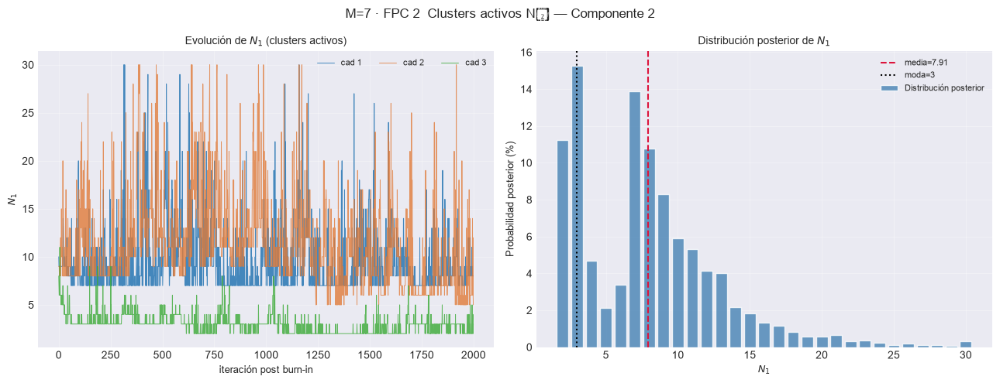

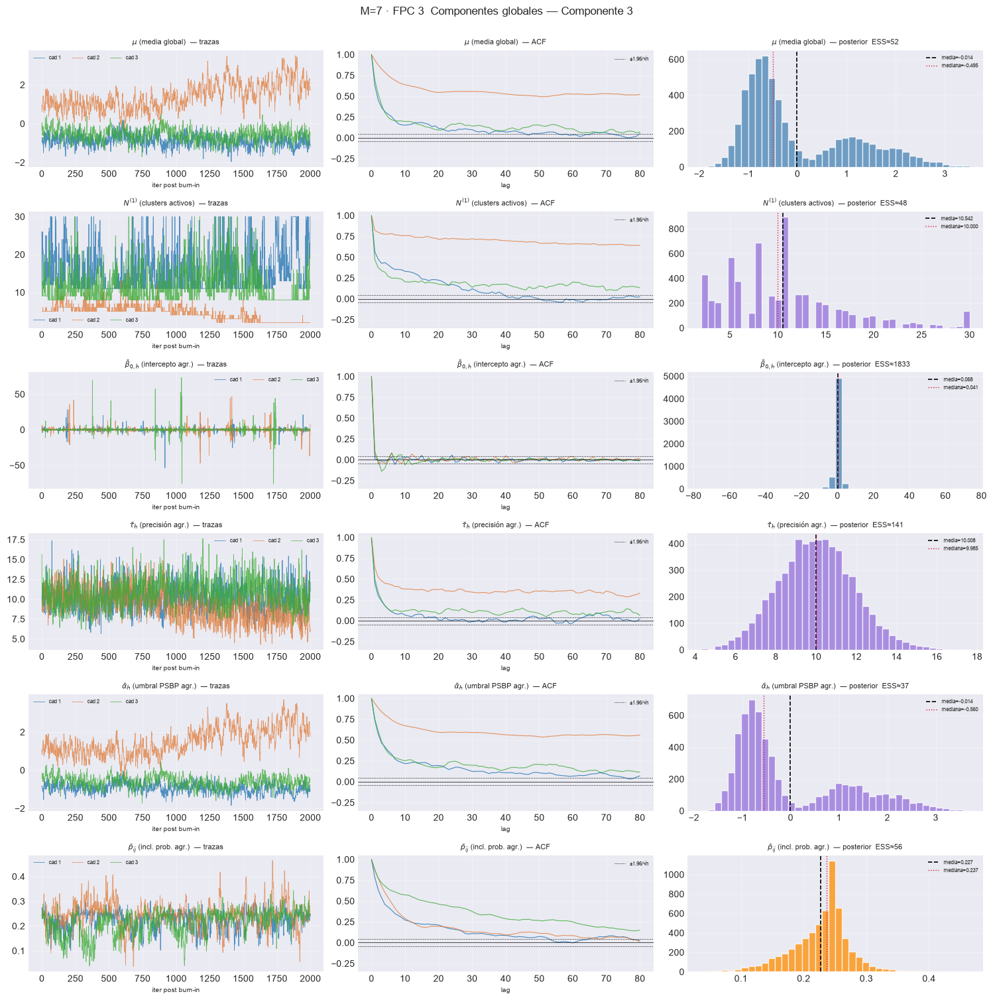

...

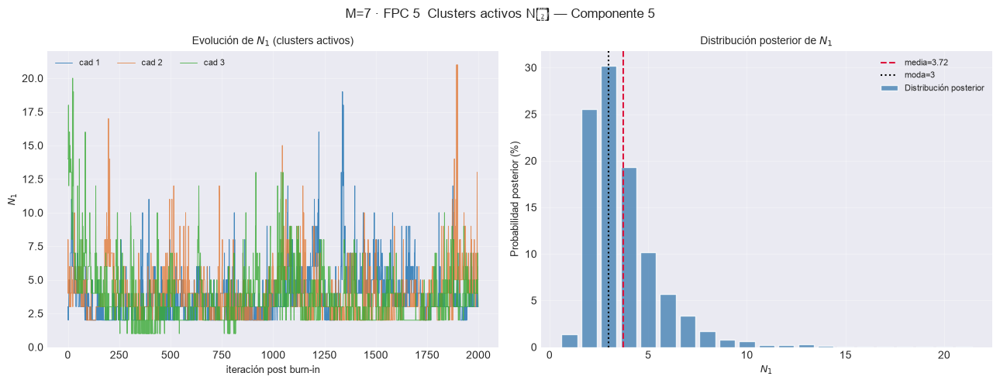

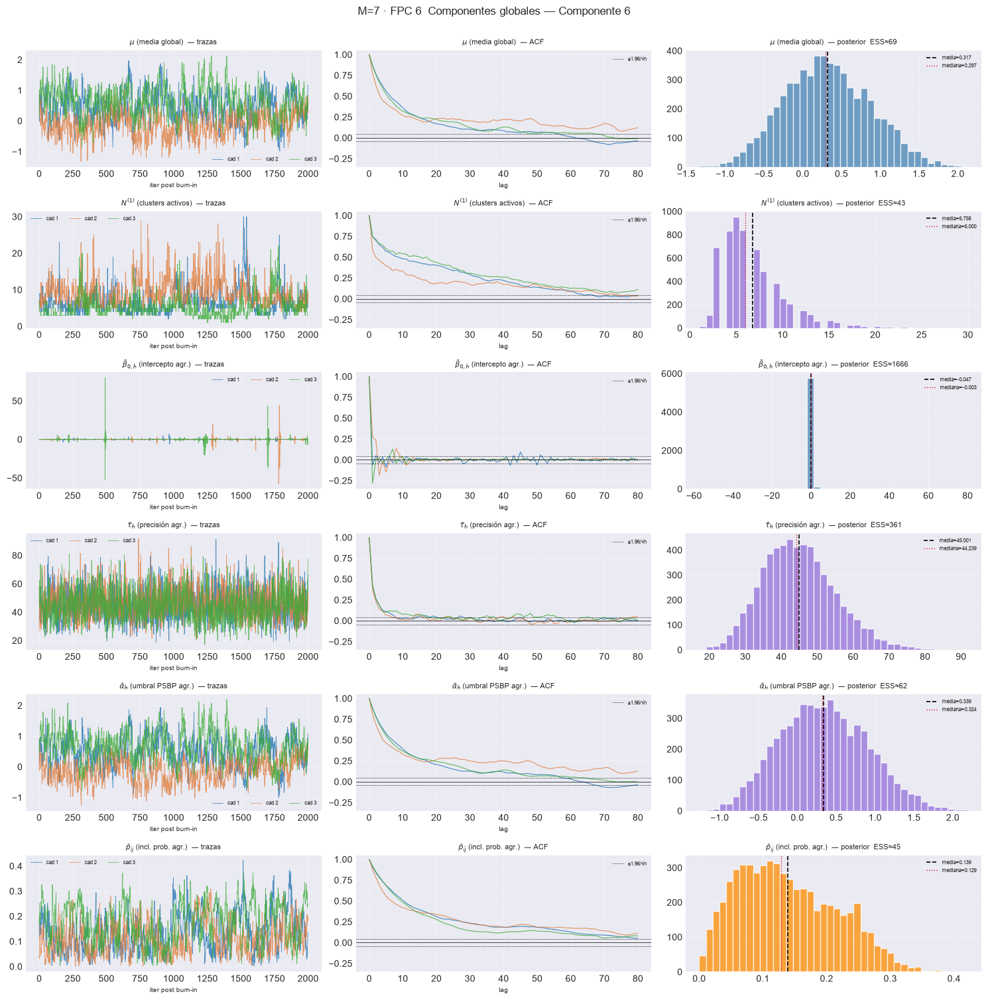

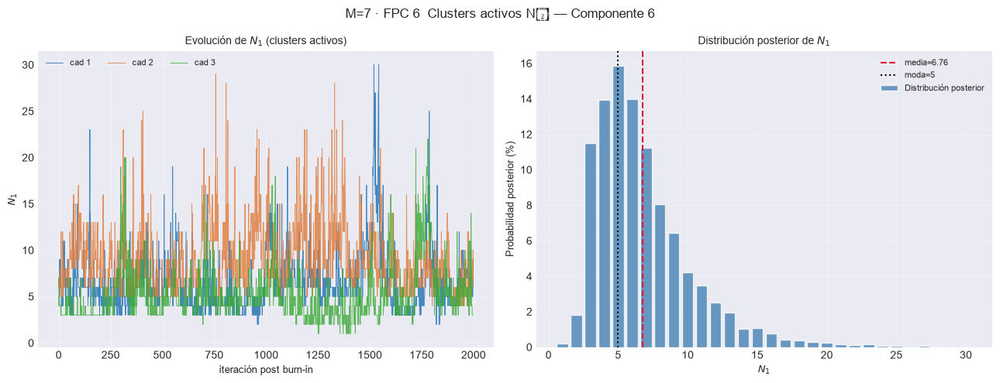

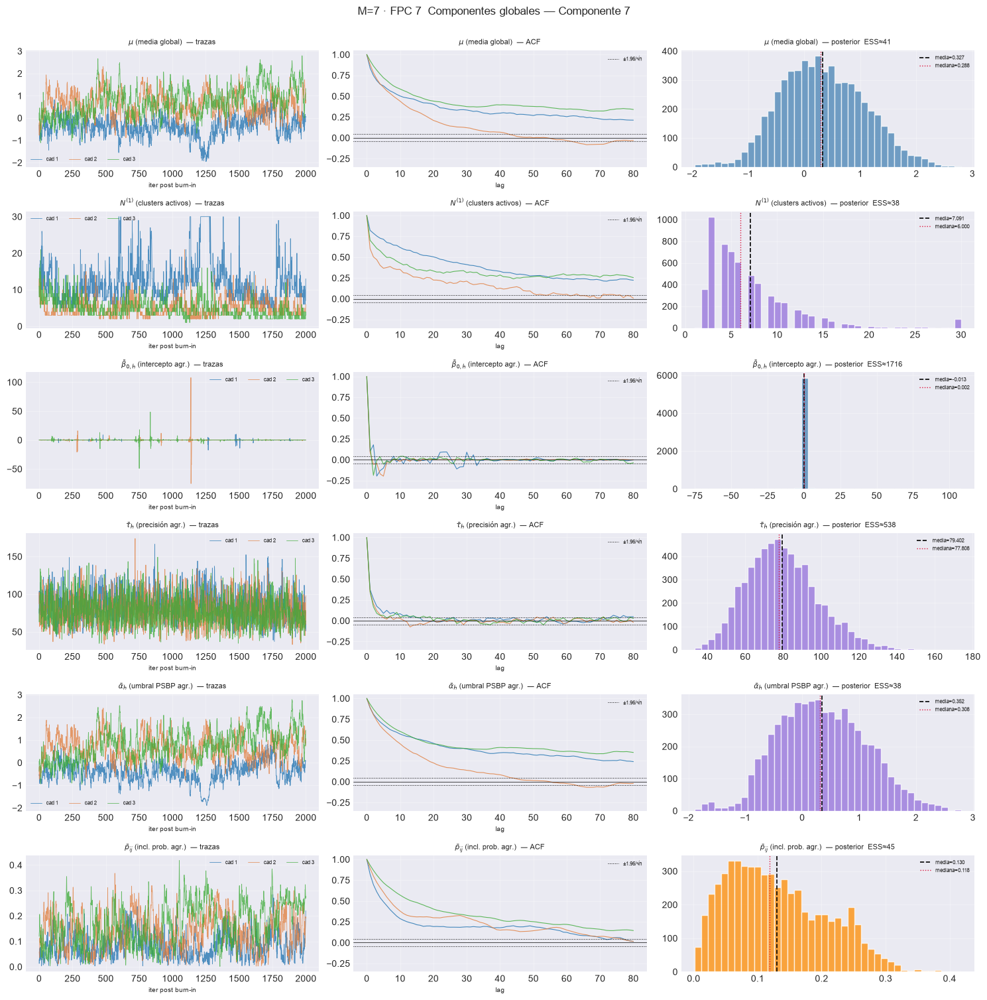

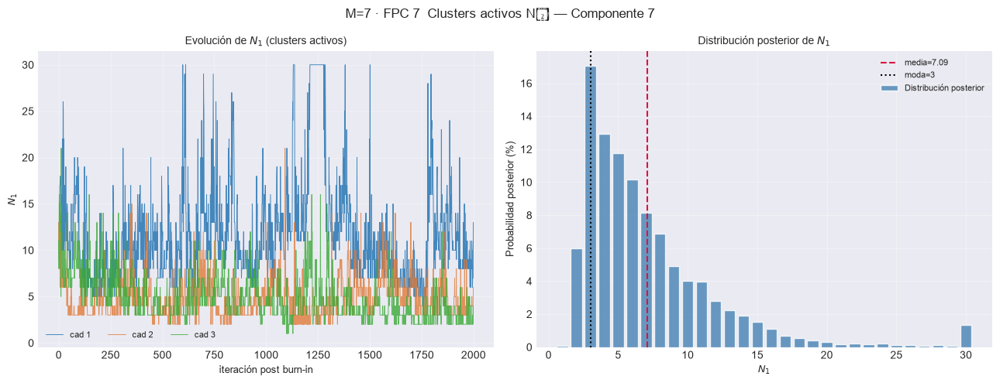

== M=8 ==============================================


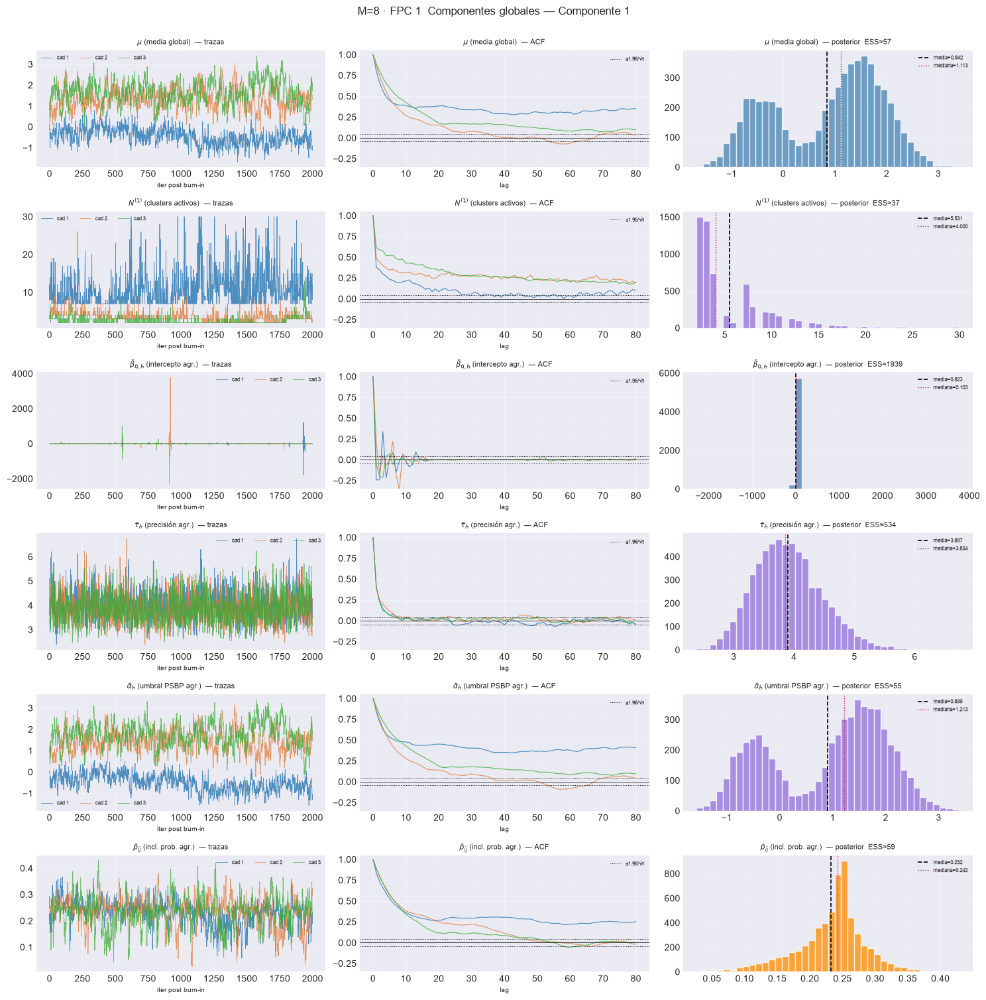

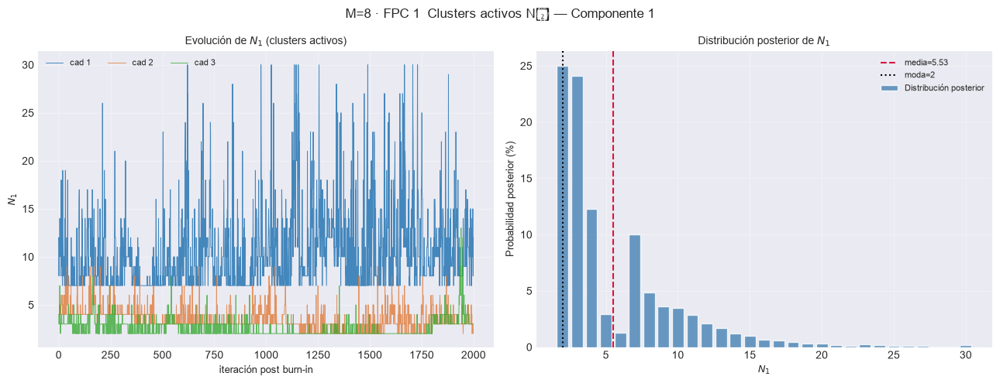

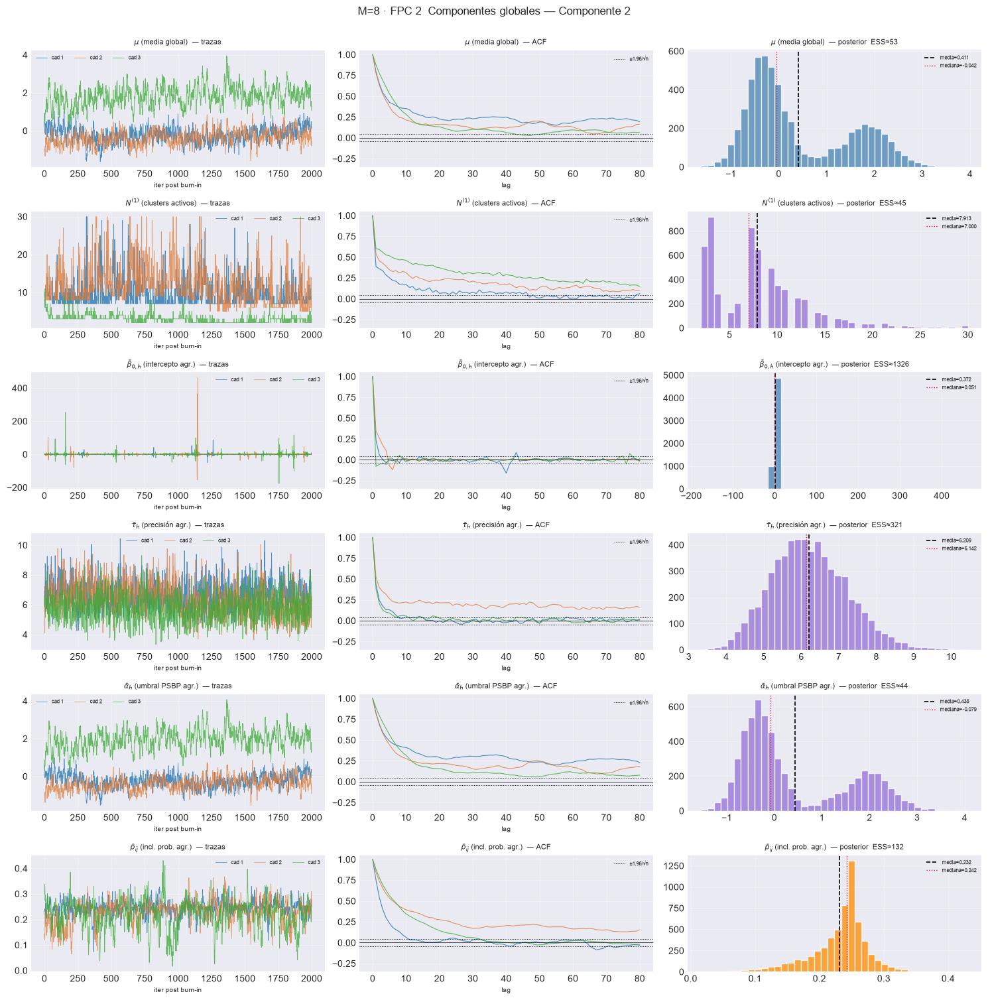

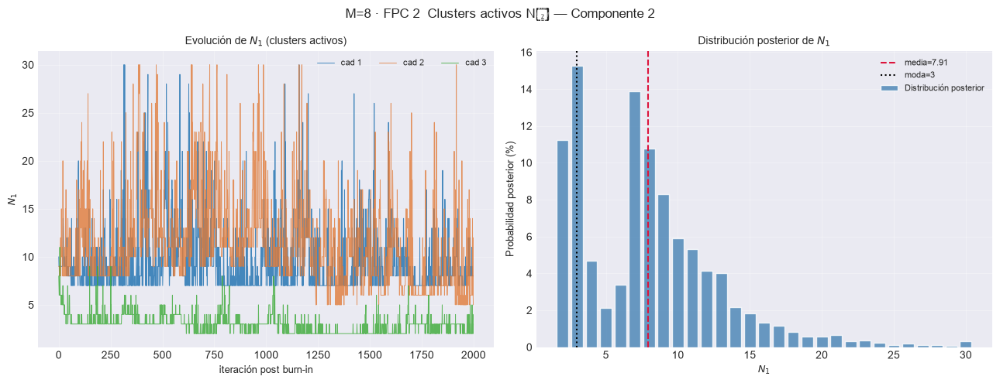

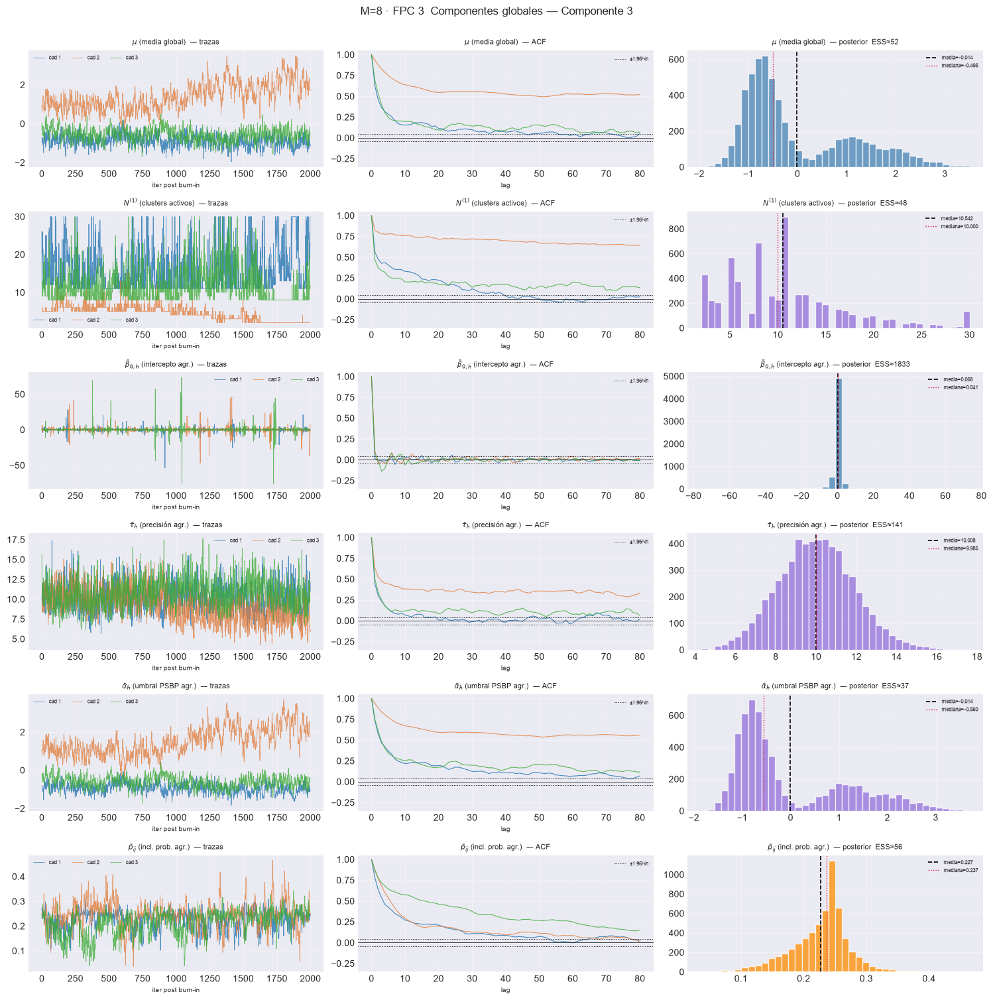

...

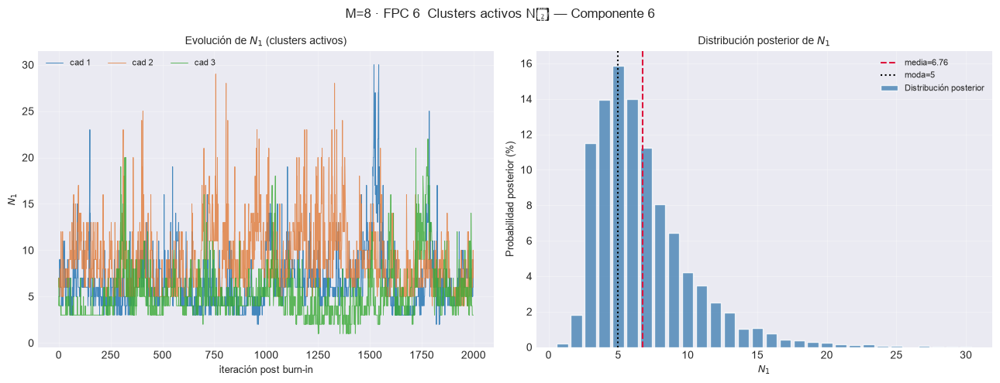

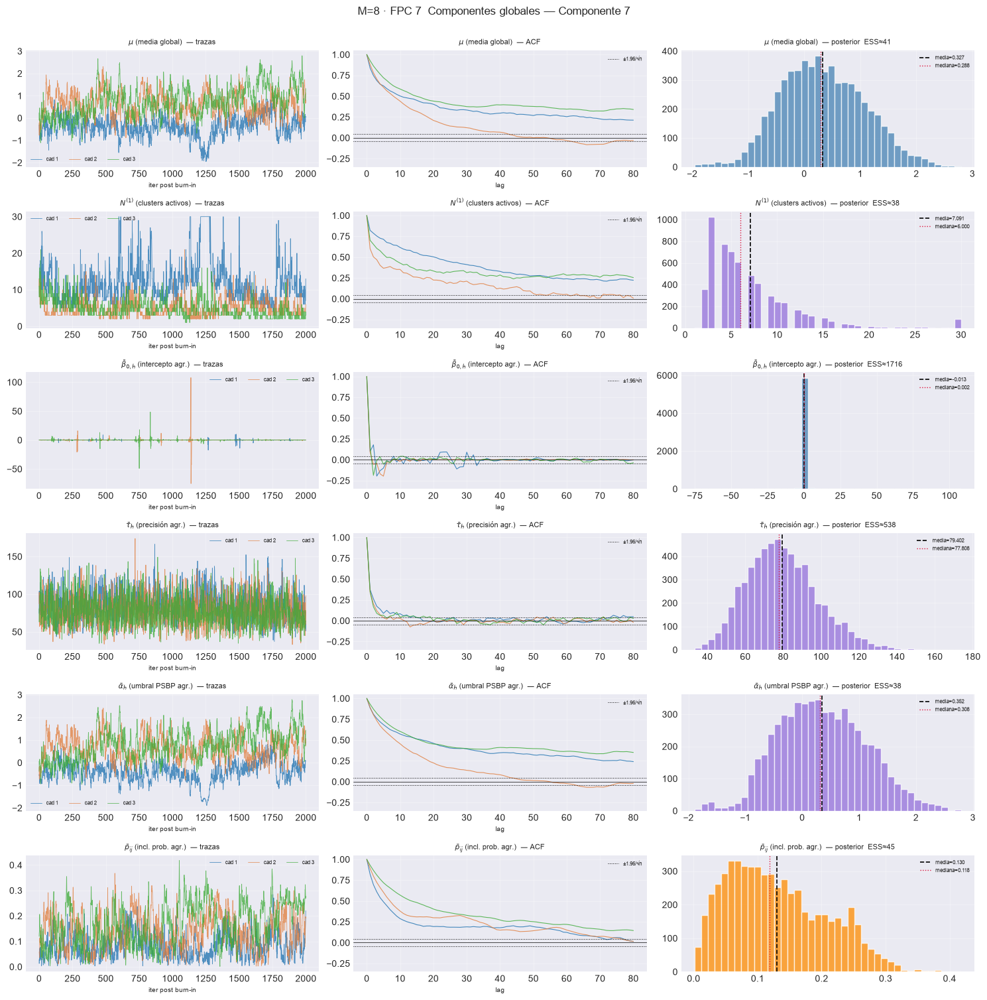

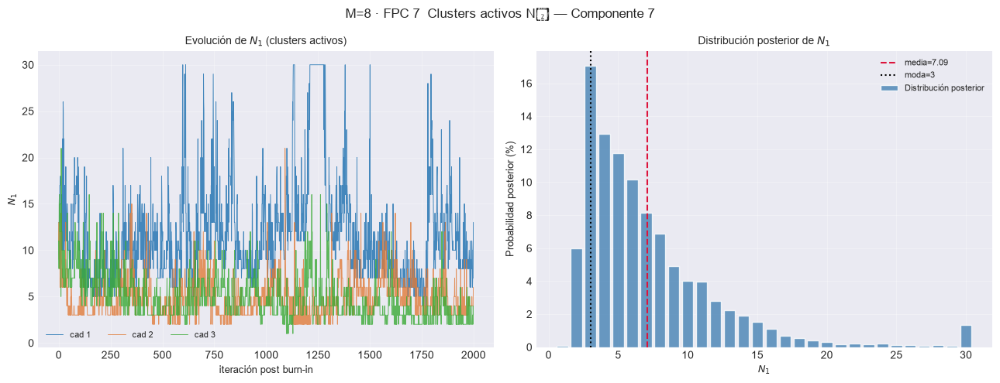

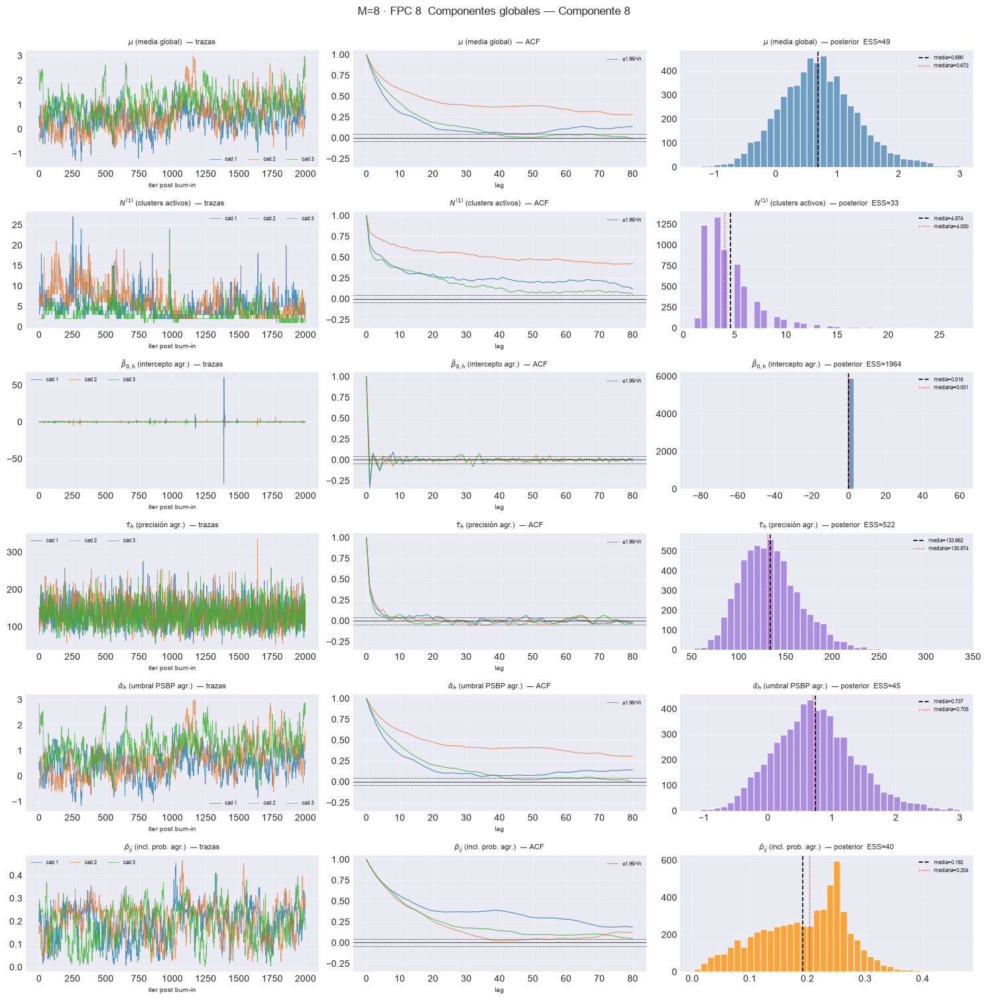

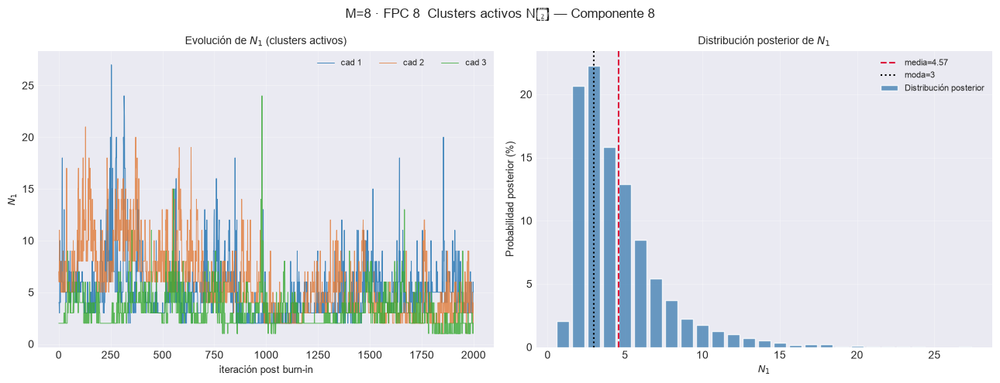

== M=9 ==============================================


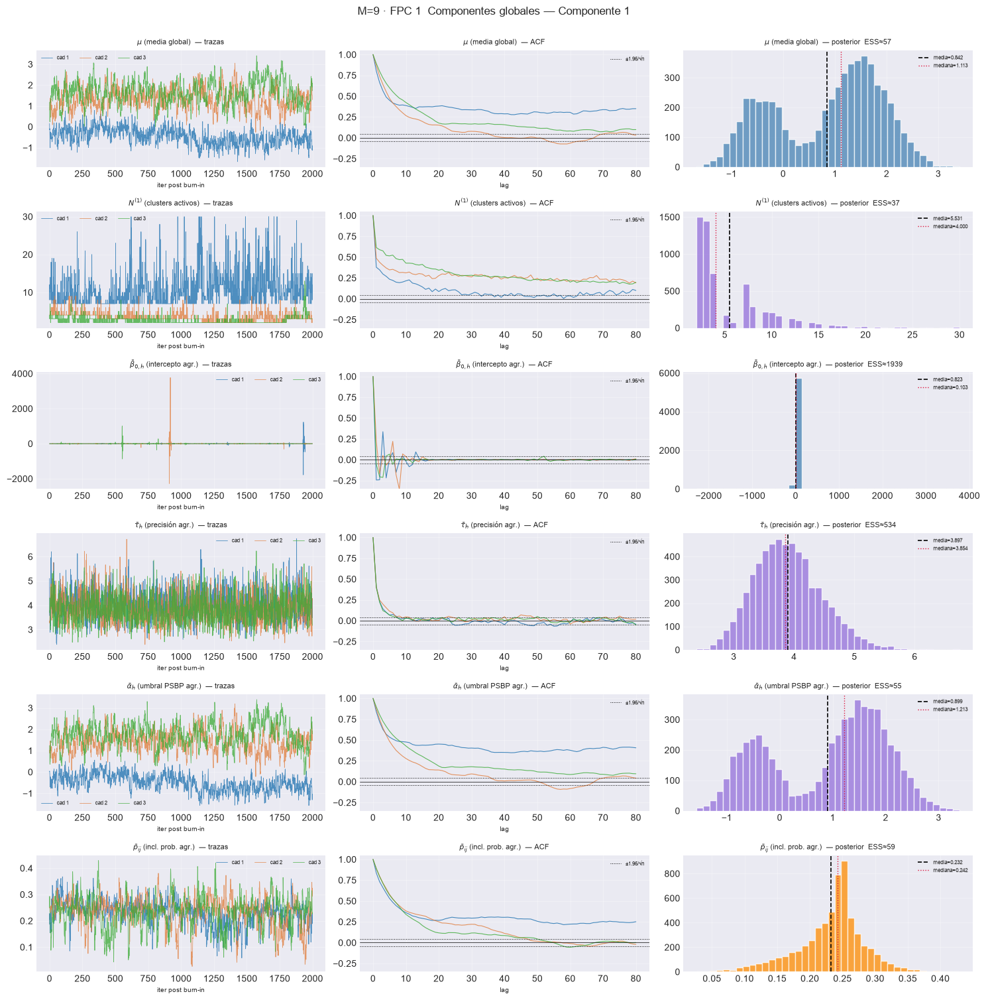

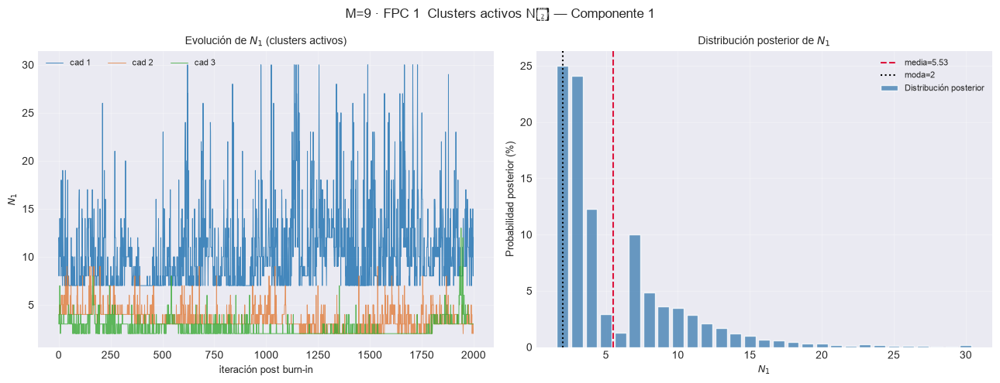

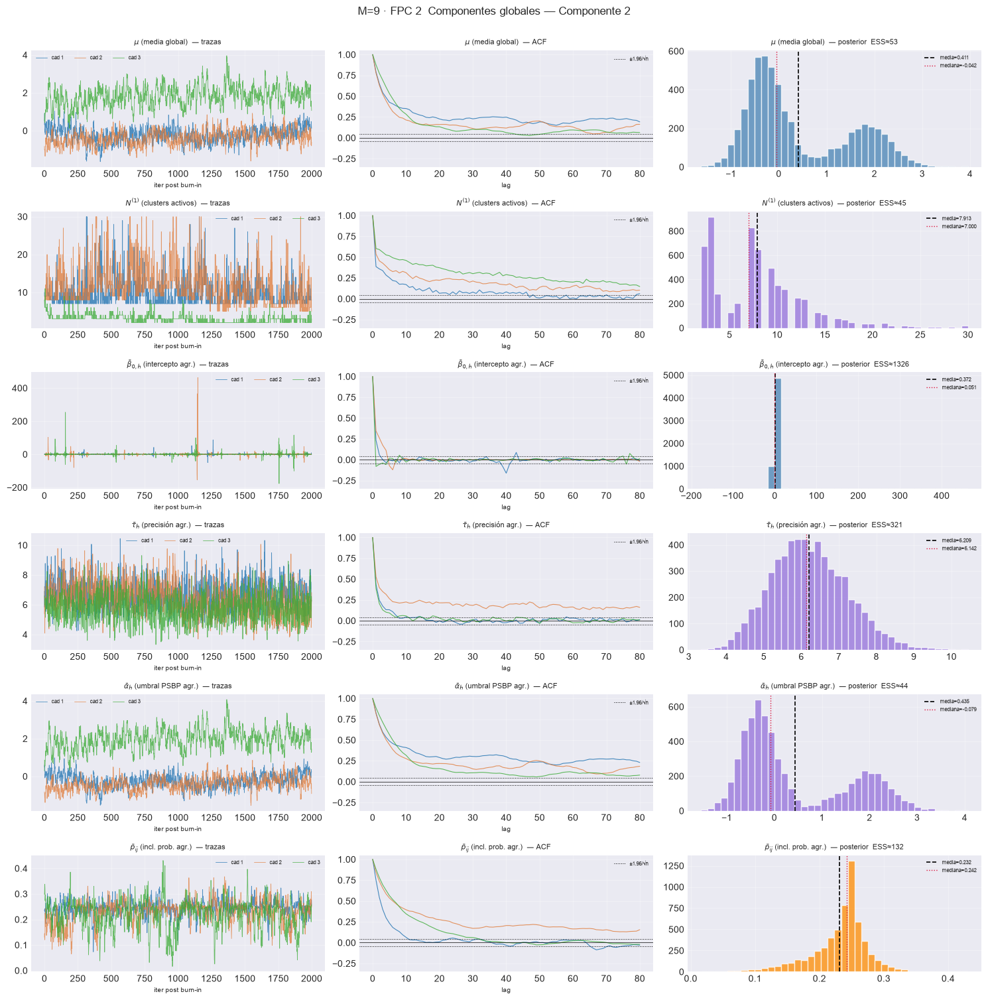

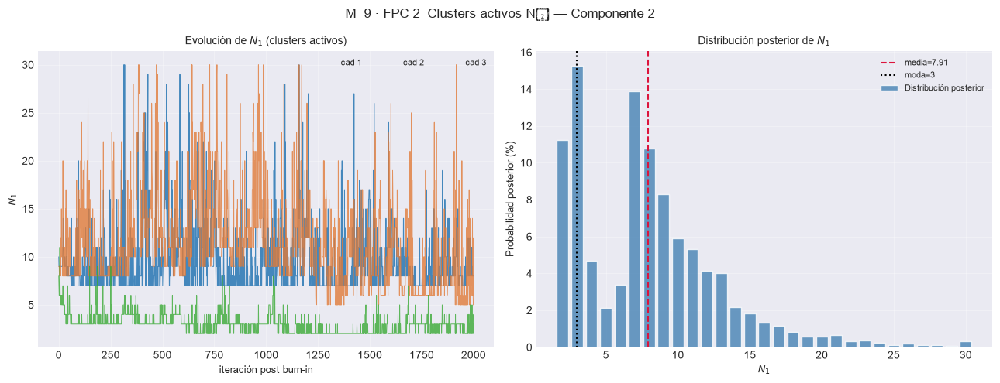

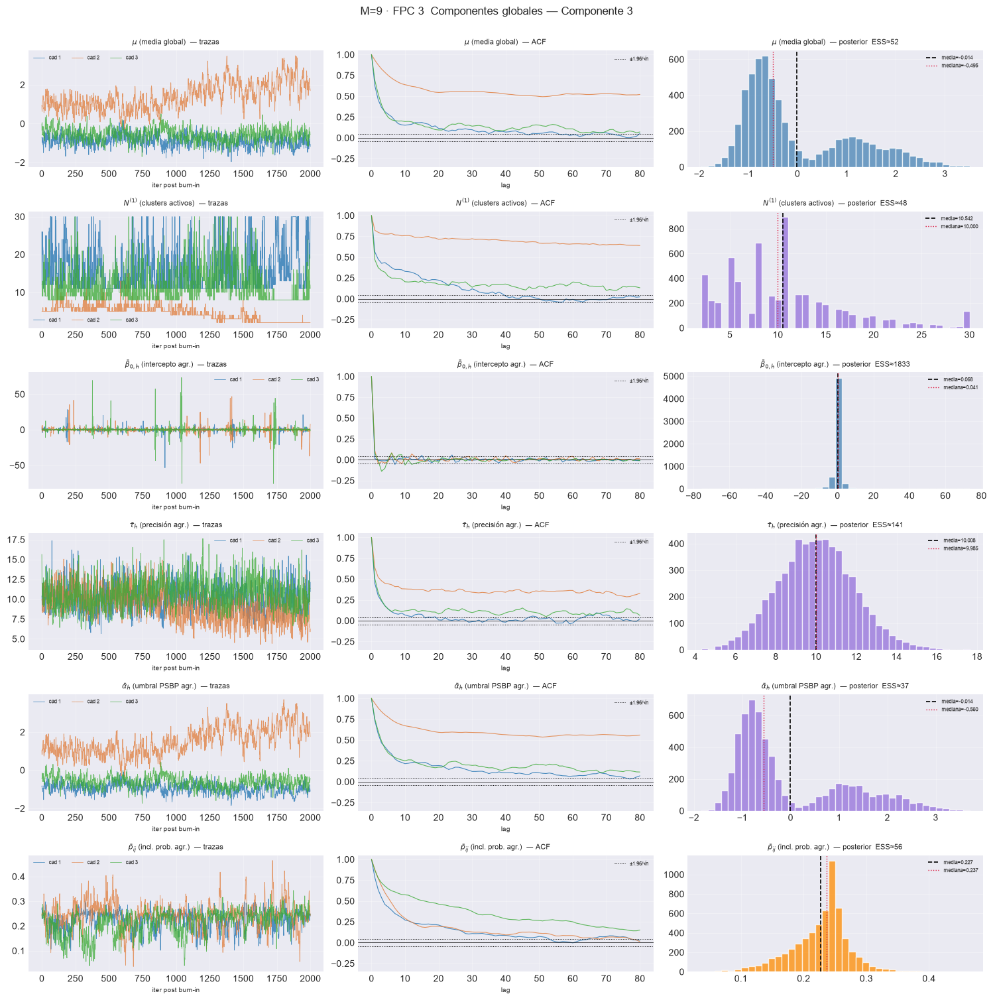

...

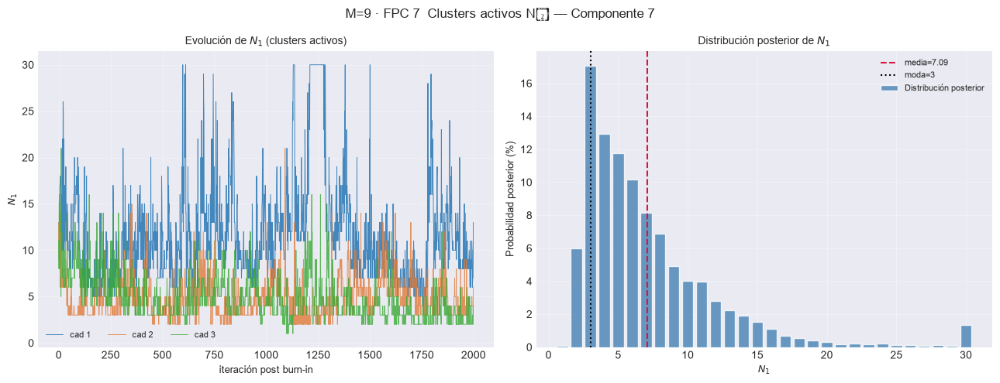

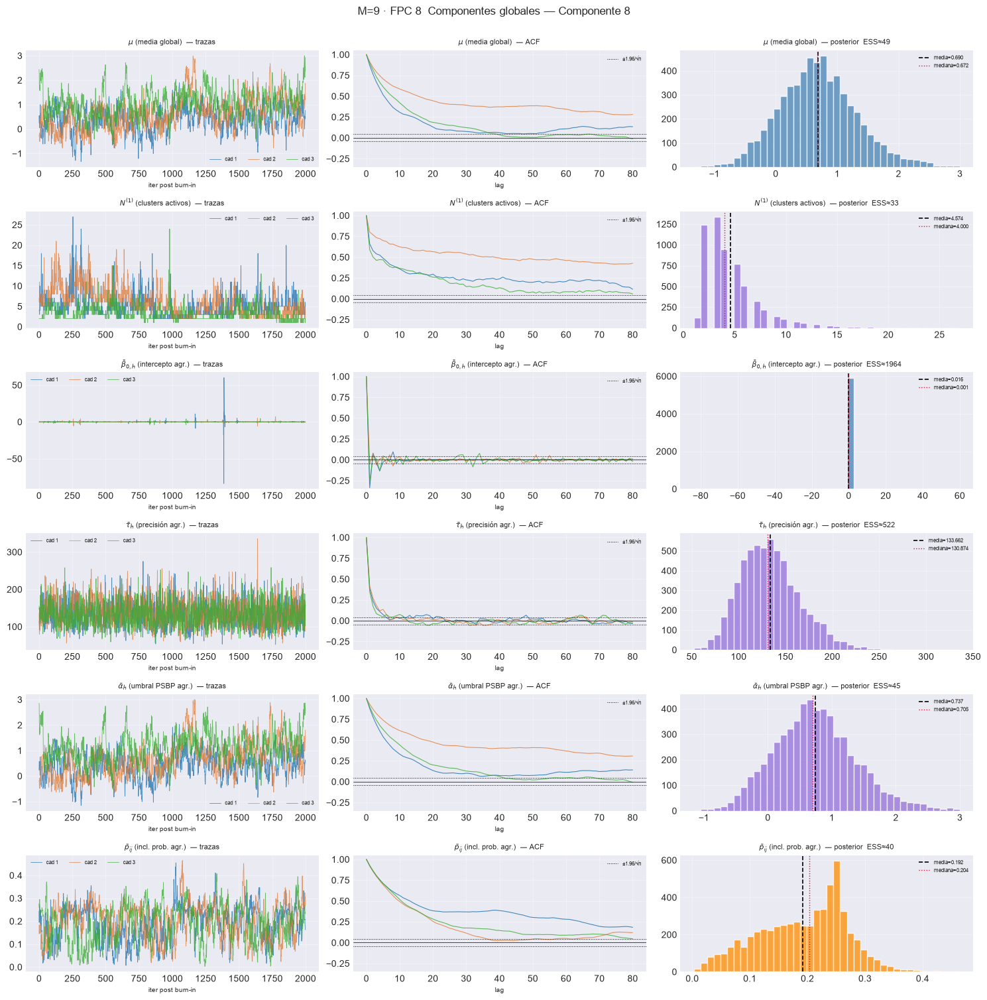

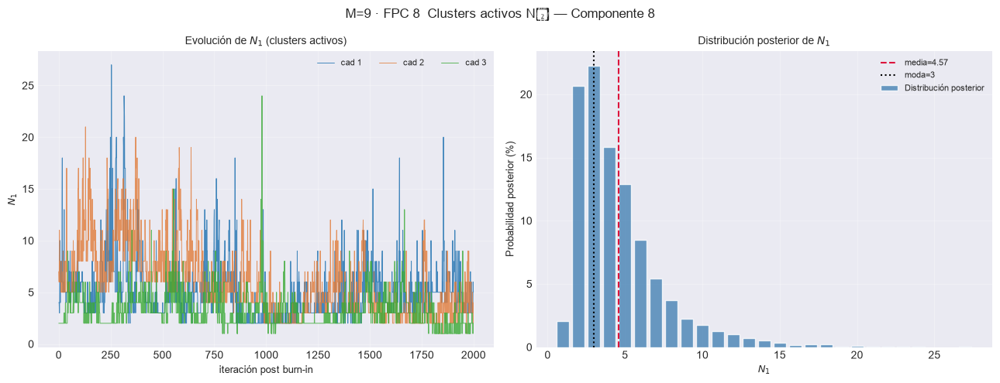

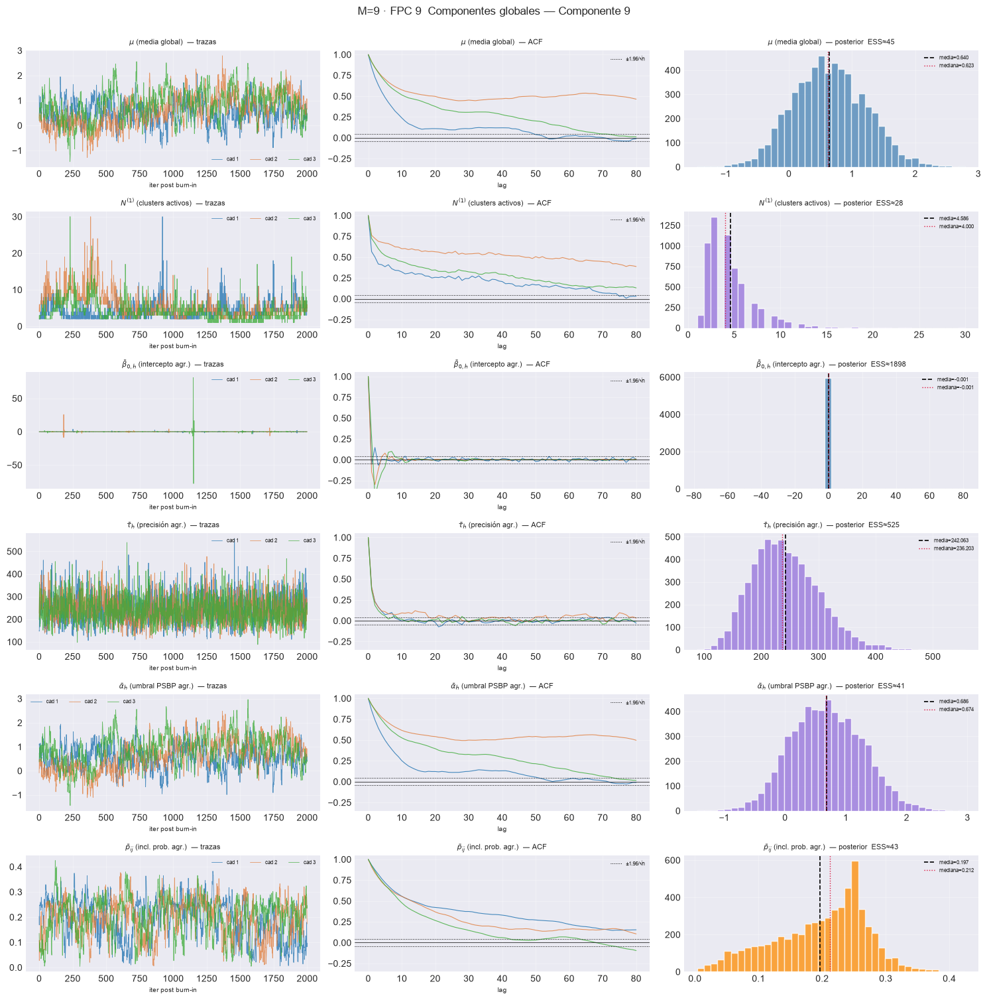

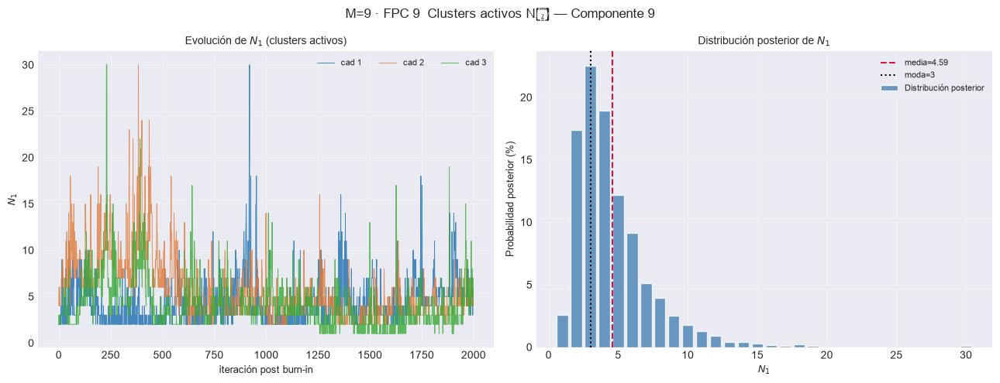

== M=10 ==============================================


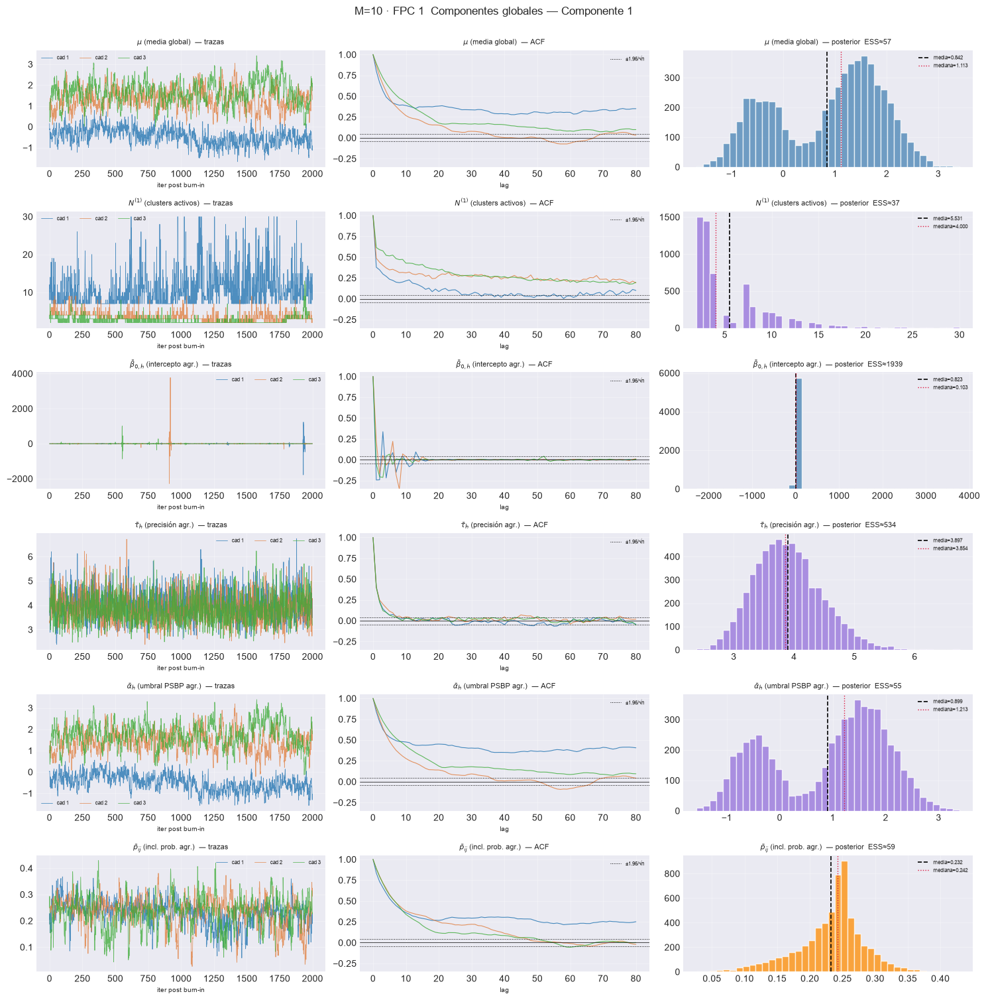

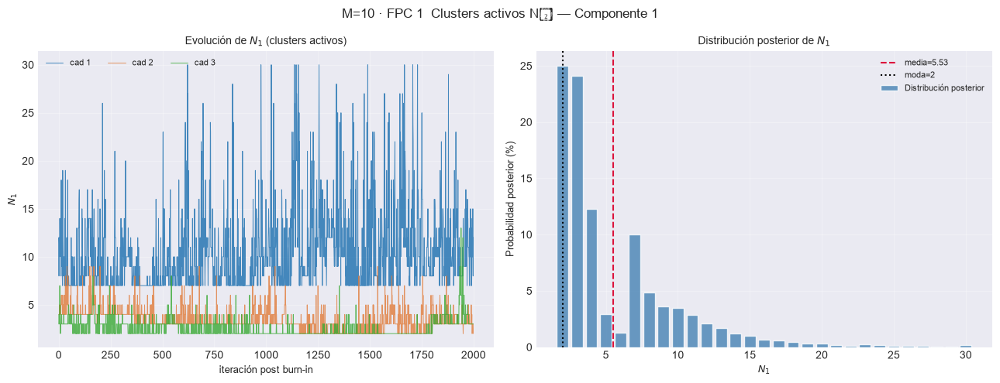

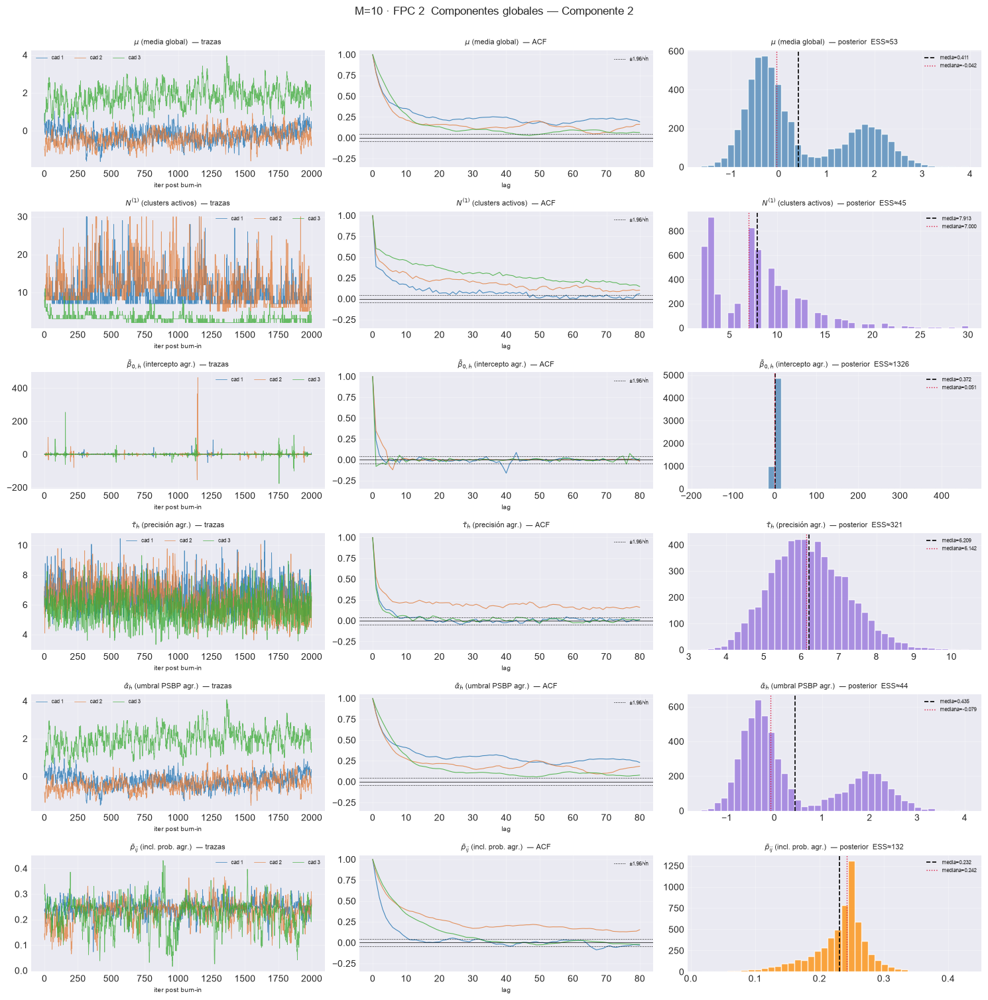

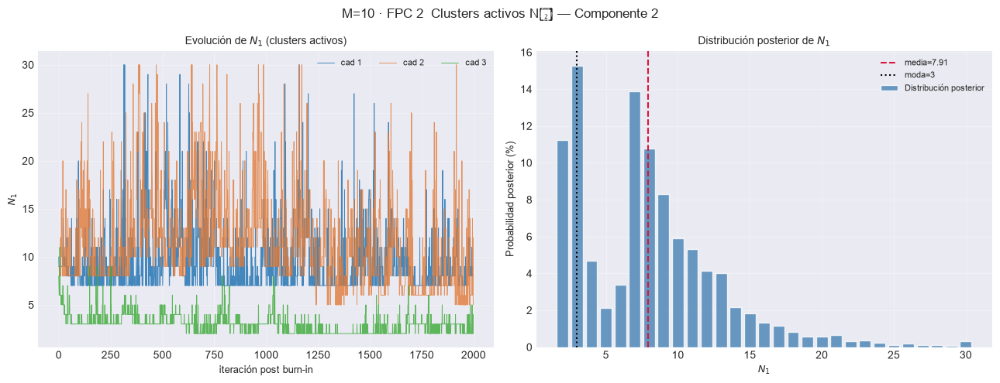

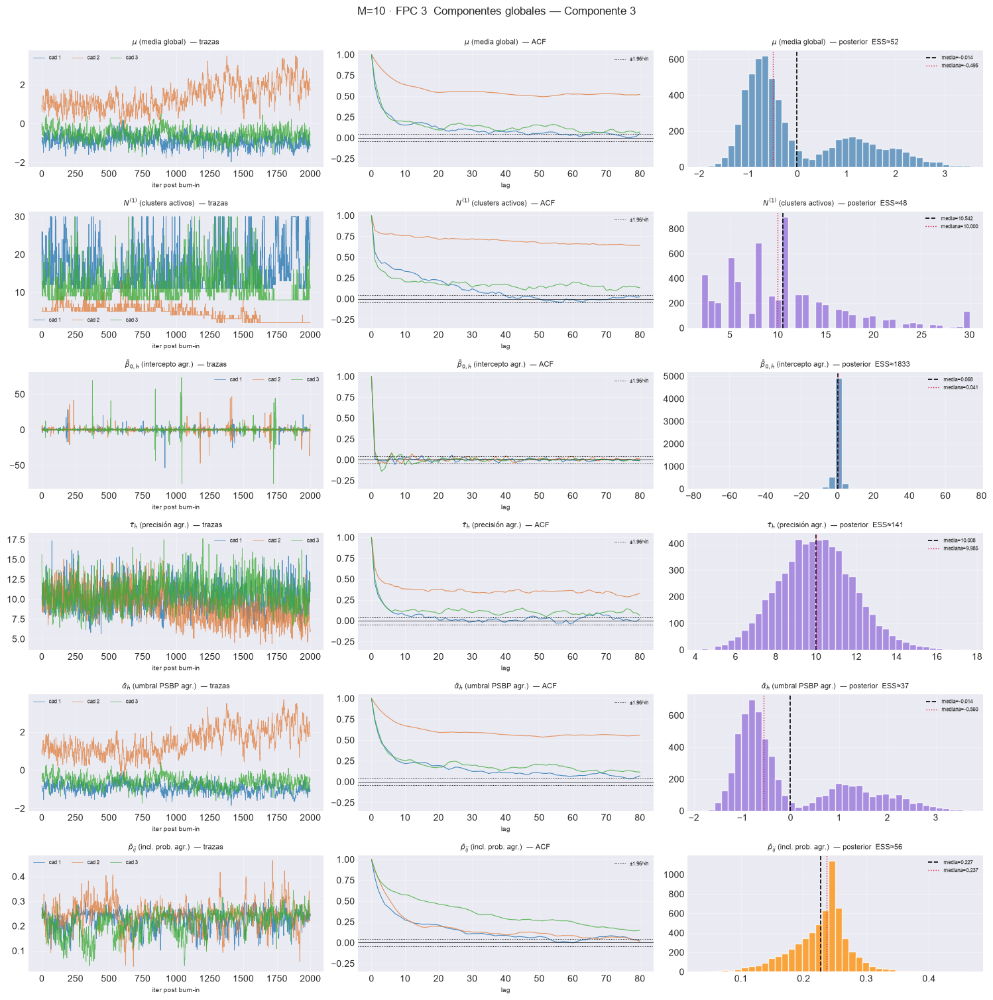

...

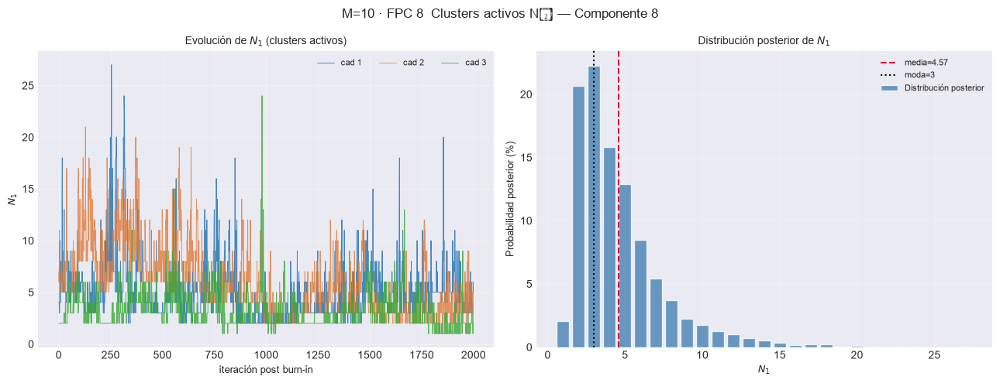

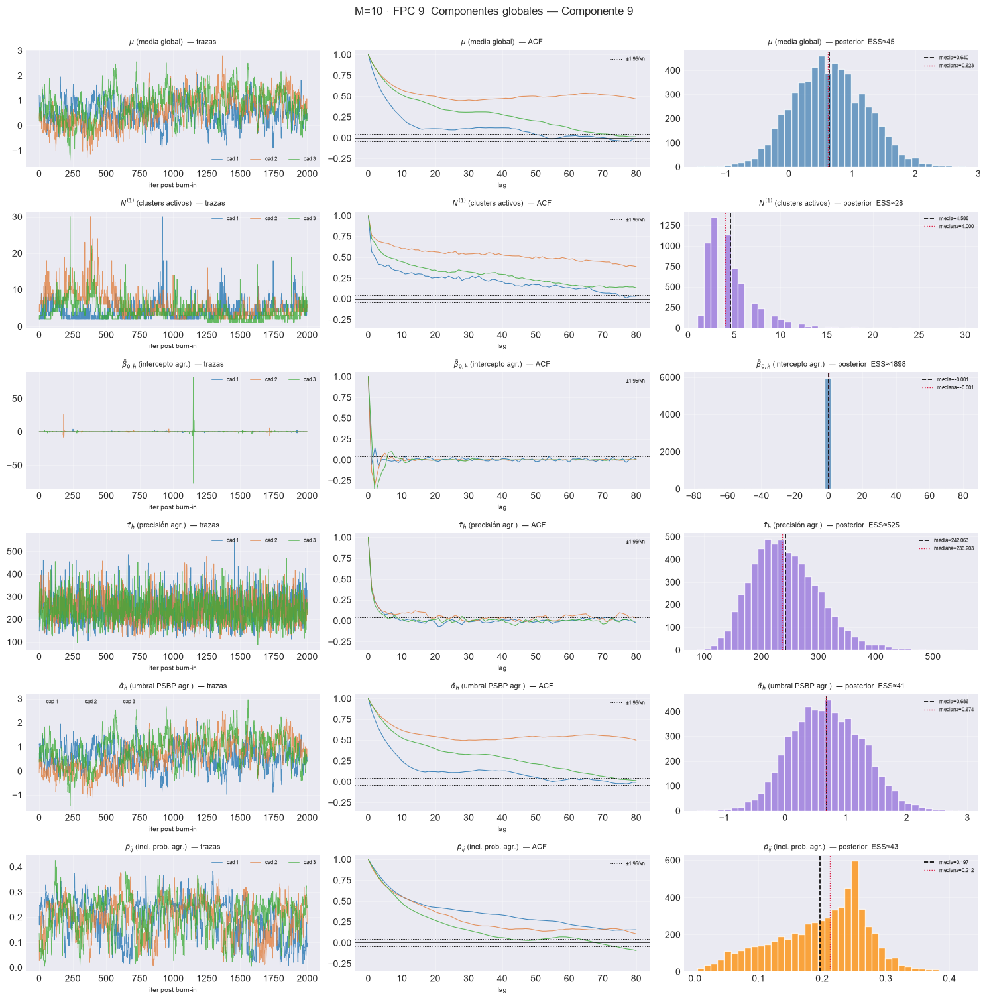

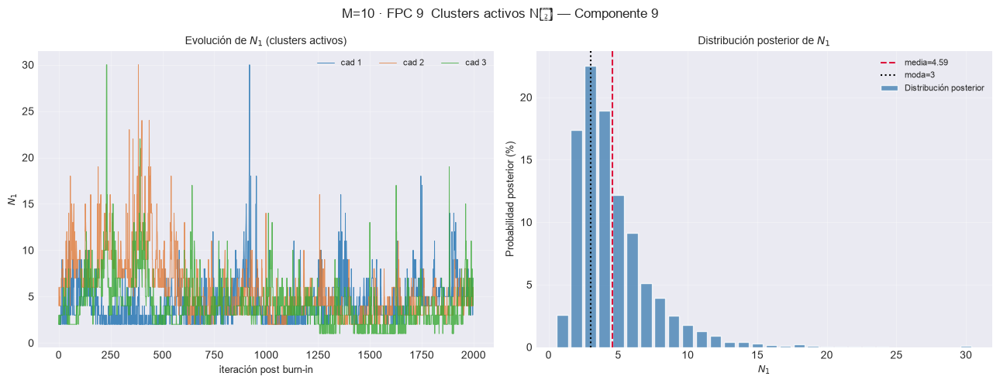

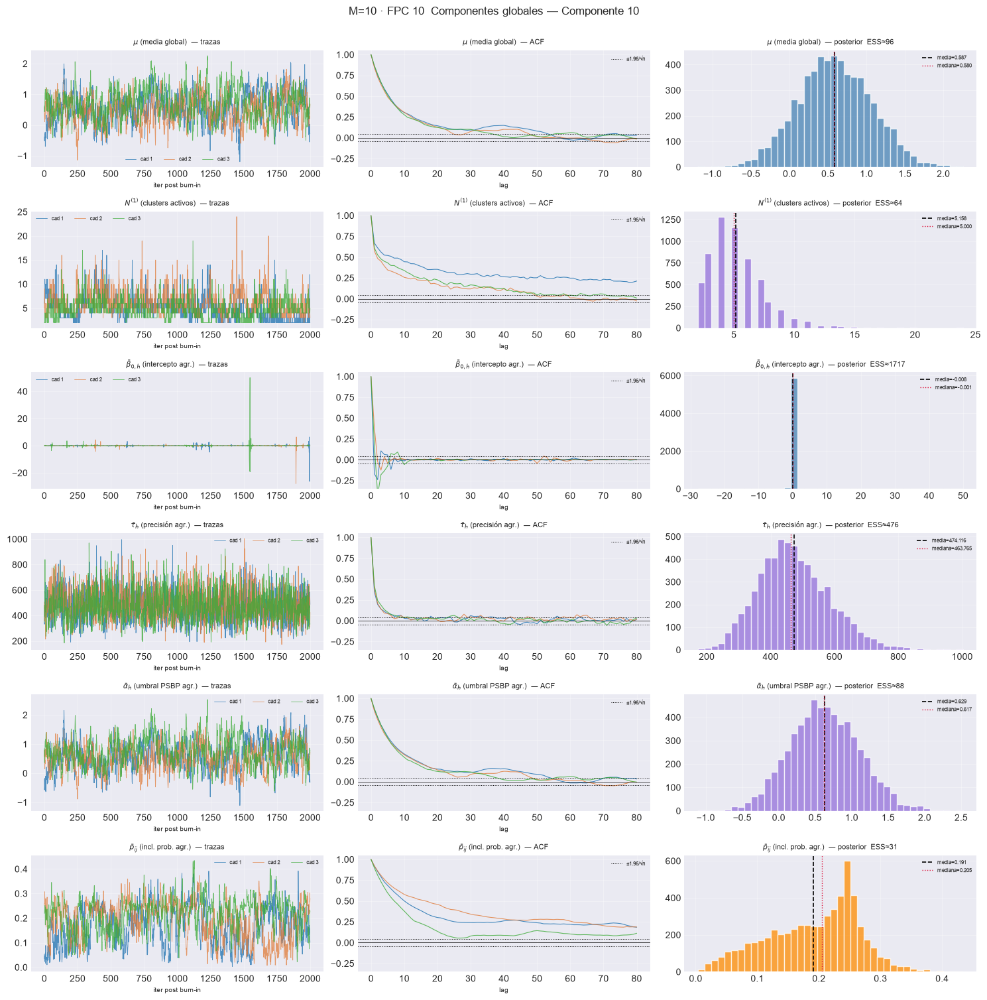

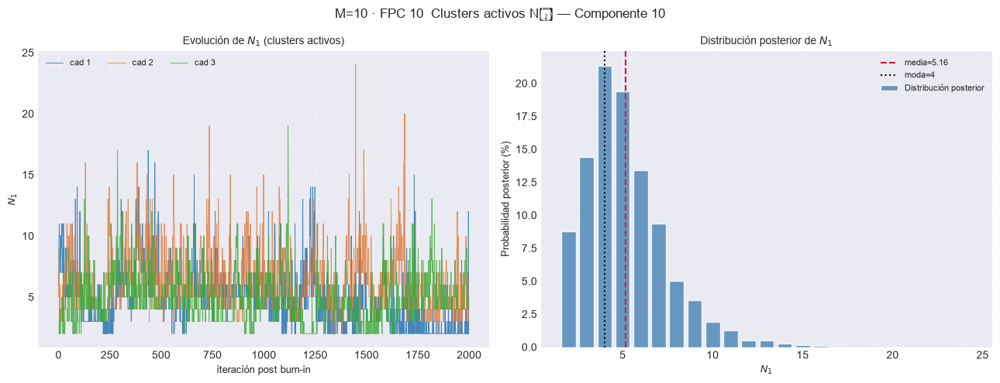

In [10]:
for M in M_OK:
    e = EST[M]
    print(f"== M={M} " + "=" * 46)
    for k in e["models_chains"]:
        fpc = e["component_idx"][k] + 1
        args = (e["models_chains"], k, e["burn"], e["n_iter"])
        plot_global_components(*args, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"42_global_k{fpc}.png"))
        plt.show()
        plot_active_clusters(*args, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"43_clusters_k{fpc}.png"))
        plt.show()

== M=1 ==============================================
[plot_convergence_bj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.2s eta=0.5s  fpc_1_lag1  rhat=1.000  ess_min=1933  |G|=1.16  ✓
  2/4 (50.0%) t=0.3s eta=0.3s  fpc_1_lag2  rhat=1.000  ess_min=1619  |G|=2.05  ✗
  3/4 (75.0%) t=0.4s eta=0.1s  fpc_1_lag3  rhat=1.000  ess_min=1859  |G|=1.27  ✓
  4/4 (100.0%) t=0.5s eta=0.0s  fpc_1_lag4  rhat=1.000  ess_min=1870  |G|=0.65  ✓


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:348: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:348: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:350: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:350: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_bj[FPC 1]] listo: 4 pasos en 3.4s  1/4 sin converger


c:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\.v_2\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\.v_2\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


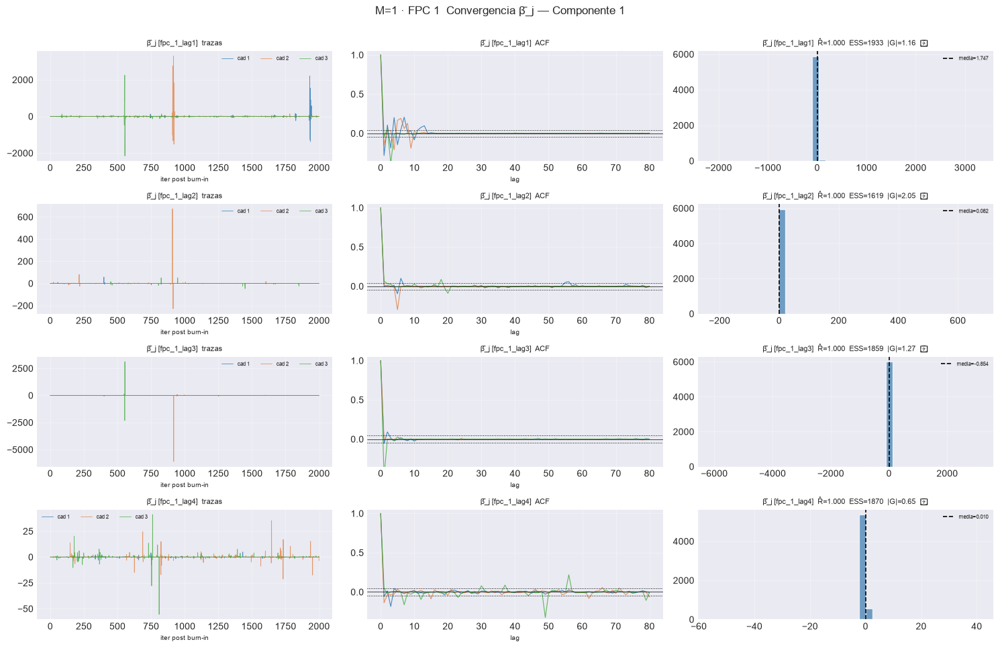

[plot_convergence_pj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_1_lag1  rhat=1.004  ess_min=19  |G|=3.19  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_1_lag2  rhat=1.000  ess_min=19  |G|=6.04  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_1_lag3  rhat=1.007  ess_min=148  |G|=3.75  ✗
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_1_lag4  rhat=1.016  ess_min=125  |G|=0.74  ✓


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:447: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:447: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:449: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:449: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_pj[FPC 1]] listo: 4 pasos en 3.6s  3/4 sin converger


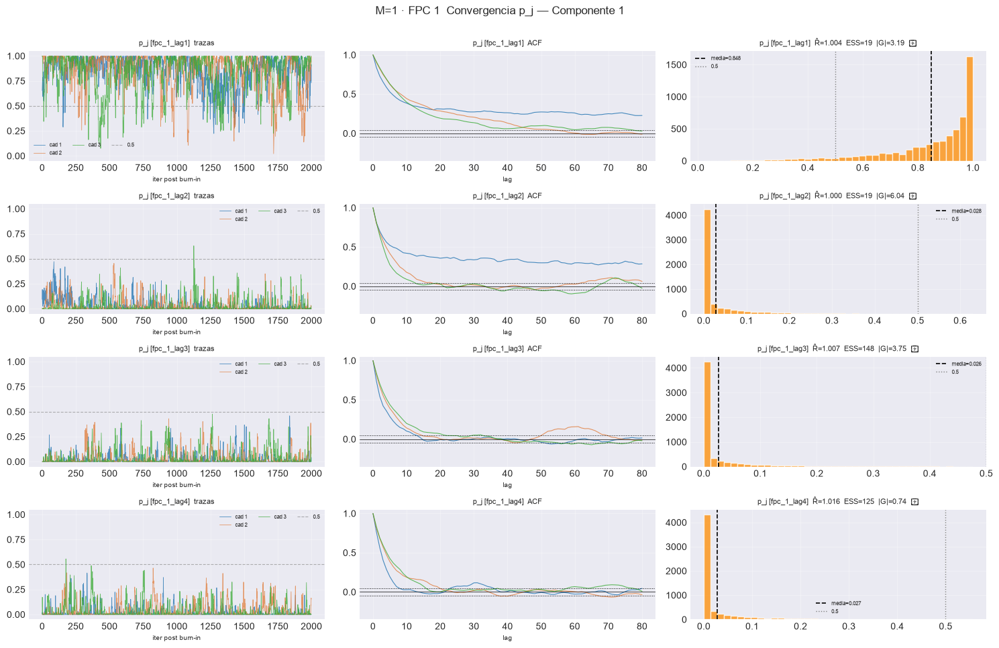

== M=2 ==============================================
[plot_convergence_bj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_1_lag1  rhat=1.000  ess_min=1933  |G|=1.16  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_1_lag2  rhat=1.000  ess_min=1619  |G|=2.05  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_1_lag3  rhat=1.000  ess_min=1859  |G|=1.27  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_1_lag4  rhat=1.000  ess_min=1870  |G|=0.65  ✓
[plot_convergence_bj[FPC 1]] listo: 4 pasos en 3.3s  1/4 sin converger


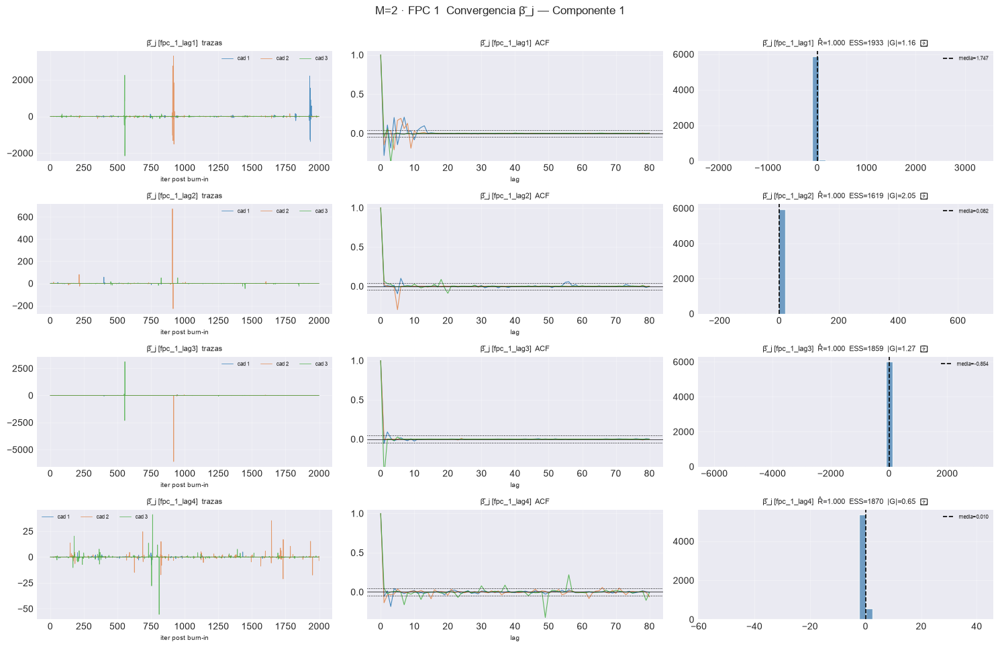

[plot_convergence_pj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_1_lag1  rhat=1.004  ess_min=19  |G|=3.19  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_1_lag2  rhat=1.000  ess_min=19  |G|=6.04  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_1_lag3  rhat=1.007  ess_min=148  |G|=3.75  ✗
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_1_lag4  rhat=1.016  ess_min=125  |G|=0.74  ✓
[plot_convergence_pj[FPC 1]] listo: 4 pasos en 3.5s  3/4 sin converger


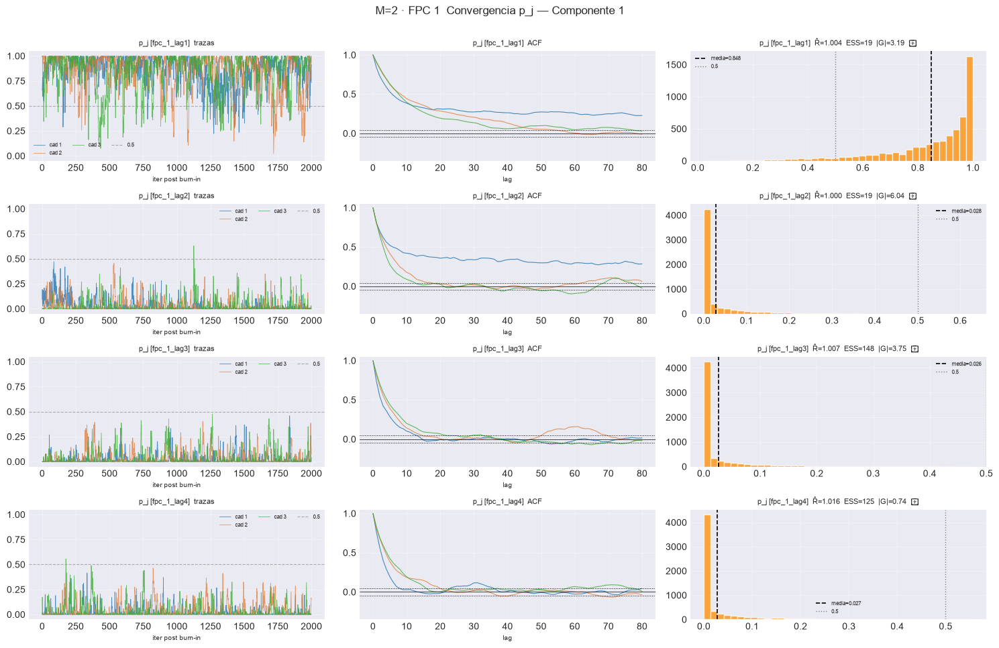

[plot_convergence_bj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=1.000  ess_min=680  |G|=2.27  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.000  ess_min=1706  |G|=1.29  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_2_lag3  rhat=1.000  ess_min=1701  |G|=0.99  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_2_lag4  rhat=1.000  ess_min=980  |G|=1.33  ✓
[plot_convergence_bj[FPC 2]] listo: 4 pasos en 3.3s  1/4 sin converger


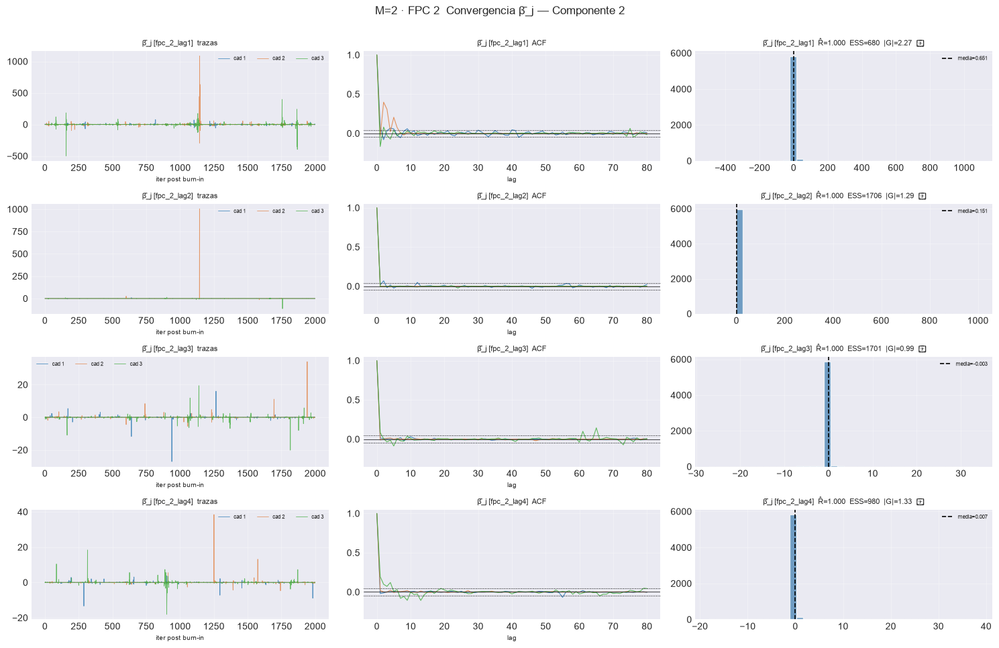

[plot_convergence_pj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=1.077  ess_min=30  |G|=8.49  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.002  ess_min=221  |G|=1.44  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_2_lag3  rhat=1.005  ess_min=248  |G|=1.40  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_2_lag4  rhat=1.006  ess_min=177  |G|=0.77  ✓
[plot_convergence_pj[FPC 2]] listo: 4 pasos en 3.4s  1/4 sin converger


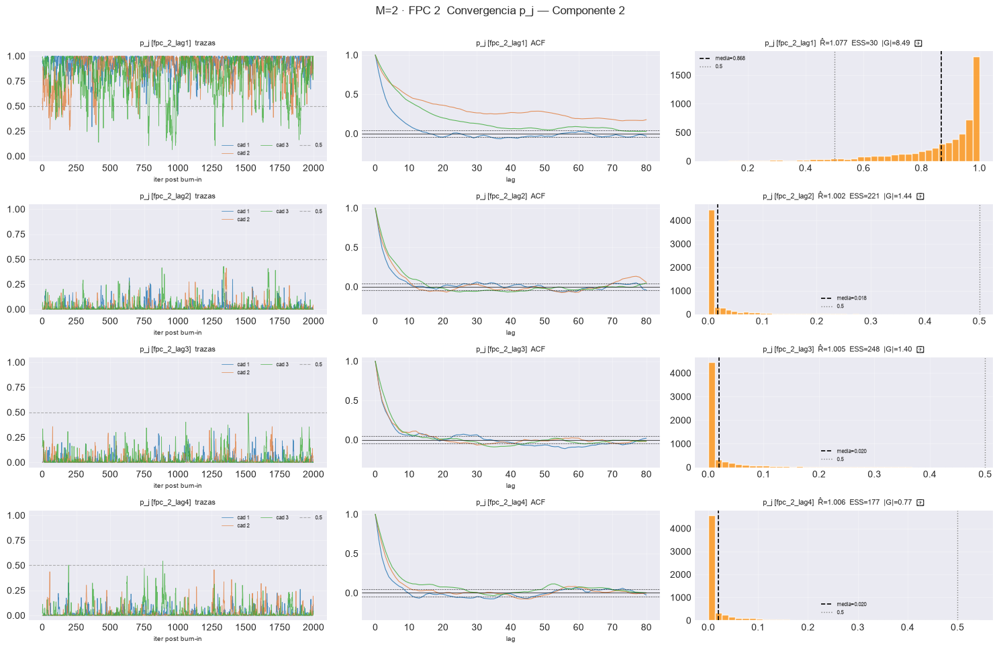

== M=3 ==============================================
[plot_convergence_bj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_1_lag1  rhat=1.000  ess_min=1933  |G|=1.16  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_1_lag2  rhat=1.000  ess_min=1619  |G|=2.05  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_1_lag3  rhat=1.000  ess_min=1859  |G|=1.27  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_1_lag4  rhat=1.000  ess_min=1870  |G|=0.65  ✓
[plot_convergence_bj[FPC 1]] listo: 4 pasos en 2.3s  1/4 sin converger


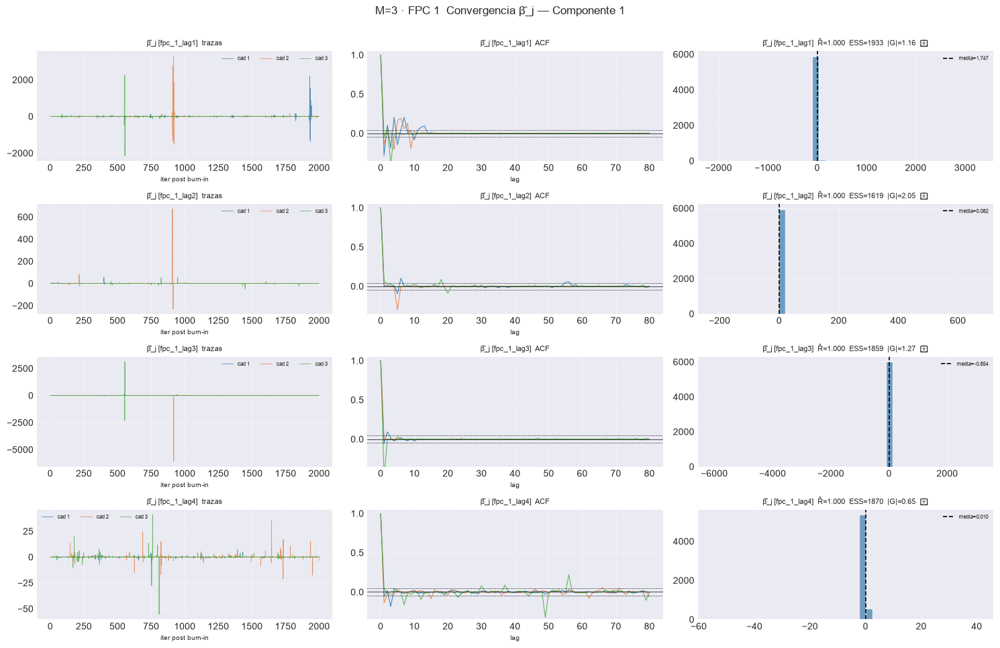

[plot_convergence_pj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=1.004  ess_min=19  |G|=3.19  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_1_lag2  rhat=1.000  ess_min=19  |G|=6.04  ✗
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_1_lag3  rhat=1.007  ess_min=148  |G|=3.75  ✗
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_1_lag4  rhat=1.016  ess_min=125  |G|=0.74  ✓
[plot_convergence_pj[FPC 1]] listo: 4 pasos en 2.2s  3/4 sin converger


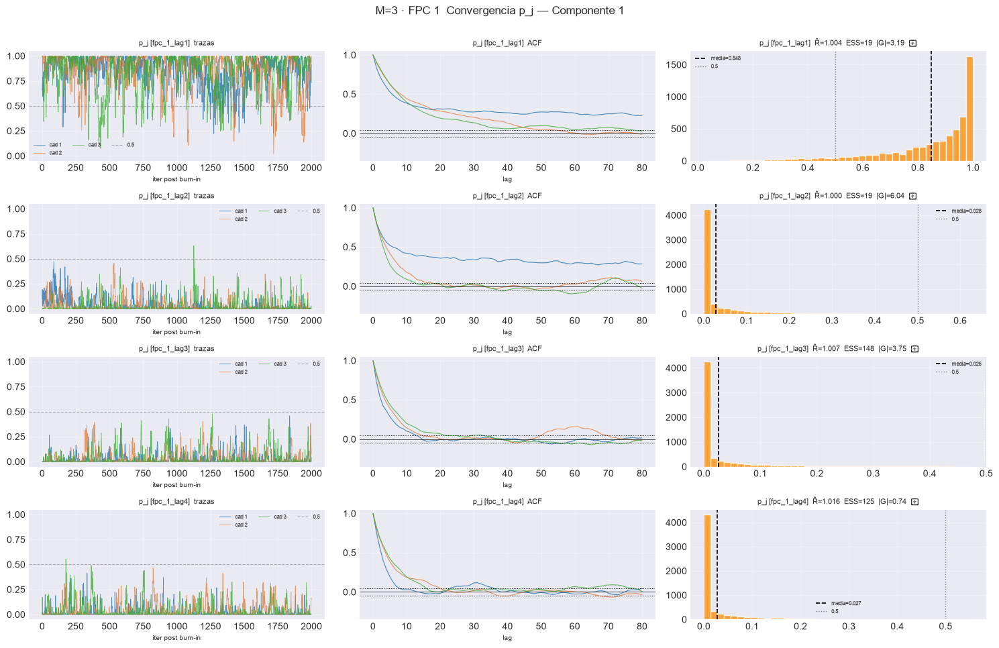

[plot_convergence_bj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=1.000  ess_min=680  |G|=2.27  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.000  ess_min=1706  |G|=1.29  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_2_lag3  rhat=1.000  ess_min=1701  |G|=0.99  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_2_lag4  rhat=1.000  ess_min=980  |G|=1.33  ✓
[plot_convergence_bj[FPC 2]] listo: 4 pasos en 2.8s  1/4 sin converger


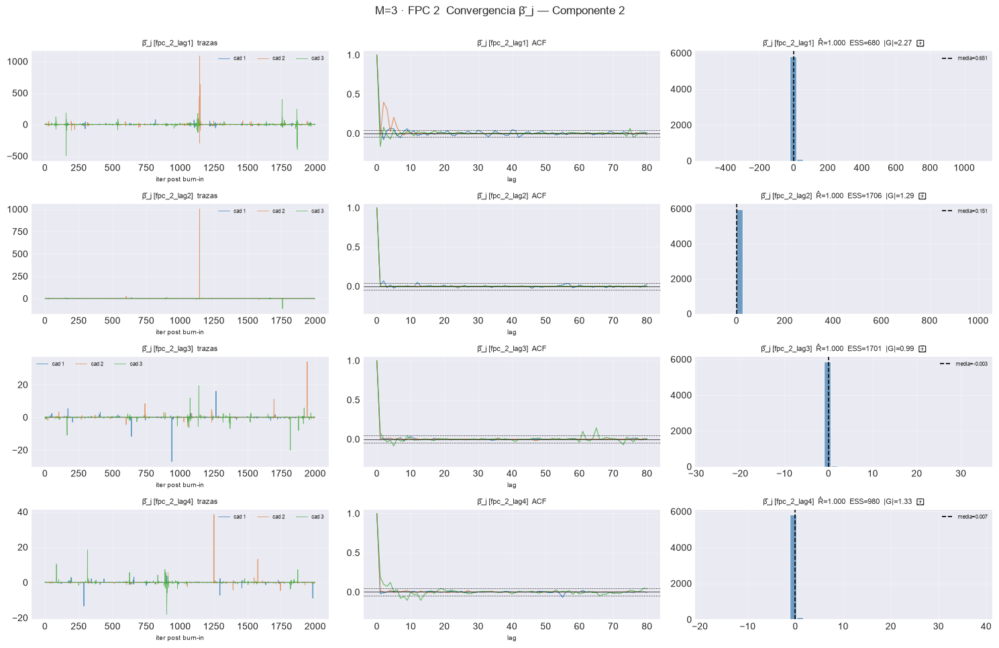

[plot_convergence_pj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=1.077  ess_min=30  |G|=8.49  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.002  ess_min=221  |G|=1.44  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_2_lag3  rhat=1.005  ess_min=248  |G|=1.40  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_2_lag4  rhat=1.006  ess_min=177  |G|=0.77  ✓
[plot_convergence_pj[FPC 2]] listo: 4 pasos en 2.3s  1/4 sin converger


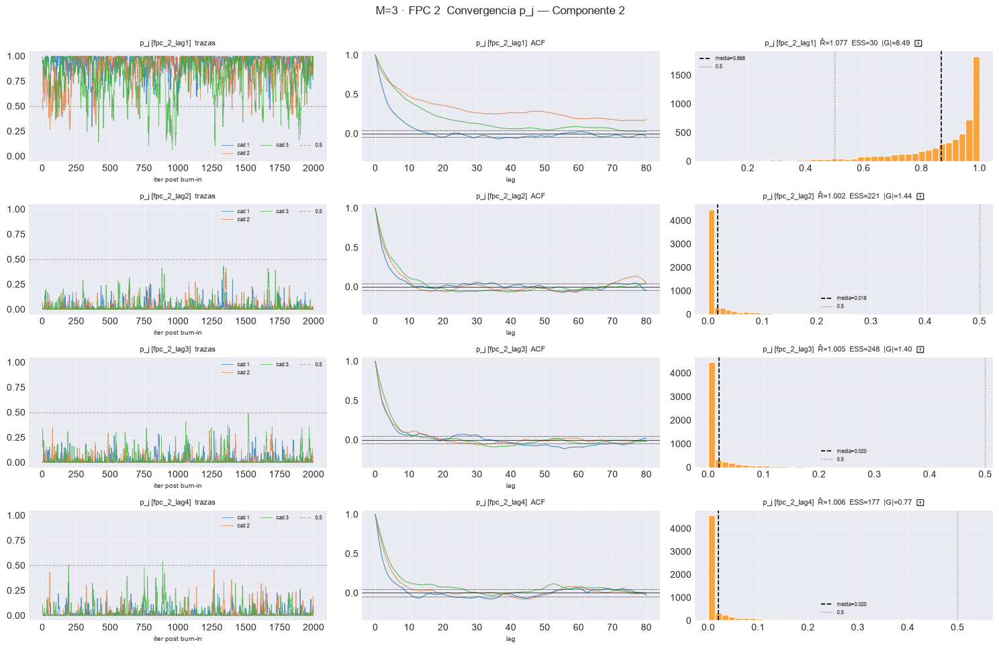

[plot_convergence_bj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=1.000  ess_min=1790  |G|=1.28  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.000  ess_min=1888  |G|=1.46  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag3  rhat=1.000  ess_min=1997  |G|=0.87  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_3_lag4  rhat=1.000  ess_min=1315  |G|=0.57  ✓
[plot_convergence_bj[FPC 3]] listo: 4 pasos en 2.0s  0/4 sin converger


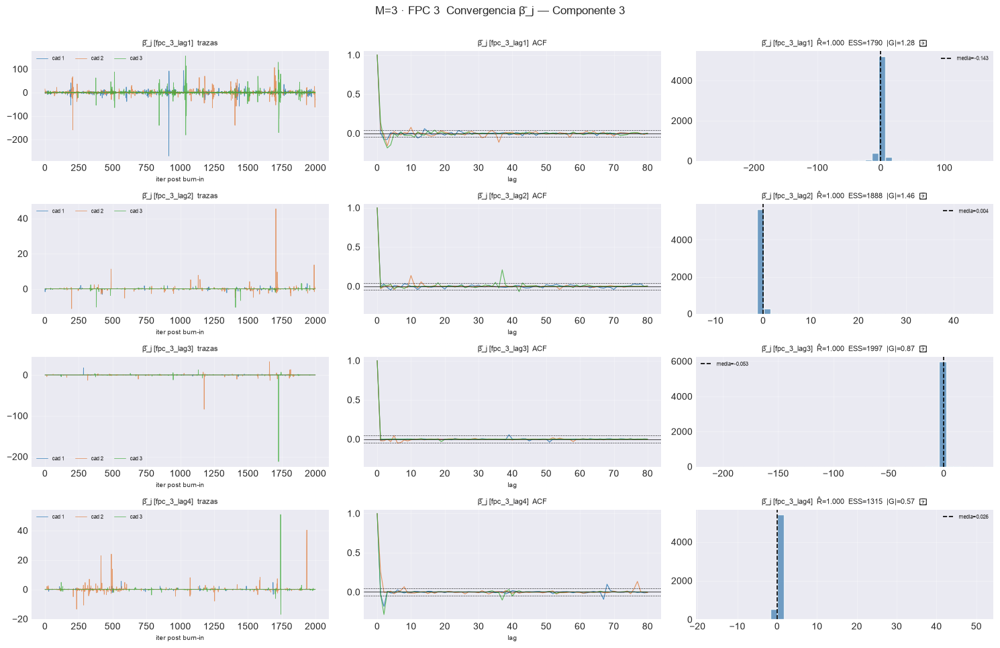

[plot_convergence_pj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_3_lag1  rhat=1.025  ess_min=32  |G|=2.08  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.010  ess_min=151  |G|=2.58  ✗
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag3  rhat=1.018  ess_min=115  |G|=1.75  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_3_lag4  rhat=1.065  ess_min=25  |G|=0.98  ✗
[plot_convergence_pj[FPC 3]] listo: 4 pasos en 2.1s  3/4 sin converger


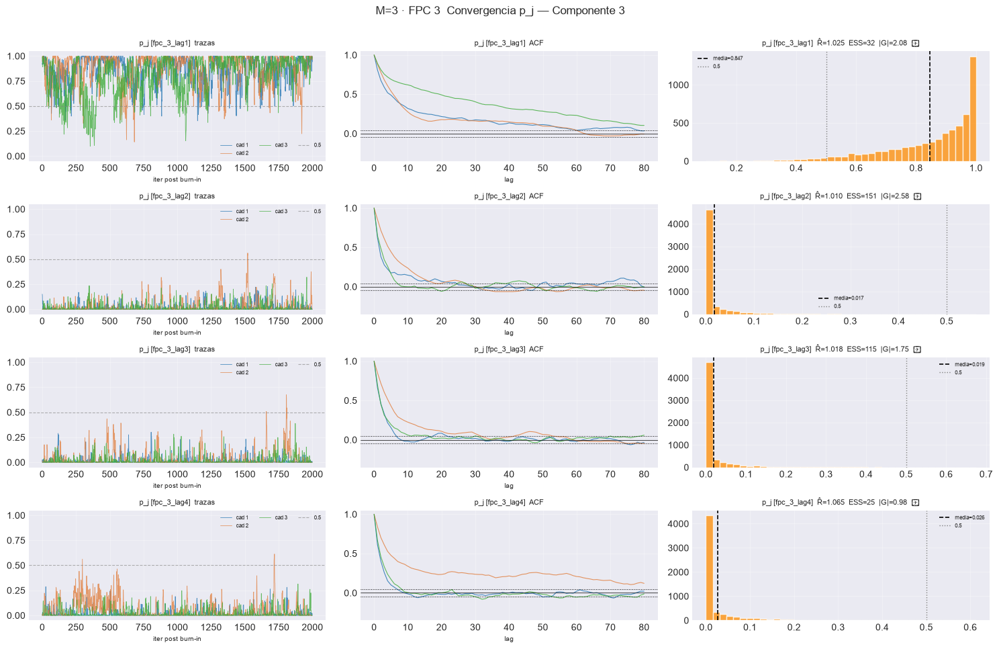

== M=4 ==============================================
[plot_convergence_bj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=1.000  ess_min=1933  |G|=1.16  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_1_lag2  rhat=1.000  ess_min=1619  |G|=2.05  ✗
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_1_lag3  rhat=1.000  ess_min=1859  |G|=1.27  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_1_lag4  rhat=1.000  ess_min=1870  |G|=0.65  ✓
[plot_convergence_bj[FPC 1]] listo: 4 pasos en 2.3s  1/4 sin converger


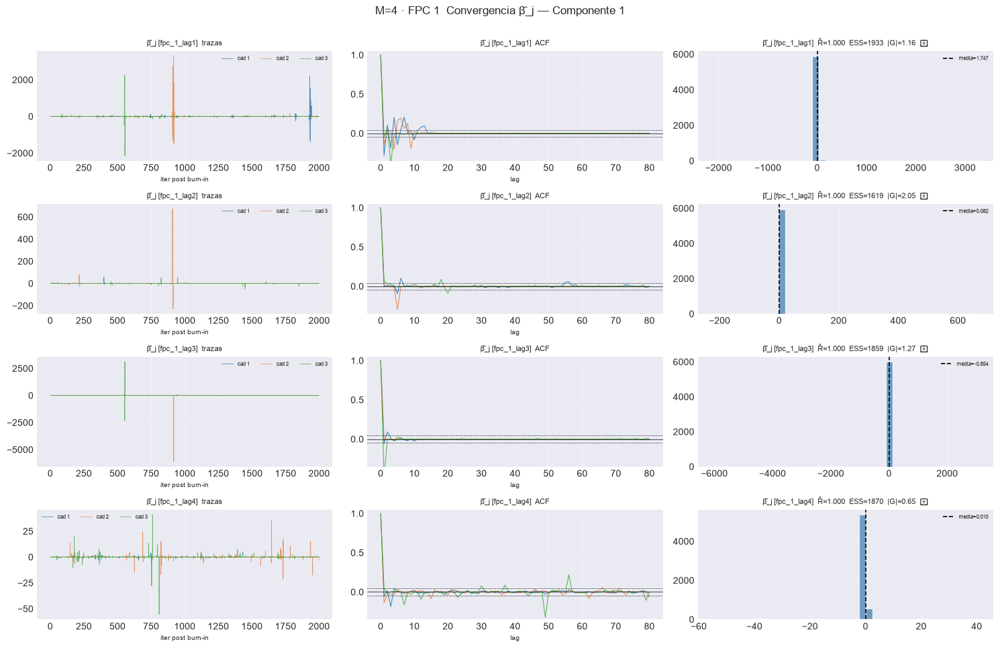

[plot_convergence_pj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=1.004  ess_min=19  |G|=3.19  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_1_lag2  rhat=1.000  ess_min=19  |G|=6.04  ✗
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_1_lag3  rhat=1.007  ess_min=148  |G|=3.75  ✗
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_1_lag4  rhat=1.016  ess_min=125  |G|=0.74  ✓
[plot_convergence_pj[FPC 1]] listo: 4 pasos en 2.7s  3/4 sin converger


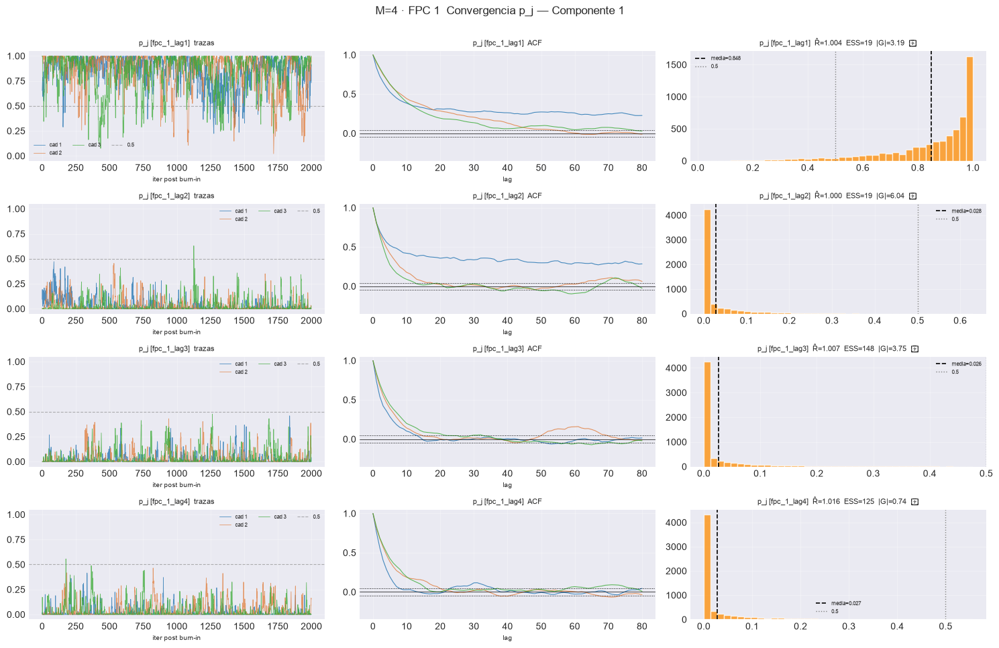

[plot_convergence_bj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=1.000  ess_min=680  |G|=2.27  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.000  ess_min=1706  |G|=1.29  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_2_lag3  rhat=1.000  ess_min=1701  |G|=0.99  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_2_lag4  rhat=1.000  ess_min=980  |G|=1.33  ✓
[plot_convergence_bj[FPC 2]] listo: 4 pasos en 2.3s  1/4 sin converger


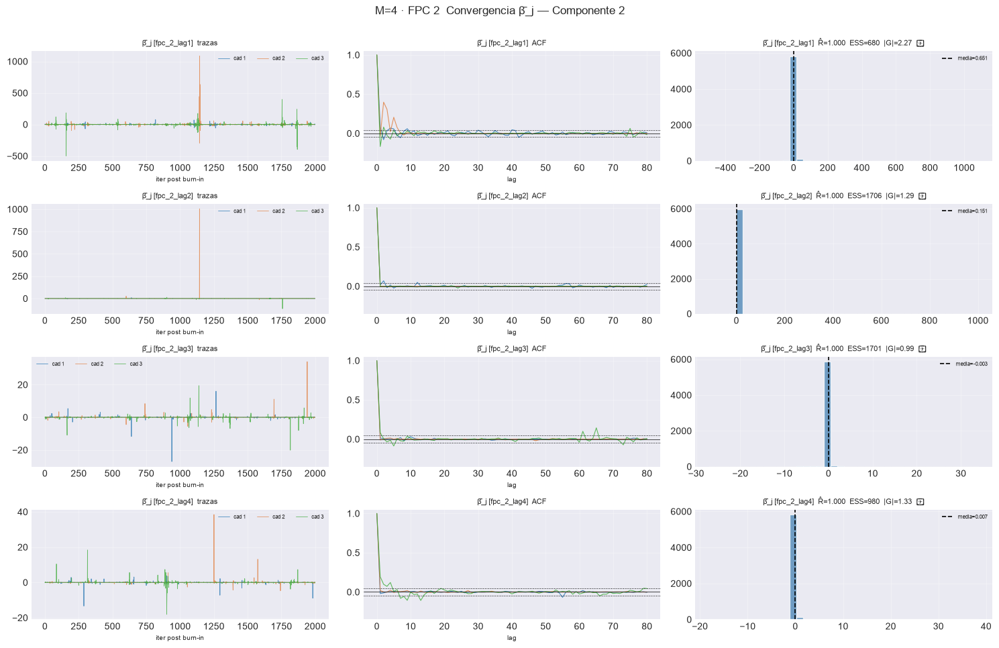

[plot_convergence_pj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=1.077  ess_min=30  |G|=8.49  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.002  ess_min=221  |G|=1.44  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_2_lag3  rhat=1.005  ess_min=248  |G|=1.40  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_2_lag4  rhat=1.006  ess_min=177  |G|=0.77  ✓
[plot_convergence_pj[FPC 2]] listo: 4 pasos en 2.3s  1/4 sin converger


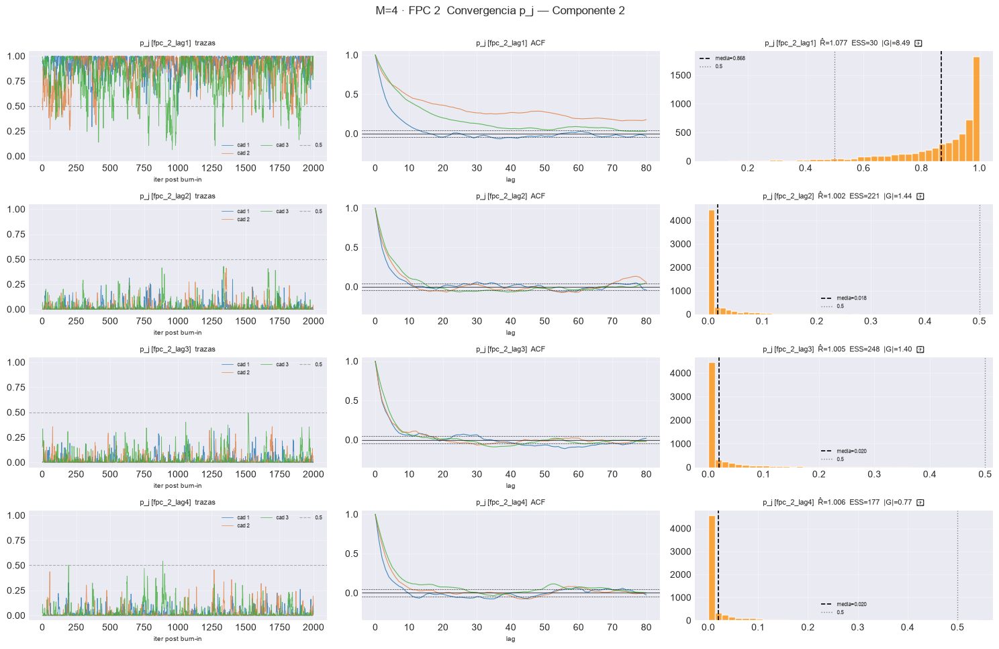

[plot_convergence_bj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_3_lag1  rhat=1.000  ess_min=1790  |G|=1.28  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.000  ess_min=1888  |G|=1.46  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_3_lag3  rhat=1.000  ess_min=1997  |G|=0.87  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_3_lag4  rhat=1.000  ess_min=1315  |G|=0.57  ✓
[plot_convergence_bj[FPC 3]] listo: 4 pasos en 2.0s  0/4 sin converger


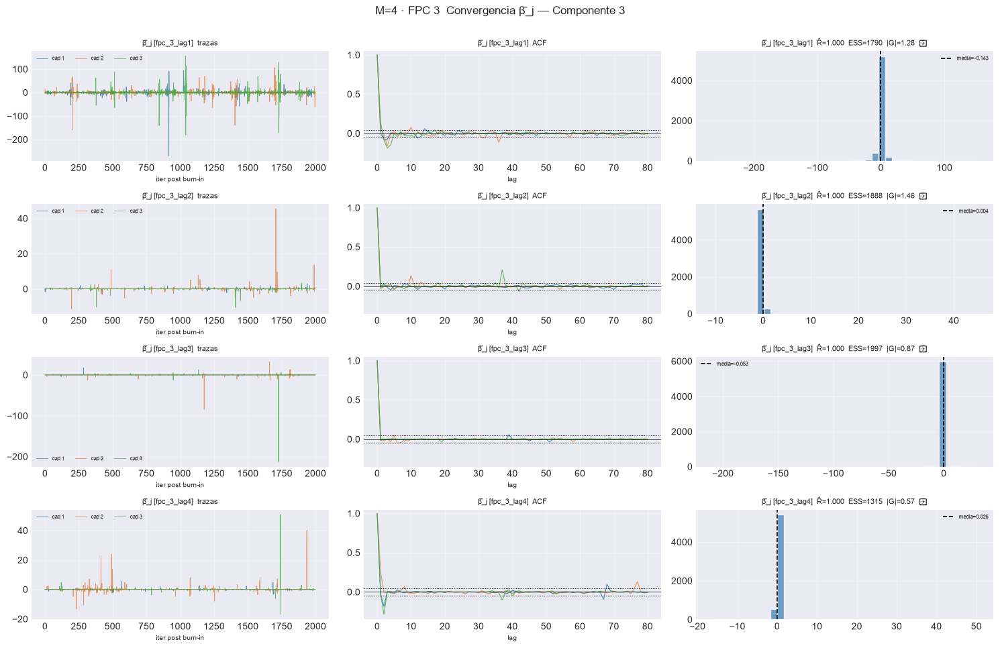

[plot_convergence_pj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_3_lag1  rhat=1.025  ess_min=32  |G|=2.08  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.010  ess_min=151  |G|=2.58  ✗
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag3  rhat=1.018  ess_min=115  |G|=1.75  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_3_lag4  rhat=1.065  ess_min=25  |G|=0.98  ✗
[plot_convergence_pj[FPC 3]] listo: 4 pasos en 2.6s  3/4 sin converger


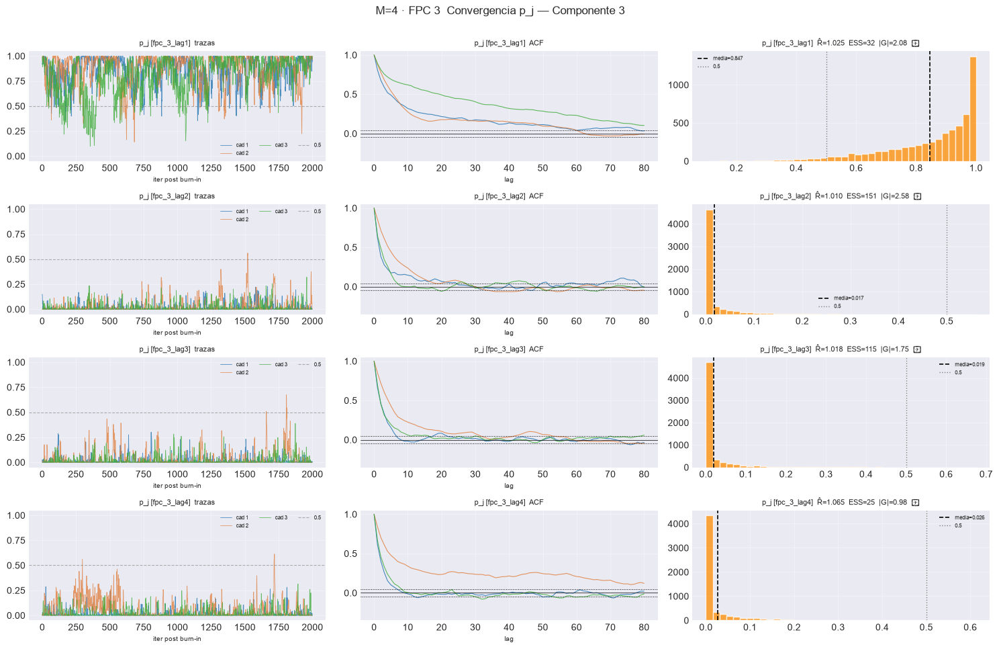

[plot_convergence_bj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=1.000  ess_min=1062  |G|=1.33  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_4_lag2  rhat=1.000  ess_min=1243  |G|=1.50  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_4_lag3  rhat=1.000  ess_min=1233  |G|=0.97  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_4_lag4  rhat=1.000  ess_min=1722  |G|=1.97  ✓
[plot_convergence_bj[FPC 4]] listo: 4 pasos en 2.6s  0/4 sin converger


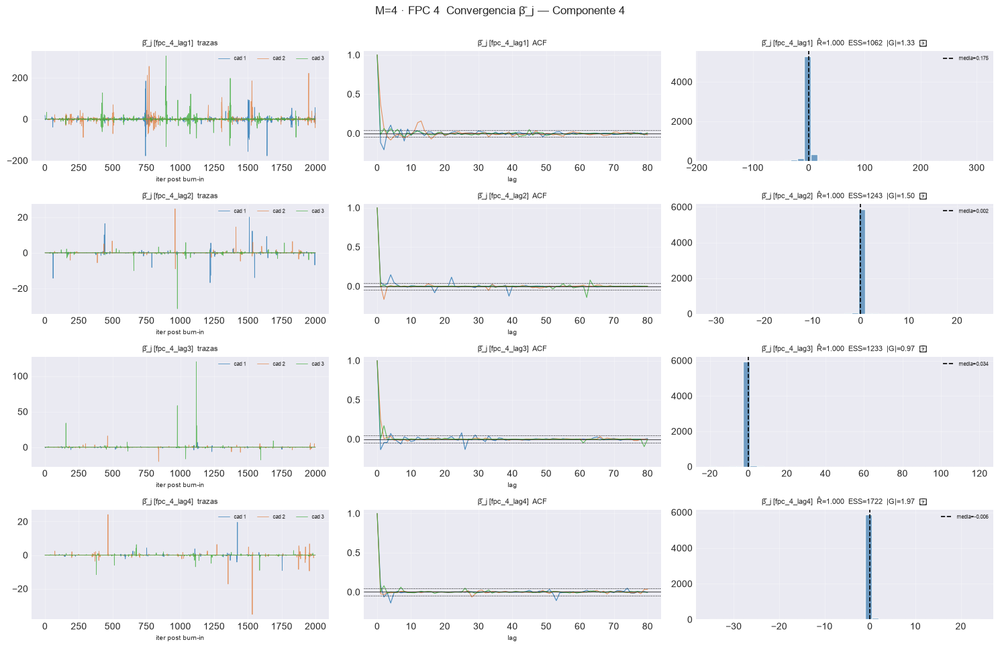

[plot_convergence_pj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=1.070  ess_min=10  |G|=7.40  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_4_lag2  rhat=1.001  ess_min=207  |G|=1.21  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_4_lag3  rhat=1.002  ess_min=177  |G|=0.80  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_4_lag4  rhat=1.003  ess_min=208  |G|=1.74  ✓
[plot_convergence_pj[FPC 4]] listo: 4 pasos en 2.5s  1/4 sin converger


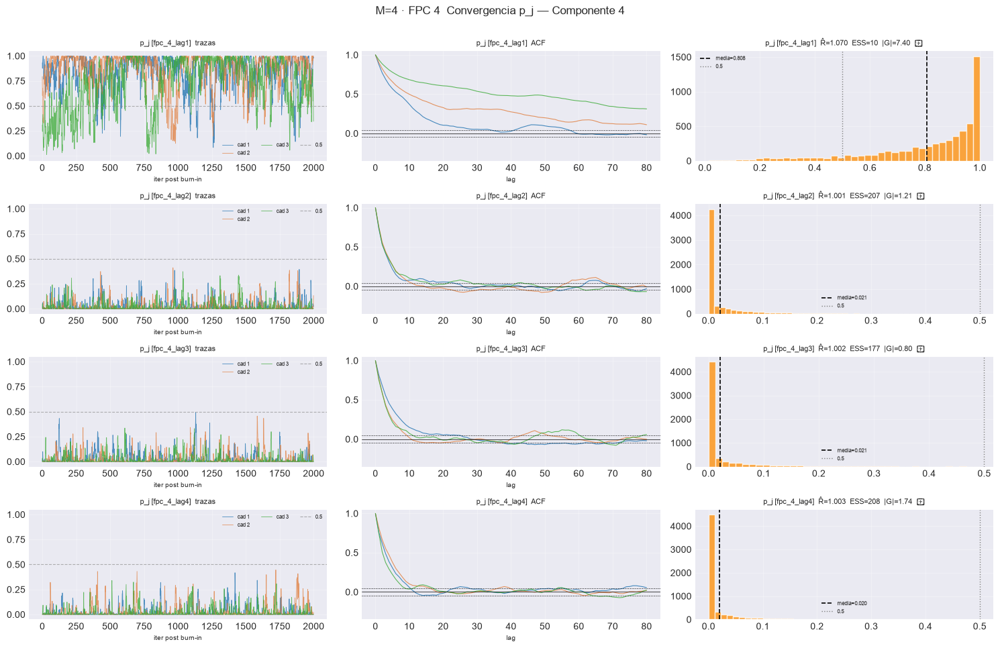

== M=5 ==============================================
[plot_convergence_bj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_1_lag1  rhat=1.000  ess_min=1933  |G|=1.16  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_1_lag2  rhat=1.000  ess_min=1619  |G|=2.05  ✗
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_1_lag3  rhat=1.000  ess_min=1859  |G|=1.27  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_1_lag4  rhat=1.000  ess_min=1870  |G|=0.65  ✓
[plot_convergence_bj[FPC 1]] listo: 4 pasos en 1.9s  1/4 sin converger


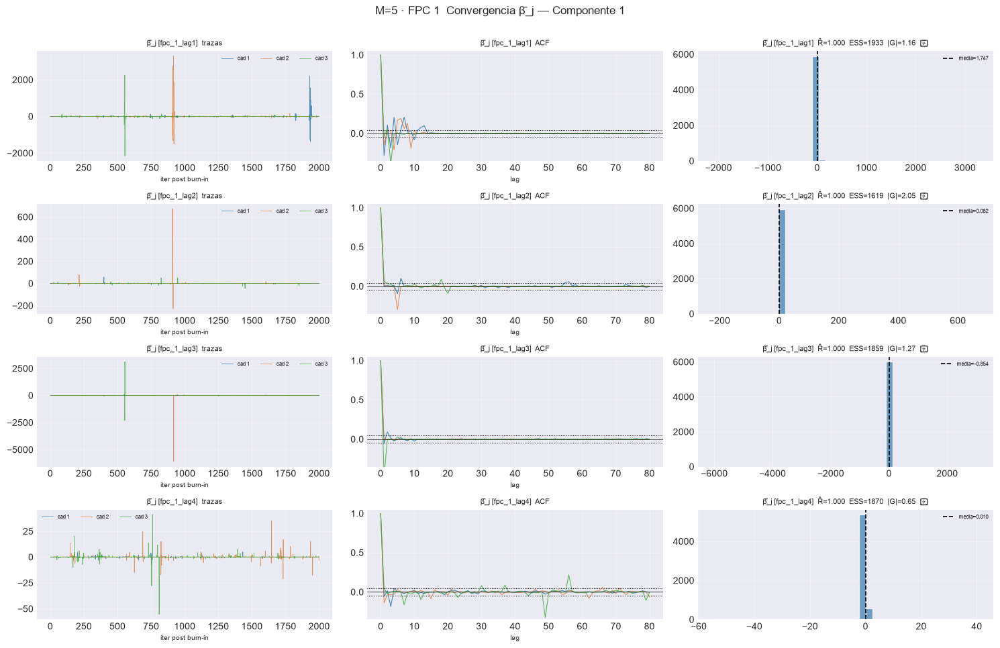

[plot_convergence_pj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_1_lag1  rhat=1.004  ess_min=19  |G|=3.19  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_1_lag2  rhat=1.000  ess_min=19  |G|=6.04  ✗
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_1_lag3  rhat=1.007  ess_min=148  |G|=3.75  ✗
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_1_lag4  rhat=1.016  ess_min=125  |G|=0.74  ✓
[plot_convergence_pj[FPC 1]] listo: 4 pasos en 2.6s  3/4 sin converger


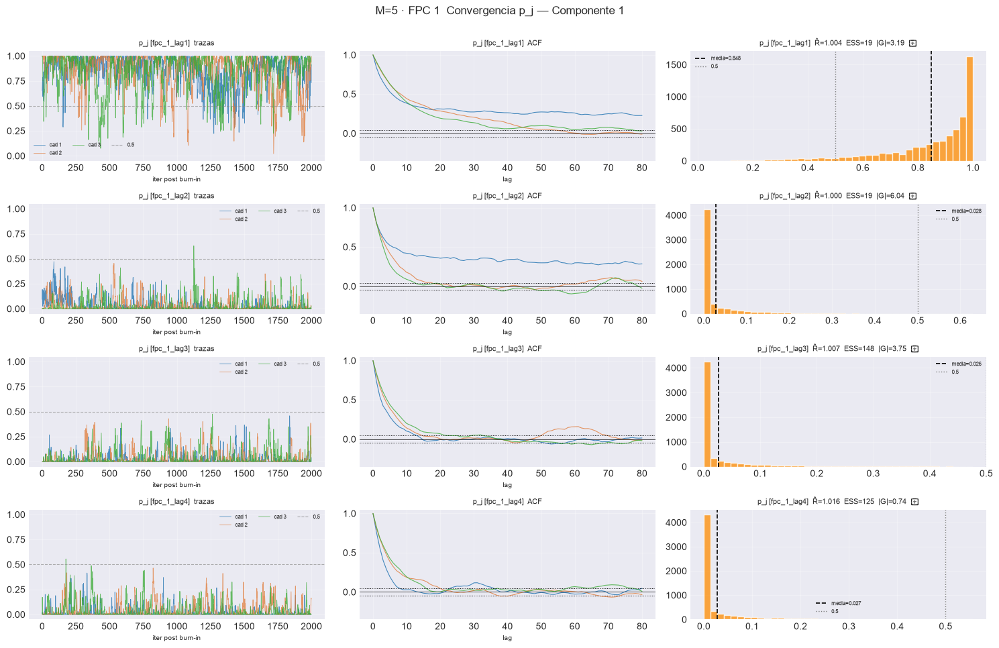

[plot_convergence_bj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=1.000  ess_min=680  |G|=2.27  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.000  ess_min=1706  |G|=1.29  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_2_lag3  rhat=1.000  ess_min=1701  |G|=0.99  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_2_lag4  rhat=1.000  ess_min=980  |G|=1.33  ✓
[plot_convergence_bj[FPC 2]] listo: 4 pasos en 2.6s  1/4 sin converger


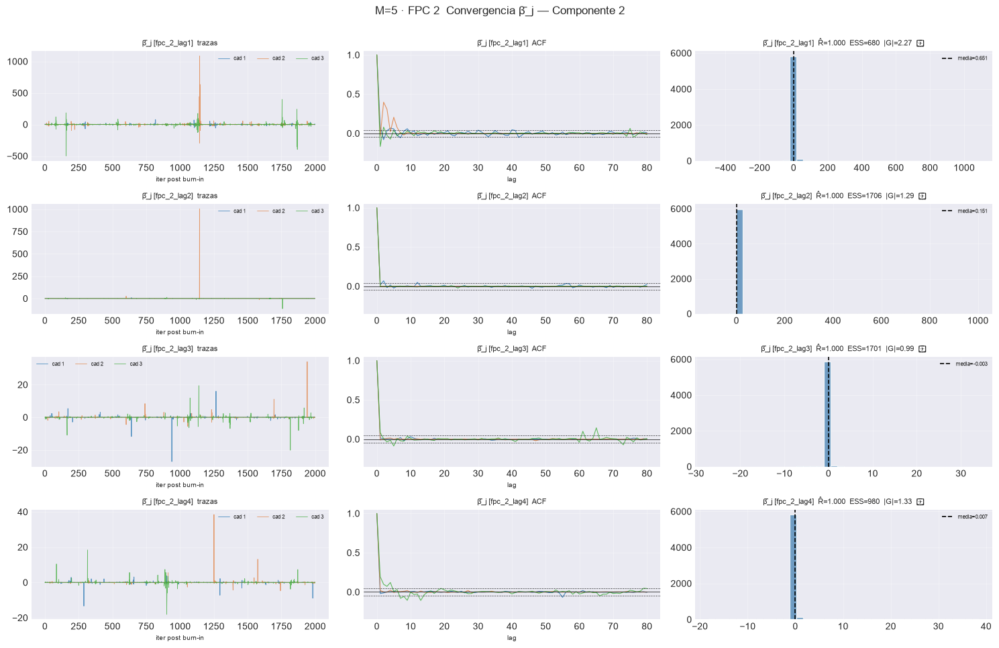

[plot_convergence_pj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=1.077  ess_min=30  |G|=8.49  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.002  ess_min=221  |G|=1.44  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_2_lag3  rhat=1.005  ess_min=248  |G|=1.40  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_2_lag4  rhat=1.006  ess_min=177  |G|=0.77  ✓
[plot_convergence_pj[FPC 2]] listo: 4 pasos en 3.5s  1/4 sin converger


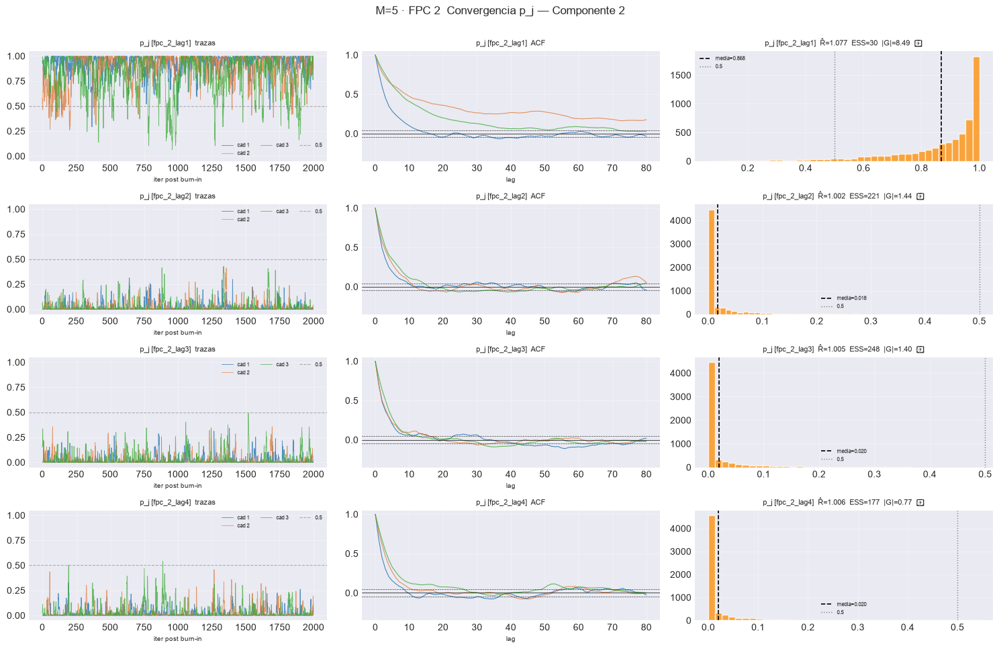

[plot_convergence_bj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.4s  fpc_3_lag1  rhat=1.000  ess_min=1790  |G|=1.28  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_3_lag2  rhat=1.000  ess_min=1888  |G|=1.46  ✓
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_3_lag3  rhat=1.000  ess_min=1997  |G|=0.87  ✓
  4/4 (100.0%) t=0.4s eta=0.0s  fpc_3_lag4  rhat=1.000  ess_min=1315  |G|=0.57  ✓
[plot_convergence_bj[FPC 3]] listo: 4 pasos en 3.3s  0/4 sin converger


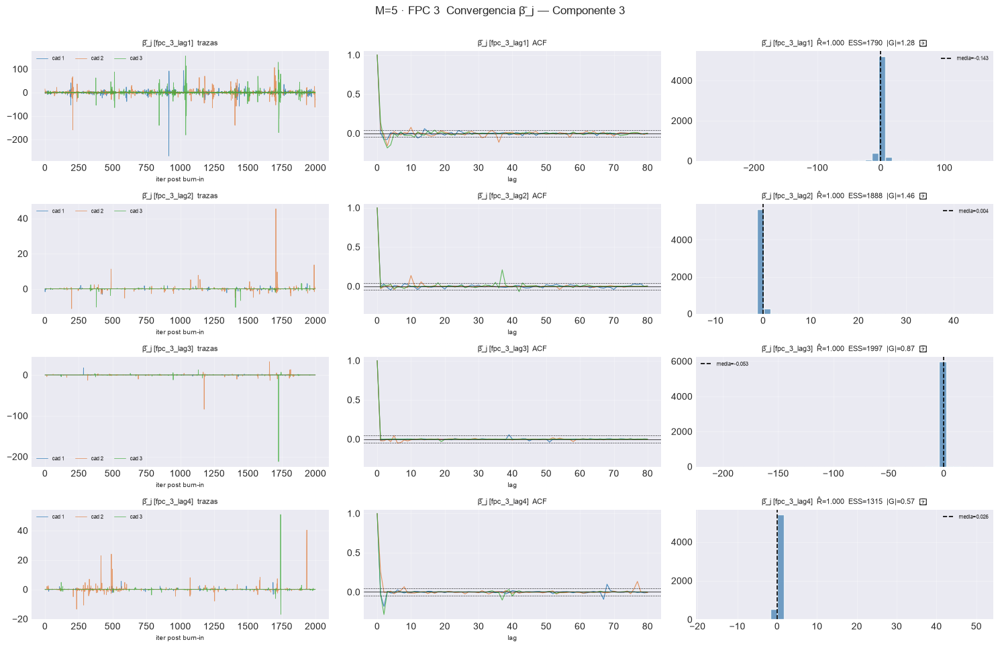

[plot_convergence_pj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=1.025  ess_min=32  |G|=2.08  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_3_lag2  rhat=1.010  ess_min=151  |G|=2.58  ✗
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_3_lag3  rhat=1.018  ess_min=115  |G|=1.75  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_3_lag4  rhat=1.065  ess_min=25  |G|=0.98  ✗
[plot_convergence_pj[FPC 3]] listo: 4 pasos en 3.5s  3/4 sin converger


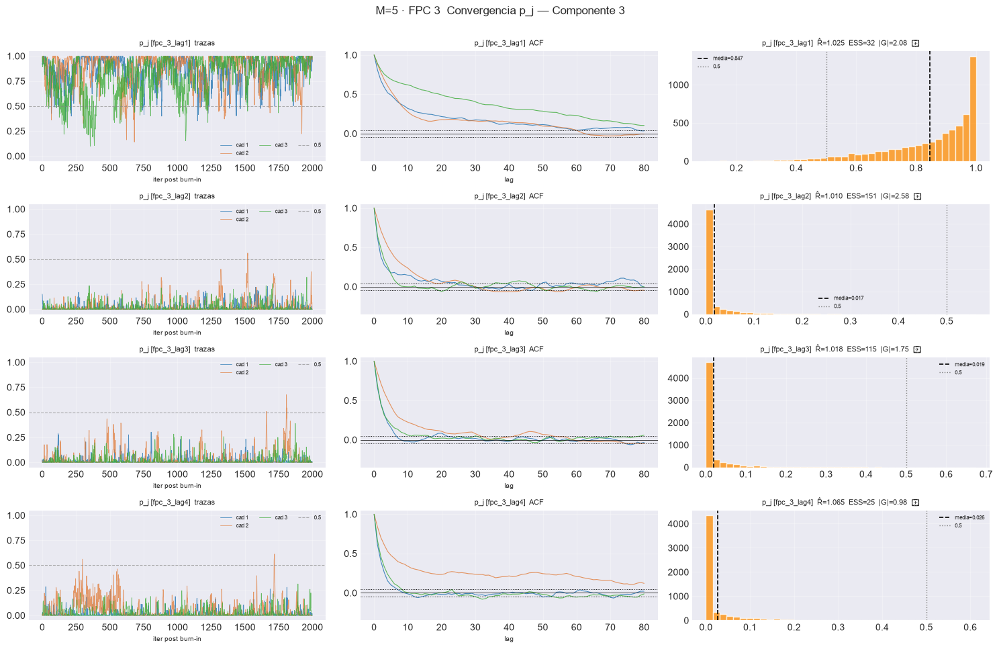

[plot_convergence_bj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_4_lag1  rhat=1.000  ess_min=1062  |G|=1.33  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_4_lag2  rhat=1.000  ess_min=1243  |G|=1.50  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_4_lag3  rhat=1.000  ess_min=1233  |G|=0.97  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_4_lag4  rhat=1.000  ess_min=1722  |G|=1.97  ✓
[plot_convergence_bj[FPC 4]] listo: 4 pasos en 3.1s  0/4 sin converger


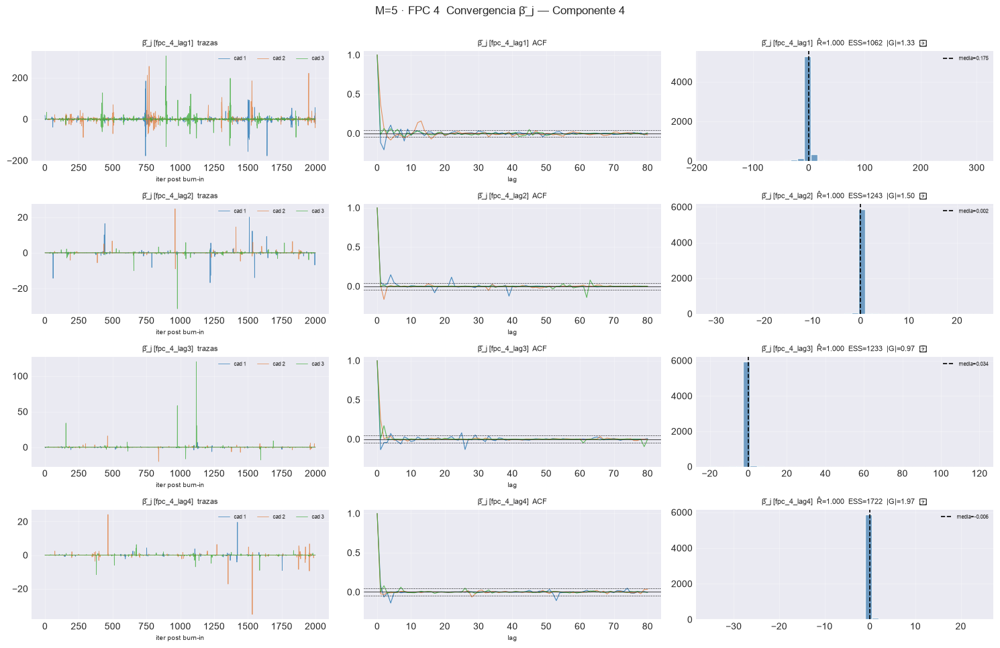

[plot_convergence_pj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=1.070  ess_min=10  |G|=7.40  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_4_lag2  rhat=1.001  ess_min=207  |G|=1.21  ✓
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_4_lag3  rhat=1.002  ess_min=177  |G|=0.80  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_4_lag4  rhat=1.003  ess_min=208  |G|=1.74  ✓
[plot_convergence_pj[FPC 4]] listo: 4 pasos en 3.6s  1/4 sin converger


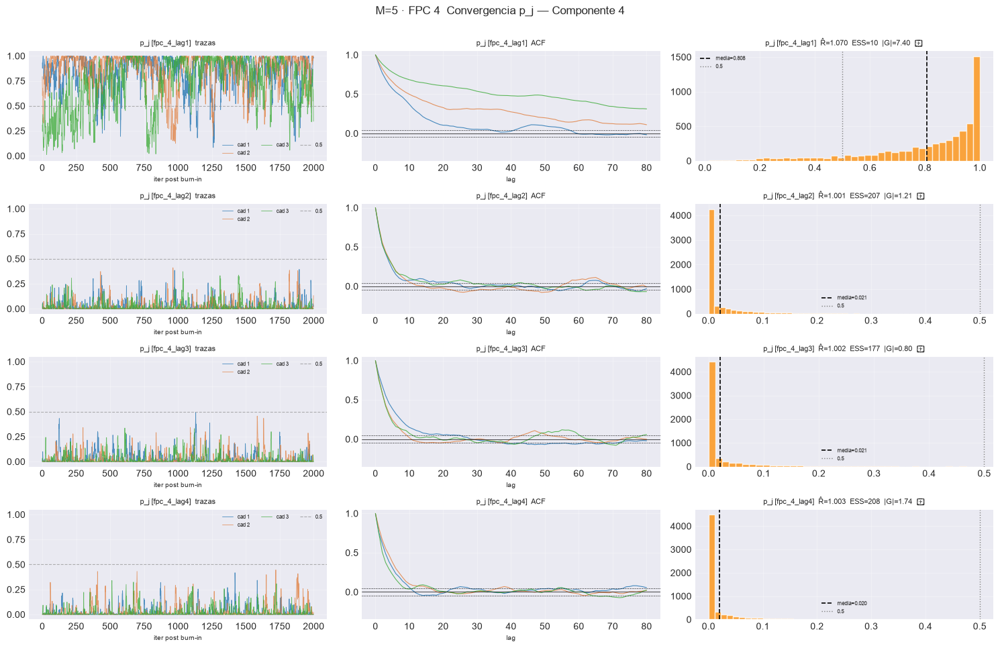

[plot_convergence_bj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_5_lag1  rhat=1.000  ess_min=1001  |G|=1.78  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_5_lag2  rhat=1.000  ess_min=1924  |G|=1.22  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_5_lag3  rhat=1.000  ess_min=1630  |G|=1.71  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_5_lag4  rhat=1.000  ess_min=2000  |G|=1.72  ✓
[plot_convergence_bj[FPC 5]] listo: 4 pasos en 3.8s  0/4 sin converger


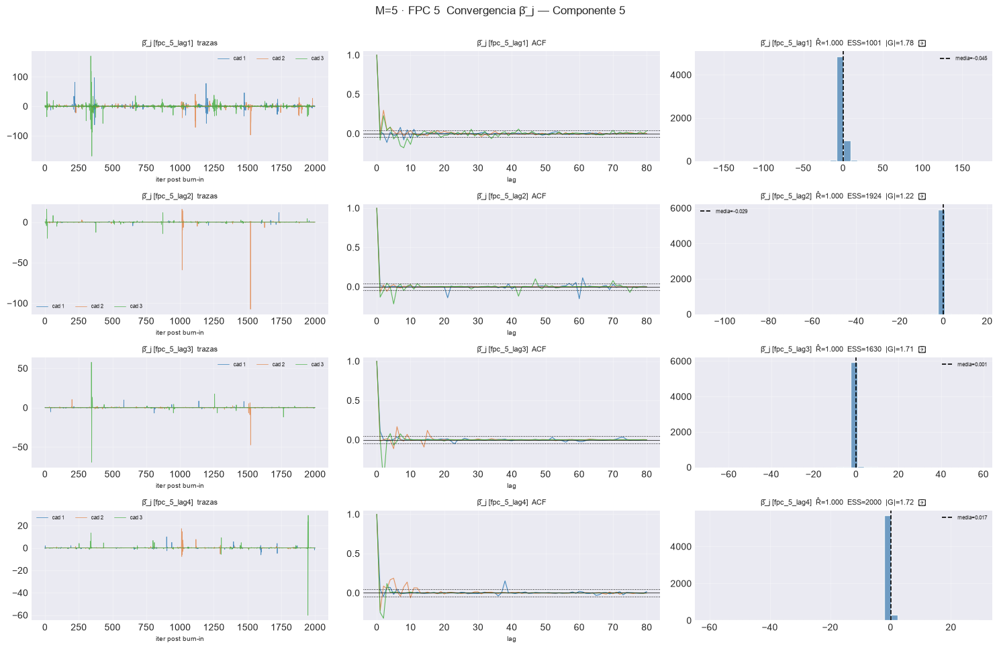

[plot_convergence_pj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_5_lag1  rhat=1.029  ess_min=45  |G|=1.74  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_5_lag2  rhat=1.002  ess_min=187  |G|=0.90  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_5_lag3  rhat=1.003  ess_min=156  |G|=2.48  ✗
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_5_lag4  rhat=1.001  ess_min=106  |G|=2.62  ✗
[plot_convergence_pj[FPC 5]] listo: 4 pasos en 3.5s  3/4 sin converger


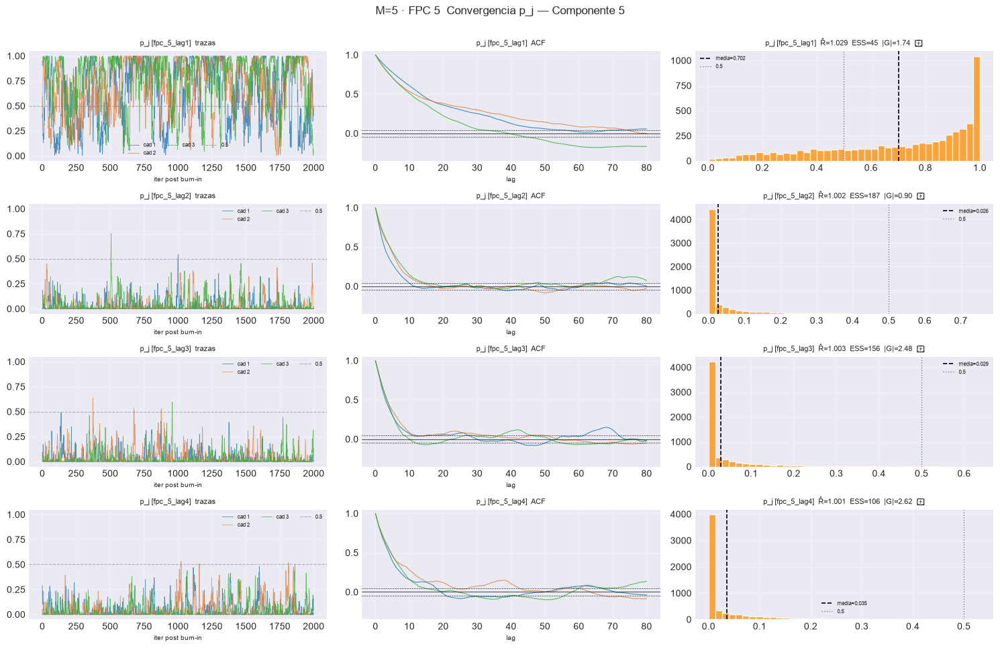

== M=6 ==============================================
[plot_convergence_bj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_1_lag1  rhat=1.000  ess_min=1933  |G|=1.16  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_1_lag2  rhat=1.000  ess_min=1619  |G|=2.05  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_1_lag3  rhat=1.000  ess_min=1859  |G|=1.27  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_1_lag4  rhat=1.000  ess_min=1870  |G|=0.65  ✓
[plot_convergence_bj[FPC 1]] listo: 4 pasos en 3.2s  1/4 sin converger


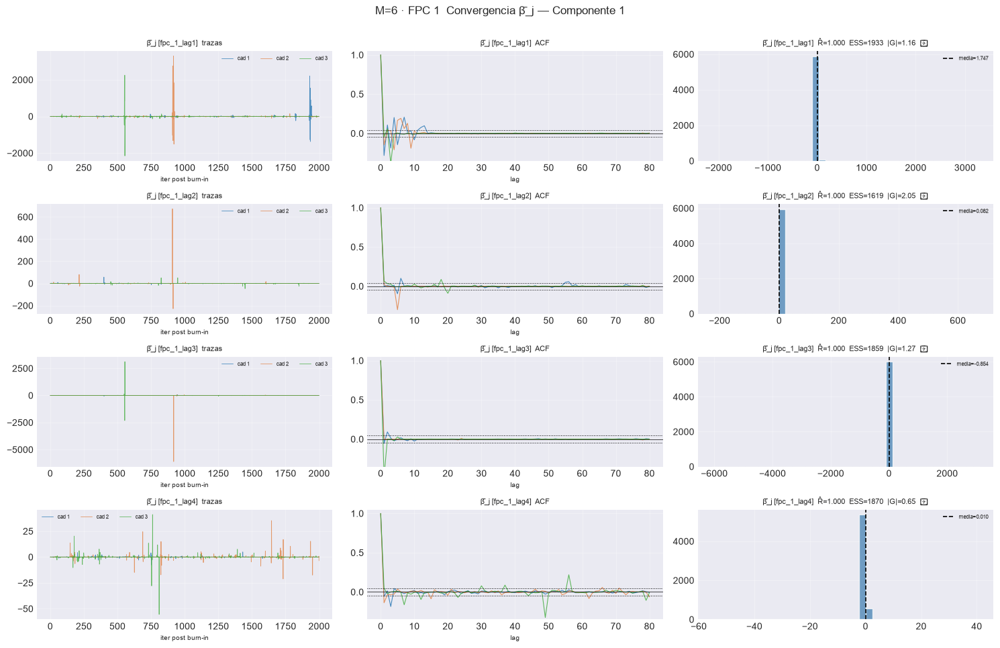

[plot_convergence_pj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_1_lag1  rhat=1.004  ess_min=19  |G|=3.19  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_1_lag2  rhat=1.000  ess_min=19  |G|=6.04  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_1_lag3  rhat=1.007  ess_min=148  |G|=3.75  ✗
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_1_lag4  rhat=1.016  ess_min=125  |G|=0.74  ✓
[plot_convergence_pj[FPC 1]] listo: 4 pasos en 3.7s  3/4 sin converger


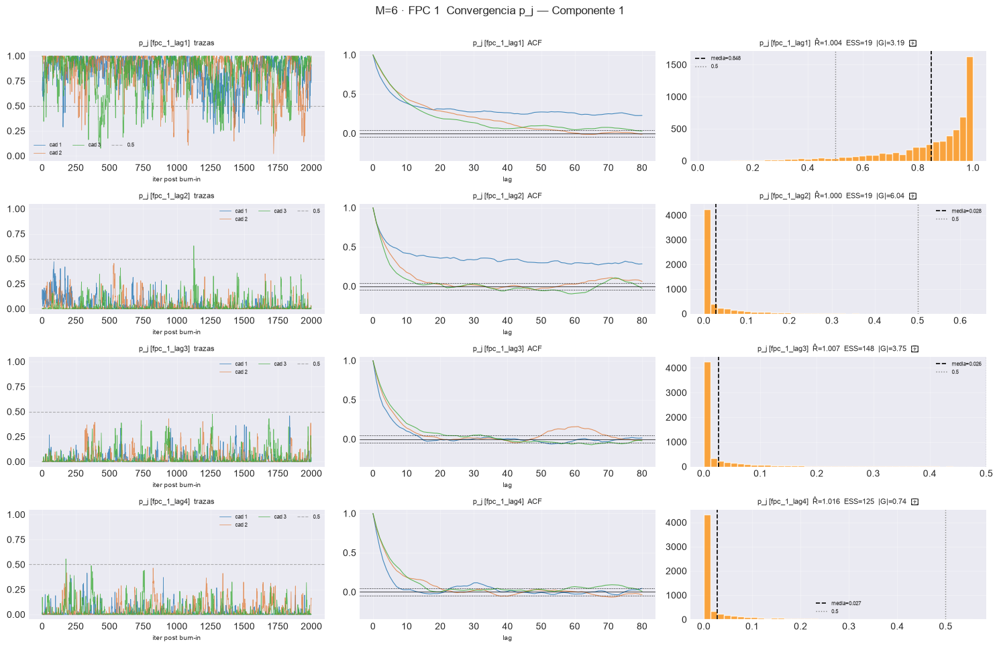

[plot_convergence_bj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.2s eta=0.7s  fpc_2_lag1  rhat=1.000  ess_min=680  |G|=2.27  ✗
  2/4 (50.0%) t=0.4s eta=0.4s  fpc_2_lag2  rhat=1.000  ess_min=1706  |G|=1.29  ✓
  3/4 (75.0%) t=0.6s eta=0.2s  fpc_2_lag3  rhat=1.000  ess_min=1701  |G|=0.99  ✓
  4/4 (100.0%) t=0.9s eta=0.0s  fpc_2_lag4  rhat=1.000  ess_min=980  |G|=1.33  ✓
[plot_convergence_bj[FPC 2]] listo: 4 pasos en 7.7s  1/4 sin converger


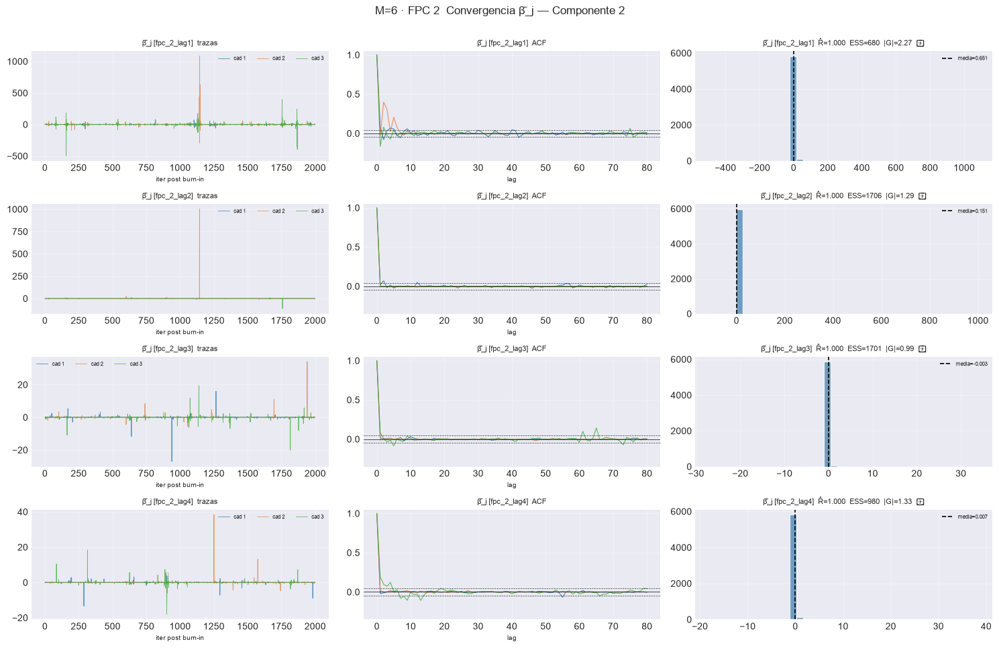

[plot_convergence_pj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.2s eta=0.5s  fpc_2_lag1  rhat=1.077  ess_min=30  |G|=8.49  ✗
  2/4 (50.0%) t=0.4s eta=0.4s  fpc_2_lag2  rhat=1.002  ess_min=221  |G|=1.44  ✓
  3/4 (75.0%) t=0.6s eta=0.2s  fpc_2_lag3  rhat=1.005  ess_min=248  |G|=1.40  ✓
  4/4 (100.0%) t=0.7s eta=0.0s  fpc_2_lag4  rhat=1.006  ess_min=177  |G|=0.77  ✓
[plot_convergence_pj[FPC 2]] listo: 4 pasos en 8.7s  1/4 sin converger


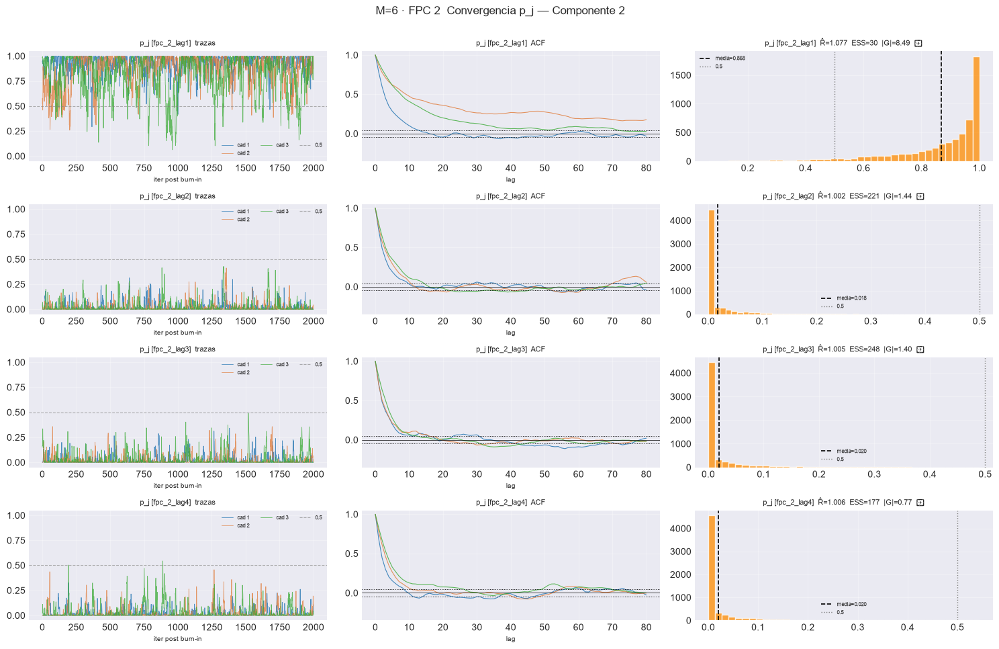

[plot_convergence_bj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.2s eta=0.5s  fpc_3_lag1  rhat=1.000  ess_min=1790  |G|=1.28  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_3_lag2  rhat=1.000  ess_min=1888  |G|=1.46  ✓
  3/4 (75.0%) t=0.4s eta=0.1s  fpc_3_lag3  rhat=1.000  ess_min=1997  |G|=0.87  ✓
  4/4 (100.0%) t=0.5s eta=0.0s  fpc_3_lag4  rhat=1.000  ess_min=1315  |G|=0.57  ✓
[plot_convergence_bj[FPC 3]] listo: 4 pasos en 4.2s  0/4 sin converger


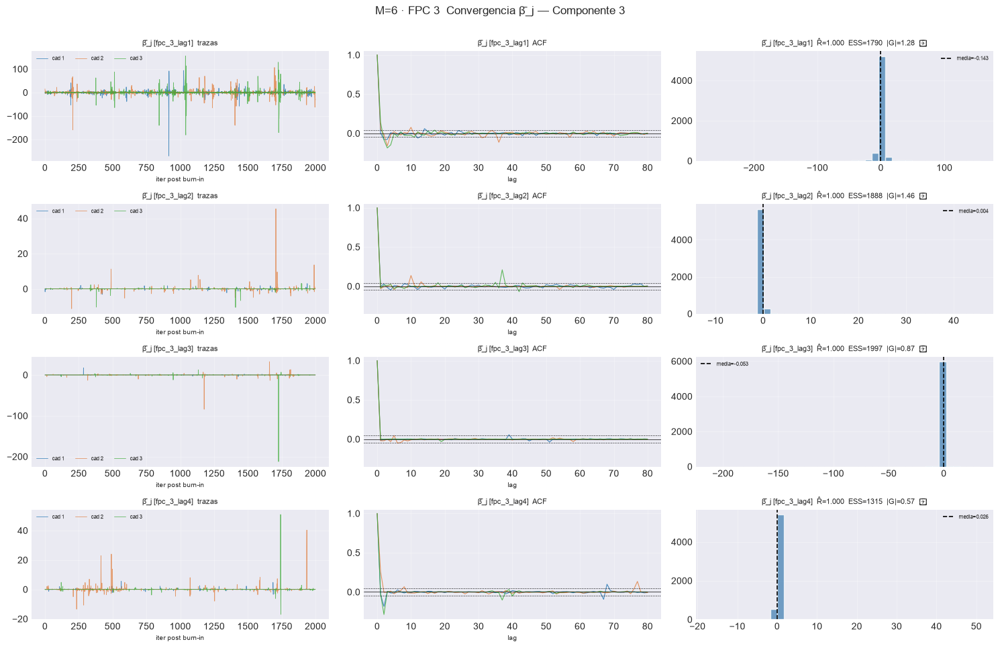

[plot_convergence_pj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=1.025  ess_min=32  |G|=2.08  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.010  ess_min=151  |G|=2.58  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_3_lag3  rhat=1.018  ess_min=115  |G|=1.75  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_3_lag4  rhat=1.065  ess_min=25  |G|=0.98  ✗
[plot_convergence_pj[FPC 3]] listo: 4 pasos en 4.9s  3/4 sin converger


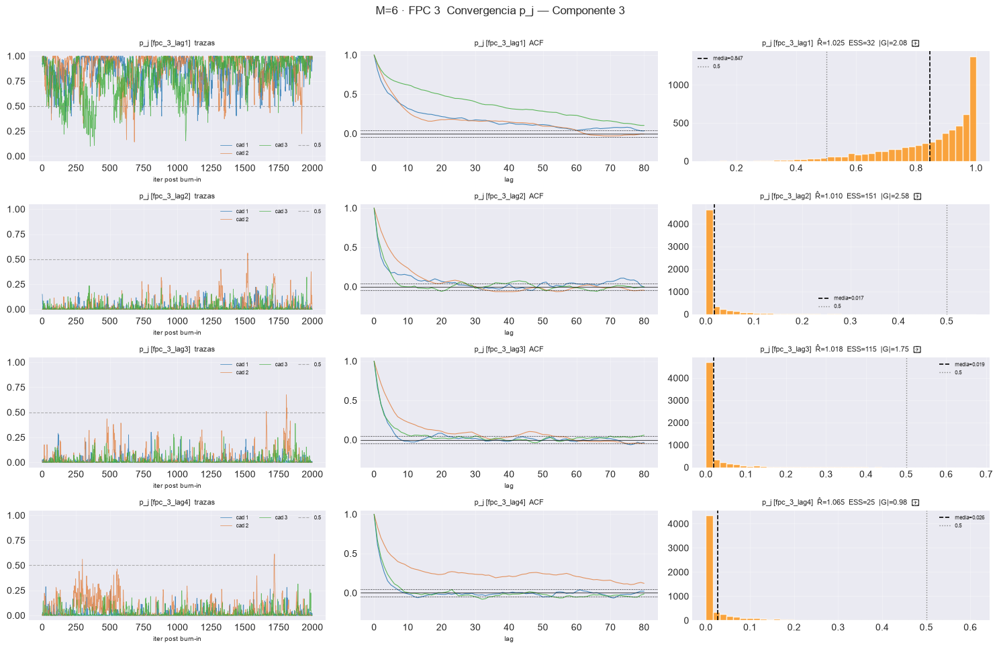

[plot_convergence_bj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=1.000  ess_min=1062  |G|=1.33  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_4_lag2  rhat=1.000  ess_min=1243  |G|=1.50  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_4_lag3  rhat=1.000  ess_min=1233  |G|=0.97  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_4_lag4  rhat=1.000  ess_min=1722  |G|=1.97  ✓
[plot_convergence_bj[FPC 4]] listo: 4 pasos en 3.3s  0/4 sin converger


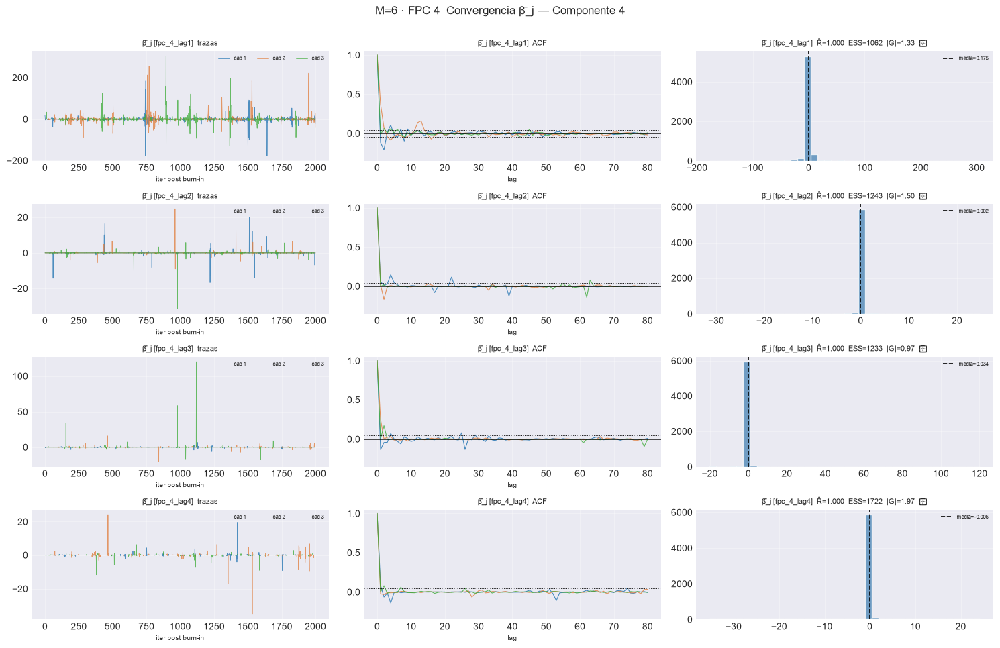

[plot_convergence_pj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_4_lag1  rhat=1.070  ess_min=10  |G|=7.40  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_4_lag2  rhat=1.001  ess_min=207  |G|=1.21  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_4_lag3  rhat=1.002  ess_min=177  |G|=0.80  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_4_lag4  rhat=1.003  ess_min=208  |G|=1.74  ✓
[plot_convergence_pj[FPC 4]] listo: 4 pasos en 4.4s  1/4 sin converger


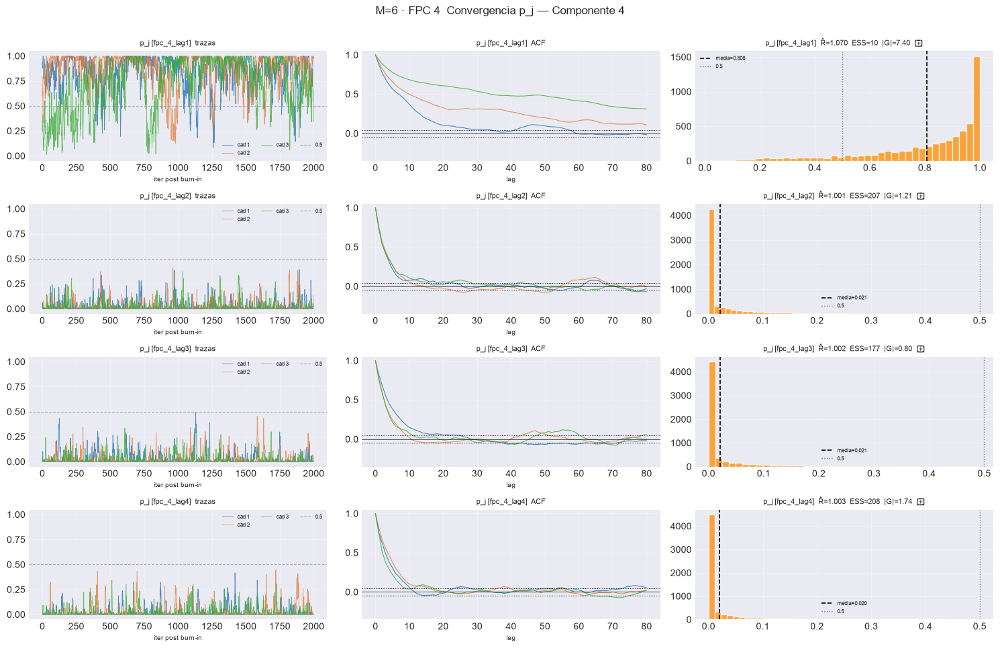

[plot_convergence_bj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_5_lag1  rhat=1.000  ess_min=1001  |G|=1.78  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_5_lag2  rhat=1.000  ess_min=1924  |G|=1.22  ✓
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_5_lag3  rhat=1.000  ess_min=1630  |G|=1.71  ✓
  4/4 (100.0%) t=0.5s eta=0.0s  fpc_5_lag4  rhat=1.000  ess_min=2000  |G|=1.72  ✓
[plot_convergence_bj[FPC 5]] listo: 4 pasos en 4.1s  0/4 sin converger


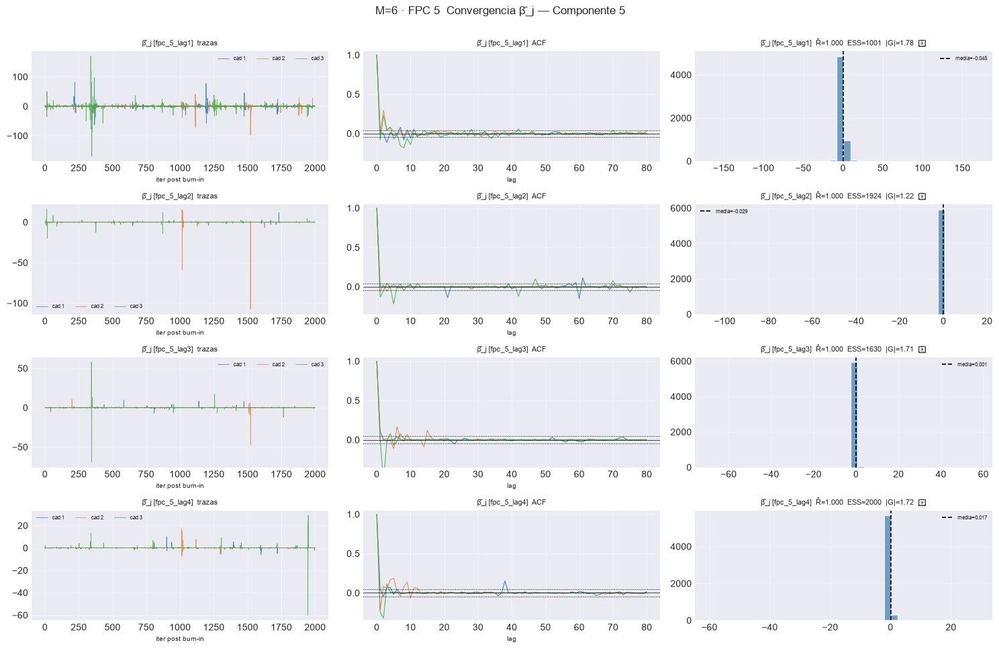

[plot_convergence_pj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_5_lag1  rhat=1.029  ess_min=45  |G|=1.74  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_5_lag2  rhat=1.002  ess_min=187  |G|=0.90  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_5_lag3  rhat=1.003  ess_min=156  |G|=2.48  ✗
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_5_lag4  rhat=1.001  ess_min=106  |G|=2.62  ✗
[plot_convergence_pj[FPC 5]] listo: 4 pasos en 4.2s  3/4 sin converger


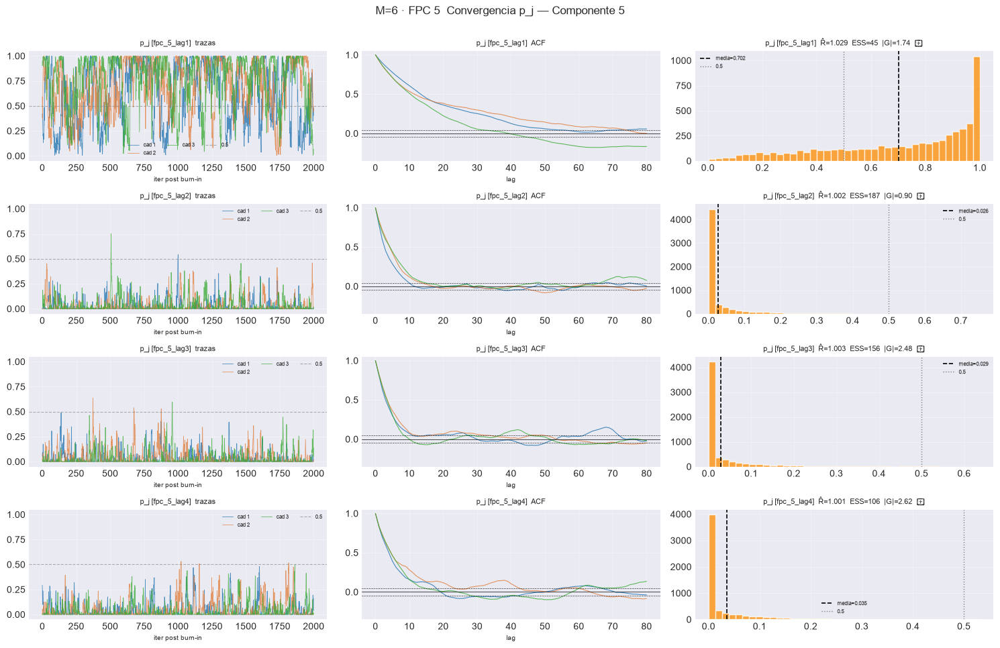

[plot_convergence_bj[FPC 6]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_6_lag1  rhat=1.000  ess_min=1272  |G|=1.06  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_6_lag2  rhat=1.000  ess_min=1289  |G|=1.42  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_6_lag3  rhat=1.000  ess_min=2000  |G|=1.16  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_6_lag4  rhat=1.000  ess_min=1359  |G|=1.36  ✓
[plot_convergence_bj[FPC 6]] listo: 4 pasos en 3.5s  0/4 sin converger


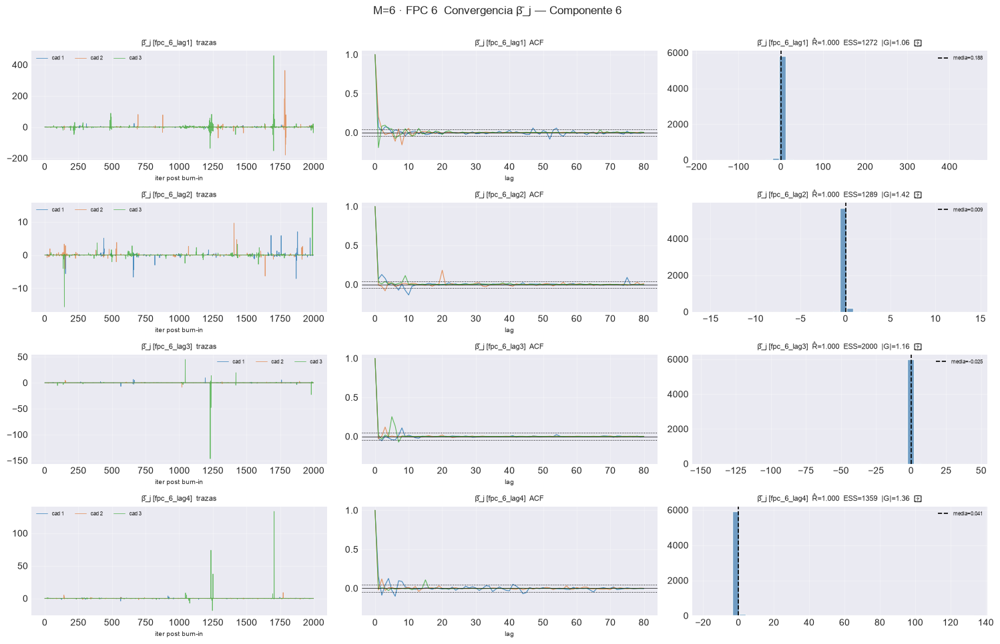

[plot_convergence_pj[FPC 6]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_6_lag1  rhat=1.113  ess_min=31  |G|=3.19  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_6_lag2  rhat=1.000  ess_min=70  |G|=3.05  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_6_lag3  rhat=1.000  ess_min=201  |G|=0.58  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_6_lag4  rhat=1.002  ess_min=190  |G|=1.19  ✓
[plot_convergence_pj[FPC 6]] listo: 4 pasos en 3.5s  2/4 sin converger


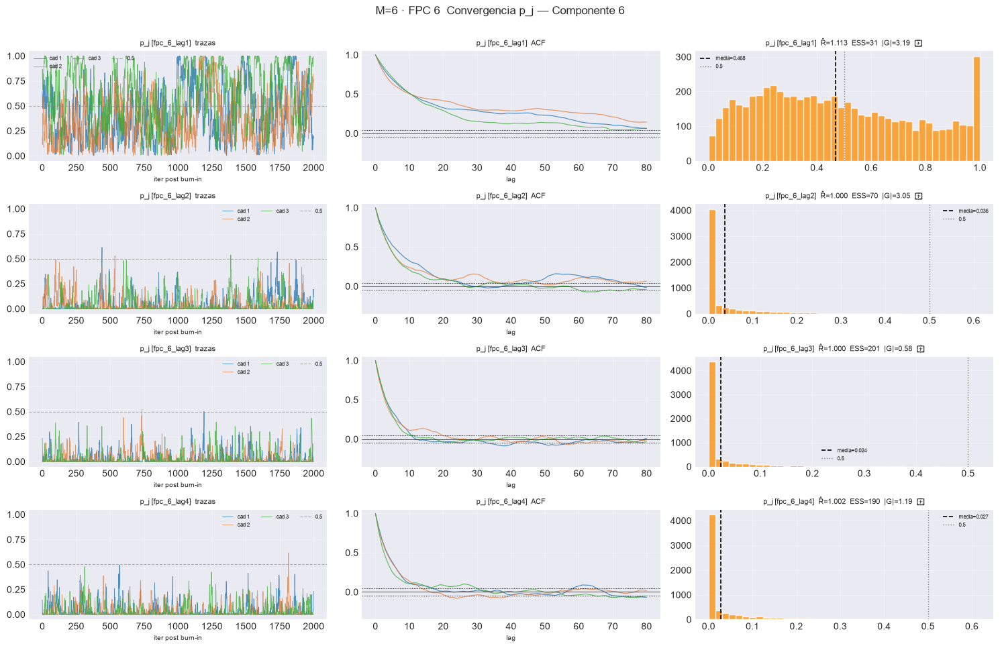

== M=7 ==============================================
[plot_convergence_bj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_1_lag1  rhat=1.000  ess_min=1933  |G|=1.16  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_1_lag2  rhat=1.000  ess_min=1619  |G|=2.05  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_1_lag3  rhat=1.000  ess_min=1859  |G|=1.27  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_1_lag4  rhat=1.000  ess_min=1870  |G|=0.65  ✓
[plot_convergence_bj[FPC 1]] listo: 4 pasos en 3.4s  1/4 sin converger


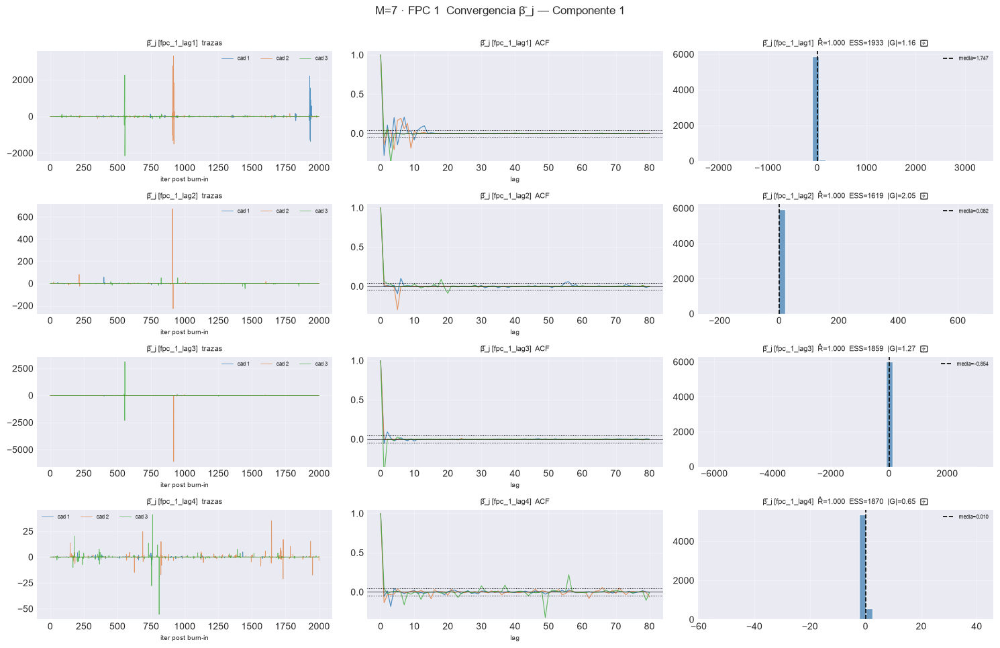

[plot_convergence_pj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_1_lag1  rhat=1.004  ess_min=19  |G|=3.19  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_1_lag2  rhat=1.000  ess_min=19  |G|=6.04  ✗
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_1_lag3  rhat=1.007  ess_min=148  |G|=3.75  ✗
  4/4 (100.0%) t=0.4s eta=0.0s  fpc_1_lag4  rhat=1.016  ess_min=125  |G|=0.74  ✓
[plot_convergence_pj[FPC 1]] listo: 4 pasos en 4.1s  3/4 sin converger


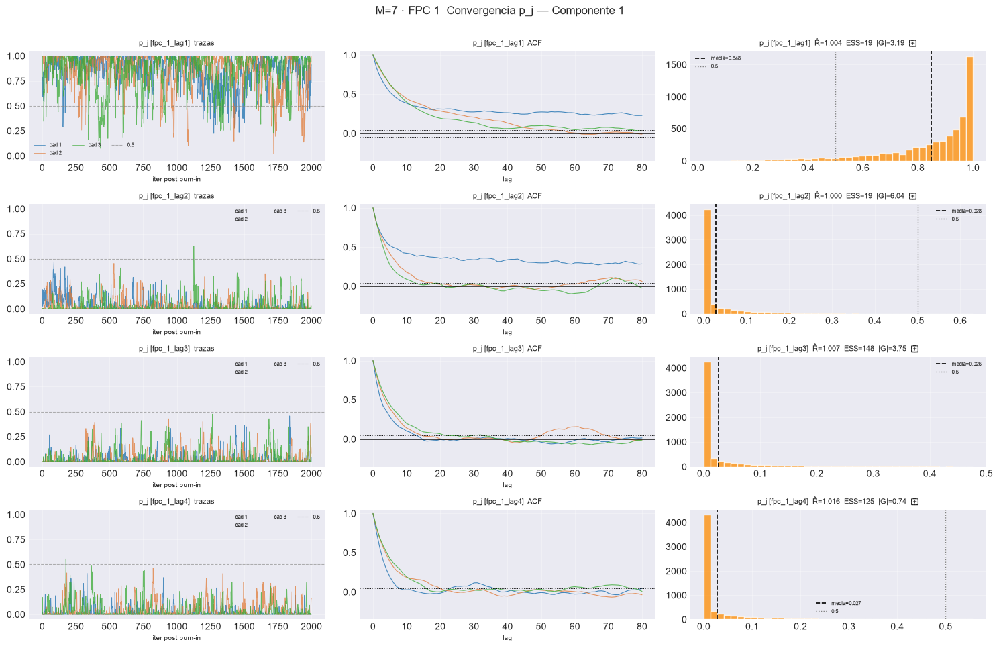

[plot_convergence_bj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.2s eta=0.6s  fpc_2_lag1  rhat=1.000  ess_min=680  |G|=2.27  ✗
  2/4 (50.0%) t=0.4s eta=0.4s  fpc_2_lag2  rhat=1.000  ess_min=1706  |G|=1.29  ✓
  3/4 (75.0%) t=0.5s eta=0.2s  fpc_2_lag3  rhat=1.000  ess_min=1701  |G|=0.99  ✓
  4/4 (100.0%) t=0.6s eta=0.0s  fpc_2_lag4  rhat=1.000  ess_min=980  |G|=1.33  ✓
[plot_convergence_bj[FPC 2]] listo: 4 pasos en 2.8s  1/4 sin converger


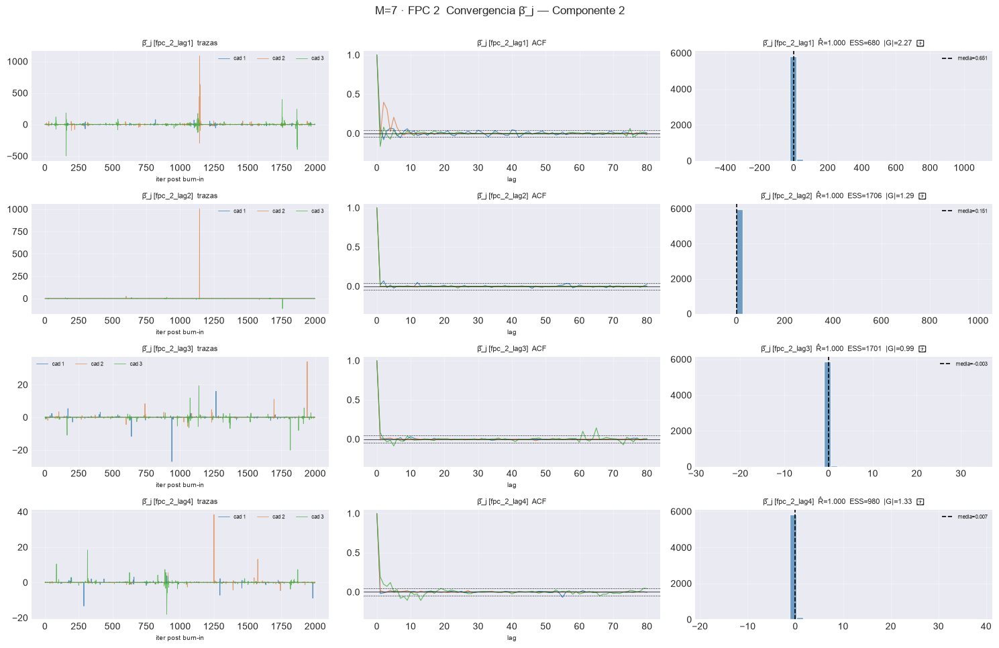

[plot_convergence_pj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=1.077  ess_min=30  |G|=8.49  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.002  ess_min=221  |G|=1.44  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_2_lag3  rhat=1.005  ess_min=248  |G|=1.40  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_2_lag4  rhat=1.006  ess_min=177  |G|=0.77  ✓
[plot_convergence_pj[FPC 2]] listo: 4 pasos en 2.9s  1/4 sin converger


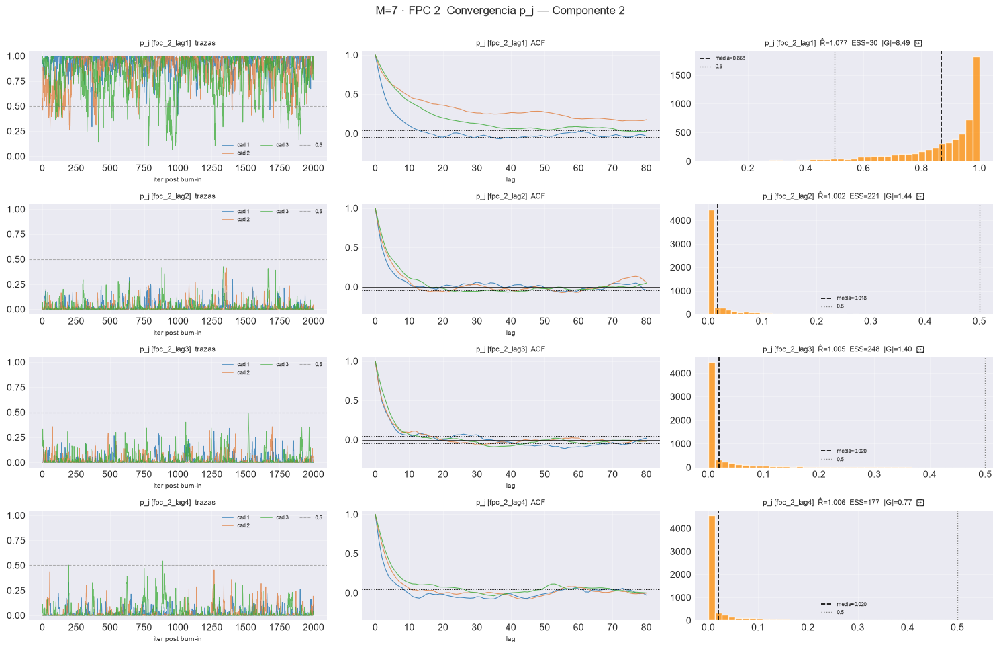

[plot_convergence_bj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=1.000  ess_min=1790  |G|=1.28  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.000  ess_min=1888  |G|=1.46  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_3_lag3  rhat=1.000  ess_min=1997  |G|=0.87  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_3_lag4  rhat=1.000  ess_min=1315  |G|=0.57  ✓
[plot_convergence_bj[FPC 3]] listo: 4 pasos en 2.4s  0/4 sin converger


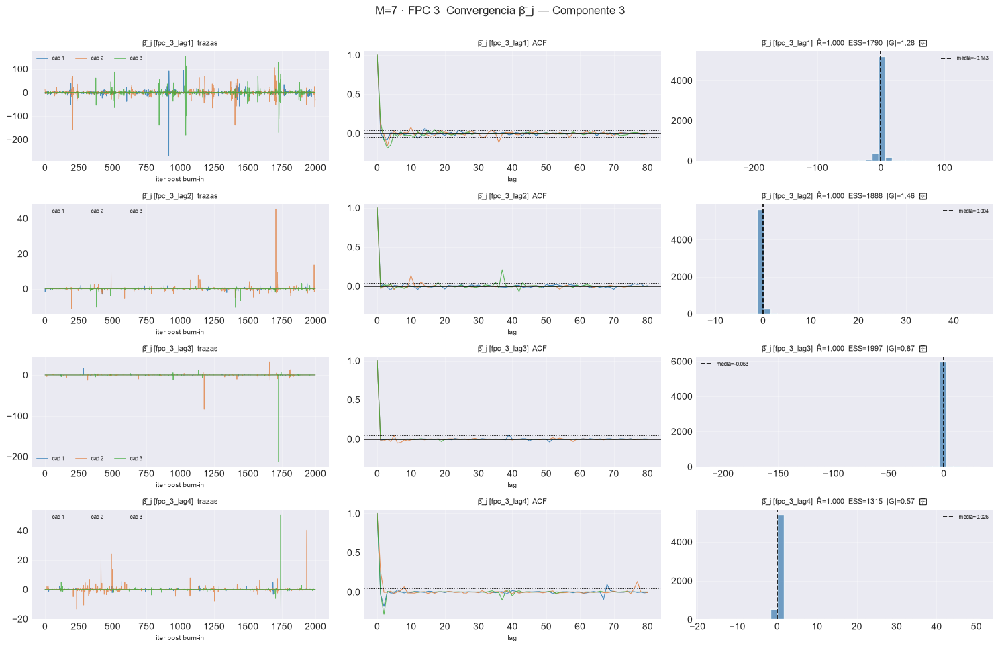

[plot_convergence_pj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_3_lag1  rhat=1.025  ess_min=32  |G|=2.08  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.010  ess_min=151  |G|=2.58  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_3_lag3  rhat=1.018  ess_min=115  |G|=1.75  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_3_lag4  rhat=1.065  ess_min=25  |G|=0.98  ✗
[plot_convergence_pj[FPC 3]] listo: 4 pasos en 2.5s  3/4 sin converger


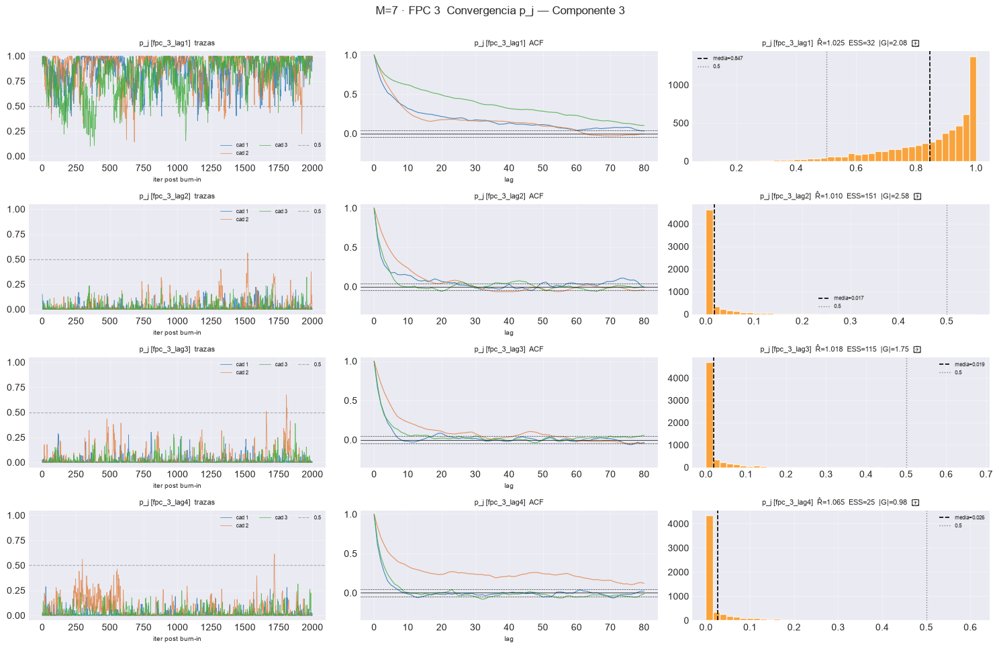

[plot_convergence_bj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=1.000  ess_min=1062  |G|=1.33  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_4_lag2  rhat=1.000  ess_min=1243  |G|=1.50  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_4_lag3  rhat=1.000  ess_min=1233  |G|=0.97  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_4_lag4  rhat=1.000  ess_min=1722  |G|=1.97  ✓
[plot_convergence_bj[FPC 4]] listo: 4 pasos en 2.9s  0/4 sin converger


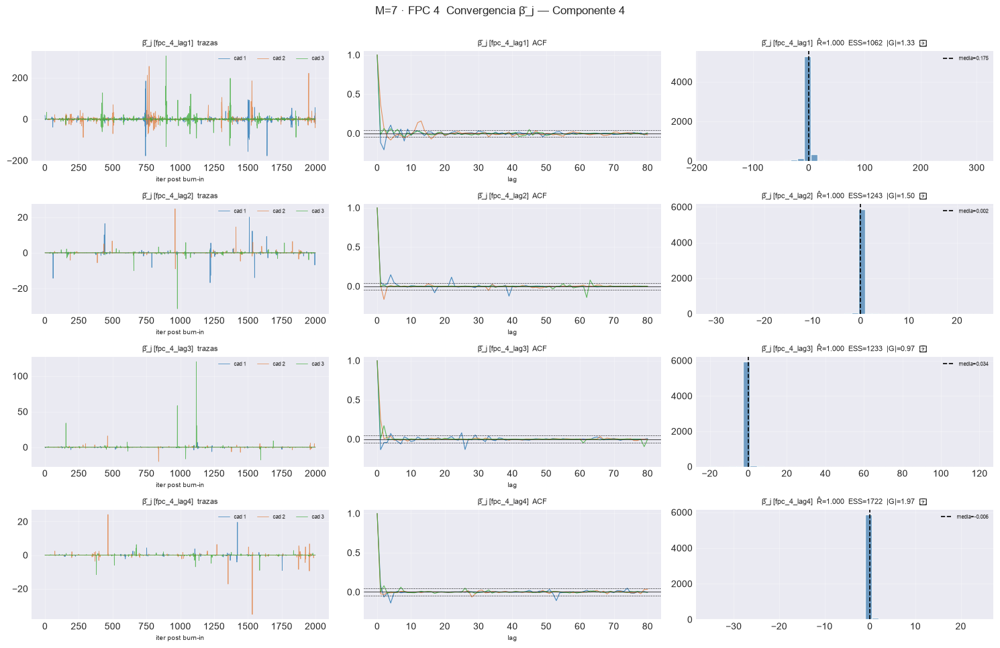

[plot_convergence_pj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=1.070  ess_min=10  |G|=7.40  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_4_lag2  rhat=1.001  ess_min=207  |G|=1.21  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_4_lag3  rhat=1.002  ess_min=177  |G|=0.80  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_4_lag4  rhat=1.003  ess_min=208  |G|=1.74  ✓
[plot_convergence_pj[FPC 4]] listo: 4 pasos en 2.9s  1/4 sin converger


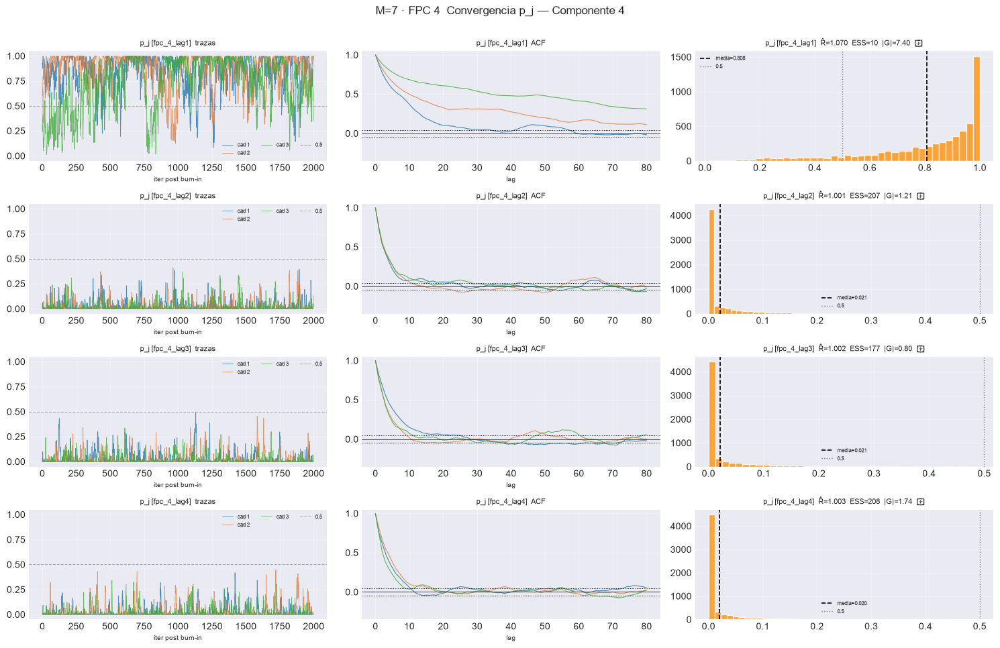

[plot_convergence_bj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_5_lag1  rhat=1.000  ess_min=1001  |G|=1.78  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_5_lag2  rhat=1.000  ess_min=1924  |G|=1.22  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_5_lag3  rhat=1.000  ess_min=1630  |G|=1.71  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_5_lag4  rhat=1.000  ess_min=2000  |G|=1.72  ✓
[plot_convergence_bj[FPC 5]] listo: 4 pasos en 2.4s  0/4 sin converger


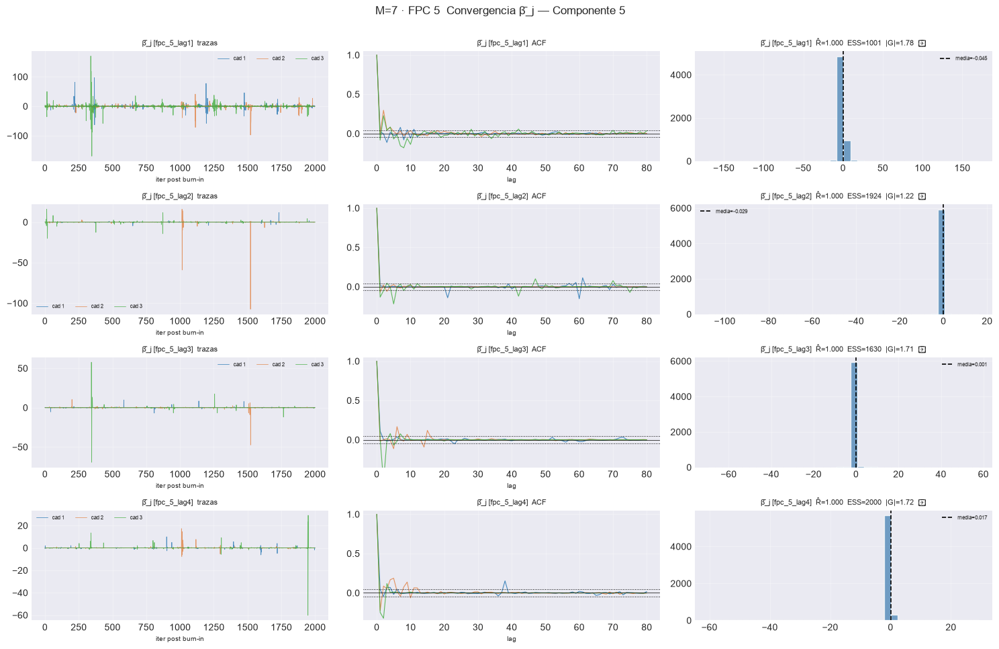

[plot_convergence_pj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_5_lag1  rhat=1.029  ess_min=45  |G|=1.74  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_5_lag2  rhat=1.002  ess_min=187  |G|=0.90  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_5_lag3  rhat=1.003  ess_min=156  |G|=2.48  ✗
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_5_lag4  rhat=1.001  ess_min=106  |G|=2.62  ✗
[plot_convergence_pj[FPC 5]] listo: 4 pasos en 2.3s  3/4 sin converger


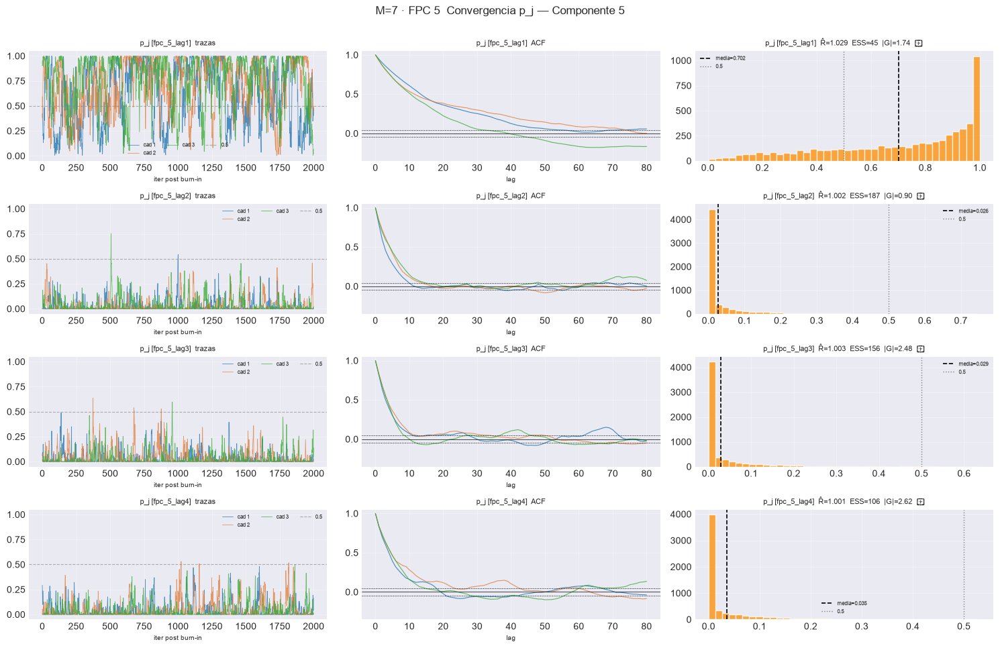

[plot_convergence_bj[FPC 6]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_6_lag1  rhat=1.000  ess_min=1272  |G|=1.06  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_6_lag2  rhat=1.000  ess_min=1289  |G|=1.42  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_6_lag3  rhat=1.000  ess_min=2000  |G|=1.16  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_6_lag4  rhat=1.000  ess_min=1359  |G|=1.36  ✓
[plot_convergence_bj[FPC 6]] listo: 4 pasos en 2.2s  0/4 sin converger


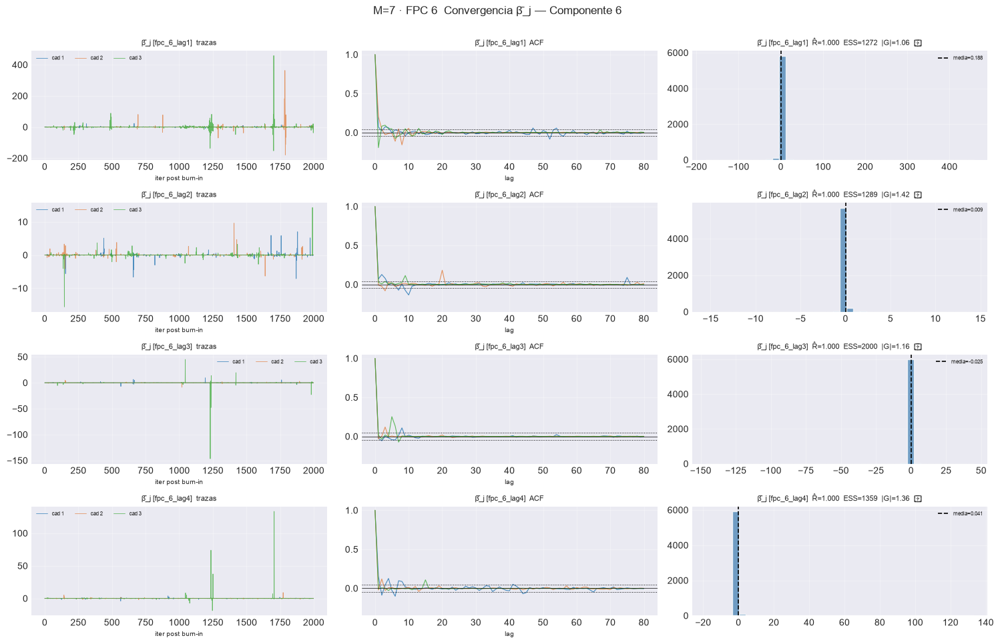

[plot_convergence_pj[FPC 6]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_6_lag1  rhat=1.113  ess_min=31  |G|=3.19  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_6_lag2  rhat=1.000  ess_min=70  |G|=3.05  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_6_lag3  rhat=1.000  ess_min=201  |G|=0.58  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_6_lag4  rhat=1.002  ess_min=190  |G|=1.19  ✓
[plot_convergence_pj[FPC 6]] listo: 4 pasos en 2.7s  2/4 sin converger


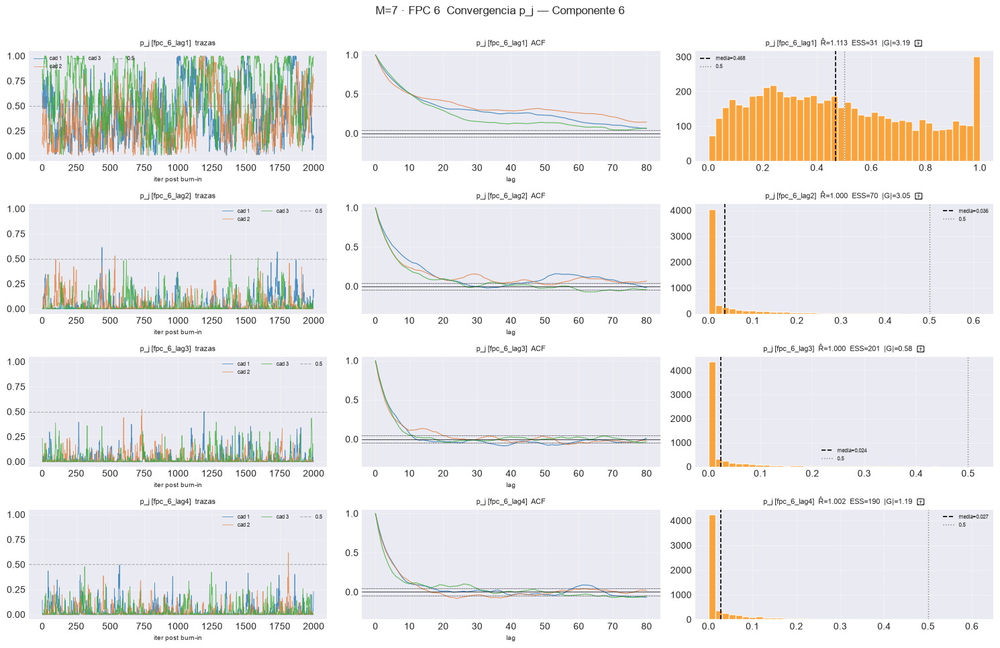

[plot_convergence_bj[FPC 7]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_7_lag1  rhat=1.000  ess_min=1368  |G|=0.46  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_7_lag2  rhat=1.000  ess_min=1639  |G|=1.10  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_7_lag3  rhat=1.000  ess_min=1789  |G|=0.90  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_7_lag4  rhat=1.000  ess_min=1585  |G|=1.62  ✓
[plot_convergence_bj[FPC 7]] listo: 4 pasos en 2.4s  0/4 sin converger


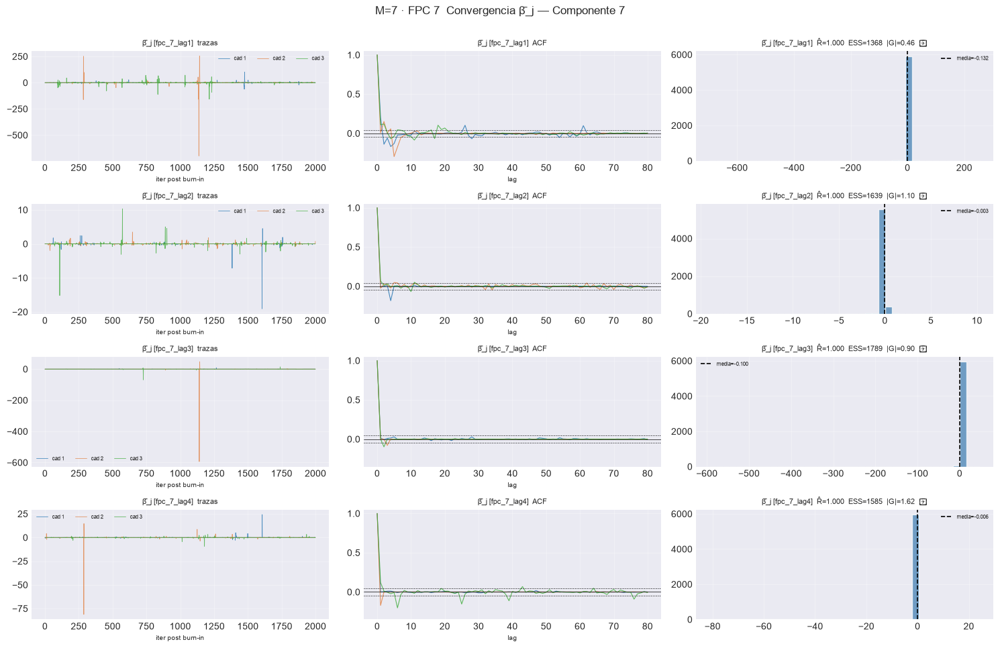

[plot_convergence_pj[FPC 7]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_7_lag1  rhat=1.184  ess_min=20  |G|=4.21  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_7_lag2  rhat=1.010  ess_min=170  |G|=0.79  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_7_lag3  rhat=1.006  ess_min=188  |G|=1.34  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_7_lag4  rhat=1.008  ess_min=248  |G|=0.91  ✓
[plot_convergence_pj[FPC 7]] listo: 4 pasos en 3.5s  1/4 sin converger


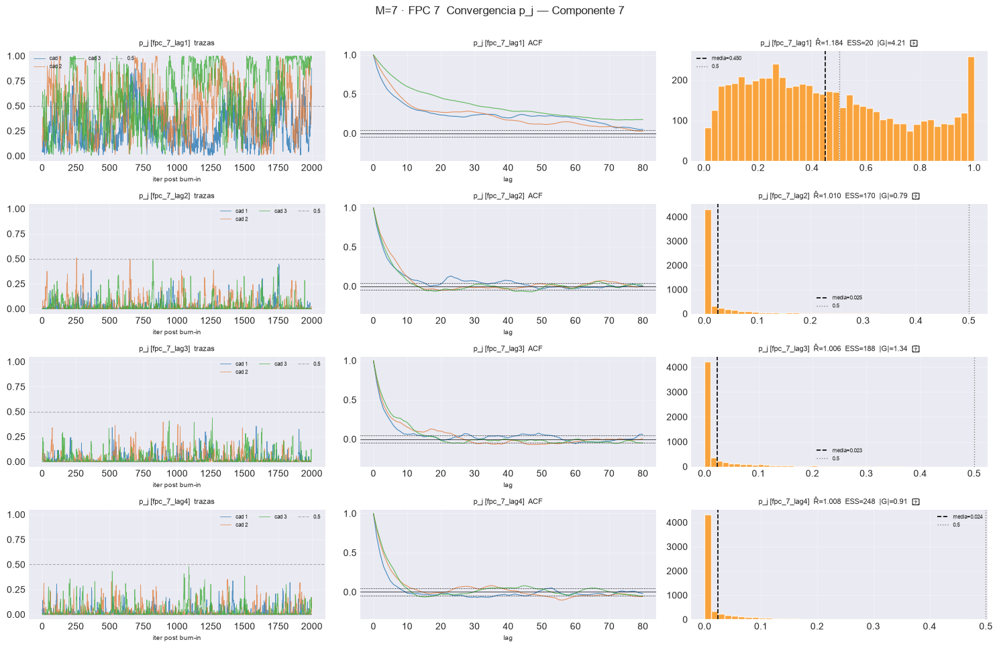

== M=8 ==============================================
[plot_convergence_bj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_1_lag1  rhat=1.000  ess_min=1933  |G|=1.16  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_1_lag2  rhat=1.000  ess_min=1619  |G|=2.05  ✗
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_1_lag3  rhat=1.000  ess_min=1859  |G|=1.27  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_1_lag4  rhat=1.000  ess_min=1870  |G|=0.65  ✓
[plot_convergence_bj[FPC 1]] listo: 4 pasos en 3.5s  1/4 sin converger


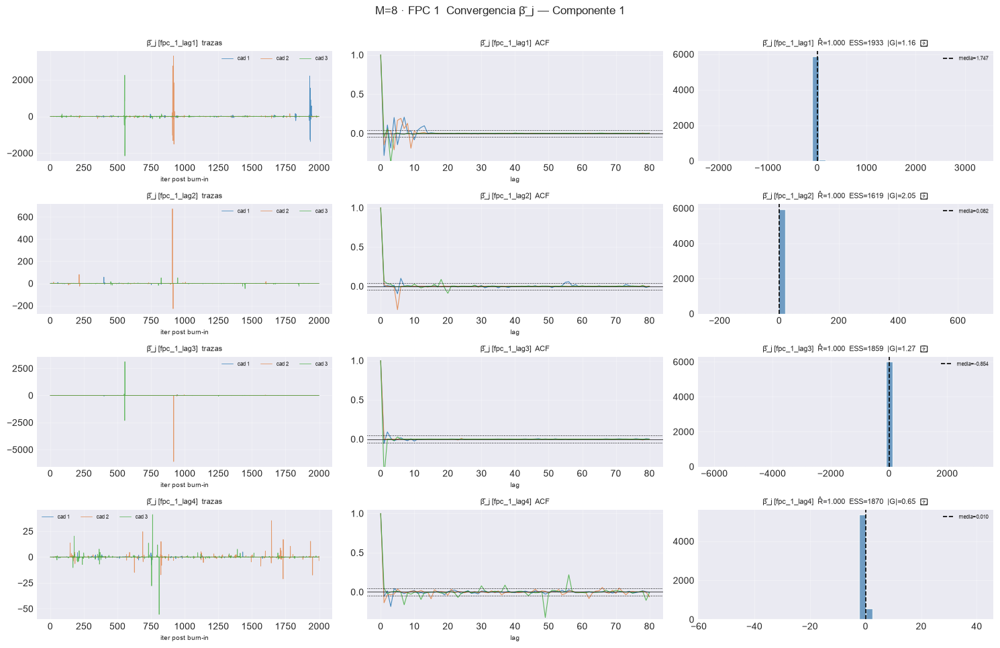

[plot_convergence_pj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_1_lag1  rhat=1.004  ess_min=19  |G|=3.19  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_1_lag2  rhat=1.000  ess_min=19  |G|=6.04  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_1_lag3  rhat=1.007  ess_min=148  |G|=3.75  ✗
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_1_lag4  rhat=1.016  ess_min=125  |G|=0.74  ✓
[plot_convergence_pj[FPC 1]] listo: 4 pasos en 2.5s  3/4 sin converger


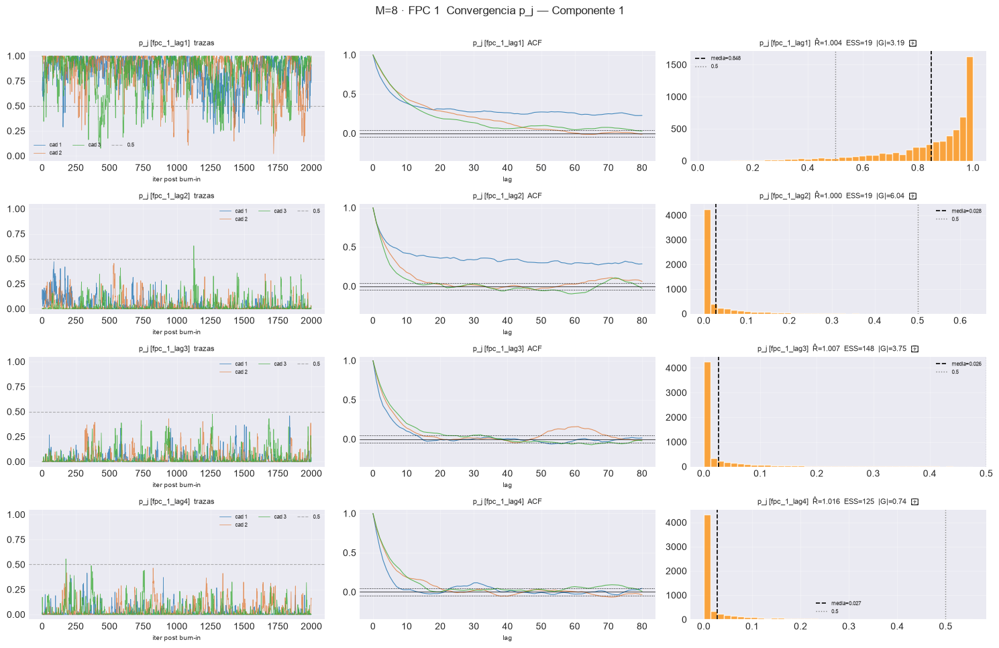

[plot_convergence_bj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=1.000  ess_min=680  |G|=2.27  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.000  ess_min=1706  |G|=1.29  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_2_lag3  rhat=1.000  ess_min=1701  |G|=0.99  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_2_lag4  rhat=1.000  ess_min=980  |G|=1.33  ✓
[plot_convergence_bj[FPC 2]] listo: 4 pasos en 2.9s  1/4 sin converger


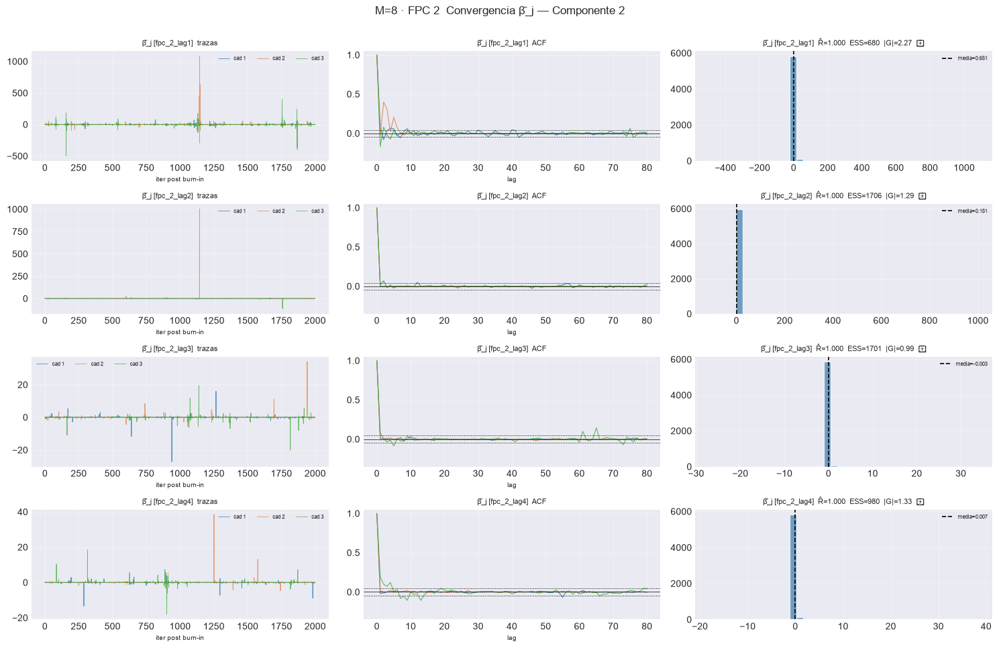

[plot_convergence_pj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=1.077  ess_min=30  |G|=8.49  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.002  ess_min=221  |G|=1.44  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_2_lag3  rhat=1.005  ess_min=248  |G|=1.40  ✓
  4/4 (100.0%) t=0.1s eta=0.0s  fpc_2_lag4  rhat=1.006  ess_min=177  |G|=0.77  ✓
[plot_convergence_pj[FPC 2]] listo: 4 pasos en 2.0s  1/4 sin converger


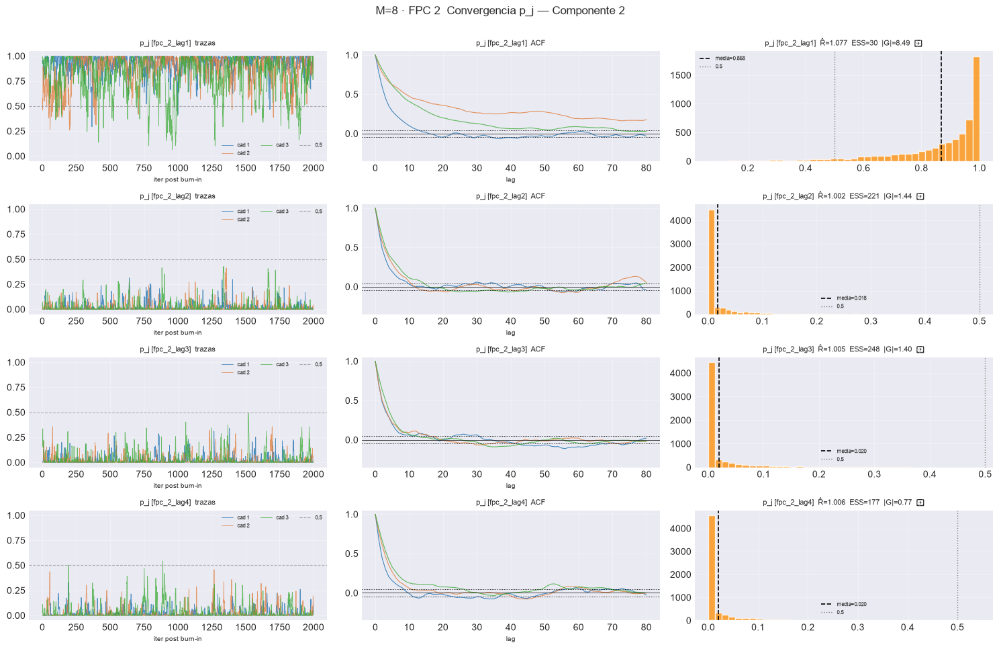

[plot_convergence_bj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_3_lag1  rhat=1.000  ess_min=1790  |G|=1.28  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.000  ess_min=1888  |G|=1.46  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_3_lag3  rhat=1.000  ess_min=1997  |G|=0.87  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_3_lag4  rhat=1.000  ess_min=1315  |G|=0.57  ✓
[plot_convergence_bj[FPC 3]] listo: 4 pasos en 2.0s  0/4 sin converger


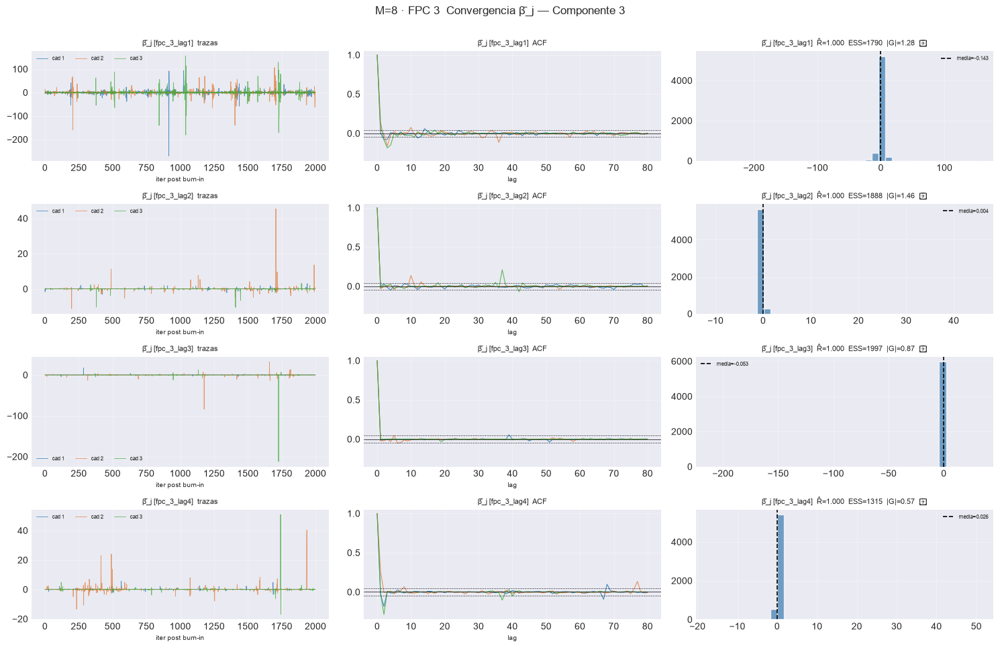

[plot_convergence_pj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_3_lag1  rhat=1.025  ess_min=32  |G|=2.08  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.010  ess_min=151  |G|=2.58  ✗
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag3  rhat=1.018  ess_min=115  |G|=1.75  ✓
  4/4 (100.0%) t=0.1s eta=0.0s  fpc_3_lag4  rhat=1.065  ess_min=25  |G|=0.98  ✗
[plot_convergence_pj[FPC 3]] listo: 4 pasos en 2.1s  3/4 sin converger


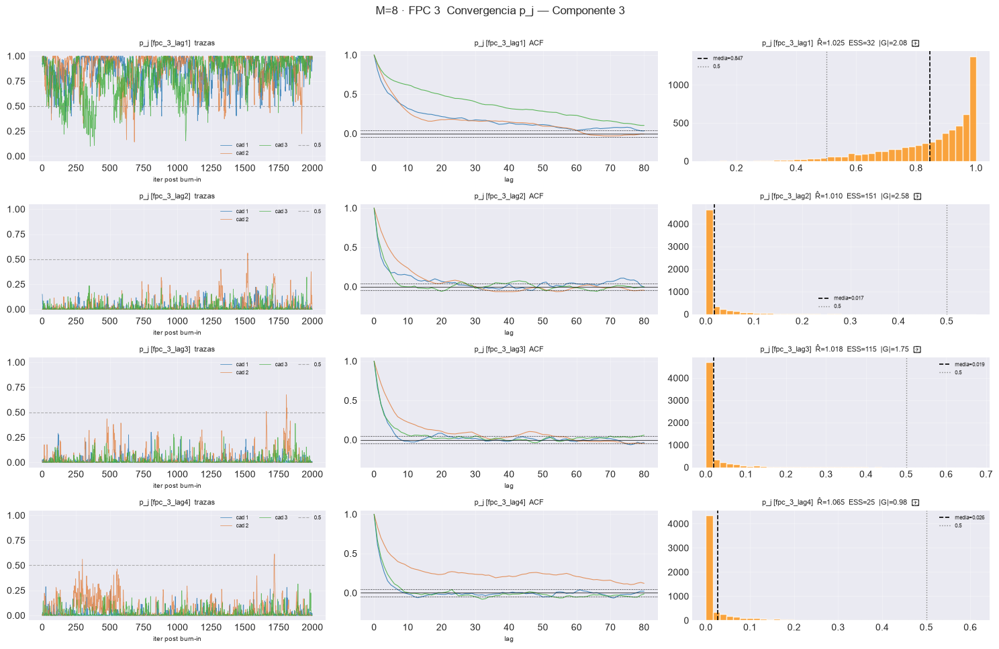

[plot_convergence_bj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_4_lag1  rhat=1.000  ess_min=1062  |G|=1.33  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_4_lag2  rhat=1.000  ess_min=1243  |G|=1.50  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_4_lag3  rhat=1.000  ess_min=1233  |G|=0.97  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_4_lag4  rhat=1.000  ess_min=1722  |G|=1.97  ✓
[plot_convergence_bj[FPC 4]] listo: 4 pasos en 2.0s  0/4 sin converger


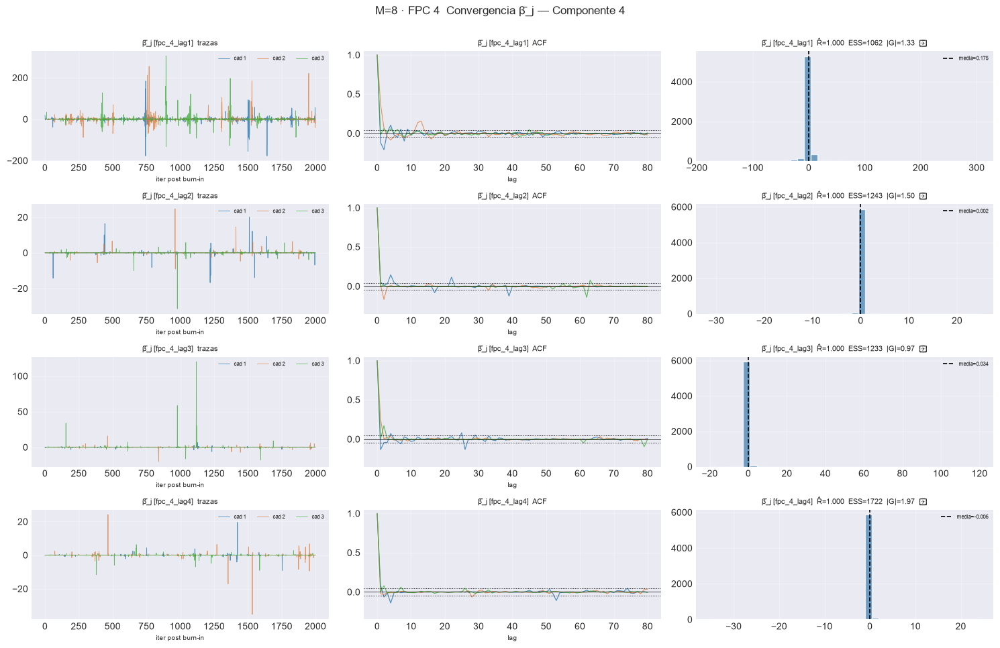

[plot_convergence_pj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_4_lag1  rhat=1.070  ess_min=10  |G|=7.40  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_4_lag2  rhat=1.001  ess_min=207  |G|=1.21  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_4_lag3  rhat=1.002  ess_min=177  |G|=0.80  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_4_lag4  rhat=1.003  ess_min=208  |G|=1.74  ✓
[plot_convergence_pj[FPC 4]] listo: 4 pasos en 2.4s  1/4 sin converger


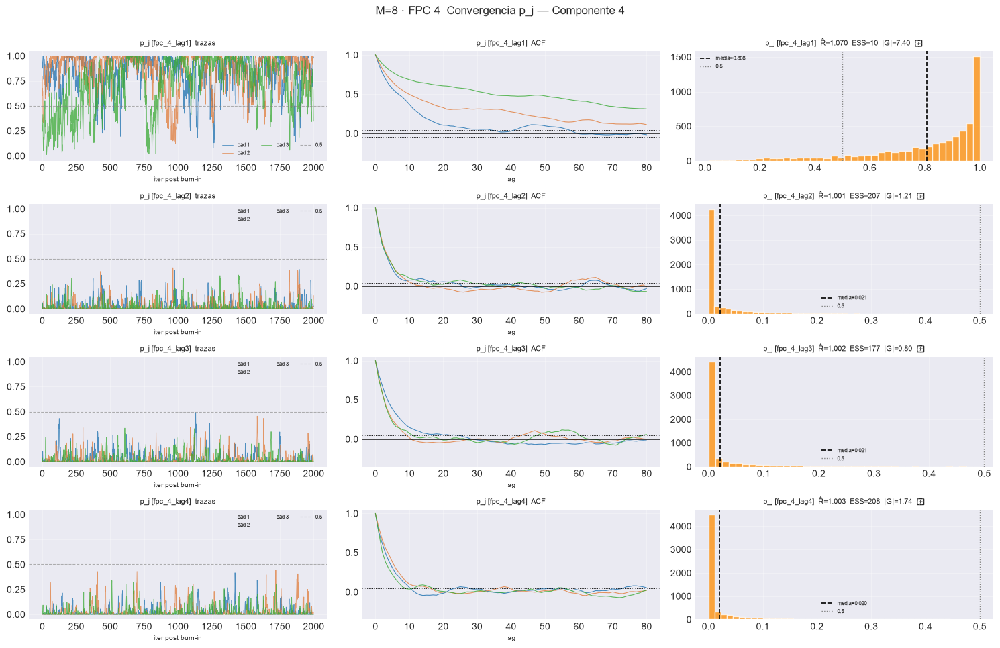

[plot_convergence_bj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_5_lag1  rhat=1.000  ess_min=1001  |G|=1.78  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_5_lag2  rhat=1.000  ess_min=1924  |G|=1.22  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_5_lag3  rhat=1.000  ess_min=1630  |G|=1.71  ✓
  4/4 (100.0%) t=0.1s eta=0.0s  fpc_5_lag4  rhat=1.000  ess_min=2000  |G|=1.72  ✓
[plot_convergence_bj[FPC 5]] listo: 4 pasos en 1.9s  0/4 sin converger


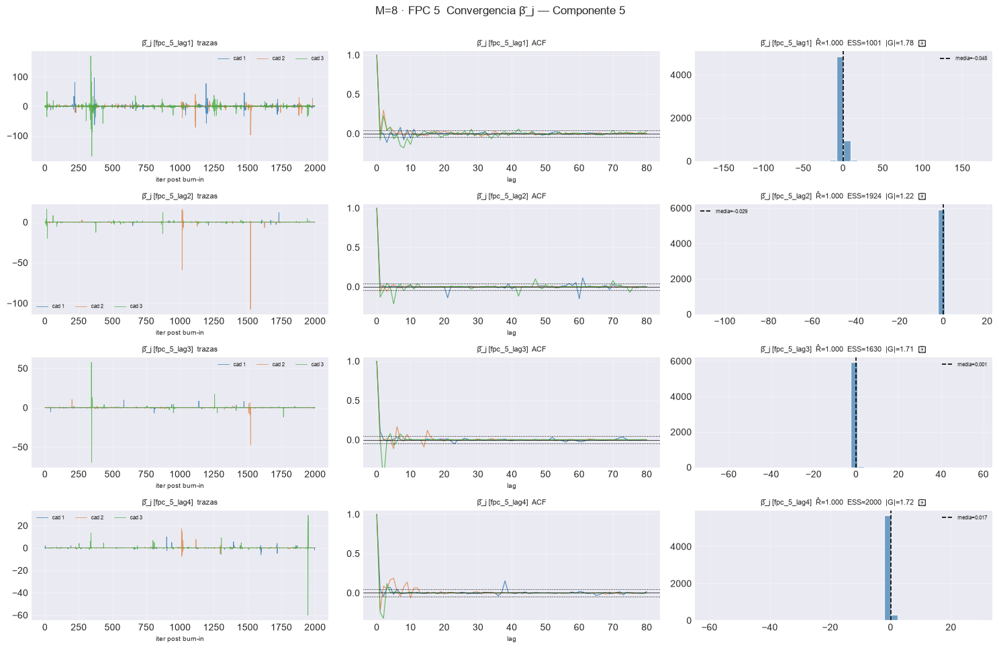

[plot_convergence_pj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_5_lag1  rhat=1.029  ess_min=45  |G|=1.74  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_5_lag2  rhat=1.002  ess_min=187  |G|=0.90  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_5_lag3  rhat=1.003  ess_min=156  |G|=2.48  ✗
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_5_lag4  rhat=1.001  ess_min=106  |G|=2.62  ✗
[plot_convergence_pj[FPC 5]] listo: 4 pasos en 2.1s  3/4 sin converger


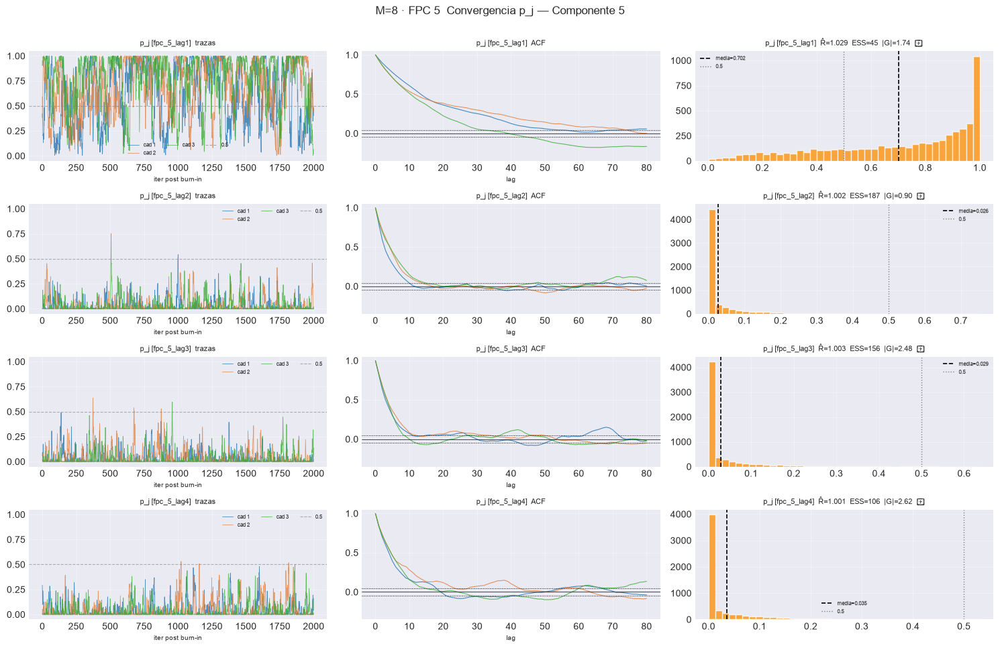

[plot_convergence_bj[FPC 6]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_6_lag1  rhat=1.000  ess_min=1272  |G|=1.06  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_6_lag2  rhat=1.000  ess_min=1289  |G|=1.42  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_6_lag3  rhat=1.000  ess_min=2000  |G|=1.16  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_6_lag4  rhat=1.000  ess_min=1359  |G|=1.36  ✓
[plot_convergence_bj[FPC 6]] listo: 4 pasos en 2.1s  0/4 sin converger


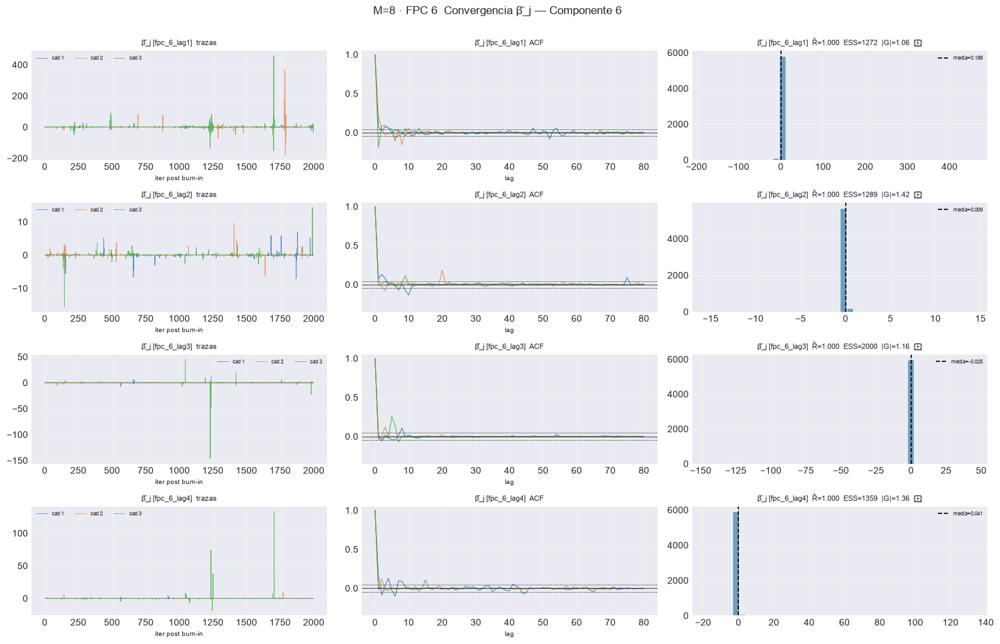

[plot_convergence_pj[FPC 6]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_6_lag1  rhat=1.113  ess_min=31  |G|=3.19  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_6_lag2  rhat=1.000  ess_min=70  |G|=3.05  ✗
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_6_lag3  rhat=1.000  ess_min=201  |G|=0.58  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_6_lag4  rhat=1.002  ess_min=190  |G|=1.19  ✓
[plot_convergence_pj[FPC 6]] listo: 4 pasos en 2.1s  2/4 sin converger


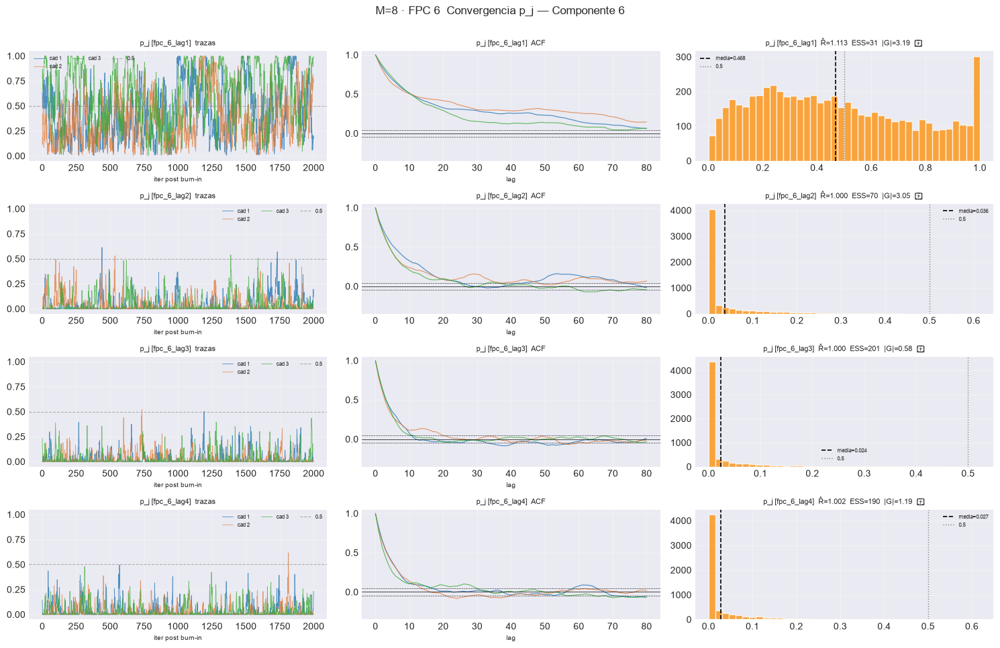

[plot_convergence_bj[FPC 7]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_7_lag1  rhat=1.000  ess_min=1368  |G|=0.46  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_7_lag2  rhat=1.000  ess_min=1639  |G|=1.10  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_7_lag3  rhat=1.000  ess_min=1789  |G|=0.90  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_7_lag4  rhat=1.000  ess_min=1585  |G|=1.62  ✓
[plot_convergence_bj[FPC 7]] listo: 4 pasos en 3.9s  0/4 sin converger


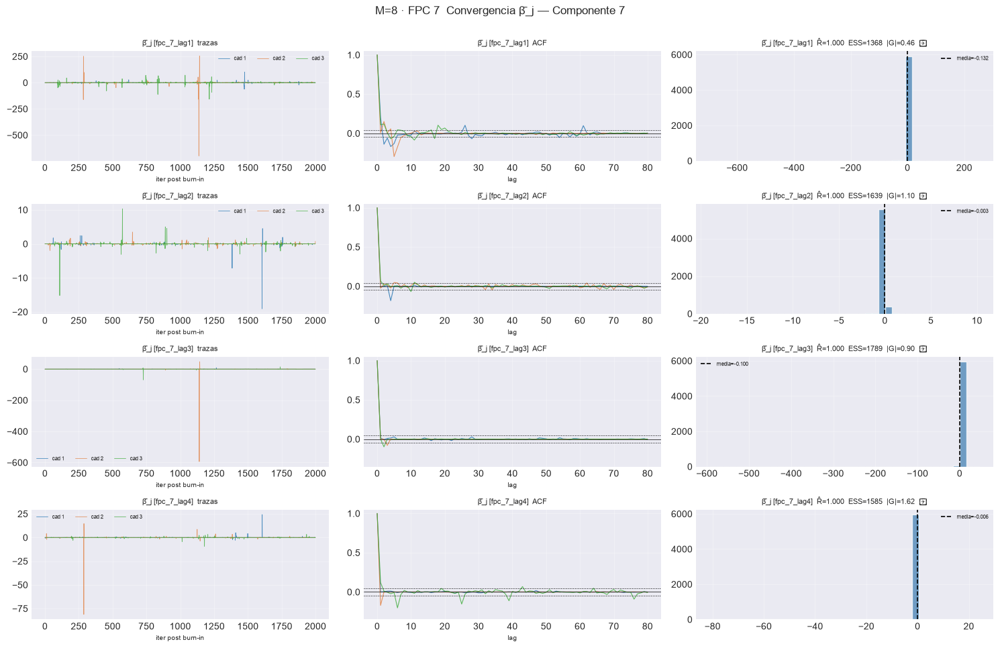

[plot_convergence_pj[FPC 7]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_7_lag1  rhat=1.184  ess_min=20  |G|=4.21  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_7_lag2  rhat=1.010  ess_min=170  |G|=0.79  ✓
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_7_lag3  rhat=1.006  ess_min=188  |G|=1.34  ✓
  4/4 (100.0%) t=0.4s eta=0.0s  fpc_7_lag4  rhat=1.008  ess_min=248  |G|=0.91  ✓
[plot_convergence_pj[FPC 7]] listo: 4 pasos en 3.8s  1/4 sin converger


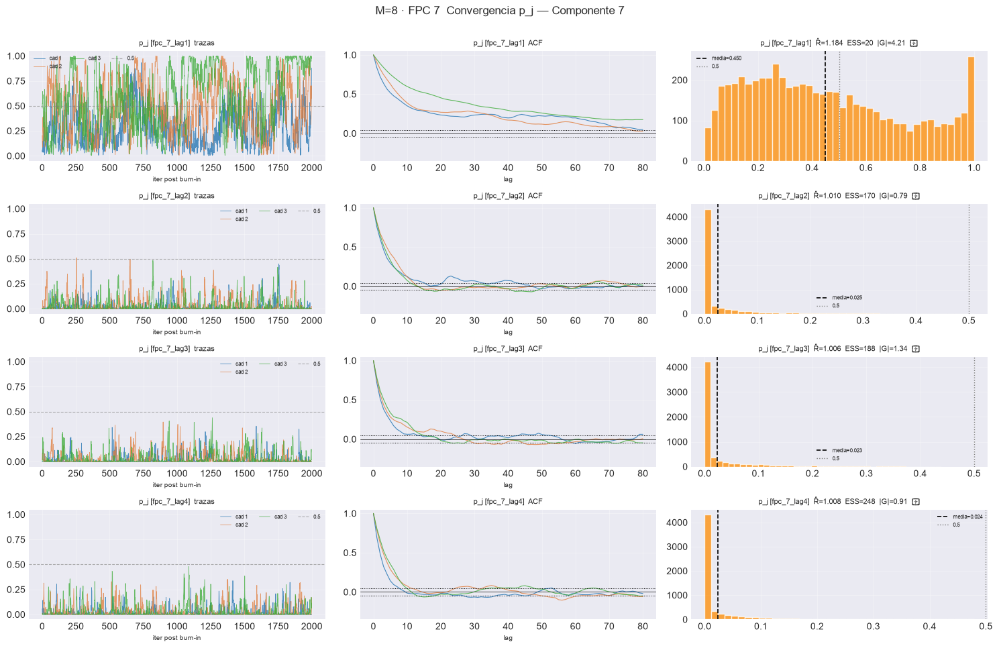

[plot_convergence_bj[FPC 8]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_8_lag1  rhat=1.000  ess_min=938  |G|=1.96  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_8_lag2  rhat=1.000  ess_min=1715  |G|=1.39  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_8_lag3  rhat=1.000  ess_min=2000  |G|=0.99  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_8_lag4  rhat=1.000  ess_min=1215  |G|=1.27  ✓
[plot_convergence_bj[FPC 8]] listo: 4 pasos en 3.6s  0/4 sin converger


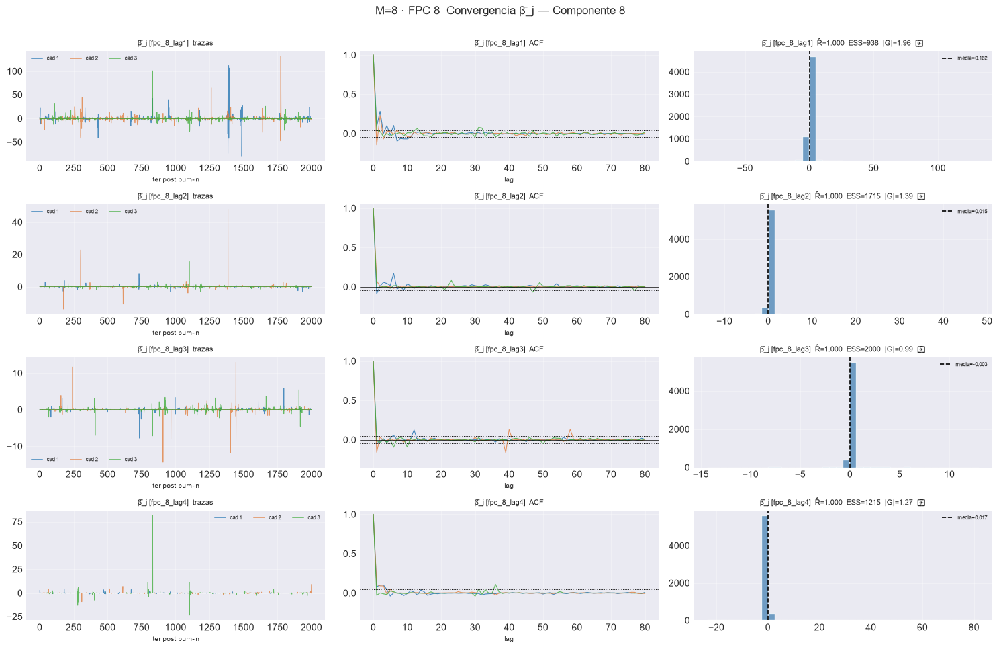

[plot_convergence_pj[FPC 8]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_8_lag1  rhat=1.008  ess_min=26  |G|=3.40  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_8_lag2  rhat=1.001  ess_min=112  |G|=1.76  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_8_lag3  rhat=1.000  ess_min=128  |G|=2.46  ✗
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_8_lag4  rhat=1.002  ess_min=141  |G|=1.01  ✓
[plot_convergence_pj[FPC 8]] listo: 4 pasos en 3.5s  2/4 sin converger


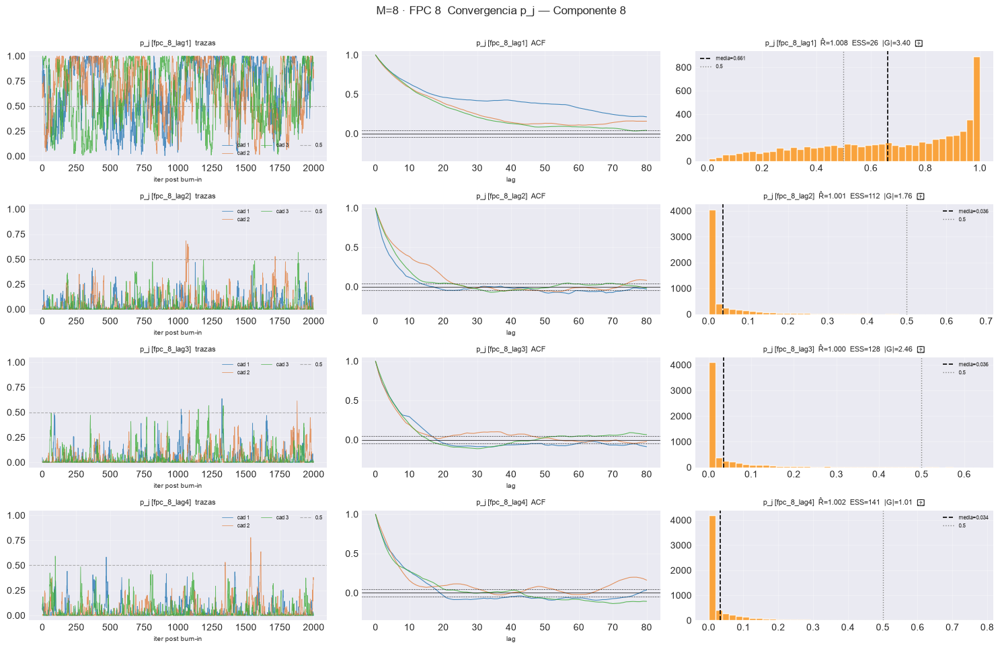

== M=9 ==============================================
[plot_convergence_bj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_1_lag1  rhat=1.000  ess_min=1933  |G|=1.16  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_1_lag2  rhat=1.000  ess_min=1619  |G|=2.05  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_1_lag3  rhat=1.000  ess_min=1859  |G|=1.27  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_1_lag4  rhat=1.000  ess_min=1870  |G|=0.65  ✓
[plot_convergence_bj[FPC 1]] listo: 4 pasos en 3.2s  1/4 sin converger


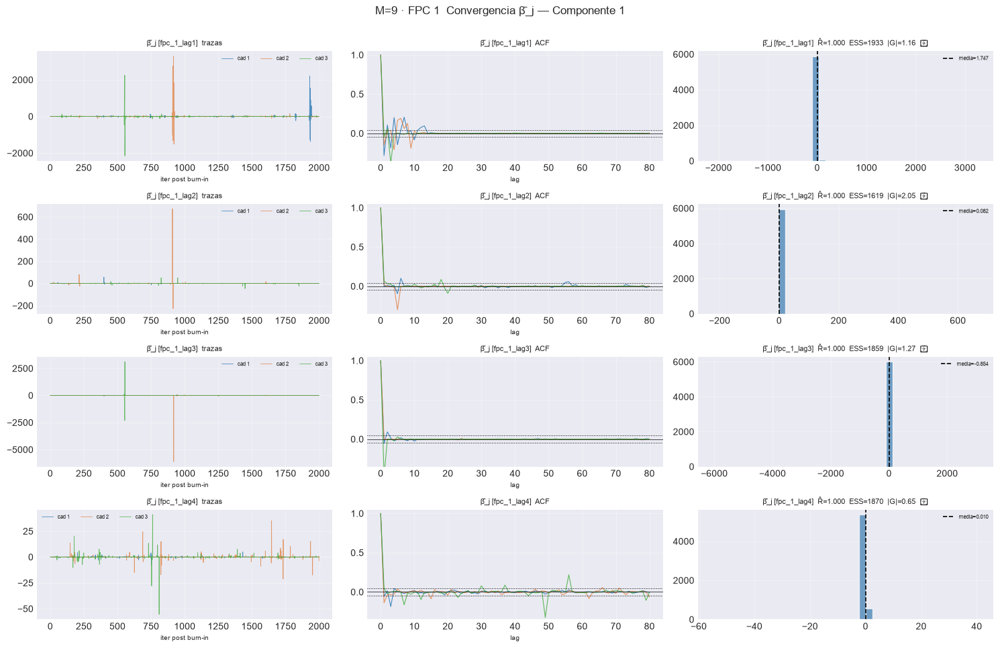

[plot_convergence_pj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_1_lag1  rhat=1.004  ess_min=19  |G|=3.19  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_1_lag2  rhat=1.000  ess_min=19  |G|=6.04  ✗
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_1_lag3  rhat=1.007  ess_min=148  |G|=3.75  ✗
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_1_lag4  rhat=1.016  ess_min=125  |G|=0.74  ✓
[plot_convergence_pj[FPC 1]] listo: 4 pasos en 3.9s  3/4 sin converger


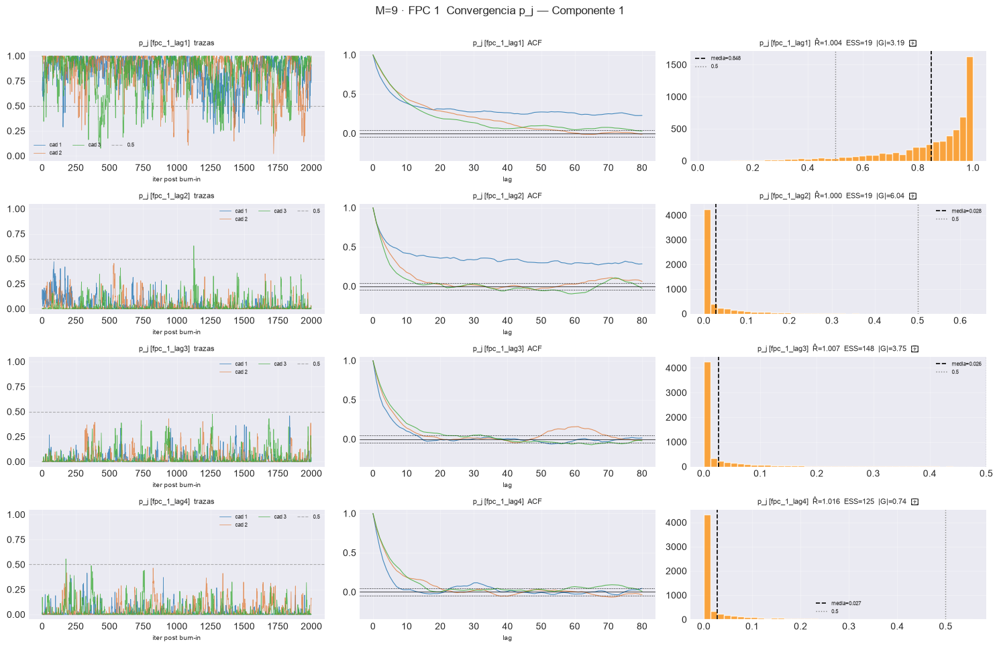

[plot_convergence_bj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=1.000  ess_min=680  |G|=2.27  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_2_lag2  rhat=1.000  ess_min=1706  |G|=1.29  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_2_lag3  rhat=1.000  ess_min=1701  |G|=0.99  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_2_lag4  rhat=1.000  ess_min=980  |G|=1.33  ✓
[plot_convergence_bj[FPC 2]] listo: 4 pasos en 4.0s  1/4 sin converger


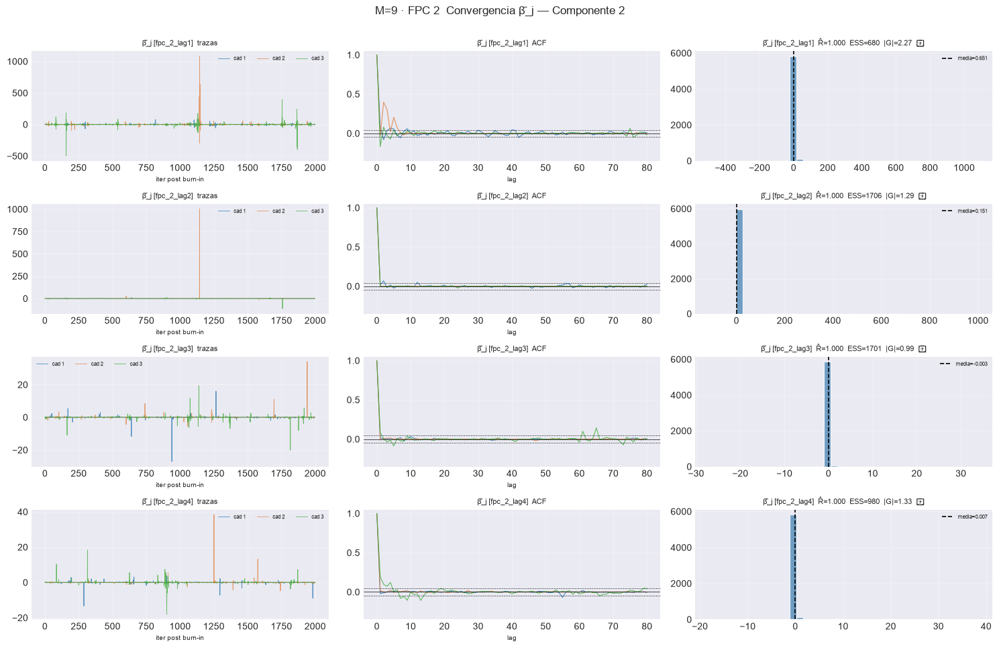

[plot_convergence_pj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_2_lag1  rhat=1.077  ess_min=30  |G|=8.49  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_2_lag2  rhat=1.002  ess_min=221  |G|=1.44  ✓
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_2_lag3  rhat=1.005  ess_min=248  |G|=1.40  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_2_lag4  rhat=1.006  ess_min=177  |G|=0.77  ✓
[plot_convergence_pj[FPC 2]] listo: 4 pasos en 3.5s  1/4 sin converger


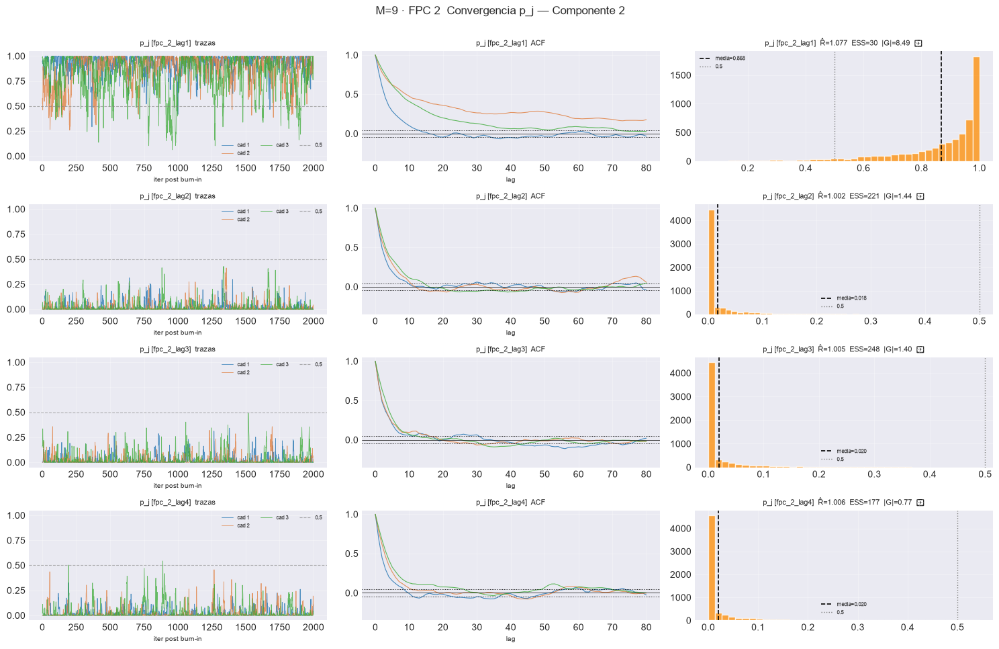

[plot_convergence_bj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=1.000  ess_min=1790  |G|=1.28  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.000  ess_min=1888  |G|=1.46  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_3_lag3  rhat=1.000  ess_min=1997  |G|=0.87  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_3_lag4  rhat=1.000  ess_min=1315  |G|=0.57  ✓
[plot_convergence_bj[FPC 3]] listo: 4 pasos en 3.1s  0/4 sin converger


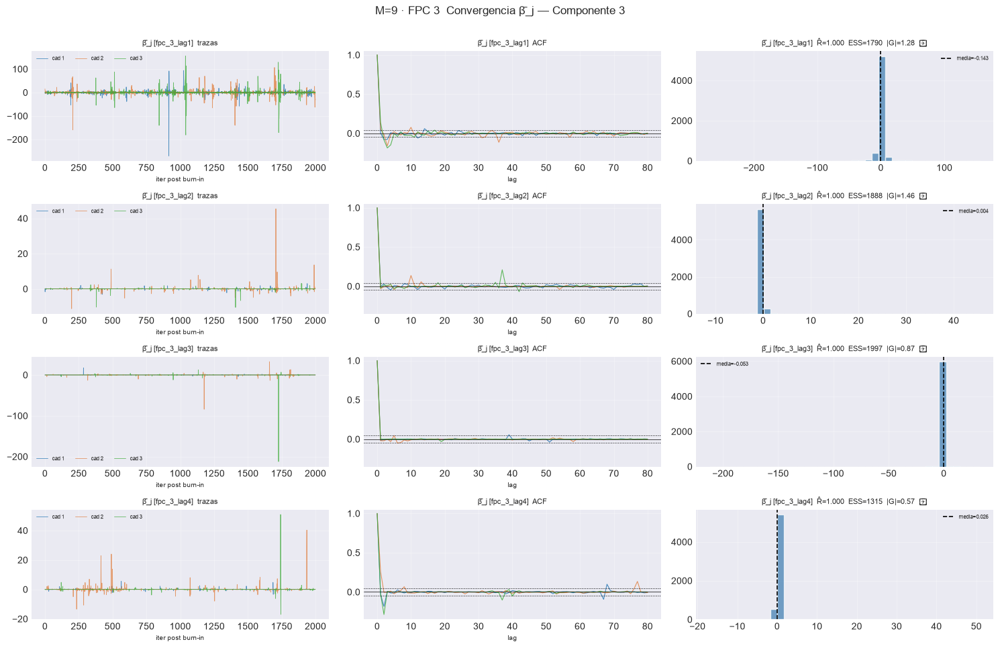

[plot_convergence_pj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_3_lag1  rhat=1.025  ess_min=32  |G|=2.08  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.010  ess_min=151  |G|=2.58  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_3_lag3  rhat=1.018  ess_min=115  |G|=1.75  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_3_lag4  rhat=1.065  ess_min=25  |G|=0.98  ✗
[plot_convergence_pj[FPC 3]] listo: 4 pasos en 3.5s  3/4 sin converger


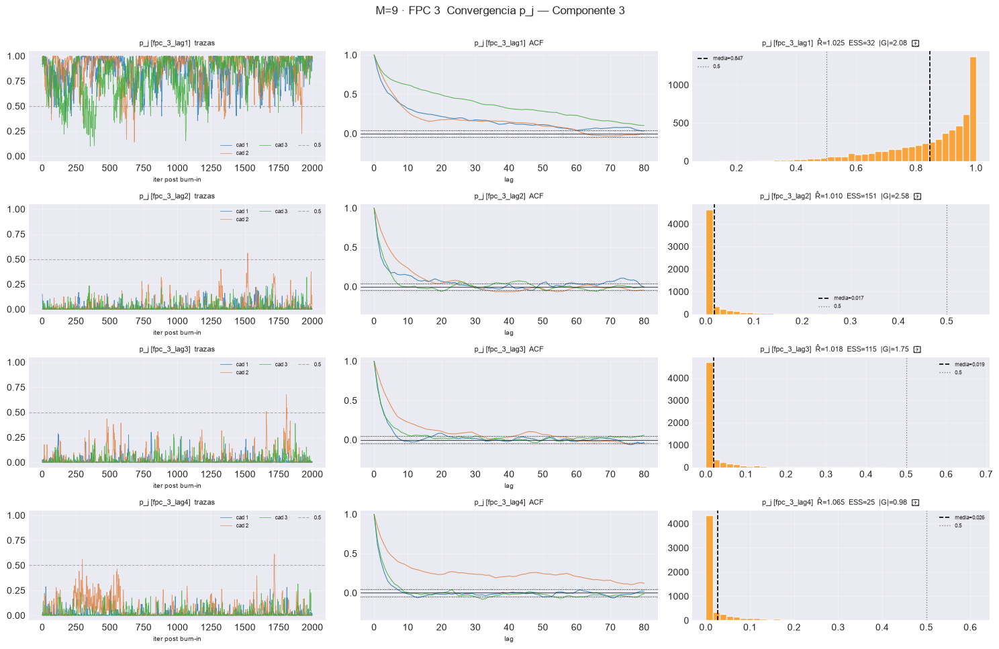

[plot_convergence_bj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=1.000  ess_min=1062  |G|=1.33  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_4_lag2  rhat=1.000  ess_min=1243  |G|=1.50  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_4_lag3  rhat=1.000  ess_min=1233  |G|=0.97  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_4_lag4  rhat=1.000  ess_min=1722  |G|=1.97  ✓
[plot_convergence_bj[FPC 4]] listo: 4 pasos en 3.6s  0/4 sin converger


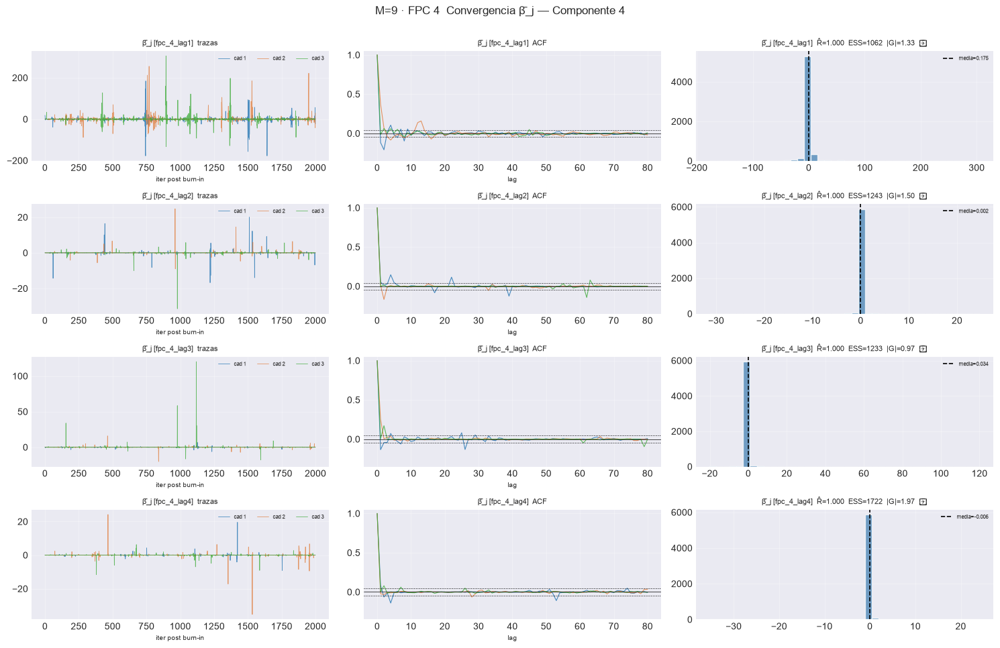

[plot_convergence_pj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=1.070  ess_min=10  |G|=7.40  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_4_lag2  rhat=1.001  ess_min=207  |G|=1.21  ✓
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_4_lag3  rhat=1.002  ess_min=177  |G|=0.80  ✓
  4/4 (100.0%) t=0.4s eta=0.0s  fpc_4_lag4  rhat=1.003  ess_min=208  |G|=1.74  ✓
[plot_convergence_pj[FPC 4]] listo: 4 pasos en 3.3s  1/4 sin converger


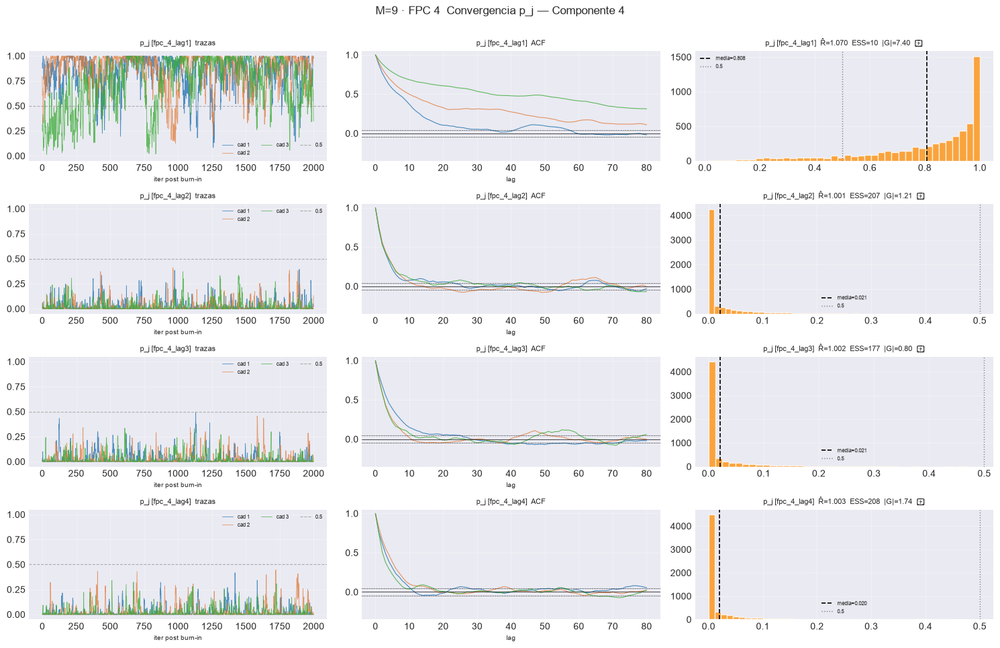

[plot_convergence_bj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_5_lag1  rhat=1.000  ess_min=1001  |G|=1.78  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_5_lag2  rhat=1.000  ess_min=1924  |G|=1.22  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_5_lag3  rhat=1.000  ess_min=1630  |G|=1.71  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_5_lag4  rhat=1.000  ess_min=2000  |G|=1.72  ✓
[plot_convergence_bj[FPC 5]] listo: 4 pasos en 3.5s  0/4 sin converger


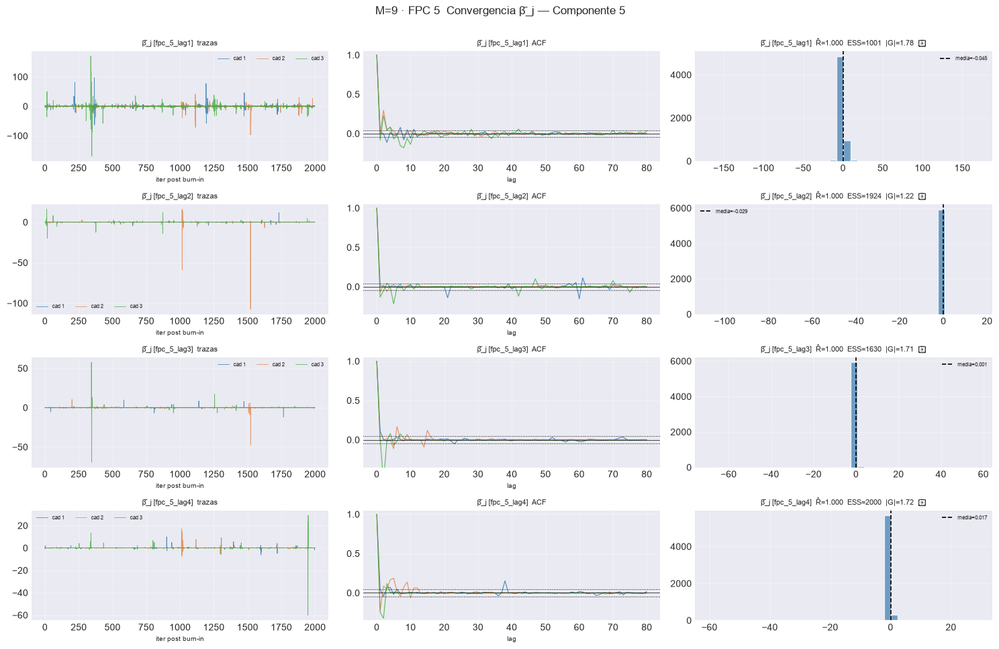

[plot_convergence_pj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_5_lag1  rhat=1.029  ess_min=45  |G|=1.74  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_5_lag2  rhat=1.002  ess_min=187  |G|=0.90  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_5_lag3  rhat=1.003  ess_min=156  |G|=2.48  ✗
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_5_lag4  rhat=1.001  ess_min=106  |G|=2.62  ✗
[plot_convergence_pj[FPC 5]] listo: 4 pasos en 3.6s  3/4 sin converger


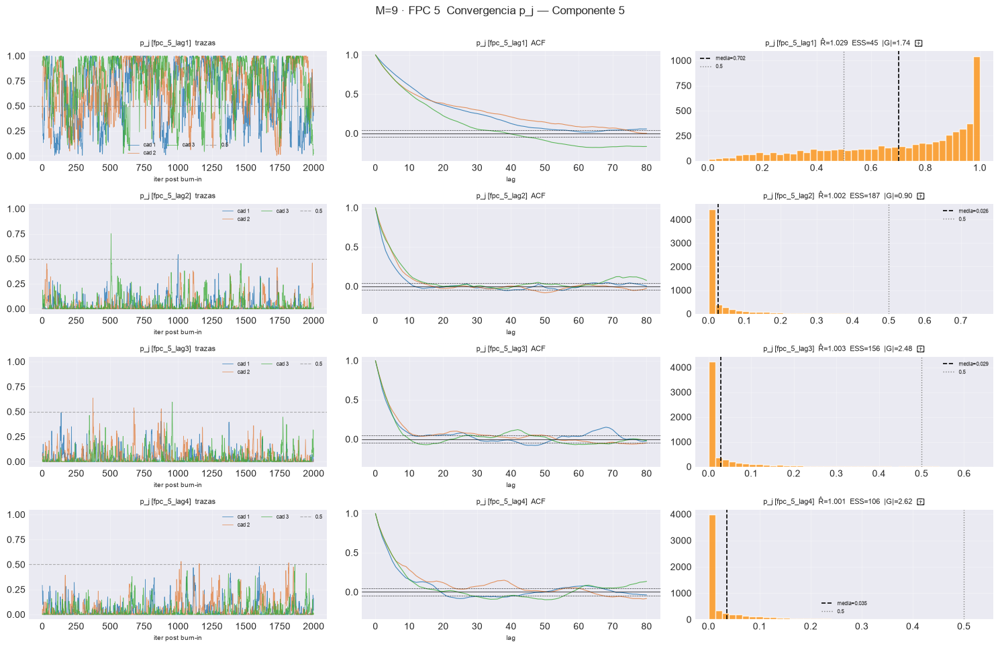

[plot_convergence_bj[FPC 6]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_6_lag1  rhat=1.000  ess_min=1272  |G|=1.06  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_6_lag2  rhat=1.000  ess_min=1289  |G|=1.42  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_6_lag3  rhat=1.000  ess_min=2000  |G|=1.16  ✓
  4/4 (100.0%) t=0.4s eta=0.0s  fpc_6_lag4  rhat=1.000  ess_min=1359  |G|=1.36  ✓
[plot_convergence_bj[FPC 6]] listo: 4 pasos en 3.9s  0/4 sin converger


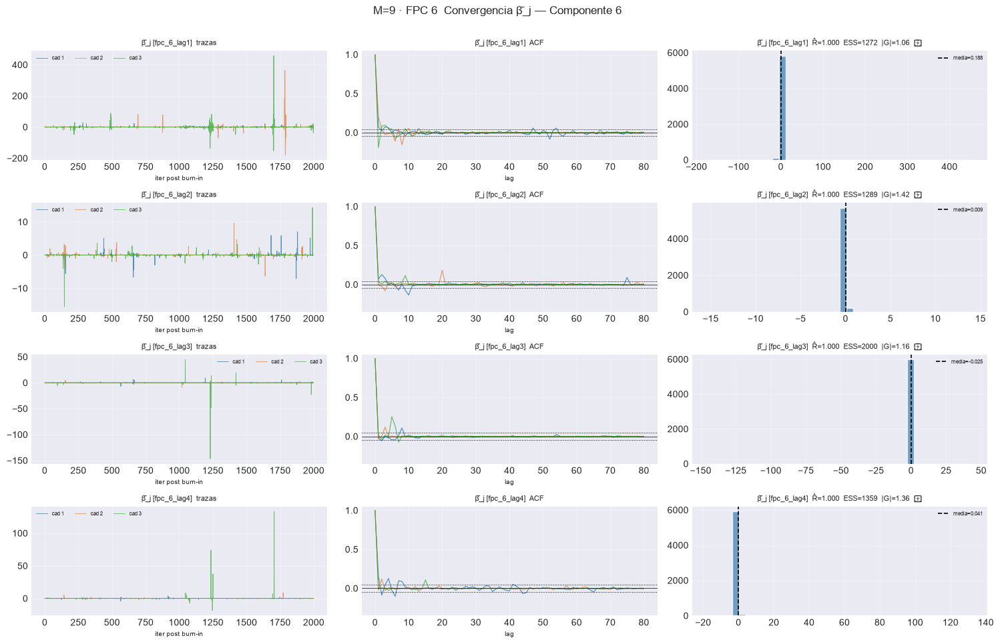

[plot_convergence_pj[FPC 6]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_6_lag1  rhat=1.113  ess_min=31  |G|=3.19  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_6_lag2  rhat=1.000  ess_min=70  |G|=3.05  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_6_lag3  rhat=1.000  ess_min=201  |G|=0.58  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_6_lag4  rhat=1.002  ess_min=190  |G|=1.19  ✓
[plot_convergence_pj[FPC 6]] listo: 4 pasos en 4.2s  2/4 sin converger


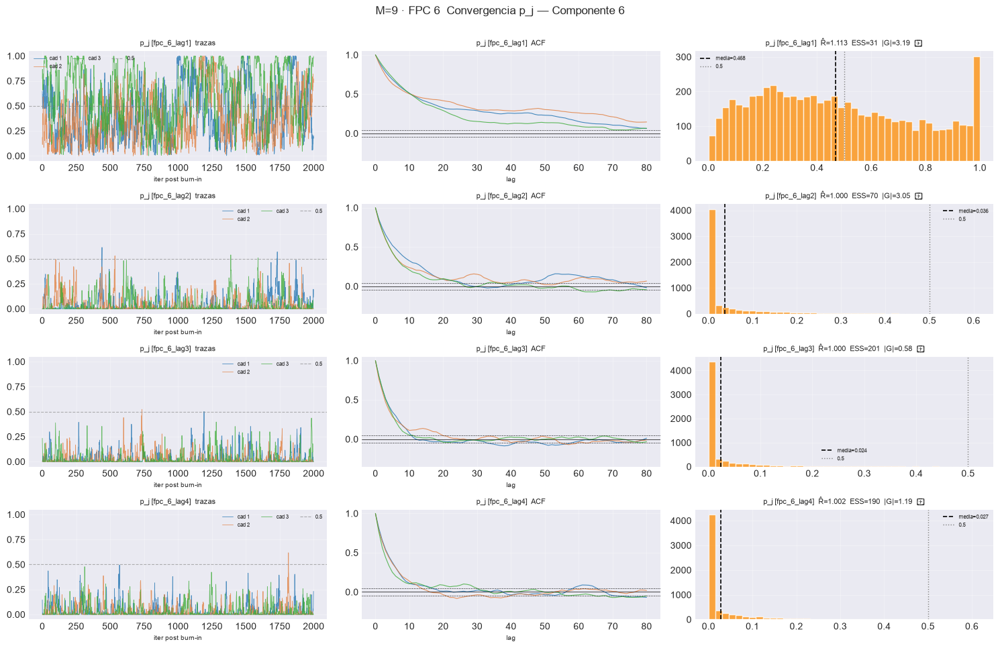

[plot_convergence_bj[FPC 7]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_7_lag1  rhat=1.000  ess_min=1368  |G|=0.46  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_7_lag2  rhat=1.000  ess_min=1639  |G|=1.10  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_7_lag3  rhat=1.000  ess_min=1789  |G|=0.90  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_7_lag4  rhat=1.000  ess_min=1585  |G|=1.62  ✓
[plot_convergence_bj[FPC 7]] listo: 4 pasos en 3.3s  0/4 sin converger


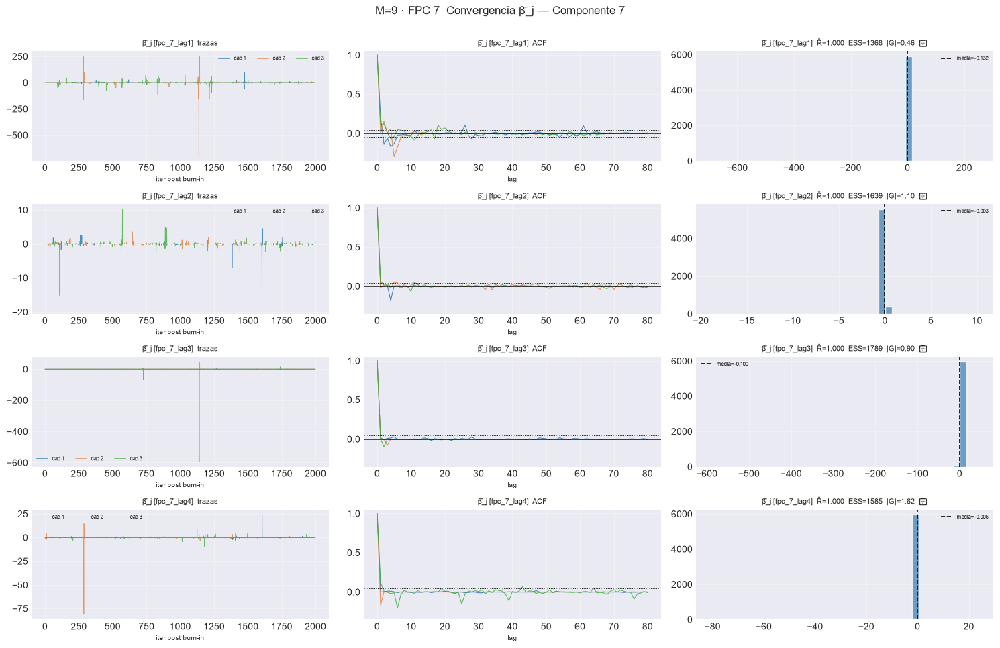

[plot_convergence_pj[FPC 7]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_7_lag1  rhat=1.184  ess_min=20  |G|=4.21  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_7_lag2  rhat=1.010  ess_min=170  |G|=0.79  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_7_lag3  rhat=1.006  ess_min=188  |G|=1.34  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_7_lag4  rhat=1.008  ess_min=248  |G|=0.91  ✓
[plot_convergence_pj[FPC 7]] listo: 4 pasos en 3.3s  1/4 sin converger


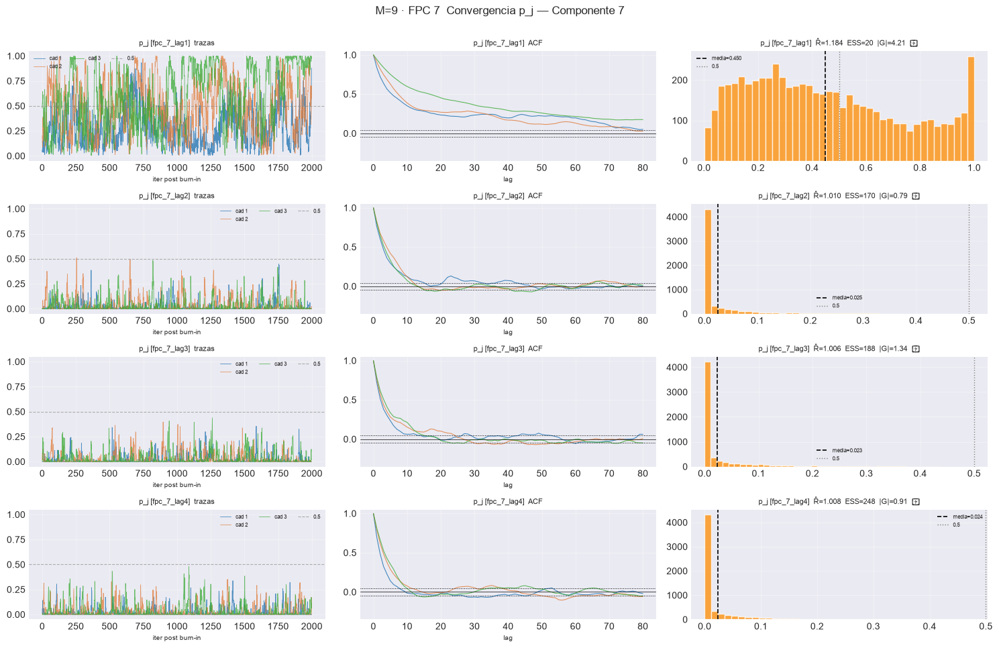

[plot_convergence_bj[FPC 8]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_8_lag1  rhat=1.000  ess_min=938  |G|=1.96  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_8_lag2  rhat=1.000  ess_min=1715  |G|=1.39  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_8_lag3  rhat=1.000  ess_min=2000  |G|=0.99  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_8_lag4  rhat=1.000  ess_min=1215  |G|=1.27  ✓
[plot_convergence_bj[FPC 8]] listo: 4 pasos en 3.1s  0/4 sin converger


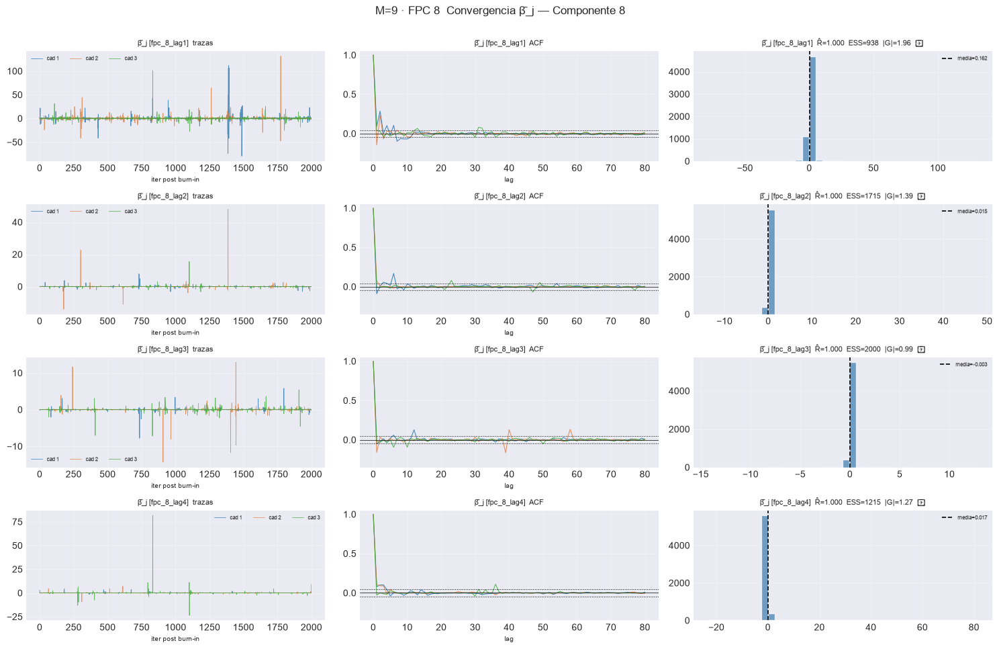

[plot_convergence_pj[FPC 8]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_8_lag1  rhat=1.008  ess_min=26  |G|=3.40  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_8_lag2  rhat=1.001  ess_min=112  |G|=1.76  ✓
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_8_lag3  rhat=1.000  ess_min=128  |G|=2.46  ✗
  4/4 (100.0%) t=0.4s eta=0.0s  fpc_8_lag4  rhat=1.002  ess_min=141  |G|=1.01  ✓
[plot_convergence_pj[FPC 8]] listo: 4 pasos en 3.5s  2/4 sin converger


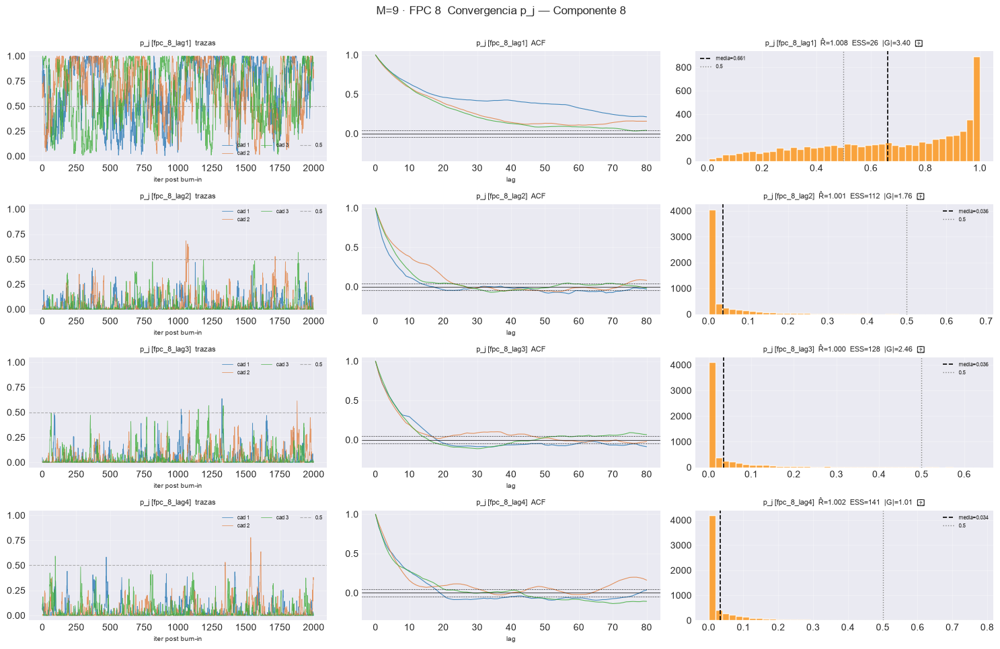

[plot_convergence_bj[FPC 9]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_9_lag1  rhat=1.000  ess_min=1103  |G|=0.82  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_9_lag2  rhat=1.000  ess_min=1536  |G|=1.74  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_9_lag3  rhat=1.000  ess_min=1084  |G|=1.15  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_9_lag4  rhat=1.000  ess_min=1929  |G|=1.01  ✓
[plot_convergence_bj[FPC 9]] listo: 4 pasos en 3.7s  0/4 sin converger


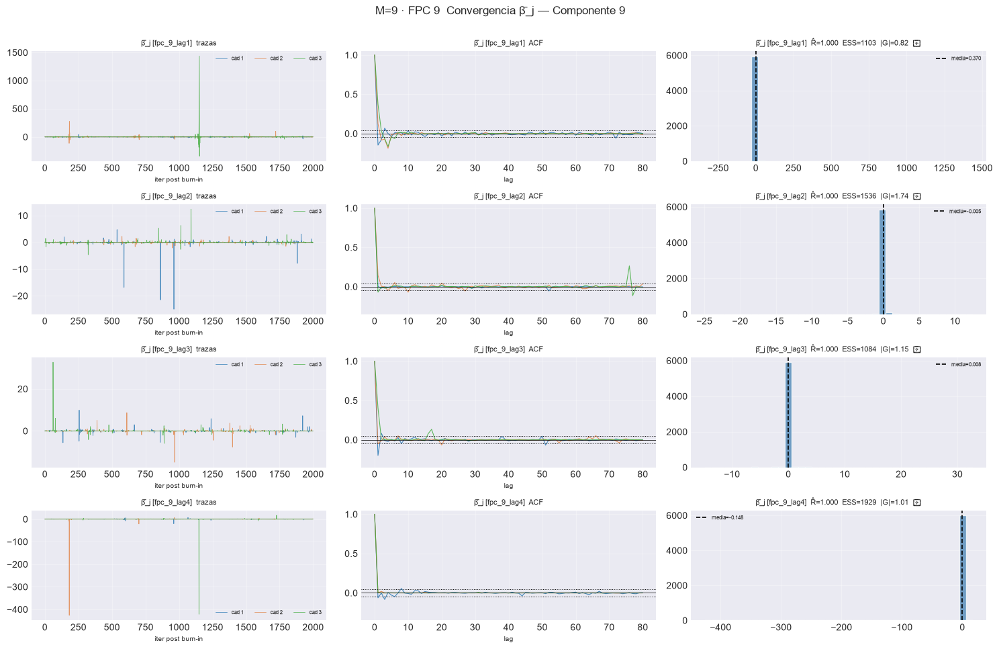

[plot_convergence_pj[FPC 9]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_9_lag1  rhat=1.002  ess_min=18  |G|=1.77  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_9_lag2  rhat=1.001  ess_min=146  |G|=3.53  ✗
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_9_lag3  rhat=1.000  ess_min=184  |G|=0.93  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_9_lag4  rhat=1.001  ess_min=144  |G|=2.45  ✗
[plot_convergence_pj[FPC 9]] listo: 4 pasos en 3.0s  3/4 sin converger


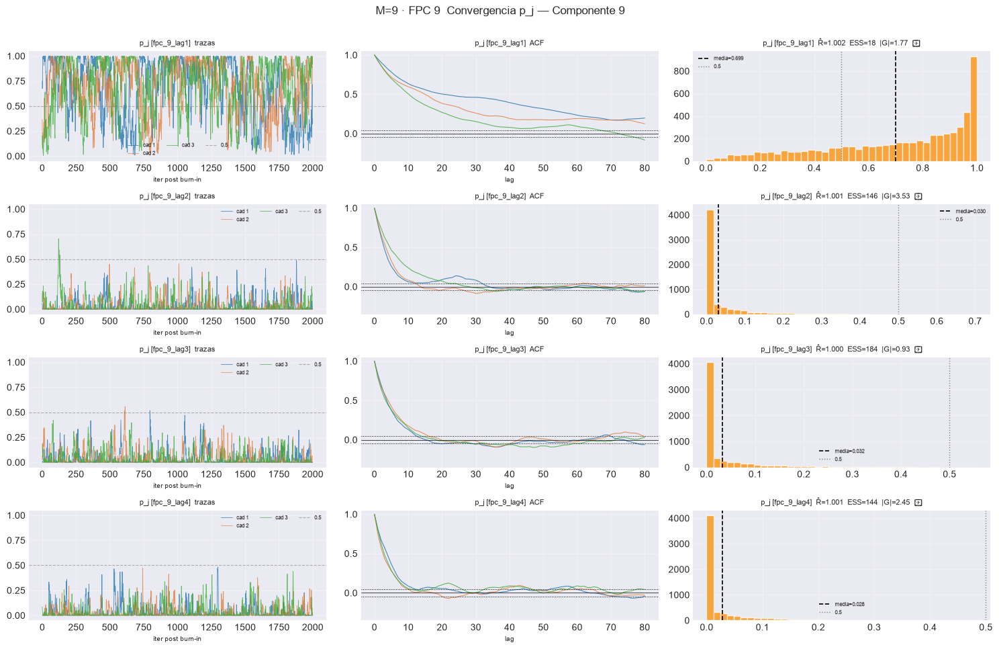

== M=10 ==============================================
[plot_convergence_bj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_1_lag1  rhat=1.000  ess_min=1933  |G|=1.16  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_1_lag2  rhat=1.000  ess_min=1619  |G|=2.05  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_1_lag3  rhat=1.000  ess_min=1859  |G|=1.27  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_1_lag4  rhat=1.000  ess_min=1870  |G|=0.65  ✓
[plot_convergence_bj[FPC 1]] listo: 4 pasos en 3.5s  1/4 sin converger


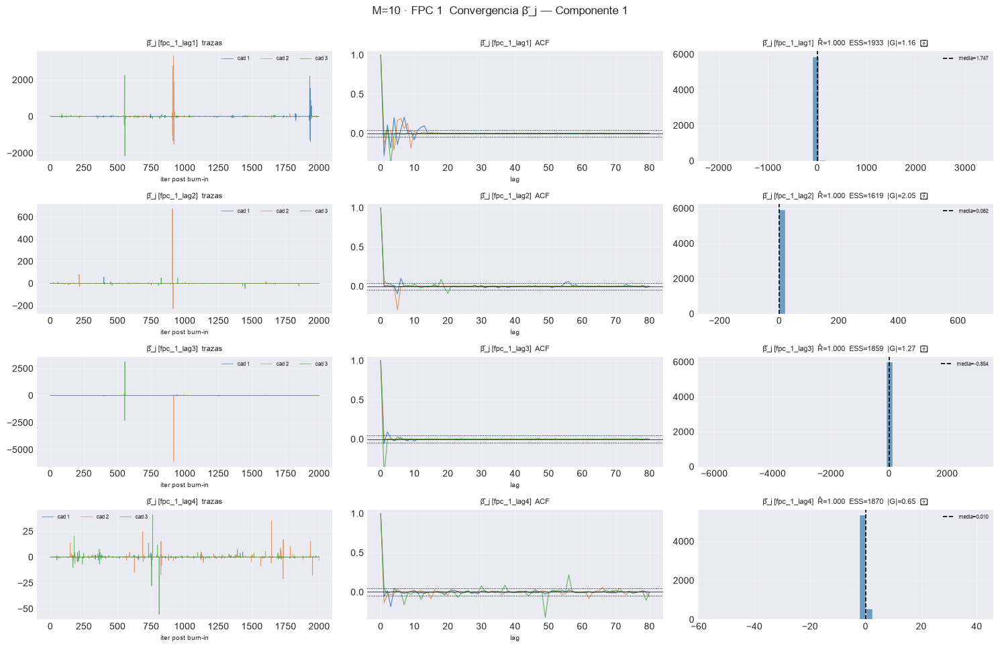

[plot_convergence_pj[FPC 1]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.4s  fpc_1_lag1  rhat=1.004  ess_min=19  |G|=3.19  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_1_lag2  rhat=1.000  ess_min=19  |G|=6.04  ✗
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_1_lag3  rhat=1.007  ess_min=148  |G|=3.75  ✗
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_1_lag4  rhat=1.016  ess_min=125  |G|=0.74  ✓
[plot_convergence_pj[FPC 1]] listo: 4 pasos en 2.9s  3/4 sin converger


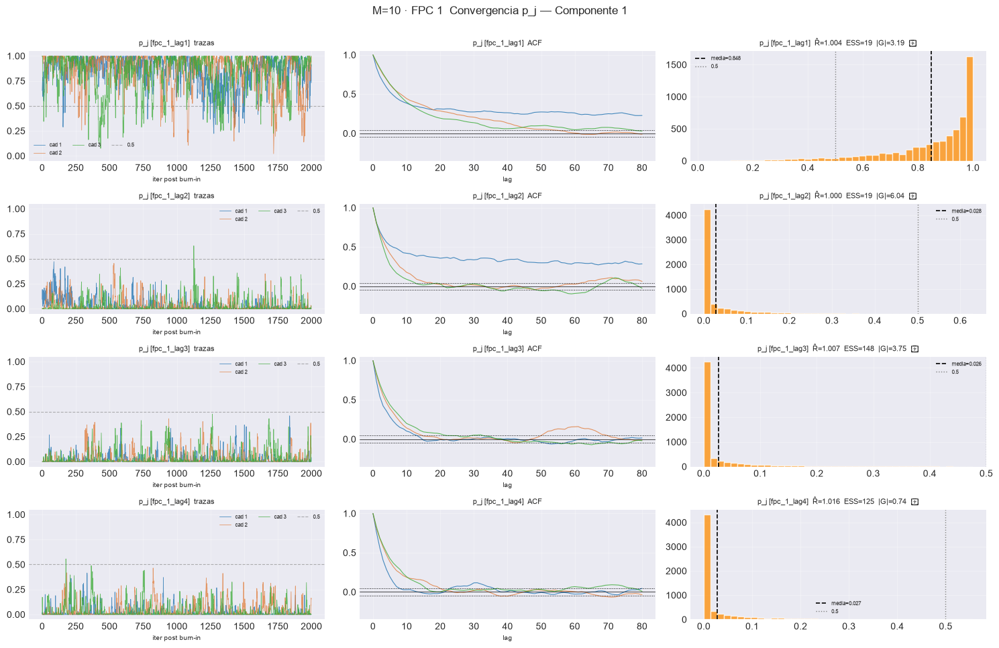

[plot_convergence_bj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=1.000  ess_min=680  |G|=2.27  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.000  ess_min=1706  |G|=1.29  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_2_lag3  rhat=1.000  ess_min=1701  |G|=0.99  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_2_lag4  rhat=1.000  ess_min=980  |G|=1.33  ✓
[plot_convergence_bj[FPC 2]] listo: 4 pasos en 2.2s  1/4 sin converger


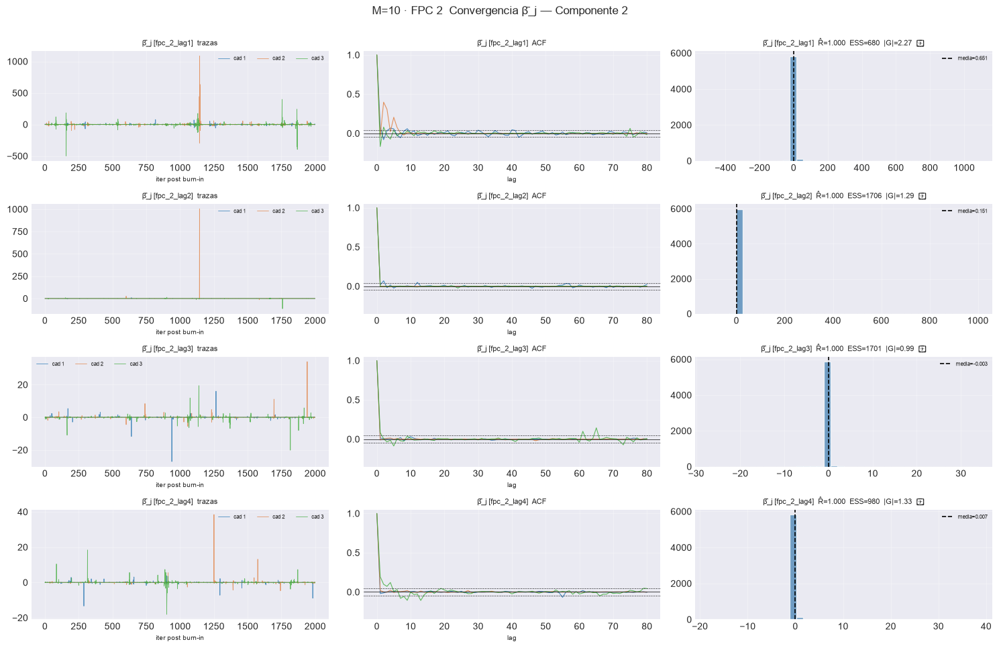

[plot_convergence_pj[FPC 2]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_2_lag1  rhat=1.077  ess_min=30  |G|=8.49  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_2_lag2  rhat=1.002  ess_min=221  |G|=1.44  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_2_lag3  rhat=1.005  ess_min=248  |G|=1.40  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_2_lag4  rhat=1.006  ess_min=177  |G|=0.77  ✓
[plot_convergence_pj[FPC 2]] listo: 4 pasos en 2.6s  1/4 sin converger


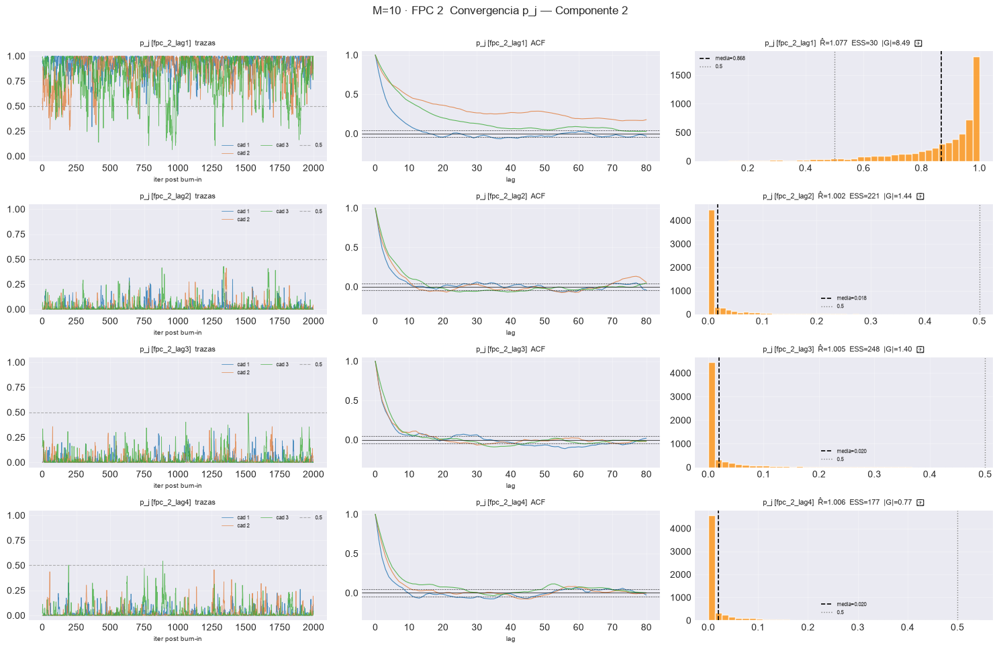

[plot_convergence_bj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=1.000  ess_min=1790  |G|=1.28  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.000  ess_min=1888  |G|=1.46  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_3_lag3  rhat=1.000  ess_min=1997  |G|=0.87  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_3_lag4  rhat=1.000  ess_min=1315  |G|=0.57  ✓
[plot_convergence_bj[FPC 3]] listo: 4 pasos en 2.1s  0/4 sin converger


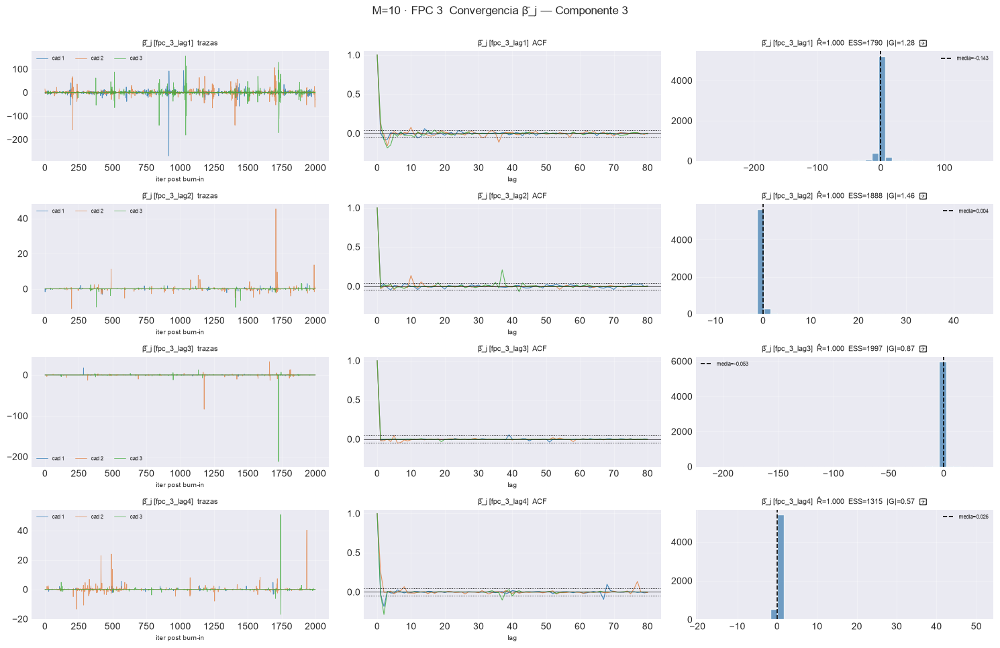

[plot_convergence_pj[FPC 3]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=1.025  ess_min=32  |G|=2.08  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_3_lag2  rhat=1.010  ess_min=151  |G|=2.58  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_3_lag3  rhat=1.018  ess_min=115  |G|=1.75  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_3_lag4  rhat=1.065  ess_min=25  |G|=0.98  ✗
[plot_convergence_pj[FPC 3]] listo: 4 pasos en 2.2s  3/4 sin converger


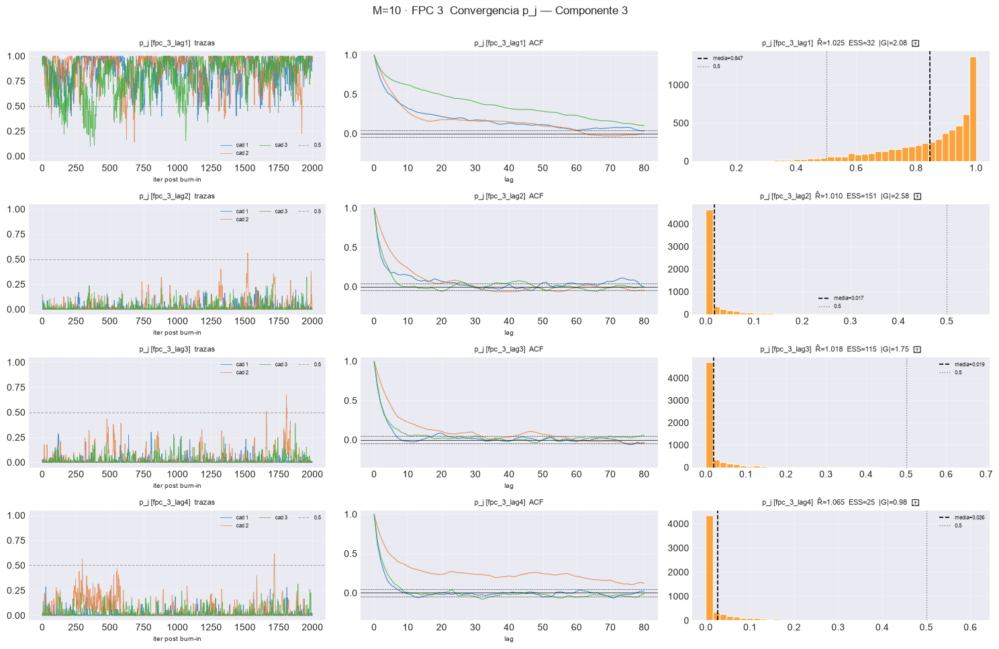

[plot_convergence_bj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_4_lag1  rhat=1.000  ess_min=1062  |G|=1.33  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_4_lag2  rhat=1.000  ess_min=1243  |G|=1.50  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_4_lag3  rhat=1.000  ess_min=1233  |G|=0.97  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_4_lag4  rhat=1.000  ess_min=1722  |G|=1.97  ✓
[plot_convergence_bj[FPC 4]] listo: 4 pasos en 2.0s  0/4 sin converger


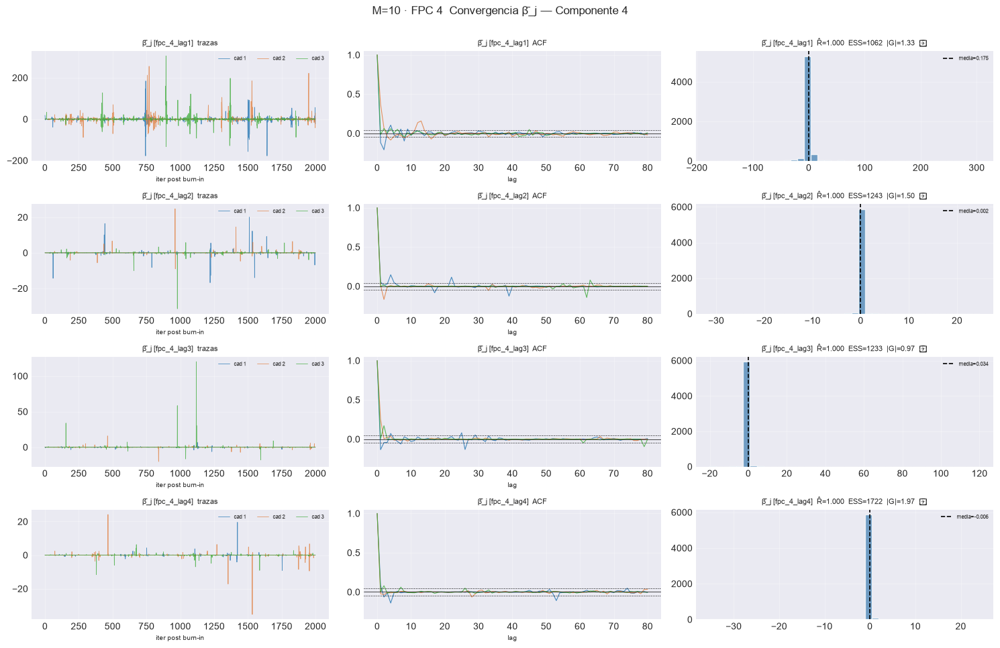

[plot_convergence_pj[FPC 4]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_4_lag1  rhat=1.070  ess_min=10  |G|=7.40  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_4_lag2  rhat=1.001  ess_min=207  |G|=1.21  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_4_lag3  rhat=1.002  ess_min=177  |G|=0.80  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_4_lag4  rhat=1.003  ess_min=208  |G|=1.74  ✓
[plot_convergence_pj[FPC 4]] listo: 4 pasos en 5.6s  1/4 sin converger


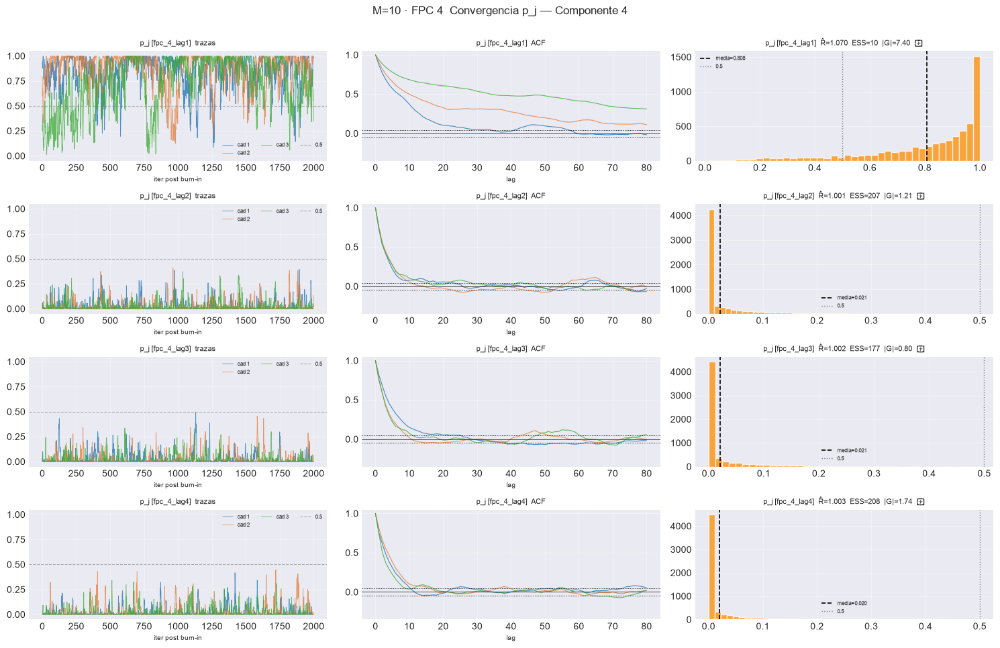

[plot_convergence_bj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.3s  fpc_5_lag1  rhat=1.000  ess_min=1001  |G|=1.78  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_5_lag2  rhat=1.000  ess_min=1924  |G|=1.22  ✓
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_5_lag3  rhat=1.000  ess_min=1630  |G|=1.71  ✓
  4/4 (100.0%) t=0.4s eta=0.0s  fpc_5_lag4  rhat=1.000  ess_min=2000  |G|=1.72  ✓
[plot_convergence_bj[FPC 5]] listo: 4 pasos en 5.8s  0/4 sin converger


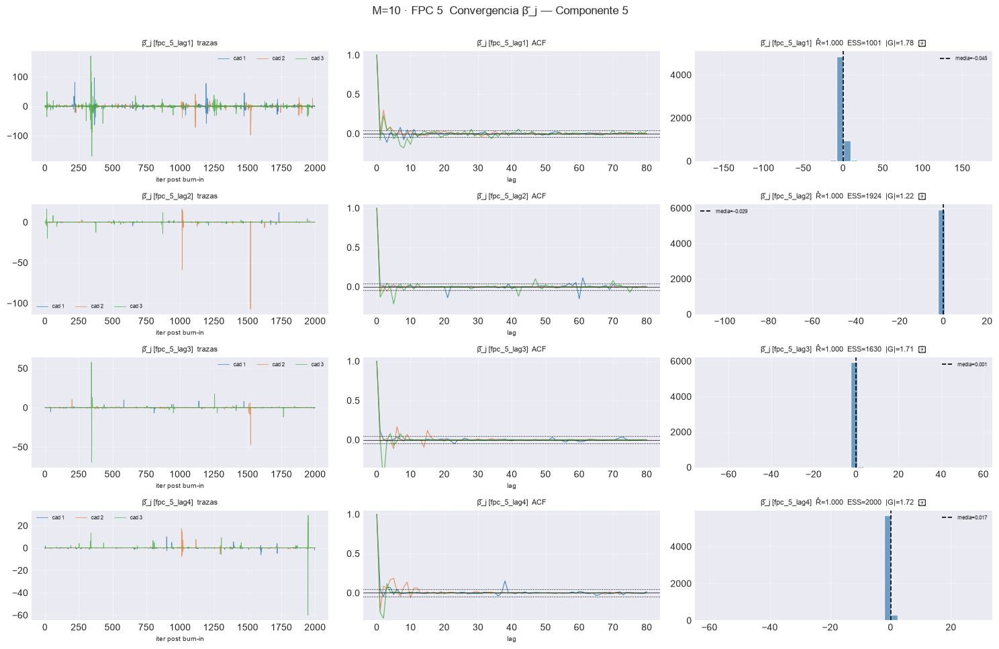

[plot_convergence_pj[FPC 5]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_5_lag1  rhat=1.029  ess_min=45  |G|=1.74  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_5_lag2  rhat=1.002  ess_min=187  |G|=0.90  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_5_lag3  rhat=1.003  ess_min=156  |G|=2.48  ✗
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_5_lag4  rhat=1.001  ess_min=106  |G|=2.62  ✗
[plot_convergence_pj[FPC 5]] listo: 4 pasos en 3.1s  3/4 sin converger


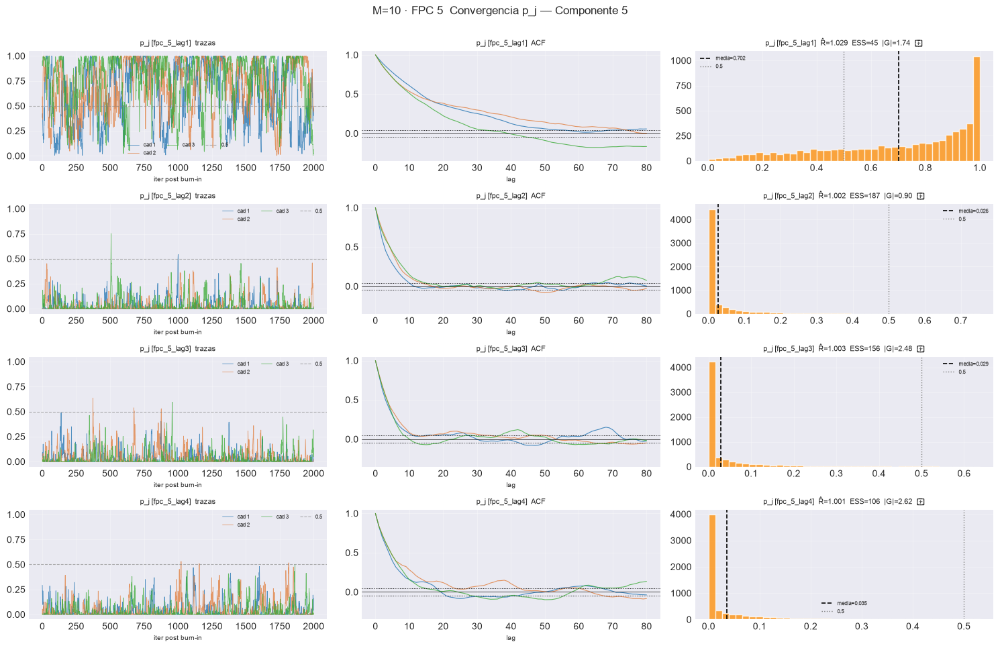

[plot_convergence_bj[FPC 6]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.4s  fpc_6_lag1  rhat=1.000  ess_min=1272  |G|=1.06  ✓
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_6_lag2  rhat=1.000  ess_min=1289  |G|=1.42  ✓
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_6_lag3  rhat=1.000  ess_min=2000  |G|=1.16  ✓
  4/4 (100.0%) t=0.5s eta=0.0s  fpc_6_lag4  rhat=1.000  ess_min=1359  |G|=1.36  ✓
[plot_convergence_bj[FPC 6]] listo: 4 pasos en 3.5s  0/4 sin converger


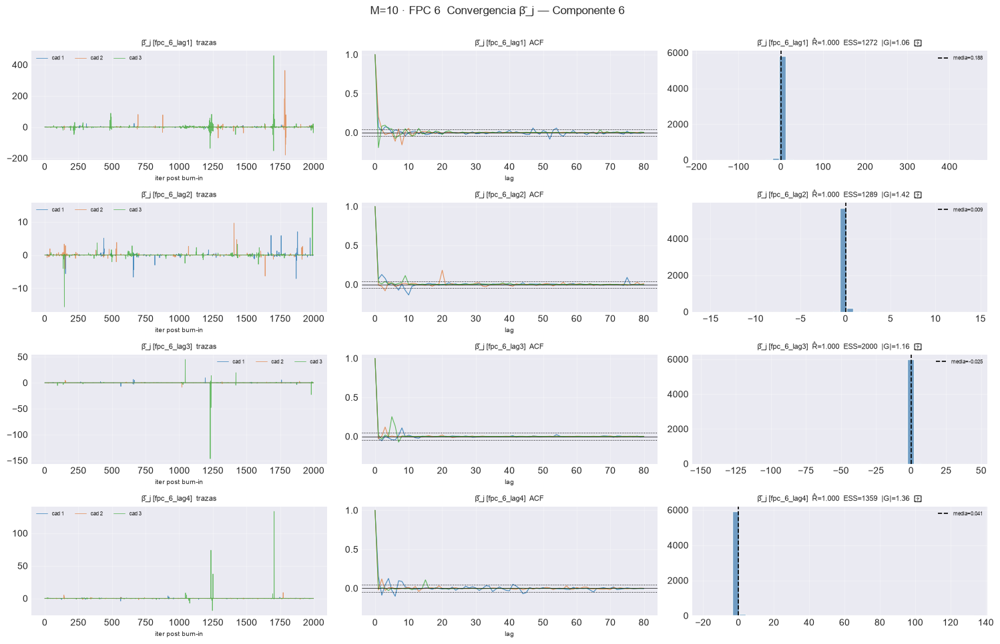

[plot_convergence_pj[FPC 6]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_6_lag1  rhat=1.113  ess_min=31  |G|=3.19  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_6_lag2  rhat=1.000  ess_min=70  |G|=3.05  ✗
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_6_lag3  rhat=1.000  ess_min=201  |G|=0.58  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_6_lag4  rhat=1.002  ess_min=190  |G|=1.19  ✓
[plot_convergence_pj[FPC 6]] listo: 4 pasos en 2.8s  2/4 sin converger


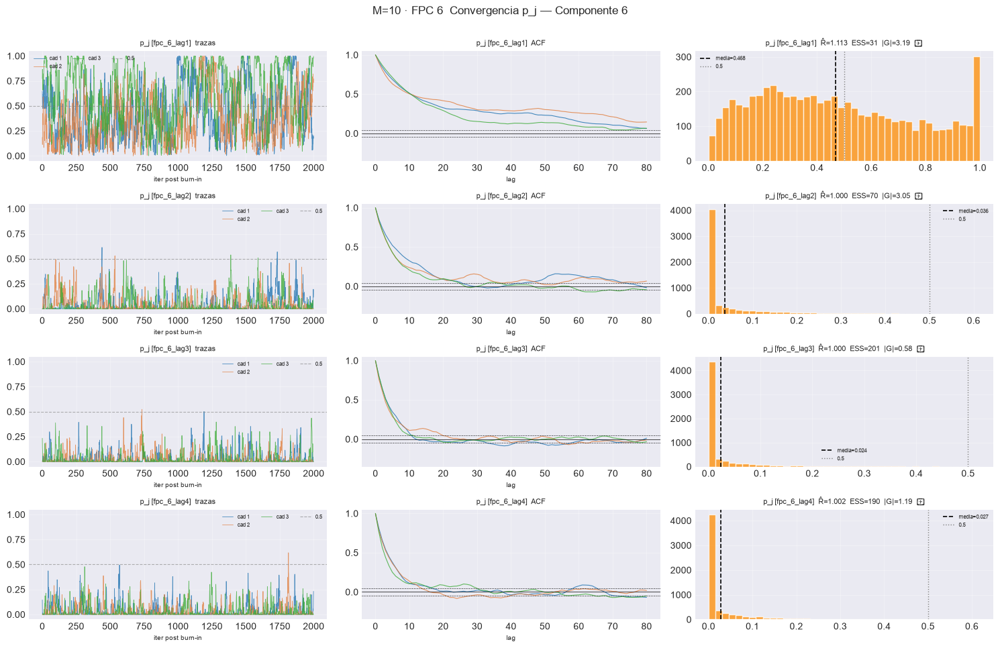

[plot_convergence_bj[FPC 7]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_7_lag1  rhat=1.000  ess_min=1368  |G|=0.46  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_7_lag2  rhat=1.000  ess_min=1639  |G|=1.10  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_7_lag3  rhat=1.000  ess_min=1789  |G|=0.90  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_7_lag4  rhat=1.000  ess_min=1585  |G|=1.62  ✓
[plot_convergence_bj[FPC 7]] listo: 4 pasos en 2.5s  0/4 sin converger


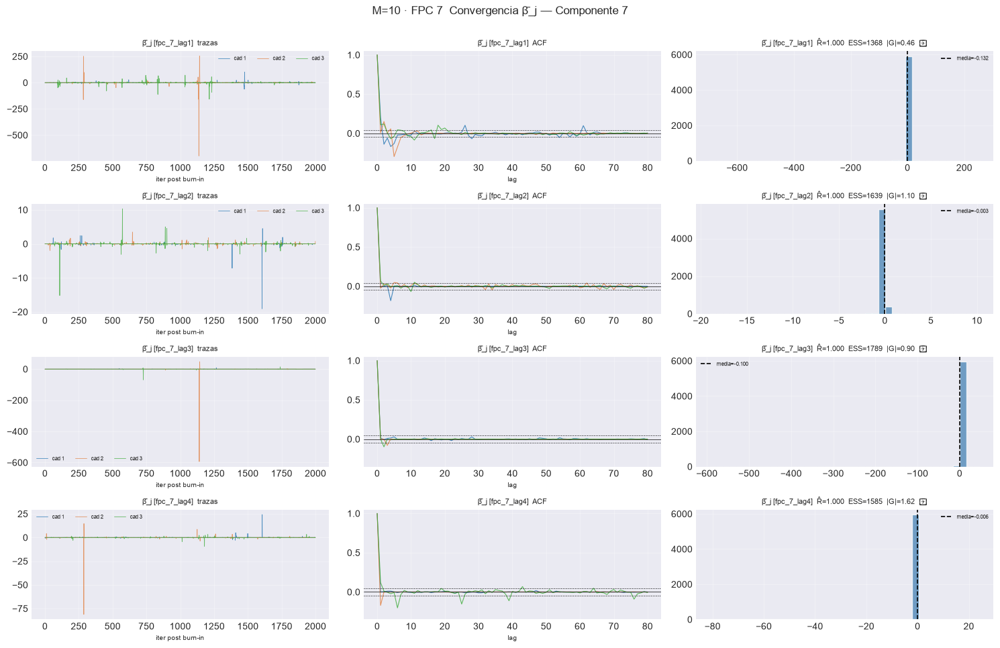

[plot_convergence_pj[FPC 7]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_7_lag1  rhat=1.184  ess_min=20  |G|=4.21  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_7_lag2  rhat=1.010  ess_min=170  |G|=0.79  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_7_lag3  rhat=1.006  ess_min=188  |G|=1.34  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_7_lag4  rhat=1.008  ess_min=248  |G|=0.91  ✓
[plot_convergence_pj[FPC 7]] listo: 4 pasos en 2.8s  1/4 sin converger


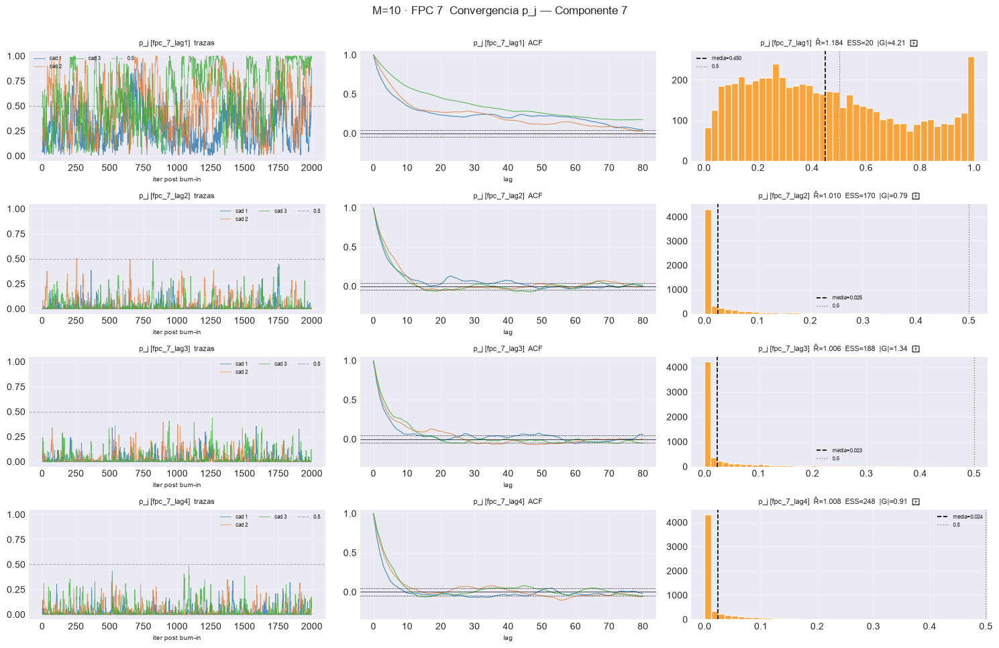

[plot_convergence_bj[FPC 8]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_8_lag1  rhat=1.000  ess_min=938  |G|=1.96  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_8_lag2  rhat=1.000  ess_min=1715  |G|=1.39  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_8_lag3  rhat=1.000  ess_min=2000  |G|=0.99  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_8_lag4  rhat=1.000  ess_min=1215  |G|=1.27  ✓
[plot_convergence_bj[FPC 8]] listo: 4 pasos en 2.5s  0/4 sin converger


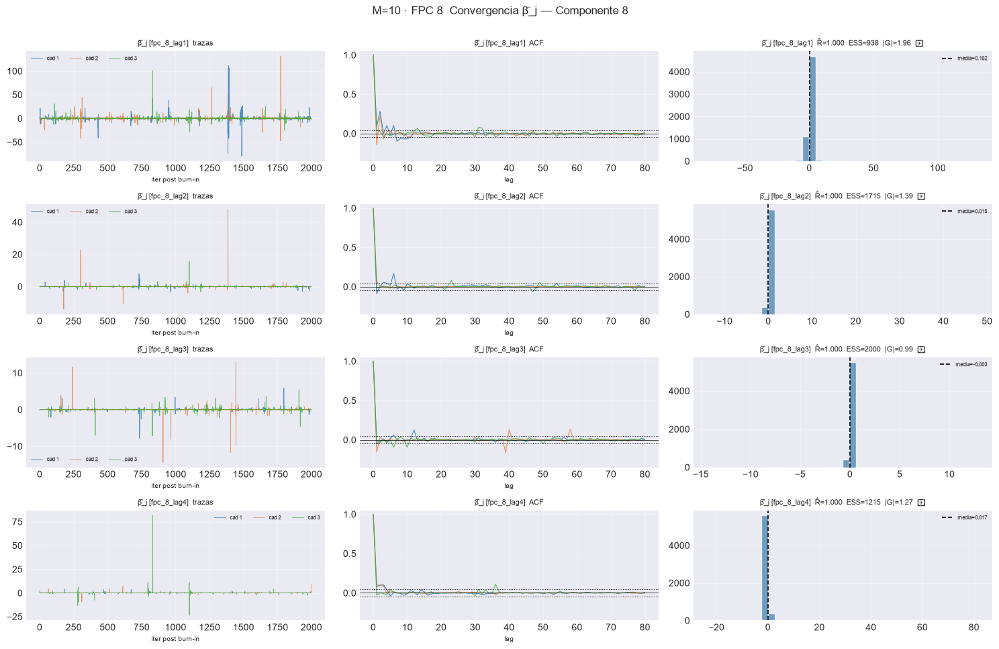

[plot_convergence_pj[FPC 8]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.4s  fpc_8_lag1  rhat=1.008  ess_min=26  |G|=3.40  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_8_lag2  rhat=1.001  ess_min=112  |G|=1.76  ✓
  3/4 (75.0%) t=0.3s eta=0.1s  fpc_8_lag3  rhat=1.000  ess_min=128  |G|=2.46  ✗
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_8_lag4  rhat=1.002  ess_min=141  |G|=1.01  ✓
[plot_convergence_pj[FPC 8]] listo: 4 pasos en 3.2s  2/4 sin converger


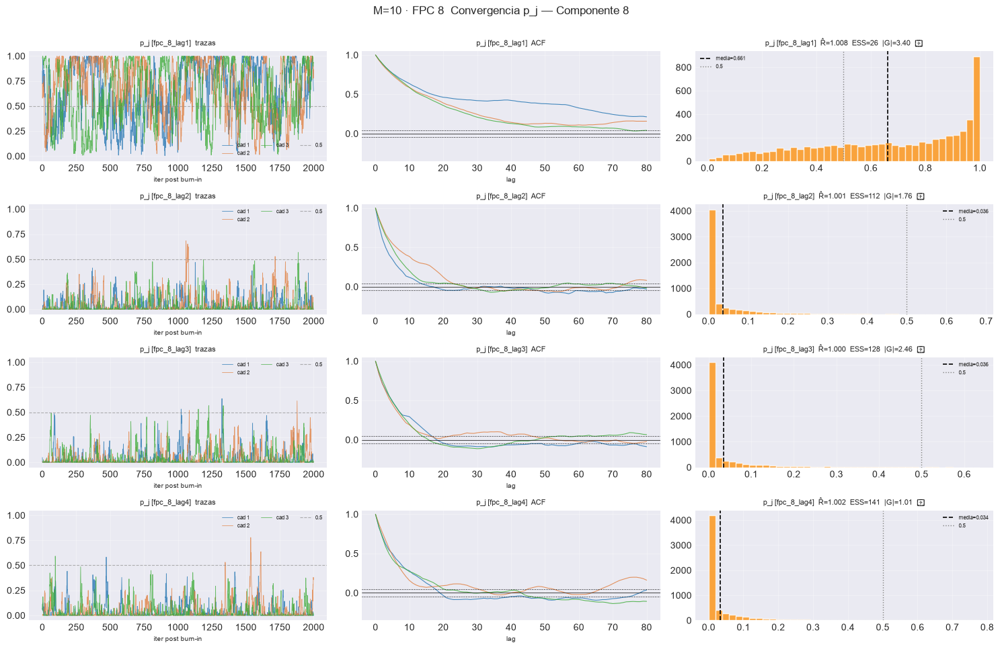

[plot_convergence_bj[FPC 9]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_9_lag1  rhat=1.000  ess_min=1103  |G|=0.82  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_9_lag2  rhat=1.000  ess_min=1536  |G|=1.74  ✓
  3/4 (75.0%) t=0.2s eta=0.1s  fpc_9_lag3  rhat=1.000  ess_min=1084  |G|=1.15  ✓
  4/4 (100.0%) t=0.3s eta=0.0s  fpc_9_lag4  rhat=1.000  ess_min=1929  |G|=1.01  ✓
[plot_convergence_bj[FPC 9]] listo: 4 pasos en 2.6s  0/4 sin converger


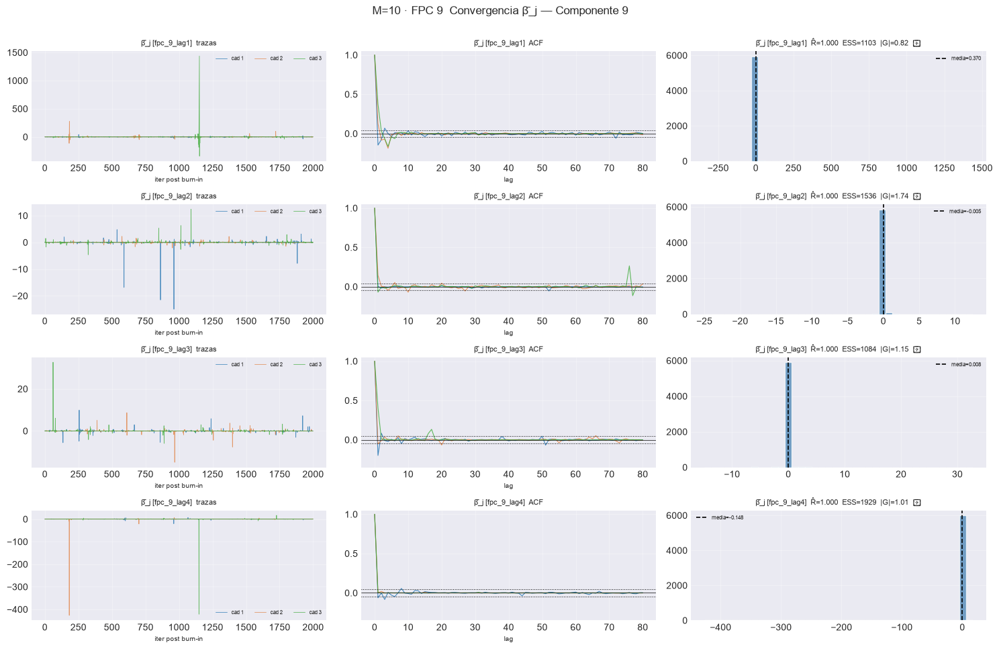

[plot_convergence_pj[FPC 9]] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  fpc_9_lag1  rhat=1.002  ess_min=18  |G|=1.77  ✗
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_9_lag2  rhat=1.001  ess_min=146  |G|=3.53  ✗
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_9_lag3  rhat=1.000  ess_min=184  |G|=0.93  ✓
  4/4 (100.0%) t=0.2s eta=0.0s  fpc_9_lag4  rhat=1.001  ess_min=144  |G|=2.45  ✗
[plot_convergence_pj[FPC 9]] listo: 4 pasos en 2.9s  3/4 sin converger


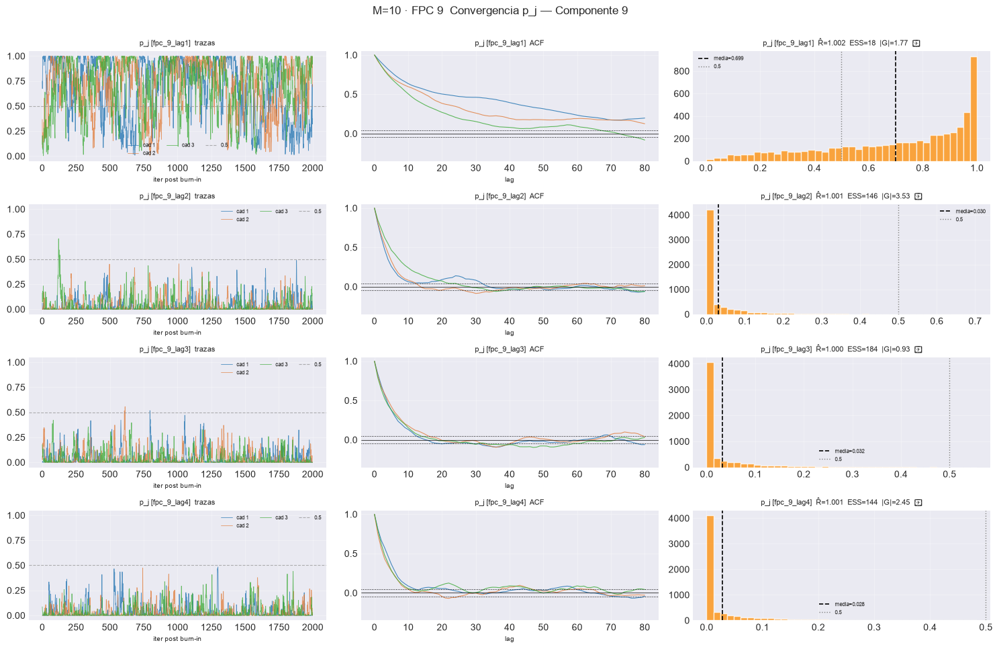

[plot_convergence_bj[FPC 10]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_10_lag1  rhat=1.000  ess_min=2000  |G|=1.73  ✓
  2/4 (50.0%) t=0.1s eta=0.1s  fpc_10_lag2  rhat=1.000  ess_min=1989  |G|=0.45  ✓
  3/4 (75.0%) t=0.1s eta=0.0s  fpc_10_lag3  rhat=1.000  ess_min=2000  |G|=1.14  ✓
  4/4 (100.0%) t=0.6s eta=0.0s  fpc_10_lag4  rhat=1.000  ess_min=2000  |G|=0.52  ✓
[plot_convergence_bj[FPC 10]] listo: 4 pasos en 3.3s  0/4 sin converger


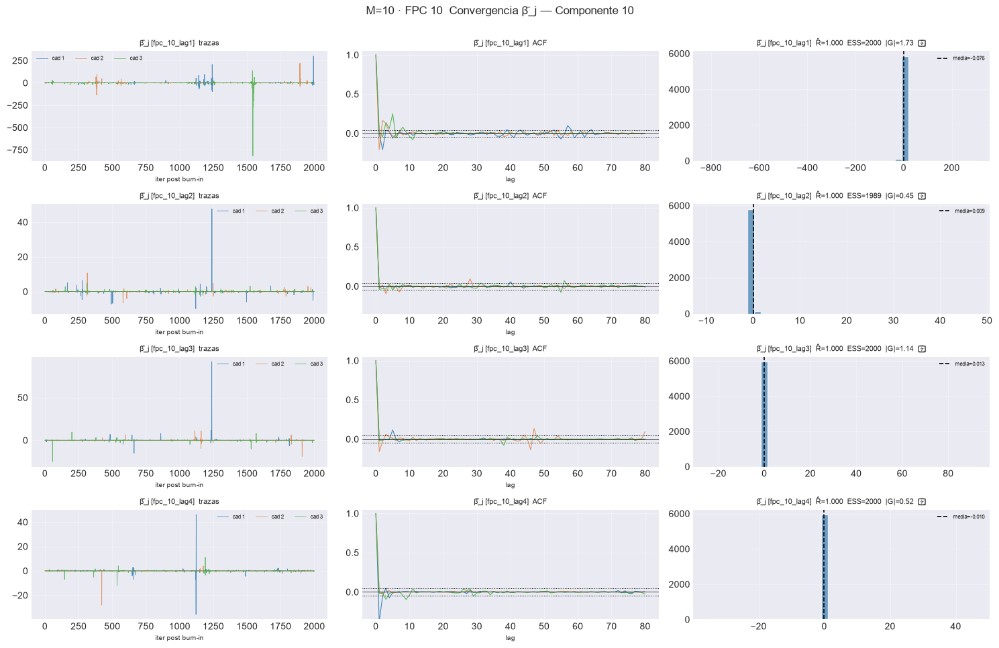

[plot_convergence_pj[FPC 10]] inicio (4 pasos)
  1/4 (25.0%) t=0.1s eta=0.2s  fpc_10_lag1  rhat=1.074  ess_min=11  |G|=2.99  ✗
  2/4 (50.0%) t=0.2s eta=0.2s  fpc_10_lag2  rhat=1.003  ess_min=148  |G|=1.62  ✓
  3/4 (75.0%) t=0.4s eta=0.1s  fpc_10_lag3  rhat=1.002  ess_min=198  |G|=2.07  ✗
  4/4 (100.0%) t=0.5s eta=0.0s  fpc_10_lag4  rhat=1.003  ess_min=142  |G|=1.71  ✓
[plot_convergence_pj[FPC 10]] listo: 4 pasos en 3.5s  2/4 sin converger


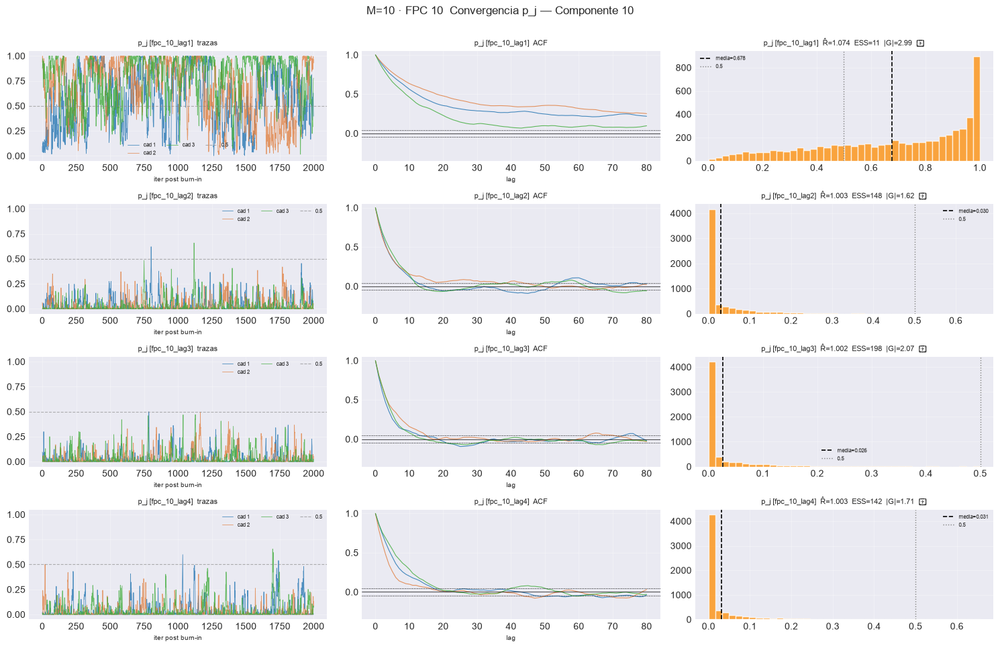

In [11]:
# Traza | ACF | posterior con las métricas anotadas; beta_j va promediado sobre
# átomos (invariante a la permutación de etiquetas). verbose=True saca
# Rhat/ESS/Geweke por covariable a la consola.
for M in M_OK:
    e = EST[M]
    print(f"== M={M} " + "=" * 46)
    for k in e["models_chains"]:
        fpc  = e["component_idx"][k] + 1
        feat = e["models_chains"][k][0].feature_names_
        args = (e["models_chains"], k, e["burn"], e["n_iter"])
        plot_convergence_bj(*args, feature_names=feat, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"44_conv_bj_k{fpc}.png"), verbose=True)
        plt.show()
        plot_convergence_pj(*args, feature_names=feat, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"45_conv_pj_k{fpc}.png"), verbose=True)
        plt.show()

## 6. Probabilidades posteriores de inclusión

Tercer eje del diseño (`docs §03_06`): qué variables selecciona el modelo,
contra la estructura de dependencia que el generador realmente usó.

In [12]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} - P(gamma_j = 1 | datos), inclusión global, media entre cadenas +- sd"))

[matriz_pip] inicio (1 pasos)
  1/1 (100.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
[matriz_pip] listo: 1 pasos en 0.0s  tabla 4x2
[M=1] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd
variable,,
fpc_1_lag1,1.000,0.000
fpc_1_lag2,0.067,0.082
fpc_1_lag3,0.032,0.028
fpc_1_lag4,0.028,0.014


[matriz_pip] inicio (2 pasos)
  1/2 (50.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/2 (100.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
[matriz_pip] listo: 2 pasos en 0.0s  tabla 8x4
[M=2] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd
variable,,,,
fpc_1_lag1,1.000,0.000,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000
fpc_2_lag2,nan,nan,0.035,0.026
fpc_2_lag3,nan,nan,0.035,0.021
fpc_2_lag4,nan,nan,0.038,0.026


[matriz_pip] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/3 (66.7%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
  3/3 (100.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.039, 1.000]
[matriz_pip] listo: 3 pasos en 0.0s  tabla 12x6
[M=3] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd
variable,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan
fpc_2_lag2,nan,nan,0.035,0.026,nan,nan
fpc_2_lag3,nan,nan,0.035,0.021,nan,nan
fpc_2_lag4,nan,nan,0.038,0.026,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000


[matriz_pip] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/4 (50.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
  3/4 (75.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.039, 1.000]
  4/4 (100.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.041, 1.000]
[matriz_pip] listo: 4 pasos en 0.0s  tabla 16x8
[M=4] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd
variable,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.035,0.026,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.035,0.021,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.038,0.026,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan


[matriz_pip] inicio (5 pasos)
  1/5 (20.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/5 (40.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
  3/5 (60.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.039, 1.000]
  4/5 (80.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.041, 1.000]
  5/5 (100.0%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.043, 1.000]
[matriz_pip] listo: 5 pasos en 0.0s  tabla 20x10
[M=5] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd
variable,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.035,0.026,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.035,0.021,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.038,0.026,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan


[matriz_pip] inicio (6 pasos)
  1/6 (16.7%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/6 (33.3%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
  3/6 (50.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.039, 1.000]
  4/6 (66.7%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.041, 1.000]
  5/6 (83.3%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.043, 1.000]
  6/6 (100.0%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.061, 1.000]
[matriz_pip] listo: 6 pasos en 0.0s  tabla 24x12
[M=6] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd
variable,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.035,0.026,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.035,0.021,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.038,0.026,nan,nan,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan


[matriz_pip] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/7 (28.6%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
  3/7 (42.9%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.039, 1.000]
  4/7 (57.1%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.041, 1.000]
  5/7 (71.4%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.043, 1.000]
  6/7 (85.7%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.061, 1.000]
  7/7 (100.0%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 4 variables, PIP en [0.059, 1.000]
[matriz_pip] listo: 7 pasos en 0.0s  tabla 28x14
[M=7] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd
variable,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.035,0.026,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.035,0.021,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.038,0.026,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan


[matriz_pip] inicio (8 pasos)
  1/8 (12.5%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/8 (25.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
  3/8 (37.5%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.039, 1.000]
  4/8 (50.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.041, 1.000]
  5/8 (62.5%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.043, 1.000]
  6/8 (75.0%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.061, 1.000]
  7/8 (87.5%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 4 variables, PIP en [0.059, 1.000]
  8/8 (100.0%) t=0.0s eta=0.0s  FPC 8: 3 cadenas, 4 variables, PIP en [0.054, 1.000]
[matriz_pip] listo: 8 pasos en 0.0s  tabla 32x16
[M=8] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd
variable,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.035,0.026,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.035,0.021,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.038,0.026,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


[matriz_pip] inicio (9 pasos)
  1/9 (11.1%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/9 (22.2%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
  3/9 (33.3%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.039, 1.000]
  4/9 (44.4%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.041, 1.000]
  5/9 (55.6%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.043, 1.000]
  6/9 (66.7%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.061, 1.000]
  7/9 (77.8%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 4 variables, PIP en [0.059, 1.000]
  8/9 (88.9%) t=0.0s eta=0.0s  FPC 8: 3 cadenas, 4 variables, PIP en [0.054, 1.000]
  9/9 (100.0%) t=0.0s eta=0.0s  FPC 9: 3 cadenas, 4 variables, PIP en [0.056, 1.000]
[matriz_pip] listo: 9 pasos en 0.0s  tabla 36x18
[M=9] dispersion maxima entre cadenas: 0.082   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd
variable,,,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag2,nan,nan,0.035,0.026,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag3,nan,nan,0.035,0.021,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag4,nan,nan,0.038,0.026,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_3_lag1,nan,nan,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


[matriz_pip] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 4 variables, PIP en [0.028, 1.000]
  2/10 (20.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 4 variables, PIP en [0.035, 1.000]
  3/10 (30.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 4 variables, PIP en [0.039, 1.000]
  4/10 (40.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 4 variables, PIP en [0.041, 1.000]
  5/10 (50.0%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 4 variables, PIP en [0.043, 1.000]
  6/10 (60.0%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 4 variables, PIP en [0.061, 1.000]
  7/10 (70.0%) t=0.0s eta=0.0s  FPC 7: 3 cadenas, 4 variables, PIP en [0.059, 1.000]
  8/10 (80.0%) t=0.0s eta=0.0s  FPC 8: 3 cadenas, 4 variables, PIP en [0.054, 1.000]
  9/10 (90.0%) t=0.0s eta=0.0s  FPC 9: 3 cadenas, 4 variables, PIP en [0.056, 1.000]
  10/10 (100.0%) t=0.0s eta=0.0s  FPC 10: 3 cadenas, 4 variables, PIP en [0.052, 1.000]
[matriz_pip] listo: 10 pasos en 0.0s  tabla 40x20
[M=10] dispersion maxima entre cadenas: 0.082   OK las cadenas coi

,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd,FPC 10,FPC 10_sd
variable,,,,,,,,,,,,,,,,,,,,
fpc_10_lag1,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,1.000,0.000
fpc_10_lag2,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.063,0.020
fpc_10_lag3,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.052,0.012
fpc_10_lag4,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.055,0.003
fpc_1_lag1,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag2,0.067,0.082,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag3,0.032,0.028,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_1_lag4,0.028,0.014,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
fpc_2_lag1,nan,nan,1.000,0.000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


### 6.1 Contraste con la estructura del generador

El soporte verdadero sale de `internos["soporte"]`: qué pares (score, rezago) entran
en $E[\xi_{j,t}\mid\text{pasado}]$. El soporte cubre sólo los rezagos del generador;
los del pipeline que lo exceden cuentan como **no verdaderos**. El PIP se calcula sobre
los scores **estimados**: el contraste es directo sólo si $\psi_k\approx\varphi_k$.

In [13]:
for M in M_OK:
    contraste = contraste_generador(EST[M], ESCENARIO_ID, UMBRAL_PIP, COS_MIN)
    if not contraste.empty:
        display(contraste.style.format("{:.3f}", subset=[
            c for c in contraste.columns if contraste[c].dtype.kind == "f"])
            .set_caption(f"M={M} - selección de variables vs soporte del generador "
                         f"(umbral {UMBRAL_PIP})"))

[M=1] |cos(psi_k, phi_k)| = [1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043


[M=2] |cos(psi_k, phi_k)| = [1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036


[M=3] |cos(psi_k, phi_k)| = [1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059


[M=4] |cos(psi_k, phi_k)| = [1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043


[M=5] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049


[M=6] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.094


[M=7] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.094
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.062


[M=8] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.094
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.062
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065


[M=9] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.094
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.062
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 9,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.060


[M=10] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 2,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.036
FPC 3,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.059
FPC 4,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.043
FPC 5,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.049
FPC 6,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.094
FPC 7,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.062
FPC 8,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.065
FPC 9,1,1,0,0,3,1.000,1.000,1.000,1.000,1.000,0.060


## 7. Verificación muestreador ↔ predictor

`inEout` es $E[y\mid x]$ dentro de muestra tal como la calcula MATLAB en cada
iteración. Debe coincidir con lo que el predictor de Python reconstruye de las
mismas trazas: es la única prueba directa de que ambos lados interpretan las
trazas igual. Se corre **en cada $M$** (el contrato depende de $p$).

In [14]:
ok_global = all([verificar_muestreador_predictor(EST[M], CORR_MIN_CONTRATO) for M in M_OK])
print(f"\n{'OK contrato verificado en todo el barrido' if ok_global else 'X el contrato falla'}")

-- M=1 --
  FPC 1 cadena1: corr=1.000000  |dif|max=0.0000
  FPC 1 cadena2: corr=1.000000  |dif|max=0.0000
  FPC 1 cadena3: corr=1.000000  |dif|max=0.0000
-- M=2 --
  FPC 1 cadena1: corr=1.000000  |dif|max=0.0000
  FPC 1 cadena2: corr=1.000000  |dif|max=0.0000
  FPC 1 cadena3: corr=1.000000  |dif|max=0.0000
  FPC 2 cadena1: corr=1.000000  |dif|max=0.0000
  FPC 2 cadena2: corr=1.000000  |dif|max=0.0000
  FPC 2 cadena3: corr=1.000000  |dif|max=0.0000
-- M=3 --
  FPC 1 cadena1: corr=1.000000  |dif|max=0.0000
  FPC 1 cadena2: corr=1.000000  |dif|max=0.0000
  FPC 1 cadena3: corr=1.000000  |dif|max=0.0000
  FPC 2 cadena1: corr=1.000000  |dif|max=0.0000
  FPC 2 cadena2: corr=1.000000  |dif|max=0.0000
  FPC 2 cadena3: corr=1.000000  |dif|max=0.0000
  FPC 3 cadena1: corr=1.000000  |dif|max=0.0000
  FPC 3 cadena2: corr=1.000000  |dif|max=0.0000
  FPC 3 cadena3: corr=1.000000  |dif|max=0.0000
-- M=4 --
  FPC 1 cadena1: corr=1.000000  |dif|max=0.0000
  FPC 1 cadena2: corr=1.000000  |dif|max=0.0000


### 7.1 Paso de $\Gamma$: grilla por predictor y normalización

- cada $\Gamma_{hj}$ muestreado cae **en la grilla de su predictor** `Gstar[:, j]`;
- en cada sorteo, `pm1` es finito y suma 1 (`gamdiagout`).

In [15]:
gamma_df = diagnostico_paso_gamma(EST, M_OK)
display(gamma_df[gamma_df.M == max(M_OK)].style
        .format({"dist_max": "{:.1e}", "err_suma_max": "{:.1e}",
                 "rango_log_mediana": "{:.1f}", "rango_log_max": "{:.1f}"})
        .set_caption(f"M={max(M_OK)} - paso de Gamma, post-burn"))

OK Gamma siempre en su grilla y pm1 finita y normalizada   ·   rango_log mediano 9998


,M,FPC,cadena,fuera_de_grilla,dist_max,sorteos,no_finitos,err_suma_max,rango_log_mediana,rango_log_max
135,10,1,1,False,1.1e-07,53891,0,4.4e-16,21003.5,29183.0
136,10,1,2,False,1.1e-07,54689,0,4.4e-16,24446.9,43291.9
137,10,1,3,False,1.1e-07,53842,0,4.4e-16,22580.2,34781.6
138,10,2,1,False,1.2e-07,56929,0,4.4e-16,19770.9,32845.1
139,10,2,2,False,1.2e-07,53511,0,5.6e-16,18322.8,27666.5
140,10,2,3,False,1.2e-07,51276,0,4.4e-16,14694.6,19073.1
141,10,3,1,False,5.8e-08,52092,0,5.6e-16,12604.3,23178.3
142,10,3,2,False,5.8e-08,56947,0,4.4e-16,7571.3,14703.2
143,10,3,3,False,5.8e-08,49446,0,4.4e-16,7080.8,17662.9
144,10,4,1,False,2.9e-08,52593,0,4.4e-16,9998.3,16193.0


## 8. Comparación entre los puntos del barrido

Las cifras son comparables entre $M$: $\hat R$ máx, ESS mín y Geweke máx son el
**peor caso** del punto (no un promedio sobre un número de variables que cambia
con $M$); la ocupación cuenta átomos; el PIP es una proporción en $[0,1]$.

,experiment_id,p_covariables,n_variables_diag,rhat_max,ess_min,geweke_max,n_no_converge,converge,ocupacion_media,ocupacion_max,N_trunc,toca_truncamiento,pip_sd_max,contrato_ok,pip_media_activas
M,,,,,,,,,,,,,,,
1,escenario_200_chungEscG_1_r01_m01,4,8,1.0163,19,6.0373,4,False,5.53,30,30,True,0.0820,True,1.0000
2,escenario_200_chungEscG_1_r01_m02,4,16,1.0773,19,8.4898,6,False,6.72,30,30,True,0.0820,True,1.0000
3,escenario_200_chungEscG_1_r01_m03,4,24,1.0773,19,8.4898,9,False,8.00,30,30,True,0.0820,True,1.0000
4,escenario_200_chungEscG_1_r01_m04,4,32,1.0773,10,8.4898,10,False,7.87,30,30,True,0.0820,True,1.0000
5,escenario_200_chungEscG_1_r01_m05,4,40,1.0773,10,8.4898,13,False,7.04,30,30,True,0.0820,True,1.0000
6,escenario_200_chungEscG_1_r01_m06,4,48,1.1127,10,8.4898,15,False,6.99,30,30,True,0.0820,True,1.0000
7,escenario_200_chungEscG_1_r01_m07,4,56,1.1838,10,8.4898,16,False,7.01,30,30,True,0.0820,True,1.0000
8,escenario_200_chungEscG_1_r01_m08,4,64,1.1838,10,8.4898,18,False,6.70,30,30,True,0.0820,True,1.0000
9,escenario_200_chungEscG_1_r01_m09,4,72,1.1838,10,8.4898,21,False,6.47,30,30,True,0.0820,True,1.0000


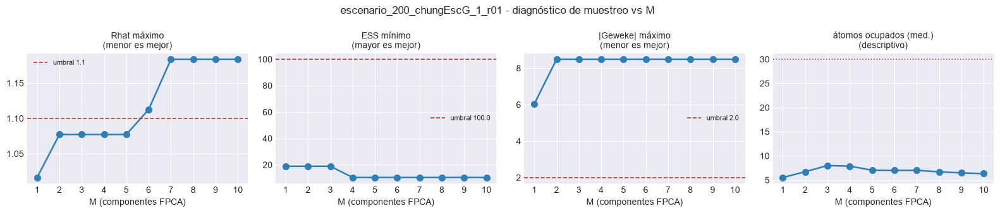

In [16]:
barrido_df = tabla_barrido(EST, M_OK, PATH_BARRIDO)
_fmt = {c: "{:.4f}" for c in ("rhat_max", "geweke_max", "pip_sd_max", "pip_media_activas")
        if c in barrido_df.columns} | {"ess_min": "{:.0f}", "ocupacion_media": "{:.2f}"}
display(barrido_df.style.format(_fmt, na_rep="-")
        .background_gradient(subset=["rhat_max"], cmap="RdYlGn_r", vmin=1.0, vmax=1.2)
        .background_gradient(subset=["ess_min"], cmap="RdYlGn", vmin=0, vmax=500)
        .set_caption("Diagnóstico de muestreo a lo largo del barrido en M"))

plot_diagnostico_vs_M(barrido_df, EST[M_OK[0]]["res_conv"]["umbrales"], EXPERIMENT_BASE,
                      PATH_BARRIDO / "81_diagnostico_vs_M.png")
plt.show()

FPC,1,2,3,4,5,6,7,8,9,10
M,,,,,,,,,,
1,5.53,-,-,-,-,-,-,-,-,-
2,5.53,7.91,-,-,-,-,-,-,-,-
3,5.53,7.91,10.54,-,-,-,-,-,-,-
4,5.53,7.91,10.54,7.49,-,-,-,-,-,-
5,5.53,7.91,10.54,7.49,3.72,-,-,-,-,-
6,5.53,7.91,10.54,7.49,3.72,6.76,-,-,-,-
7,5.53,7.91,10.54,7.49,3.72,6.76,7.09,-,-,-
8,5.53,7.91,10.54,7.49,3.72,6.76,7.09,4.57,-,-
9,5.53,7.91,10.54,7.49,3.72,6.76,7.09,4.57,4.59,-


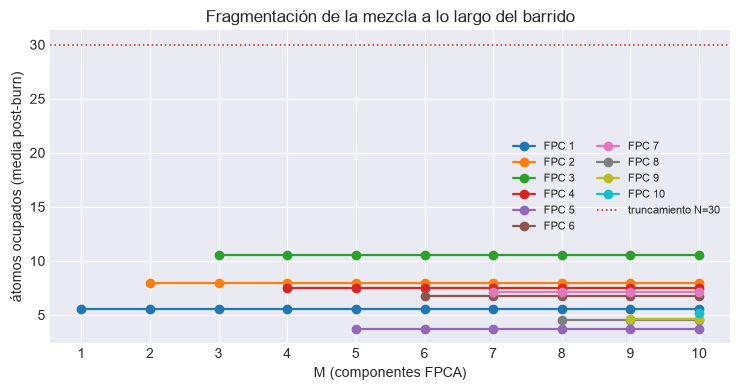

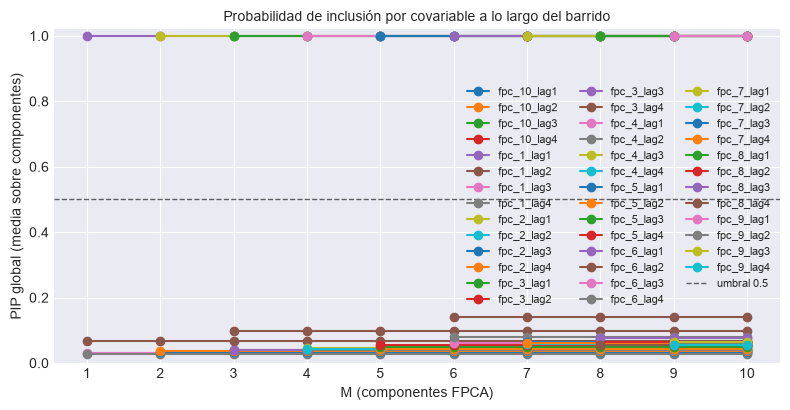

In [17]:
# Ocupación por M y componente: dice si al subir M el modelo parte la mezcla en más átomos.
ocup_todo, piv = ocupacion_barrido(EST, M_OK, PATH_BARRIDO)
display(piv.style.format("{:.2f}", na_rep="-").background_gradient(cmap="RdYlGn_r", axis=None)
        .set_caption("Átomos ocupados (media post-burn) por M y componente FPCA"))
plot_ocupacion_vs_M(piv, int(ocup_todo["N_trunc"].iloc[0]), PATH_BARRIDO / "82_ocupacion_por_M.png")
plt.show()

# PIP por covariable a lo largo del barrido (formato largo).
pip_largo = pip_barrido(EST, M_OK, PATH_BARRIDO)
plot_pip_vs_M(pip_largo, M_OK, PATH_BARRIDO / "83_pip_por_M.png")
plt.show()

In [18]:
veredicto_barrido(barrido_df, EXPERIMENT_BASE, M_FPCA_LIST, M_OK, PATH_BARRIDO)
print("Continuar con 200_04_evaluacion, declarando el mismo M_FPCA_LIST.")

  BARRIDO escenario_200_chungEscG_1_r01   ·   M evaluados: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  M=1  p=4  Rhatmax=1.016  ESSmin=19  ocup=5.5/30  X NO CONVERGE
  M=2  p=4  Rhatmax=1.077  ESSmin=19  ocup=6.7/30  X NO CONVERGE
  M=3  p=4  Rhatmax=1.077  ESSmin=19  ocup=8.0/30  X NO CONVERGE
  M=4  p=4  Rhatmax=1.077  ESSmin=10  ocup=7.9/30  X NO CONVERGE
  M=5  p=4  Rhatmax=1.077  ESSmin=10  ocup=7.0/30  X NO CONVERGE
  M=6  p=4  Rhatmax=1.113  ESSmin=10  ocup=7.0/30  X NO CONVERGE
  M=7  p=4  Rhatmax=1.184  ESSmin=10  ocup=7.0/30  X NO CONVERGE
  M=8  p=4  Rhatmax=1.184  ESSmin=10  ocup=6.7/30  X NO CONVERGE
  M=9  p=4  Rhatmax=1.184  ESSmin=10  ocup=6.5/30  X NO CONVERGE
  M=10  p=4  Rhatmax=1.184  ESSmin=10  ocup=6.3/30  X NO CONVERGE
------------------------------------------------------------------
X NO convergen: M = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]. Excluirlos de la comparacion de _04/_05,
  o subir nsim/burn antes de leer su error como efecto de M.

corr(M, Rhatmax) = +0.933   ·   cor

## 9. Comparación entre variantes

Lee lo que este notebook dejó en `M = max(M_FPCA_LIST)` para cada variante de
`VARIANTES_COMPARAR` y verifica que compartan realización. Reporta hiperparámetros
efectivos, $\hat R$, ESS (absoluto y por draw), ocupación y paso de $\Gamma$.
Salidas en `reports/simulaciones/escenario_200_1_r01_variantes/` (archivos 85).

OK 1 variantes sobre la misma realizacion: ['200 Chung esc. gating libre']
max |hp(200 Chung esc. gating libre) - hp(200 Chung esc. gating libre)| = 0.00e+00   (mismos hiperparametros)


,n_no_converge,n_variables,rhat_max,geweke_max,n_post,ess_min_beta_j,ess_por_draw_beta_j,ess_min_p_j,ess_por_draw_p_j,ocupacion_media,ocupacion_max,N,frac_en_N,gamma_fuera_grilla,gamma_no_finitos
variante,,,,,,,,,,,,,,,
200 Chung esc. gating libre,23,80,1.184,8.49,2000,680,0.340,10,0.005,6.34,30,30,0.45%,False,0


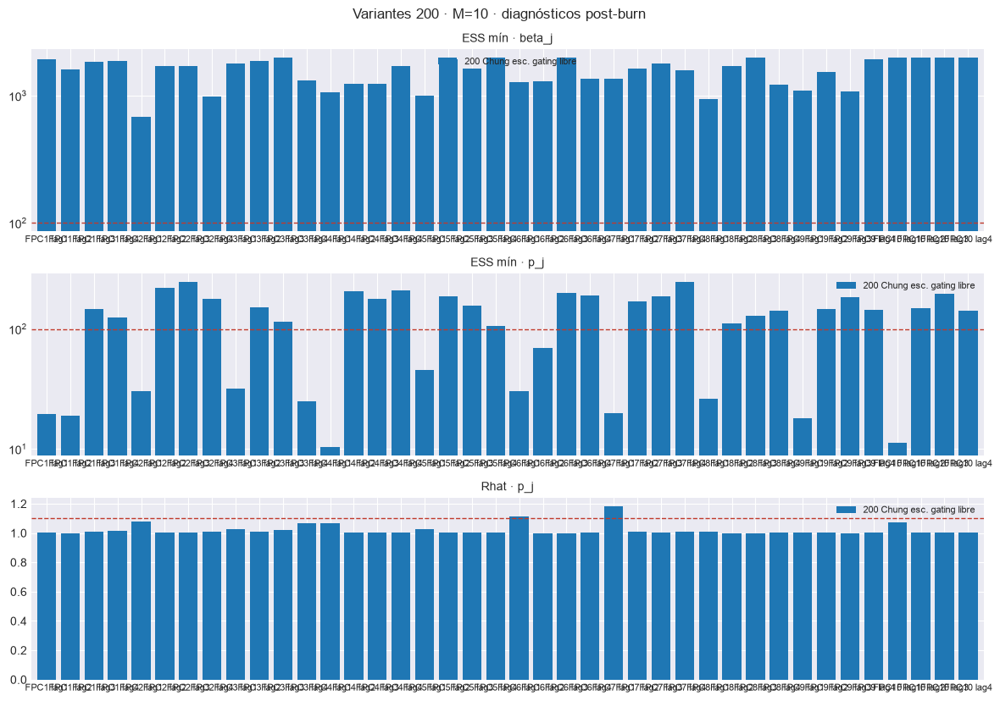

In [19]:
M_REF    = max(M_FPCA_LIST)
PATH_VAR = PROJECT_ROOT / "reports" / "simulaciones" / f"escenario_200_{ESCENARIO_ID}_r{REPLICA_ID:02d}_variantes"

hp_var, comp_var, diag_largo = comparar_variantes(
    VARIANTES_COMPARAR, M_REF, ESCENARIO_ID, REPLICA_ID, PROJECT_ROOT, PATH_VAR)

display(hp_var.style.format("{:.3g}", subset=["atau", "btau", "ag", "bg", "apij", "bpij",
                                              "mupsij", "taupsij"])
        .set_caption("Hiperparámetros que recibió MATLAB (mupsij/taupsij: media sobre covariables)"))
display(comp_var.style
        .format({"rhat_max": "{:.3f}", "geweke_max": "{:.2f}", "ocupacion_media": "{:.2f}",
                 "frac_en_N": "{:.2%}",
                 **{c: ("{:.3f}" if "por_draw" in c else "{:.0f}") for c in comp_var.columns
                    if c.startswith("ess_")}}, na_rep="-")
        .background_gradient(subset=["n_no_converge"], cmap="RdYlGn_r")
        .set_caption(f"M={M_REF} · convergencia por variante (umbrales: Rhat<1.1, ESS>100, |z|<2)"))
plot_variantes(diag_largo, list(comp_var.index),
               f"Variantes 200 · M={M_REF} · diagnósticos post-burn",
               PATH_VAR / "85_convergencia_por_variante.png")
plt.show()